In [340]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import math
import datetime as dt
from textwrap import shorten
from scipy import stats
import textwrap
from scipy.cluster.hierarchy import linkage
from scipy.spatial.distance import squareform
from pyampute.exploration.mcar_statistical_tests import MCARTest

pd.set_option("display.max_columns", 50) #don't cut cols
pd.set_option("display.max_rows", 50) #don't cut rows
pd.set_option("display.max_colwidth", 50) #remove character limits within cells
pd.set_option("display.width", 50) #remove width limit
pd.set_option("display.float_format", "{:.2f}".format) #remove scientific notations

# 1. Data Understanding

## 1.1 Data loading

In [341]:
BASE_PATH = Path.cwd().parent
DATA = BASE_PATH / "data"
RAW = DATA / "raw"
DATASET = RAW / "acdc_dataset.csv"

In [342]:
df_raw = pd.read_csv(DATASET,sep=";")

## 1.2 Dataset Overview

* **Variable member_id**
    * **Type:** nominal categorical
    * **Length:** 8
    * **Description:** It's a unique identifer for the member.
    * **Notes:** It's a 8 character text always with the format : "CKXXXXXX".

* **Variable age**
    * **Type:** int
    * **Description:** Age of the member at the extraction date.

* **Variable gender**
    * **Type:** nominal categorical
    * **Length:** varied
    * **Description:** Gender of the member.

* **Variable industry**
    * **Type:** nominal categorical
    * **Length:** varied
    * **Description:** The industry sector the member works in.
   
* **Variable country**
    * **Type:** nominal categorical
    * **Length:** varied
    * **Description:** The country where the member (or their associated company) is
based.

* **Variable is_team_account**
    * **Type:** bool
    * **Description:** Whether the membership is held by a team/company account.
rather than an individual.

* **Variable n_colleagues_on_account**
    * **Type:** int
    * **Description:** Number of colleagues sharing the account.

* **Variable plan_tier**
    * **Type:** ordinal categorical
    * **Description:**(hot_desk<flex<dedicated_desk <full_time < private_office)

* **Variable plan_days_per_week**
    * **Type:** int
    * **Description:** Number of days per week the member's plan entitles them to use
the space.

* **Variable membership_start**
    * **Type:** datetype
    * **Description:** Date the membership first began.

* **Variable membership_end**
    * **Type:** datetype
    * **Description:** Date the membership first ended.

* **Variable last_badge_swipe**
    * **Type:** datetype
    * **Description:** Date of the member's most recent physical entry to the space.

* **Variable days_since_last_visit**
    * **Type:** int
    * **Description:** Number of days since the member's last recorded visit.

* **Variable total_visits**
    * **Type:** int
    * **Description:** Total number of visits the member made over the whole
membership.

* **Variable avg_weekly_visits**
    * **Type:** float
    * **Description:** Average number of visits per week over the membership.

* **Variable entitled_visits_last_period**
    * **Type:** int
    * **Description:** Number of visits the member's plan entitled them to during the last
period of their membership.

* **Variable actual_visits_last_period**
    * **Type:** int
    * **Description:** Number of visits the member actually made during the last period
of their membership.

* **Variable meeting_room_hours**
    * **Type:** int
    * **Description:** Hours of meeting-room usage recorded for the member.

* **Variable event_space_hours**
    * **Type:** int
    * **Description:** Number of guest passes the member issued.

* **Variable uses_meeting_rooms**
    * **Type:** bool
    * **Description:** Whether the member ever used the meeting-room add-on.

* **Variable uses_event_space**
    * **Type:** bool
    * **Description:** Whether the member ever used the event-space add-on.

* **Variable uses_guest_passes**
    * **Type:** bool
    * **Description:** Whether the member ever used the guest-pass add-on.

* **Variable uses_print**
    * **Type:** bool
    * **Description:** Whether the member used the print add-on.

* **Variable uses_mail_handling**
    * **Type:** bool
    * **Description:** Whether the member used the mail-handling add-on.

* **Variable uses_phone_booths**
    * **Type:** bool
    * **Description:** Whether the member used the phone-booth add-on.

* **Variable uses_day_passes**
    * **Type:** bool
    * **Description:** Whether the member used the day-pass add-on.

* **Variable uses_storage**
    * **Type:** bool
    * **Description:** Whether the member used the storage add-on.

* **Variable uses_bike_locker**
    * **Type:** bool
    * **Description:** Whether the member used the bike-locker add-on.

* **Variable n_renewals**
    * **Type:** int
    * **Description:** Number of times the membership was renewed.

* **Variable lifetime_value**
    * **Type:** float
    * **Description:** Total revenue attributed to the member over the whole
membership.

## 1.3 Data Exploration

### 1.3.1 Univariate analysis

In [343]:
df_raw.head()

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
0,CW000001,38.00,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,2023-03-06,2023-03-23,-17,220,2.65,26.09,22,0.00,0.00,18.00,False,False,True,0,False,True,True,False,False,2,4477.97
1,CW000002,38.00,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,1970-01-01,2023-11-24,37,2,0.32,10.68,1,0.00,0.00,0.00,False,False,False,0,True,False,False,False,False,0,165.86
2,CW000003,43.00,Male,Education,DE,True,1,flex,3,2021-12-03,1970-01-01,2023-07-22,163,19,0.17,26.09,2,0.00,0.00,0.00,False,False,False,0,False,False,False,False,False,1,4486.17
3,CW000004,38.00,F,Legal,portugal,False,0,flex,3,2022-01-02,2022-02-15,2022-01-02,44,8,1.23,18.74,9,0.00,0.00,0.00,False,False,False,0,False,False,False,False,False,0,258.63
4,CW000005,45.00,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,1970-01-01,2023-12-17,15,4,0.38,17.39,3,0.00,0.00,0.00,False,False,False,0,False,False,True,False,False,0,335.74


#### 1.3.1.1 Shape & Schema

In [344]:
def auto_detect_datetimes_and_boolean(df: pd.DataFrame,threshold: float = 0.90):
    """
        Automatically detects and converts datetime and Boolean columns in a DataFrame.
        String/object columns are tested against a collection of common date formats,
        including ISO (YYYY-MM-DD), day-first (DD/MM/YYYY), and other common
        representations.A column is converted only if the proportion of successfully
        parsed non-null values meets the specified threshold.

        For converted datetime columns, diagnostic information is printed, including
        the column name, number of non-null rows, detected date formats and their
        counts, unmatched values, and final data type.

        Columns containing exclusively 0/1 or True/False values (including their
        string representations) are converted to pandas' nullable Boolean dtype.
        Missing values are preserved.

        Parameters
        ----------
        df : pd.DataFrame
            DataFrame that will be analyzed.
        threshold : float
            Percentage of non-null entries from each collumn that must parse as dates.
            Range from 0-1.

        Returns
        -------
        df : pd.DataFrame
            Return dataframe and converted collumns that manage to parse.

    """
    
    df = df.copy()
    #possible date formats
    date_formats = [
        ("%Y-%m-%d", "ISO (yyyy-mm-dd)"),
        ("%Y/%m/%d", "ISO slash (yyyy/mm/dd)"),
        ("%d/%m/%Y", "Slash (dd/mm/yyyy)"),
        ("%d-%m-%Y", "Dash (dd-mm-yyyy)"),
        ("%Y-%m-%d %H:%M:%S", "ISO datetime"),
        ("%d/%m/%Y %H:%M:%S", "Slash datetime (dd/mm/yyyy)"),
    ]

    #datetime detection
    for col in df.select_dtypes(include=["object", "string"]).columns:

        s = df[col].dropna().astype(str).str.strip()
        if s.empty:
            continue

        numeric_like = s.str.fullmatch(
            r"[+-]?(?:\d+(?:\.\d*)?|\.\d+)"
        ).mean()

        if numeric_like >= 0.90:
            continue

        parsed = pd.Series(pd.NaT, index=df.index, dtype="datetime64[ns]")

        format_counts = {}

        for fmt, label in date_formats:
            candidate = pd.to_datetime(
                s, format=fmt, errors="coerce"
            )

            mask = candidate.notna() & parsed.loc[s.index].isna()

            if mask.any():
                matched_idx = candidate.index[mask]
                parsed.loc[matched_idx] = candidate.loc[matched_idx]
                format_counts[label] = int(mask.sum())

        #fallback for other date formats
        remaining_idx = parsed.loc[s.index][parsed.loc[s.index].isna()].index

        if len(remaining_idx) > 0:
            remaining_values = s.loc[remaining_idx]

            date_like_values = remaining_values[
                remaining_values.str.contains(
                    r"[-/]", regex=True, na=False
                )
            ]

            if not date_like_values.empty:
                fallback = pd.to_datetime(
                    date_like_values,
                    format="mixed",
                    dayfirst=True,
                    errors="coerce"
                )

                mask = fallback.notna()

                if mask.any():
                    parsed.loc[fallback.index[mask]] = fallback.loc[mask]
                    format_counts["Other formats"] = int(mask.sum())

        success_rate = parsed.loc[s.index].notna().mean()

        #print diagnostic when col is converted
        if success_rate >= threshold and parsed.notna().any():
            df[col] = parsed

            print(f"\nColumn: {col}")
            print(f"Total non-null rows: {len(s)}")

            for label, count in format_counts.items():
                print(f"Match {label}: {count}")

            unmatched = len(s) - sum(format_counts.values())
            print(f"Unmatched / Other formats: {unmatched}")
            print(f"Final dtype: {df[col].dtype}")

    #boolean detection
    boolean_map = {
        "0": False,
        "1": True,
        "true": True,
        "false": False,
    }

    for col in df.columns:
        if pd.api.types.is_datetime64_any_dtype(df[col]):
            continue

        non_null = df[col].dropna()

        if non_null.empty:
            continue

        normalized = non_null.map(lambda x: str(x).strip().lower())

        if normalized.isin(boolean_map).all():
            df[col] = df[col].map(
                lambda x: (
                    pd.NA if pd.isna(x)
                    else boolean_map[str(x).strip().lower()]
                )
            ).astype("boolean")

    return df

In [345]:
df_raw=auto_detect_datetimes_and_boolean(df_raw).convert_dtypes()


Column: membership_start
Total non-null rows: 15465
Match ISO (yyyy-mm-dd): 14826
Match Slash (dd/mm/yyyy): 639
Unmatched / Other formats: 0
Final dtype: datetime64[ns]

Column: membership_end
Total non-null rows: 15465
Match ISO (yyyy-mm-dd): 15002
Match Slash (dd/mm/yyyy): 463
Unmatched / Other formats: 0
Final dtype: datetime64[ns]

Column: last_badge_swipe
Total non-null rows: 15465
Match ISO (yyyy-mm-dd): 14826
Match Slash (dd/mm/yyyy): 639
Unmatched / Other formats: 0
Final dtype: datetime64[ns]


We had multiple date formats.
We converted to match ISO style.

In [346]:
df_raw.info(show_counts=False)

<class 'pandas.DataFrame'>
RangeIndex: 15465 entries, 0 to 15464
Data columns (total 31 columns):
 #   Column                       Dtype         
---  ------                       -----         
 0   member_id                    string        
 1   age                          Int64         
 2   gender                       string        
 3   industry                     string        
 4   country                      string        
 5   is_team_account              boolean       
 6   n_colleagues_on_account      Int64         
 7   plan_tier                    string        
 8   plan_days_per_week           Int64         
 9   membership_start             datetime64[ns]
 10  membership_end               datetime64[ns]
 11  last_badge_swipe             datetime64[ns]
 12  days_since_last_visit        Int64         
 13  total_visits                 Int64         
 14  avg_weekly_visits            Float64       
 15  entitled_visits_last_period  Float64       
 16  actual_visits_l

The dataset contains 15,465 records and 31 features: 4 floats, 8 integers, 10 booleans, 3 datetime variables and 6 string variables.

We have a problem, lifetime value is clearly suppoused to be a float given what we know in the data dictionary, but instead we see a string.

In [347]:
non_numeric = df_raw["lifetime_value"][~df_raw["lifetime_value"].astype(str).str.match(r'^-?\d+\.?\d*$')] #let's capture the non numeric entries to see the problem
print(non_numeric.unique()[:]) 

<StringArray>
[        <NA>,   '246.10 €',   '446.70 €',
   '4,311.15',   '859.65 €',   '843.67 €',
   '646.66 €',   '485.65 €',     '0.00 €',
   '769.55 €',
 ...
   '306.59 €',   '345.53 €',   '311.68 €',
  '3329.91 €',  '2779.74 €',   '421.69 €',
 '11109.34 €',   '323.75 €',  '4387.71 €',
   '1,066.72']
Length: 384, dtype: string


Now we know the issue, this feature was converted to string because there's junk characters on the entries, sometimes commas instead of periods, sometimes euro signs with other junk.

In [348]:
def lifetime_value_fix(df: pd.DataFrame, list: list ):
    """
        Automatically strip spaces,commas and whitespaces from all entries on specified collumn list.
    
        Parameters
        ----------
        df : pd.DataFrame
                DataFrame that will be analyzed.
        list : list
                List of features to be dealt with.
    
        Returns
        -------
        df : pd.DataFrame with fixed entries.
    """
    
    for col in list:
        if col in df.columns:
            df[col] = (
                df[col]
                .astype(str)
                .str.replace(r"[€â‚¬\s]", "", regex=True)# strip €, â‚¬, and whitespaces
                .str.replace(",", ".", regex=False)# replace comma with decimal point
            )
            df[col] = pd.to_numeric(df[col], errors="coerce")#convert to numeric
    return df

In [349]:
df_raw=lifetime_value_fix(df_raw,["lifetime_value"])

In [350]:
df_raw.convert_dtypes().info(show_counts=False)

<class 'pandas.DataFrame'>
RangeIndex: 15465 entries, 0 to 15464
Data columns (total 31 columns):
 #   Column                       Dtype         
---  ------                       -----         
 0   member_id                    string        
 1   age                          Int64         
 2   gender                       string        
 3   industry                     string        
 4   country                      string        
 5   is_team_account              boolean       
 6   n_colleagues_on_account      Int64         
 7   plan_tier                    string        
 8   plan_days_per_week           Int64         
 9   membership_start             datetime64[ns]
 10  membership_end               datetime64[ns]
 11  last_badge_swipe             datetime64[ns]
 12  days_since_last_visit        Int64         
 13  total_visits                 Int64         
 14  avg_weekly_visits            Float64       
 15  entitled_visits_last_period  Float64       
 16  actual_visits_l

Now we finally have the correct types for our data : 
- 5 floats.
- 8 int.
- 10 bool.
- 3 datetime.
- 5 string(4 nominal and 1 ordinal).

#### 1.3.1.2 Missing Values

In [351]:
def check_nulls(df: pd.DataFrame, df_name: str = "Dataset"):
    """
    Function to count nulls, return a summary DataFrame and then visualize missingness.

    Parameters
    ----------
    df : pd.DataFrame
            DataFrame that will be analyzed.
    str : str
            Name of the dataset

    Returns
    -------
    plot : Plot with missingness.
    null_df : pd.DataFrame
            Return a dataframe with missing values.
    """

    n_rows = df.shape[0]#total entries
    null_counts = df.isnull().sum()
    
    #create null_df
    mask_has_nulls = null_counts > 0
    null_df = pd.DataFrame({
        "Column": null_counts.index[mask_has_nulls],
        "Null Count": null_counts[mask_has_nulls].values,
        "Null %": (null_counts[mask_has_nulls].values / n_rows) * 100
    }).sort_values("Null %", ascending=False)

    #only visualize if it has nulls 
    if mask_has_nulls.any():
        null_mask = df.isnull()
        plt.figure(figsize=(12, 6))
        sns.heatmap(null_mask, cbar=False, yticklabels=False, cmap="YlGnBu")
        plt.title(f"Missing Data Matrix: {df_name}")
        plt.tight_layout()
        plt.show()
        return null_df
    else:
        print(f"No nulls detected in {df_name}.")

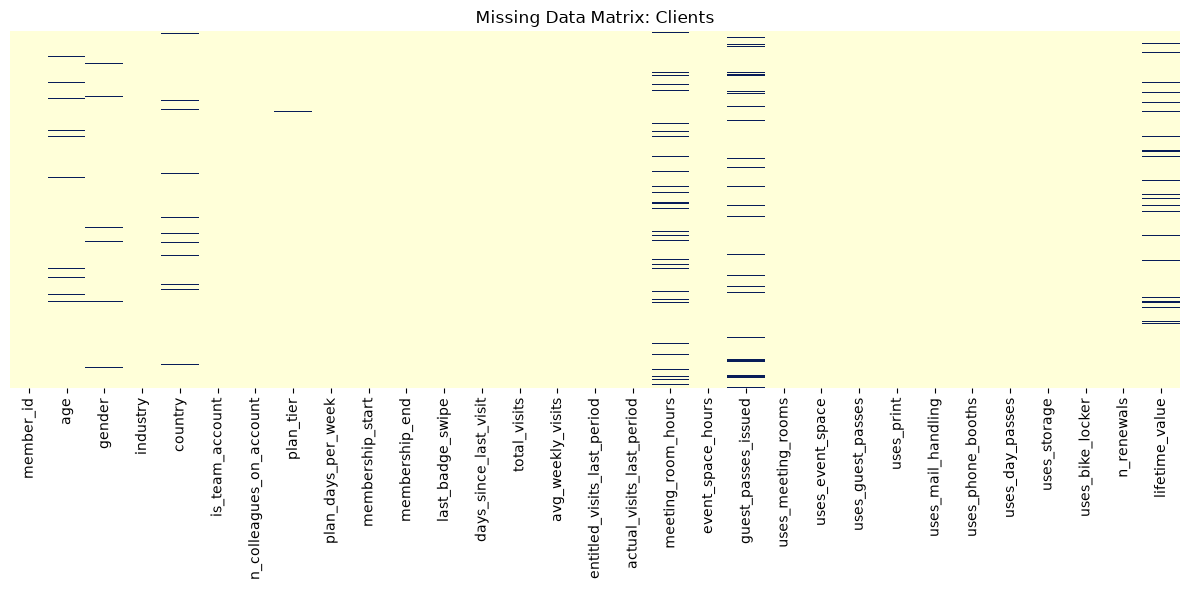

,Column,Null Count,Null %
4,meeting_room_hours,1298,8.39
5,guest_passes_issued,1271,8.22
6,lifetime_value,1150,7.44
0,age,558,3.61
1,gender,530,3.43
2,country,430,2.78
3,plan_tier,105,0.68


In [352]:
nulls_clients = check_nulls(df_raw, "Clients")
nulls_clients

#### 1.3.1.2.1 Missing Values correlation

In [353]:
def check_msno_corr(df: pd.DataFrame, df_name: str = "Dataset"):
    """
    Function to  linear visualize the correlation of the missingness of the data.

    Parameters
    ----------
    df : pd.DataFrame
            DataFrame that will be analyzed.
    str : str
            Name of the dataset

    Returns
    -------
    plot : Plot with linear missingness correlation.
    """
    #only plot if there is missingness.
    if df.isnull().sum().sum() == 0:
        print(f"No missingness to correlate in {df_name}.")
        return

    #compute missingness correlation
    msno_corr = df.isnull().corr()
    null_mask = np.triu(np.ones_like(msno_corr, dtype=bool), k=0)

    #Plot
    plt.figure(figsize=(12, 10))
    sns.heatmap(msno_corr, mask=null_mask, annot=False, cmap="coolwarm", center=0,vmin=-1,vmax=1)
    plt.title(f"Missingness Correlation Matrix: {df_name}")
    plt.show()

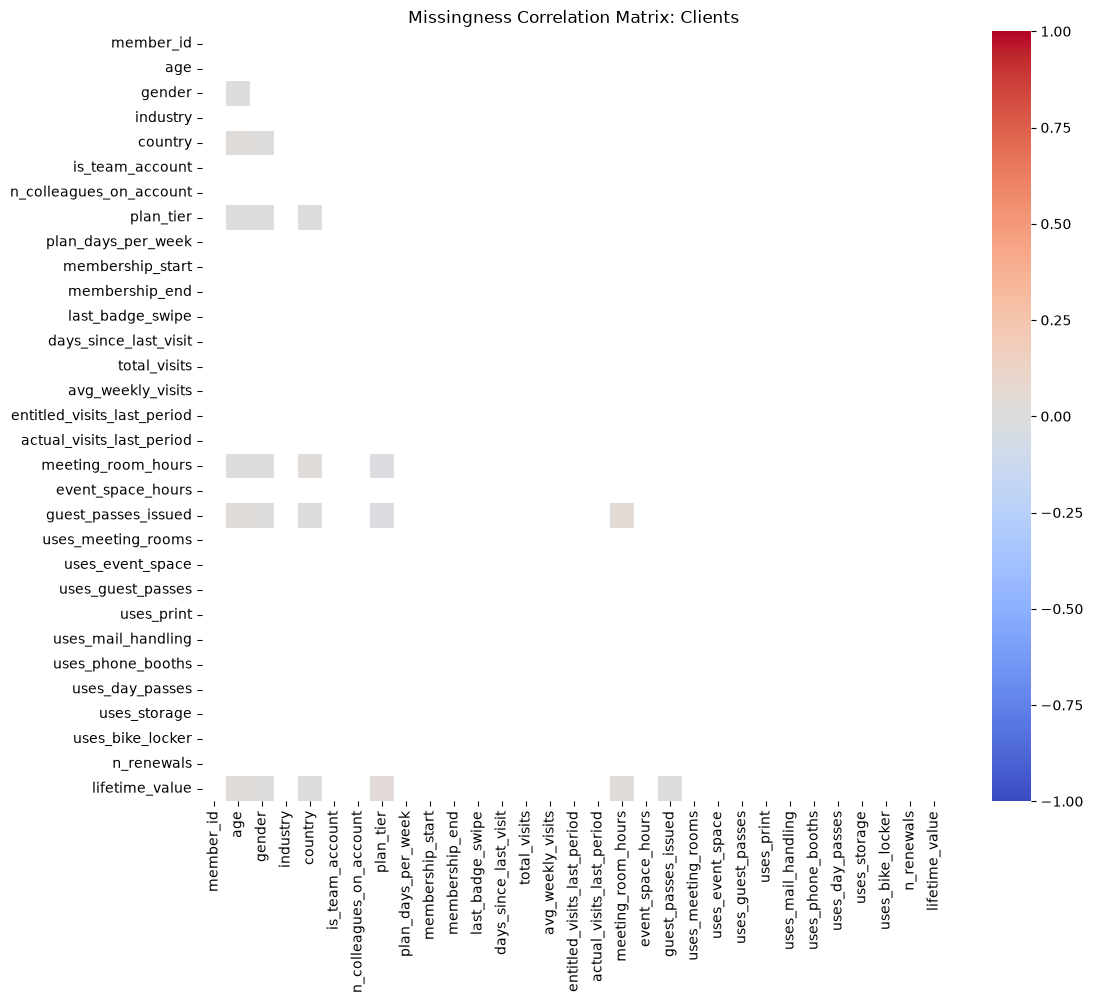

In [354]:
check_msno_corr(df_raw, "Clients")

- 7 features have missing values, but none with an agregious ammount(all bellow 10%).
- There's no linear correlation amongst missing values, meaning that when a feature misses it usualy doesn't miss with other features.

#### 1.3.1.2.1 Missing Values MCAR little test - Are features MCAR?

#### 1.3.1.2.1.1 Numeric MCAR?

In this part we will test if numerical features are missing completly at random (MCAR) or not.

In [355]:
def test_mcar(df, alpha=0.05):
    """
    Perform Little's MCAR test on numerical variables.

    Parameters
    ----------
    df : pd.DataFrame
        DataFrame to test.
    alpha : float, default=0.05
        Significance level.

    Returns
    -------
    float
        Little's MCAR test p-value.
    """

    #keep numerical columns only
    numeric_df = df.select_dtypes(include="number")

    #keep only numerical columns with missing values
    numeric_missing = numeric_df.loc[:, numeric_df.isna().any()]

    if numeric_missing.empty:
        print("No numerical features with missing values found.")
        return None

    print(
        f"Testing {numeric_missing.shape[1]} numerical features "
        f"with missing values."
    )

    #little's MCAR test
    mcar_test = MCARTest(method="little")
    p_value = mcar_test.little_mcar_test(numeric_missing)

    print(f"Little's MCAR test p-value: {p_value:.4f}")

    if p_value > alpha:
        print(
            f"Fail to reject H0: missingness is consistent with MCAR "
            f"(alpha = {alpha})."
        )
    else:
        print(
            f"Reject H0: missingness is not consistent with MCAR "
            f"(alpha= {alpha})."
        )

    return p_value

In [356]:
p_value = test_mcar(df_raw)

Testing 4 numerical features with missing values.
Little's MCAR test p-value: 0.0000
Reject H0: missingness is not consistent with MCAR (alpha= 0.05).


Numerical features can't be rejected as being not MCAR, which means that we need to further explore if missingness has a defined pattern.

#### 1.3.1.3 Temporal Coverage

##### 1.3.1.3.1 Visualization

In [357]:
def plot_multi_temporal_coverage(df: pd.DataFrame, date_cols: list, df_name: str = "Dataset"):
    """
    Inspect dates features from dataframe.
    
    Parameters
    ----------
    df : pd.DataFrame
        The Pandas DataFrame to analyze.
    date_cols: pd.List
        List of features to plot
    str: pd.String
        String name for title
            
    Returns:
    ---------
        A plot of the desired features.
    """

    #sizing plots
    n_cols = 2
    n_rows = math.ceil(len(date_cols) / n_cols)
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 5), squeeze=False)
    axes = axes.flatten()
    
    for i, col in enumerate(date_cols):
        #drop na and make sure it's datetime
        temp_series = pd.to_datetime(df[col]).dropna()
        
        if temp_series.empty:
            axes[i].text(0.5, 0.5, f"{col} is empty", ha='center', va='center')
            axes[i].set_title(f"{col}", fontsize=12, fontweight='bold')
            continue


        temp_df = (
            temp_series.dt.to_period('M')
            .dt.to_timestamp()
            .value_counts()
            .sort_index()
            .reset_index()
        )
        temp_df.columns = [col, "count"]
        
        #area plot
        axes[i].fill_between(
            temp_df[col], 
            temp_df["count"], 
            color="teal", alpha=0.2
        )
        axes[i].plot(
            temp_df[col], 
            temp_df["count"], 
            color="teal", linewidth=1.5
        )
        
        axes[i].set_title(f"{col}", fontsize=12, fontweight='bold')
        axes[i].set_ylabel("Records")
        axes[i].grid(axis='y', linestyle='--', alpha=0.3)
        axes[i].tick_params(axis='x', rotation=30)

    #Hide unused subplots
    for j in range(len(date_cols), len(axes)):
        axes[j].set_visible(False)
        
    plt.suptitle(f"Temporal Coverage Analysis - {df_name}", fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()

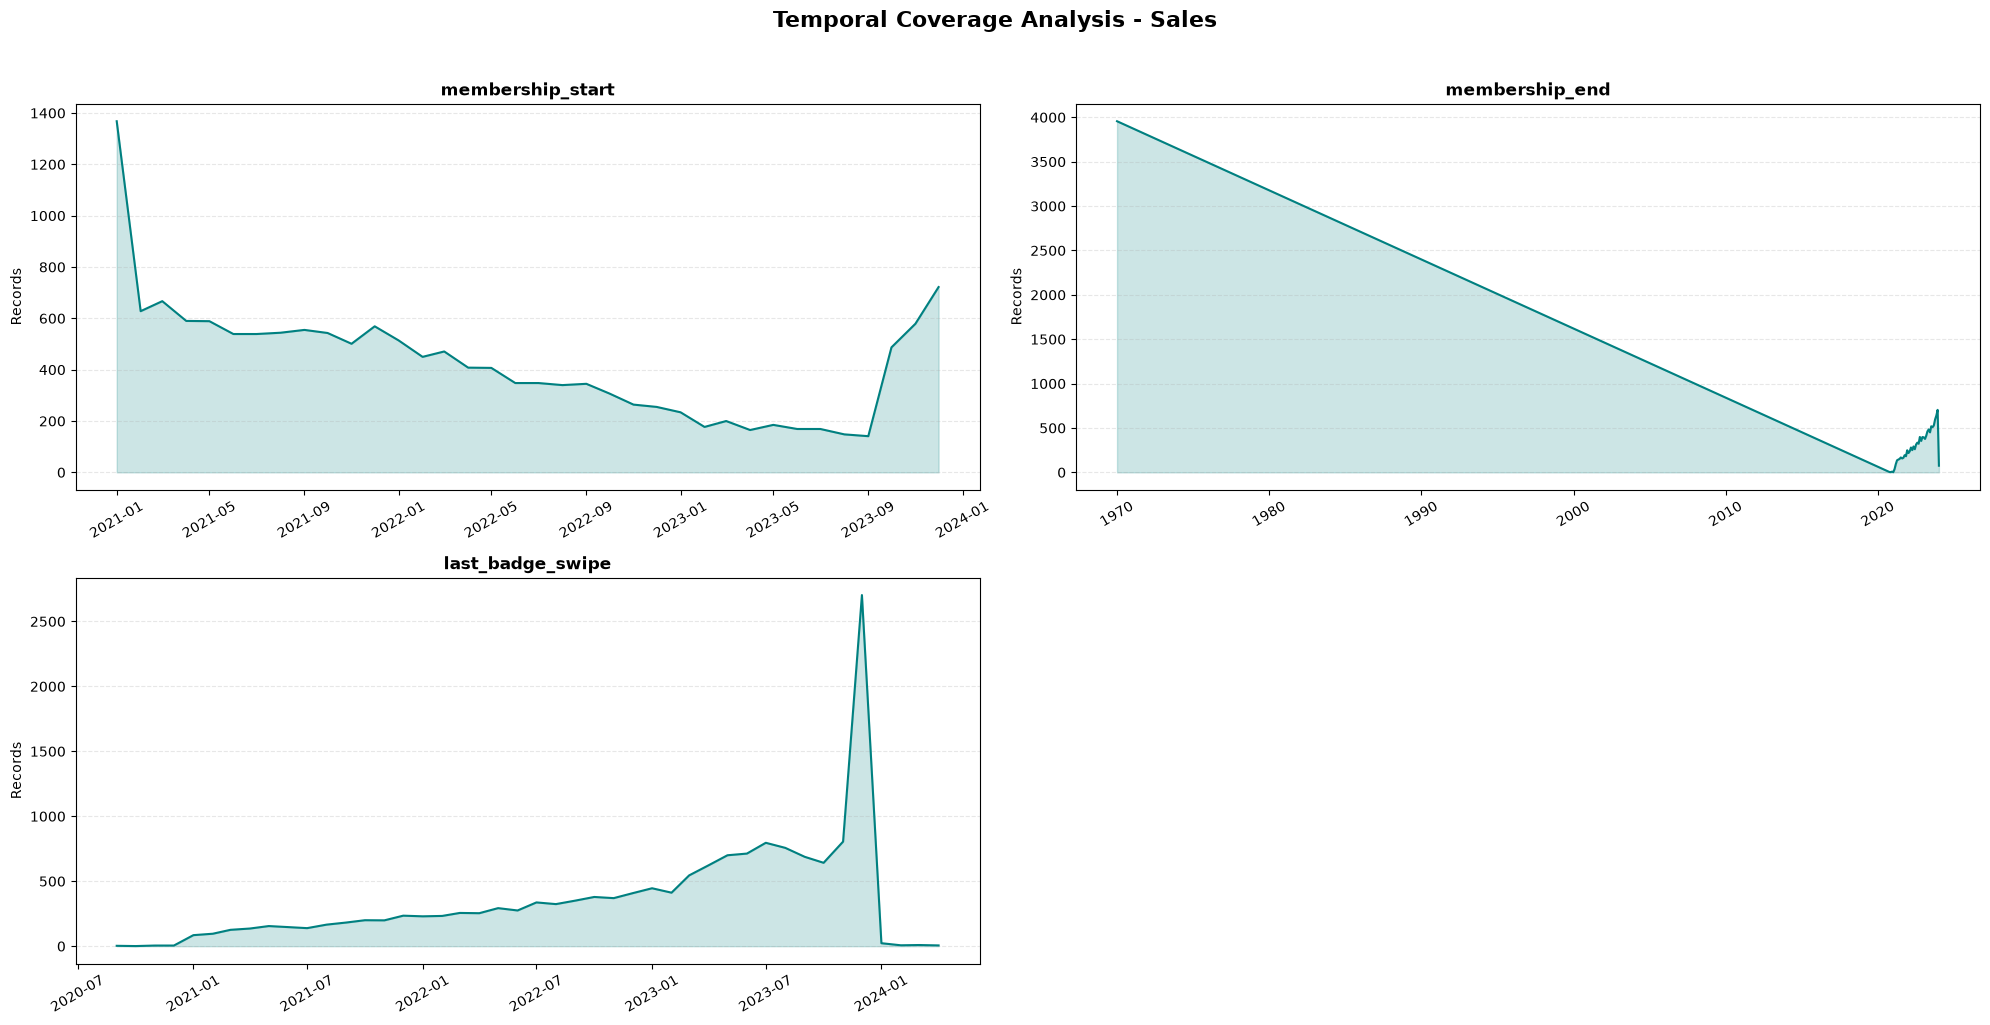

In [358]:
date_vars = ["membership_start","membership_end","last_badge_swipe"] 
plot_multi_temporal_coverage(df_raw, date_vars,"Sales")

- We have a membership peak on the start of our 3 year data(2021-2024), then we shart to see membership falling until 2023/09 where we see a bounce back.
- We see that the membership end date forms a massive peak near 1970,this indicates some sort of error.
- We can see a steady increase of membership end date as should be expected, the exception is the end of our date which could be easily explained by right censoring.
- On last_badge_swipe we can see a steady increase until the very end which can be explained by right censoring.
- Finaly on last_badge_swipe we can see a slight increase outside of expected range 2021/01/01 and 2024/01/01, we will need to inspect this value to decide what to do.

We need to fix the -4k membership_end dates otherwise EDA would be broken, we will set it to the maximum value(2024/01/01) , because they represent people that are currently active and as such have no currrent end date.

In [359]:
def time_fix_1970(df: pd.DataFrame, date_cols: list):
    """
    If data is in 1970-01-01 we set it to the maximum end date.

    Parameters
    ----------
        df : pd.DataFrame
            The Pandas DataFrame to analyze.
        
        date_cols: pd.List
                List of features
                
    Returns:
    ---------
        df:pd.Dataframe
            The df with fixed dates.
            
    """

    df[date_cols] = df[date_cols].replace("1970-01-01", "2024-01-01")
    return df


In [360]:
#preserve active status before replacing the placeholder end dates.
df_raw["is_active"] = (df_raw["membership_end"] == pd.Timestamp("1970-01-01")).astype(int)

#replace placeholder dates for duration calculations.
df_raw = time_fix_1970(df_raw, ["membership_end"])

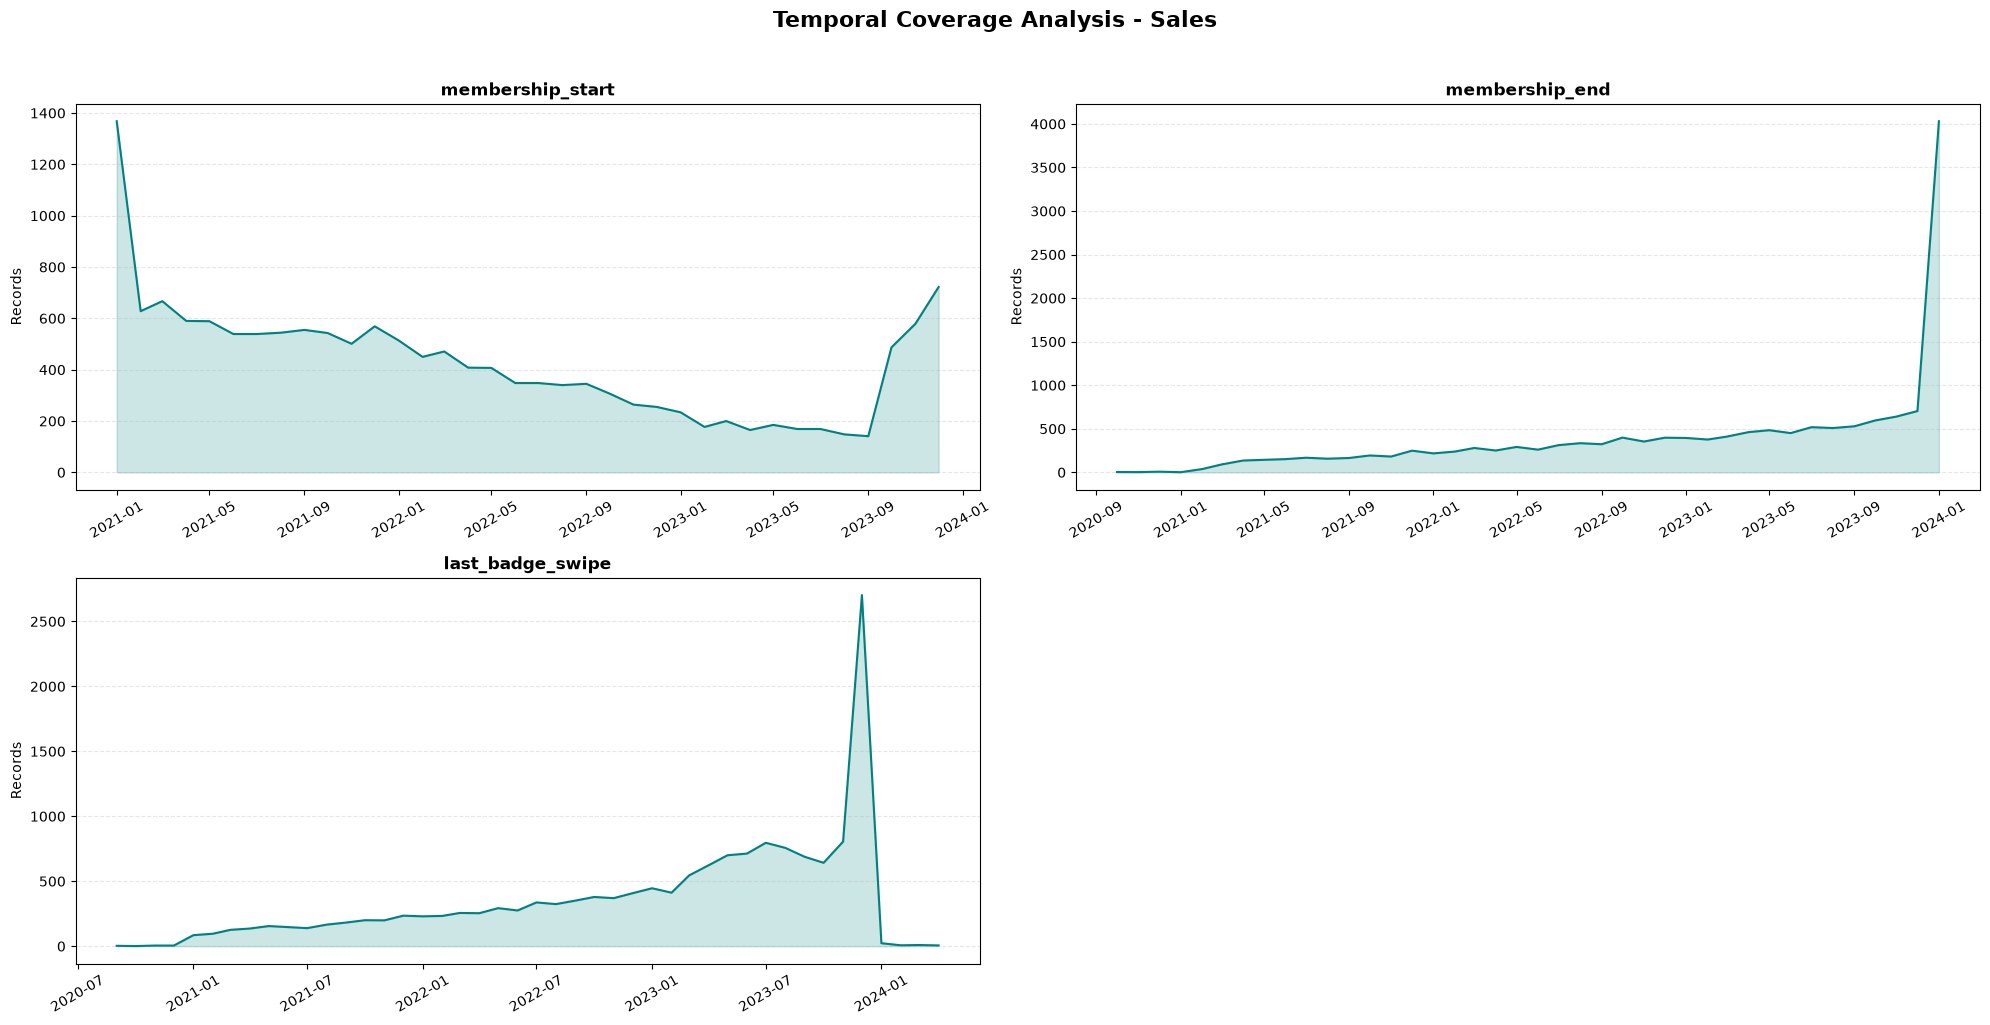

In [361]:
date_vars = ["membership_start","membership_end","last_badge_swipe"] 
plot_multi_temporal_coverage(df_raw, date_vars,"Sales")

##### 1.3.1.3.2 Temporal Logic Constraints

Now we need to see if some logical constraits are in place:
- membership_start should never be greater than membership_end, a member can't end a membership before starting.
- last_badge_swipe should never be smaller than membership_start, a member can't be last seen before starting.
- last_badge_swipe shouldn't be greater than membership_end, however this one is a bit murky because there might be exceptions where we allow late check-outs. So we should allow for a grace period if possible.

If a clients fails any of this constraints we should create a flag.

First let's begin with late starts.

In [362]:
df_raw_end_start_broken=df_raw[(df_raw["membership_start"] > df_raw["membership_end"])]
df_raw_end_start_broken

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value,is_active
165,CW000161,<NA>,Female,Marketing & PR,Portugal,False,0,flex,3,2021-10-25,2021-10-17,2023-02-12,5,161,2.36,26.09,20,24.50,0.00,0,True,False,False,True,False,False,False,False,False,1,3255.60,0
290,CW000284,42,Other,Design & Creative,France,True,4,hot_desk,2,2021-03-19,2021-03-12,2022-08-11,6,83,1.13,17.39,10,0.00,129.50,135,False,True,True,False,False,True,False,False,False,0,10056.58,0
322,CW000315,39,Female,Design & Creative,Portugal,False,0,hot_desk,2,2021-08-17,2021-06-29,2021-08-17,999,7,0.99,14.29,7,0.00,0.00,0,False,False,False,False,True,True,True,False,False,0,0.00,0
493,CW000480,43,Female,Design & Creative,Spain,False,0,flex,3,2021-10-09,2021-09-15,2022-05-13,-240,85,2.70,26.09,20,0.00,0.00,0,False,False,False,False,False,False,True,False,False,0,1513.76,0
511,CW000498,<NA>,Female,Design & Creative,Portugal,True,1,full_time,5,2022-05-10,2022-02-10,2023-11-15,-643,359,4.50,43.48,31,95.70,0.00,0,True,False,False,True,True,True,False,True,False,5,7349.95,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14622,CW014198,44,Female,Design & Creative,Portugal,False,-1,hot_desk,2,2023-05-01,2023-03-05,2023-12-25,-295,68,1.95,17.39,17,0.00,0.00,0,False,False,False,True,False,True,False,False,False,1,NaN,0
15070,CW014633,44,M,Unknown,Portugal,True,1,private_office,7,2023-11-26,2023-10-24,2023-12-28,-65,0,4.91,35.26,22,2.30,0.00,0,True,False,False,True,True,False,False,False,False,2,807.24,0
15108,CW014670,41,Female,Information Technology,Portugal,True,1,full_time,5,2022-03-06,2021-12-18,2023-01-03,-381,3,0.03,43.48,0,6.80,0.00,0,True,False,False,False,True,False,False,False,False,6,6530.95,0
15296,CW014850,44,Female,Unknown,Portugal,True,6,hot_desk,2,2023-08-10,2023-05-25,2023-10-03,8,4,0.44,17.39,4,0.00,0.00,0,False,False,False,False,False,False,False,False,False,-3,243.79,0


- 152 rows break our first logic constraint.


Now let's compare end date against last_badge_swipe.

In [363]:
df_swipe_after_membership_end=df_raw[df_raw["last_badge_swipe"] > (df_raw["membership_end"])]
df_swipe_after_membership_end

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value,is_active
0,CW000001,38,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,2023-03-06,2023-03-23,-17,220,2.65,26.09,22,0.00,0.00,18,False,False,True,False,False,True,True,False,False,2,4477.97,0
165,CW000161,<NA>,Female,Marketing & PR,Portugal,False,0,flex,3,2021-10-25,2021-10-17,2023-02-12,5,161,2.36,26.09,20,24.50,0.00,0,True,False,False,True,False,False,False,False,False,1,3255.60,0
290,CW000284,42,Other,Design & Creative,France,True,4,hot_desk,2,2021-03-19,2021-03-12,2022-08-11,6,83,1.13,17.39,10,0.00,129.50,135,False,True,True,False,False,True,False,False,False,0,10056.58,0
307,CW000301,21,Female,Marketing/PR,Portugal,False,0,full_time,5,2021-07-20,2022-08-16,2022-11-20,4,171,3.04,43.48,29,7.10,0.00,0,True,False,False,False,False,True,True,False,False,2,4211.30,0
322,CW000315,39,Female,Design & Creative,Portugal,False,0,hot_desk,2,2021-08-17,2021-06-29,2021-08-17,999,7,0.99,14.29,7,0.00,0.00,0,False,False,False,False,True,True,True,False,False,0,0.00,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15296,CW014850,44,Female,Unknown,Portugal,True,6,hot_desk,2,2023-08-10,2023-05-25,2023-10-03,8,4,0.44,17.39,4,0.00,0.00,0,False,False,False,False,False,False,False,False,False,-3,243.79,0
15376,CW014928,<NA>,Female,Legal,Portugal,True,1,full_time,5,2021-01-01,2024-01-01,2024-02-18,999,32,0.20,43.48,2,12.20,0.00,0,True,False,False,False,False,False,False,False,False,3,0.00,1
15421,CW014973,27,Male,Finance,Spain,False,0,flex,3,2022-05-09,2024-01-01,2024-04-12,-102,16,0.18,26.09,1,0.00,0.00,0,False,False,False,False,True,False,False,False,False,3,3850.49,1
15431,CW014983,31,Male,Finance,Portugal,False,0,hot_desk,2,2021-11-01,2021-10-04,2022-01-02,28,14,1.08,17.39,9,30.50,0.00,<NA>,True,False,False,False,False,False,True,False,False,0,812.80,0


- 240 rows are broken.
- The first entry is debatable, theoreticaly a member could have rented a space and have left late. Curiosly this entry is the only one where days_since_last_visit is negative which might further indicate that this is a legitimate entry.
- The other entries will be fixed after membership_end based on time derived features.

Finally we compare start date against last_badge_swipe.

In [364]:
df_swipe_before_membership_start=df_raw[(df_raw["last_badge_swipe"] < df_raw["membership_start"])]
df_swipe_before_membership_start

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value,is_active
466,CW000454,29,Other,Consulting,France,False,0,fulltime,5,2021-09-16,2024-01-01,2021-07-14,149,13,0.11,43.48,1,0.00,0.00,0,False,False,False,False,False,True,False,True,False,5,8658.18,1
556,CW015291,33,Male,Information technology,Portugal,True,-1,FLEX,3,2022-01-06,2022-04-07,2021-12-04,8,37,2.85,26.09,19,0.00,0.00,0,False,False,False,True,False,False,False,True,False,1,639.00,0
679,CW000660,<NA>,Female,Design & Creative,Portugal,False,0,dedicated_desk,5,2021-01-02,2023-12-07,2020-12-12,0,594,3.89,43.48,31,33.60,0.00,<NA>,True,False,False,True,True,True,False,False,False,4,13847.45,0
735,CW000715,37,Female,Marketing & PR,Germany,False,0,FLEX,3,2023-12-26,2024-01-01,2023-10-30,6,1,0.54,2.39,1,0.10,0.00,0,True,False,False,False,False,False,False,False,False,0,34.16,1
778,CW000756,30,F,Design & Creative,Portugal,False,0,hot_desk,2,2021-11-19,2023-03-23,2021-11-12,496,126,1.80,17.39,13,16.70,0.00,0,True,False,False,False,False,False,False,False,False,2,2126.75,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14797,CW014369,35,Female,Unknown,France,False,0,flex,3,2023-11-27,2024-01-01,2023-09-13,13,4,0.76,14.79,2,0.00,0.00,0,False,False,False,True,False,False,False,False,False,0,213.11,1
15092,CW014654,37,Female,Design & Creative,Portugal,False,0,hot_desk,2,2022-06-06,2022-08-12,2022-03-08,157,4,0.40,17.39,3,0.00,0.00,0,False,False,False,False,False,False,False,False,False,0,264.71,0
15109,CW014671,60,Female,Design & Creative,Portugal,False,0,flex,3,2021-10-27,2022-05-01,2021-09-24,219,72,2.70,26.09,26,0.00,0.00,0,False,False,False,True,False,False,False,False,False,0,1153.43,0
15254,CW014809,35,Male,Design & Creative,Portugal,False,0,hot_desk,2,2023-07-27,2023-09-08,2023-04-06,43,7,1.08,12.22,5,0.00,0.00,0,False,False,False,False,False,False,True,False,False,0,210.81,0


- 94 rows here are broken.

In [365]:
df_temporal_errors = pd.concat([df_raw_end_start_broken,df_swipe_after_membership_end,df_swipe_before_membership_start,])
df_temporal_errors

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value,is_active
165,CW000161,<NA>,Female,Marketing & PR,Portugal,False,0,flex,3,2021-10-25,2021-10-17,2023-02-12,5,161,2.36,26.09,20,24.50,0.00,0,True,False,False,True,False,False,False,False,False,1,3255.60,0
290,CW000284,42,Other,Design & Creative,France,True,4,hot_desk,2,2021-03-19,2021-03-12,2022-08-11,6,83,1.13,17.39,10,0.00,129.50,135,False,True,True,False,False,True,False,False,False,0,10056.58,0
322,CW000315,39,Female,Design & Creative,Portugal,False,0,hot_desk,2,2021-08-17,2021-06-29,2021-08-17,999,7,0.99,14.29,7,0.00,0.00,0,False,False,False,False,True,True,True,False,False,0,0.00,0
493,CW000480,43,Female,Design & Creative,Spain,False,0,flex,3,2021-10-09,2021-09-15,2022-05-13,-240,85,2.70,26.09,20,0.00,0.00,0,False,False,False,False,False,False,True,False,False,0,1513.76,0
511,CW000498,<NA>,Female,Design & Creative,Portugal,True,1,full_time,5,2022-05-10,2022-02-10,2023-11-15,-643,359,4.50,43.48,31,95.70,0.00,0,True,False,False,True,True,True,False,True,False,5,7349.95,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14797,CW014369,35,Female,Unknown,France,False,0,flex,3,2023-11-27,2024-01-01,2023-09-13,13,4,0.76,14.79,2,0.00,0.00,0,False,False,False,True,False,False,False,False,False,0,213.11,1
15092,CW014654,37,Female,Design & Creative,Portugal,False,0,hot_desk,2,2022-06-06,2022-08-12,2022-03-08,157,4,0.40,17.39,3,0.00,0.00,0,False,False,False,False,False,False,False,False,False,0,264.71,0
15109,CW014671,60,Female,Design & Creative,Portugal,False,0,flex,3,2021-10-27,2022-05-01,2021-09-24,219,72,2.70,26.09,26,0.00,0.00,0,False,False,False,True,False,False,False,False,False,0,1153.43,0
15254,CW014809,35,Male,Design & Creative,Portugal,False,0,hot_desk,2,2023-07-27,2023-09-08,2023-04-06,43,7,1.08,12.22,5,0.00,0.00,0,False,False,False,False,False,False,True,False,False,0,210.81,0


~500 clients break our temporal features.


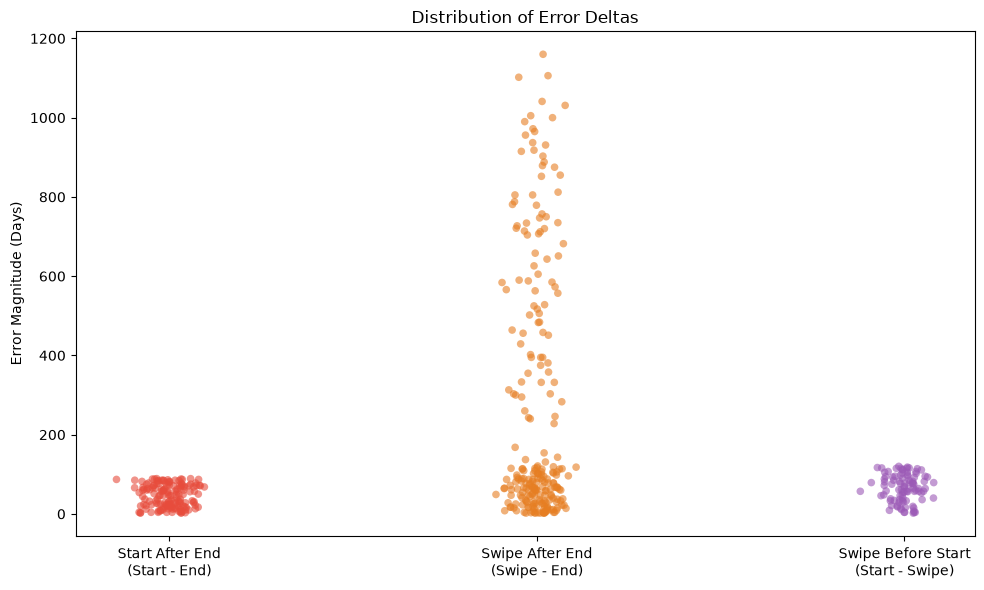

In [366]:
#calculate time deltas in days for each condition
delta_broken = (df_raw["membership_start"] - df_raw["membership_end"]).dt.days
delta_swipe_after = (df_raw["last_badge_swipe"] - df_raw["membership_end"]).dt.days
delta_swipe_before = (df_raw["membership_start"] - df_raw["last_badge_swipe"]).dt.days

#create boolean masks for each condition
mask_broken = df_raw["membership_start"] > df_raw["membership_end"]
mask_swipe_after = df_raw["last_badge_swipe"] > df_raw["membership_end"]
mask_swipe_before = df_raw["last_badge_swipe"] < df_raw["membership_start"]

#extract valid series
data_series = [
    delta_broken[mask_broken].dropna(),
    delta_swipe_after[mask_swipe_after].dropna(),
    delta_swipe_before[mask_swipe_before].dropna(),
]

#x labels
labels = [
    "Start After End\n(Start - End)",
    "Swipe After End\n(Swipe - End)",
    "Swipe Before Start\n(Start - Swipe)",
]

colors = ["#e74c3c", "#e67e22", "#9b59b6"]

#create the point plot
fig, ax = plt.subplots(figsize=(10, 6))

for i, (series, label, color) in enumerate(zip(data_series, labels, colors)):
  #add slight horizontal jitter so overlapping points are visible
  x = np.random.normal(i + 1, 0.04, size=len(series))
  ax.scatter(x, series, label=label, color=color, alpha=0.6, s=30, edgecolors="none")

#customize axes and labels
ax.set_xticks([1, 2, 3])
ax.set_xticklabels(labels)
ax.set_ylabel("Error Magnitude (Days)")
ax.set_title("Distribution of Error Deltas")

plt.tight_layout()
plt.show()

Swipe after end is the most problematic rule.

#### 1.3.1.4 Duplicated Values

We will now see if member id can be used as an index.

In [367]:
def check_grain_integrity(df: pd.DataFrame, grain_cols: list[str]):
    """
    Assess the integrity of a dataset with respect to a specified grain.
    This function evaluates whether the provided grain columns uniquely identify entries.

    Parameters
    ----------
    df : pd.DataFrame
        The input dataset to evaluate.

    grain_cols : list
        Columns that together define the expected grain of the dataset.

    Returns
    -------
    None
        The function only prints a summary of grain integrity diagnostics and if duplicated rows are found we print the top 5 for debugging.

    """
    
    full_dupes = df.duplicated().sum() #exact matches
    grain_dupes_mask = df.duplicated(subset=grain_cols, keep=False) #exact matches based on grain
    grain_counts = df[grain_dupes_mask].groupby(grain_cols).size() #group by grain too see duplicated

    n_grain_dupes = len(grain_counts) 
    n_affected_rows = int(grain_counts.sum())
    
    unique_counts = {
        col: df[col].nunique()
        for col in grain_cols
    }
   
    print(f"Full Row Duplicates: {full_dupes:,}")
    print(f"Unique Grain Duplicates: {n_grain_dupes:,}")
    print(f"Total Rows affected by Grain Duplicates: {n_affected_rows:,}")
    print("\nUnique values per grain column:")
    for col, val in unique_counts.items():
        print(f"{col}: {val:,}")
    if n_grain_dupes > 0: #if we find dupes we print 5 for debugging.
        print(df[grain_dupes_mask].sort_values(by=grain_cols).head(6))

In [368]:
check_grain_integrity(df_raw, ["member_id"])

Full Row Duplicates: 15
Unique Grain Duplicates: 15
Total Rows affected by Grain Duplicates: 30

Unique values per grain column:
member_id: 15,450
      member_id  age  gender           industry  \
959    CW000935   22  Female            Unknown   
15453  CW000935   22  Female            Unknown   
15454  CW001390   44    Male            UNKNOWN   
1428   CW001390   44    Male            UNKNOWN   
15462  CW003868   28  Female  Design & Creative   
3985   CW003868   28  Female  Design & Creative   

        country  is_team_account  \
959    Portugal            False   
15453  Portugal            False   
15454  Portugal            False   
1428   Portugal            False   
15462  Portugal             True   
3985   Portugal             True   

       n_colleagues_on_account plan_tier  \
959                          0      FLEX   
15453                        0      FLEX   
15454                        0  hot_desk   
1428                         0  hot_desk   
15462                 

We have problems, we have 30 entries which are entirely duplicated. We should drop the dupes.

#### 1.3.1.5 Categorical Variables

##### 1.3.1.5.1 Categorical Variables uniqueness

In [369]:
def plot_total_vs_unique_all(df: pd.DataFrame,exclude:list[str]):
    """
    Plot total row count vs. unique value count for all string columns in a DataFrame.

    Parameters
    ----------
    df : pd.DataFrame
        Input dataset.

    exclude : list
        List of column names to exclude from the analysis(e.g., IDs).

    Returns
    -------
    None
        Displays a horizontal bar plot.

    Notes
    -----
    - Only string columns are considered.
    - Columns with 100% missing values are ignored.
    """

    total = len(df)
    exclude_set = set(exclude) if exclude is not None else set()

    #filter string/categorical columns excluding specified columns and all-null columns
    cols = []
    for c in df.select_dtypes(include=["object", "string", "category"]).columns:
        if c not in exclude_set:
            if df[c].isnull().sum() < total:  #skip 100% null columns
                cols.append(c)

    if not cols:
        print("No valid string columns to plot.")
        return

    #unique count per column
    unique_counts = {c: df[c].nunique() for c in cols}

    #sort columns by unique count descending
    sorted_pairs = sorted(
        unique_counts.items(), key=lambda x: x[1], reverse=True
    )
    cols_sorted, uniques_sorted = zip(*sorted_pairs)

    #pepare positions and total array for horizontal bars
    totals = [total] * len(cols_sorted)
    x = np.arange(len(cols_sorted))

    #plot
    plt.figure(figsize=(14, max(6, len(cols_sorted) * 0.35)))
    bar_width = 0.4
    plt.barh(
        x - bar_width / 2,
        totals,
        height=bar_width,
        label="Total Rows",
        color="steelblue",
    )
    plt.barh(
        x + bar_width / 2,
        uniques_sorted,
        height=bar_width,
        label="Unique Values",
        color="orange",
    )

    plt.yticks(x, cols_sorted)
    plt.xlabel("Count")
    plt.title("Total Count vs Unique Count for String Columns")
    plt.gca().invert_yaxis() #Keeps top column at the top of the y-axis
    plt.legend()
    plt.tight_layout()
    plt.show()
    plt.close()

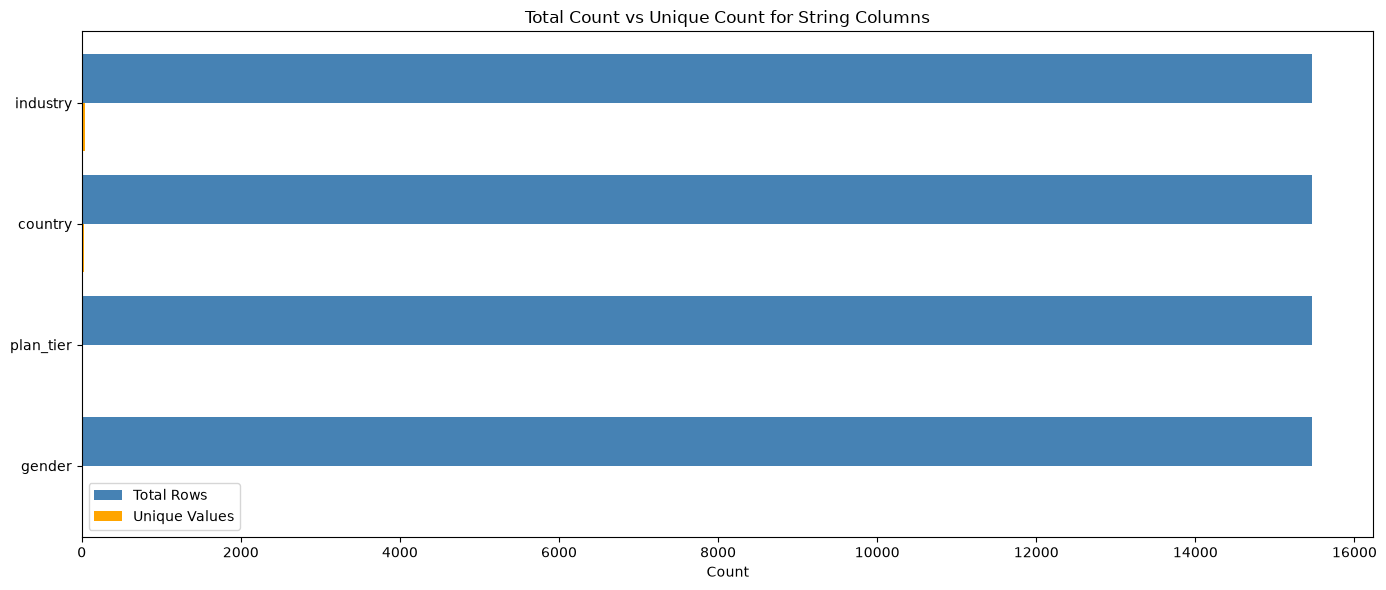

In [370]:
plot_total_vs_unique_all(df_raw,["member_id"])

We can see that all categorial features have low cardinality.

##### 1.3.1.5.2 Categorical Variables Count

In [371]:
def plot_all_categorical_pct(df: pd.DataFrame, exclude: list = None, big: bool = False, n: int = 10):
    """
    Plot percentage distributions in a bar plot for all categorical columns in a DataFrame.

    Parameters
    ----------
    df : pd.DataFrame
        Input dataset containing categorical columns.
    exclude : list of str, optional
        List of column names to exclude from the analysis (e.g., IDs).
    big : bool, default=False
        If True, plots are arranged in a single column. If False, a 4-column grid layout is used.
    n : int, default=10
        Number of top and bottom categories to display for high-cardinality columns.

    Returns
    -------
    None
        Displays a grid of bar plots.
    """

    n_total = len(df)
    exclude_set = set(exclude) if exclude is not None else set()

    #select string / object / categorical columns while excluding specified and 100% null columns
    cols = []
    for c in df.select_dtypes(include=["object", "string", "category"]).columns:
        if c not in exclude_set:
            if df[c].isnull().sum() < n_total:  # Skip all-null columns
                cols.append(c)

    if not cols:
        print("No valid string columns to plot.")
        return

    n_cols = 1 if big else 4
    n_rows = math.ceil(len(cols) / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
    axes = np.array(axes).flatten() if n_rows * n_cols > 1 else np.array([axes])

    for i, col in enumerate(cols):
        ax = axes[i]

        #calculate percentages per category (including nulls as "NULL")
        s_filled = df[col].fillna("NULL").astype(str)
        counts_df = (
            s_filled.value_counts(dropna=False)
            .reset_index()
            .rename(columns={"index": col, col: "count"})
        )

        #fix column names if pandas value_counts named the feature column differently
        counts_df.columns = [col, "count"]
        counts_df["percentage"] = (counts_df["count"] / n_total) * 100
        counts_df = counts_df.sort_values(
            by="percentage", ascending=False
        ).reset_index(drop=True)

        n_unique = len(counts_df)
        high_cardinality = n_unique > n * 2

        #high cardinality top-n / bottom-n logic
        if high_cardinality:
            top = counts_df.head(n)
            bot = counts_df.tail(n)
            separator = pd.DataFrame(
                {col: ["..."], "count": [0], "percentage": [0.0]}
            )
            counts_df = pd.concat(
                [top, separator, bot], ignore_index=True
            )
        else:
            bot = pd.DataFrame()

        #plot 
        sns.barplot(
            data=counts_df,
            x=col,
            y="percentage",
            color="#4C8BE2",
            ax=ax,
        )

        ax.set_xticks(range(len(counts_df)))
        wrapped_labels = [
            shorten(str(lbl), width=25, placeholder="…") for lbl in counts_df[col]
        ]
        ax.set_xticklabels(wrapped_labels, rotation=90, ha="center", fontsize=7)

        #color bar logic: Red for NULL, invisible for separator, muted blue for bottom
        labels = counts_df[col].tolist()
        bot_labels = set(bot[col].tolist()) if high_cardinality else set()

        for bar, label in zip(ax.patches, labels):
            if label == "NULL":
                bar.set_facecolor("#d9534f")
            elif label == "...":
                bar.set_facecolor("none")
                bar.set_edgecolor("none")
            elif label in bot_labels:
                bar.set_facecolor("#a8c5da")
            else:
                bar.set_facecolor("#4C8BE2")

        #vertical line to separate top/bot categories
        if high_cardinality:
            sep_x = ax.patches[n].get_x() + ax.patches[n].get_width() / 2
            ax.axvline(
                x=sep_x,
                color="#555555",
                linewidth=1.5,
                linestyle="--",
                alpha=0.9,
            )
            ax.text(
                sep_x,
                ax.get_ylim()[1] * 0.98,
                "Top / Bot",
                ha="center",
                va="top",
                fontsize=6,
                color="#555555",
            )

        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)

        title = (
            f"{col}  (top & bot {n} of {n_unique})"
            if high_cardinality
            else f"{col}  ({n_unique} categories)"
        )
        ax.set_title(title, fontsize=10, fontweight="bold")
        ax.set_xlabel("")
        ax.set_ylabel("%", fontsize=10)
        ax.tick_params(axis="x", labelsize=7, labelrotation=90)
        ax.tick_params(axis="y", labelsize=7)

    #hide unused axes in the grid
    for j in range(len(cols), len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.subplots_adjust(bottom=min(0.35, 0.05 * n_rows), top=0.95, hspace=0.8)
    plt.show()
    plt.close()

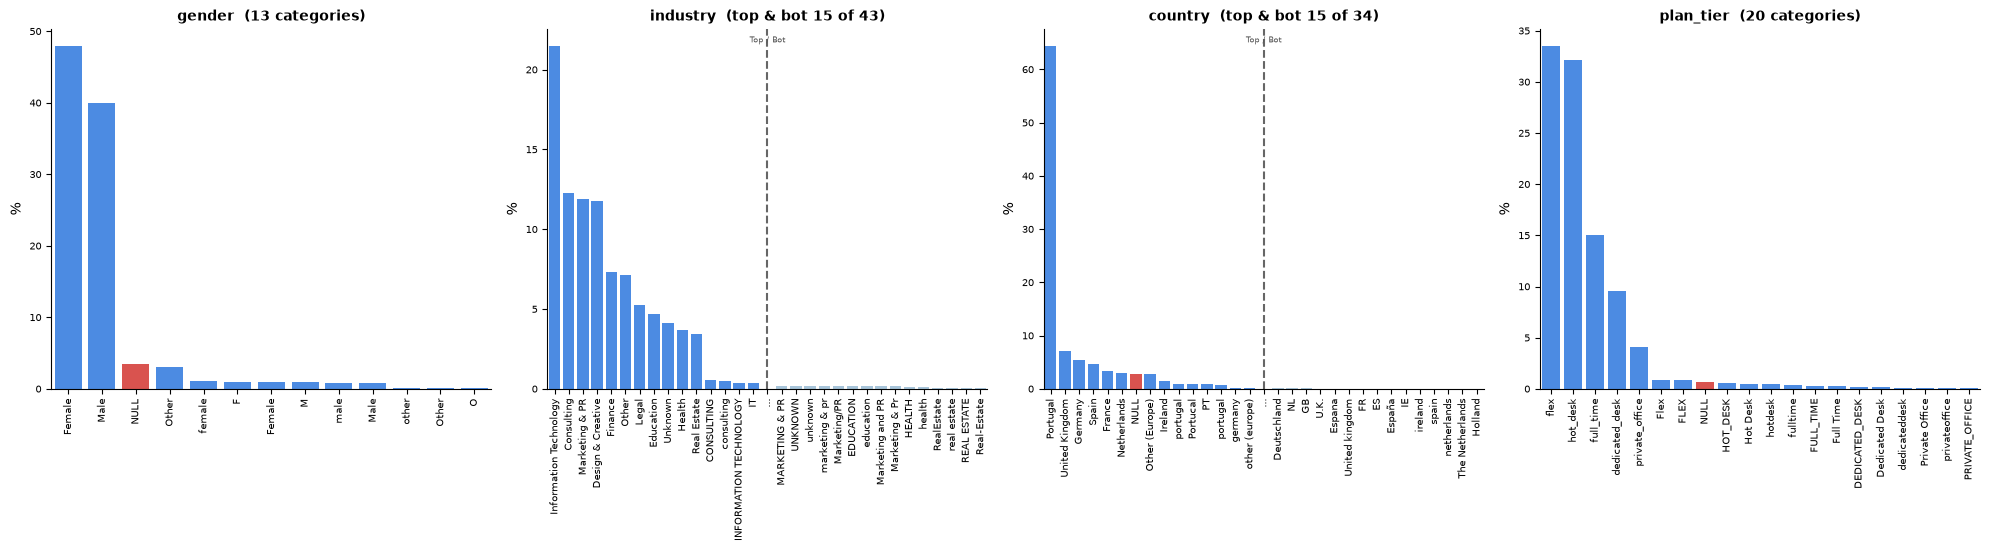

In [372]:
plot_all_categorical_pct(df_raw,exclude=["member_id"],n=15)

- Like we discussed we have some ids that show up twice.
- We can can that multiple categories across all features are in fact the same feature but with different typographic styles.We will need to standardize all categories to be lower case with no spaces.
- We can see that we have 3 possible genders : female,male and others.
- Across all categorical features we will need to use a dictionary to match abreviations , local idioms etc ...

We will now fix the categories that are just mistypes of other categories, otherwise EDA would be impossible.

In [373]:
def categorical_merge(X: pd.DataFrame):
    """
        Correct categorical features to merge correct colls.
    
        Parameters
        ----------
        X : pd.DataFrame
            Input dataset containing categorical columns.
      
        Returns
        -------
        X : pd.DataFrame
                    Fixed dataset.
    """

    #we define a misnomer map to get a dictionary.
    category_mappings = {
        "gender": {
            "f": "female",
            "m": "male",
            "o": "other",
        },
        "industry": {
            "it": "information technology",
            "tech": "information technology",
            "marketing/pr": "marketing & pr",
            "marketing and pr": "marketing & pr",
            "design/creative": "design & creative",
            "design and creative": "design & creative",
            "realestate": "real estate",
            "real-estate": "real estate",
        },
        "country": {
            "portucal": "portugal",
            "pt": "portugal",
            "uk": "united kingdom",
            "gb": "united kingdom",
            "u.k.": "united kingdom",
            "de": "germany",
            "deutschland": "germany",
            "es": "spain",
            "espana":"spain",
            "españa": "spain",
            "fr": "france",
            "nl": "netherlands",
            "holland": "netherlands",
            "the netherlands": "netherlands",
            "ie": "ireland",
        },
        "plan_tier": {
            "hot desk": "hot_desk",
            "hotdesk": "hot_desk",
            "full time": "full_time",
            "fulltime": "full_time",
            "dedicated desk": "dedicated_desk",
            "dedicateddesk": "dedicated_desk",
            "private office": "private_office",
            "privateoffice": "private_office",
        },
    }

  
    for col, mapping in category_mappings.items():
        if col in X.columns:
            #lowercase and strip whitespace for all.
            X[col] = X[col].astype(str).str.lower().str.strip()

            #map misspellings / variants to clean categories
            X[col] = X[col].replace(mapping)

            #replace string representations of missing values with Null
            X[col] = X[col].replace(["<na>", "nan", "null", "none", "unknown"], np.nan)

    return X

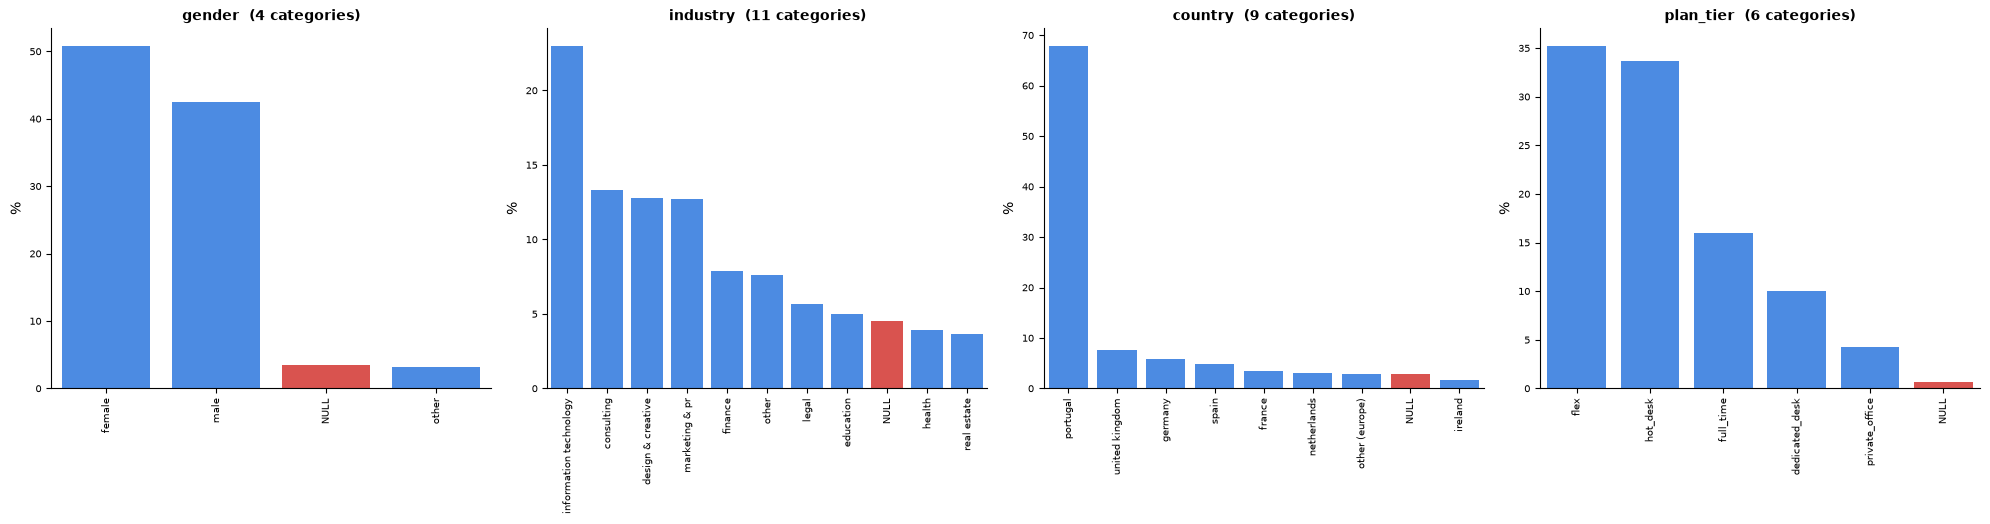

In [374]:
df_raw=categorical_merge(df_raw)
plot_all_categorical_pct(df_raw,exclude=["member_id"],n=15)

- We have 3 genders, with a male/female dominance.
- Our members are mostly from portugal or Europe.
- Our most adopted industries are IT,consulting, design&creative and marketing&pr, this industries are our core clients.
- Most of of out members are on hot_desk and flex which are the bottom tiers.
- Dedicated desk has a lower adoption than full time despite being a lower tear this might mean that full time is the sweet spot for alot of clients.

#### 1.3.1.6. Numerical Variables

##### 1.3.1.6.1 Visualizations

In [375]:
def plot_nums(X: pd.DataFrame):
    """
    Function to inspect numeric variables, visualize distributions, 
    and report outlier statistics using pandas.

    Parameters
    ----------
        df : pd.DataFrame
            Input dataset containing categorical columns.
 
        Returns
        -------
        None
            Displays a boxplot and histogram
        """
    #only get these cols
    num_cols = X.select_dtypes(include=["float64", "float32","int64"]).columns.tolist()
    
    n_total = len(X)
    counts = []

    for col in num_cols:
        #drop nan
        full_series = X[col].dropna()
        sample_series = X[col].dropna()
        
        if sample_series.empty:
            continue

        #plot
        fig, axes = plt.subplots(1, 2, figsize=(20, 4))
        fig.suptitle(f"{col}", fontsize=14, fontweight='bold')

        #boxplot
        sns.boxplot(x=sample_series, ax=axes[0], color='skyblue')
        axes[0].set_title("Boxplot")

        #histogram
        sns.histplot(sample_series, kde=True, ax=axes[1], color='salmon', bins=30)
        axes[1].set_title("Histogram")
        
        plt.tight_layout()
        plt.show()

       #stat calculation
        if not full_series.empty:
            #IQR
            q1 = full_series.quantile(0.25)
            q3 = full_series.quantile(0.75)
            iqr = q3 - q1
            lower_bound = q1 - 1.5 * iqr
            upper_bound = q3 + 1.5 * iqr
            lower_outliers = (full_series < lower_bound).sum()
            upper_outliers = (full_series > upper_bound).sum()
            total_outliers = lower_outliers + upper_outliers
            #MAD
            median=full_series.median()
            mad_val = (full_series - median).abs().median()
            thresh = 3.5 * (mad_val / 0.6745)
            upper_mad_outliers = (full_series > (median + thresh)).sum()
            lower_mad_outliers = (full_series < (median - thresh)).sum()
            total_mad_outliers = upper_mad_outliers + lower_mad_outliers


            #shape and central tendency
            counts.append({
                "Feature": col,
                "Skewness": full_series.skew(),
                "Kurtosis": full_series.kurtosis(),
                "Lower Outliers IQR": lower_outliers,
                "Upper Outliers IQR": upper_outliers,
                "Total Outliers(%) IQR": f"{total_outliers}({((total_outliers / n_total) * 100):.2f}%)",
                "Lower Outliers MAD": lower_mad_outliers,
                "Upper Outliers MAD": upper_mad_outliers,
                "Total Outliers(%) MAD": f"{total_mad_outliers}({((total_mad_outliers / n_total) * 100):.2f}%)",
                "Min": full_series.min(),
                "Max": full_series.max(),
                "Mean": round(full_series.mean(), 2),
                "Median": median,
            })

    #return the table 
    return pd.DataFrame(counts)

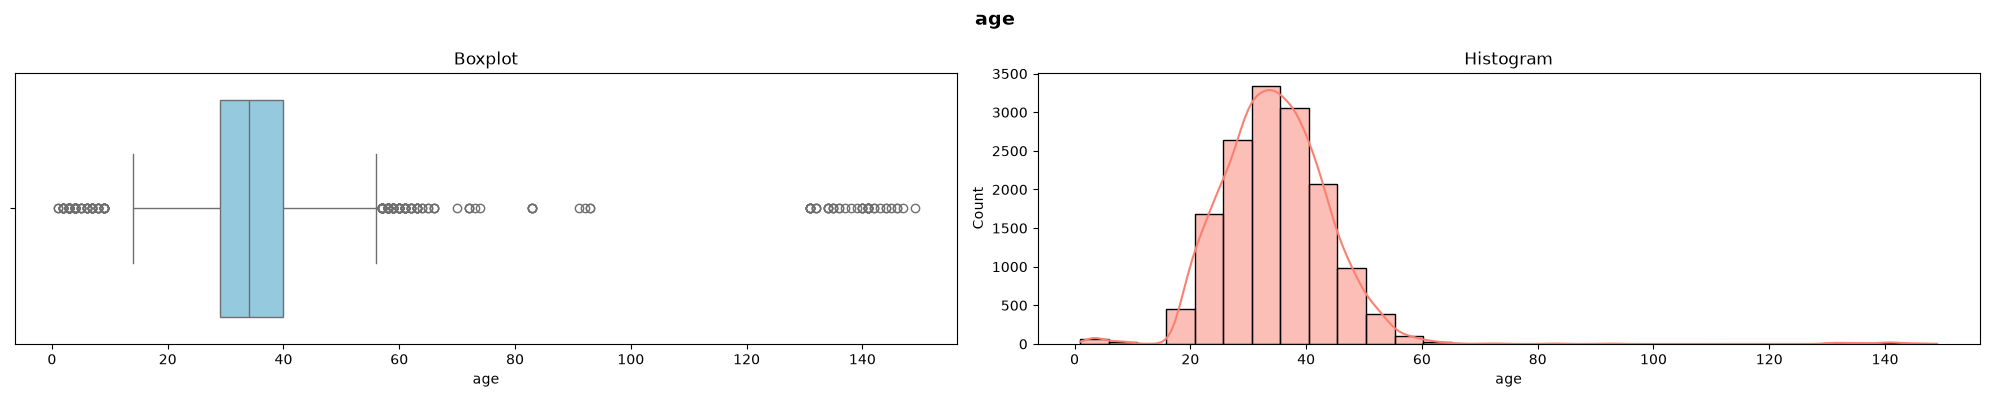

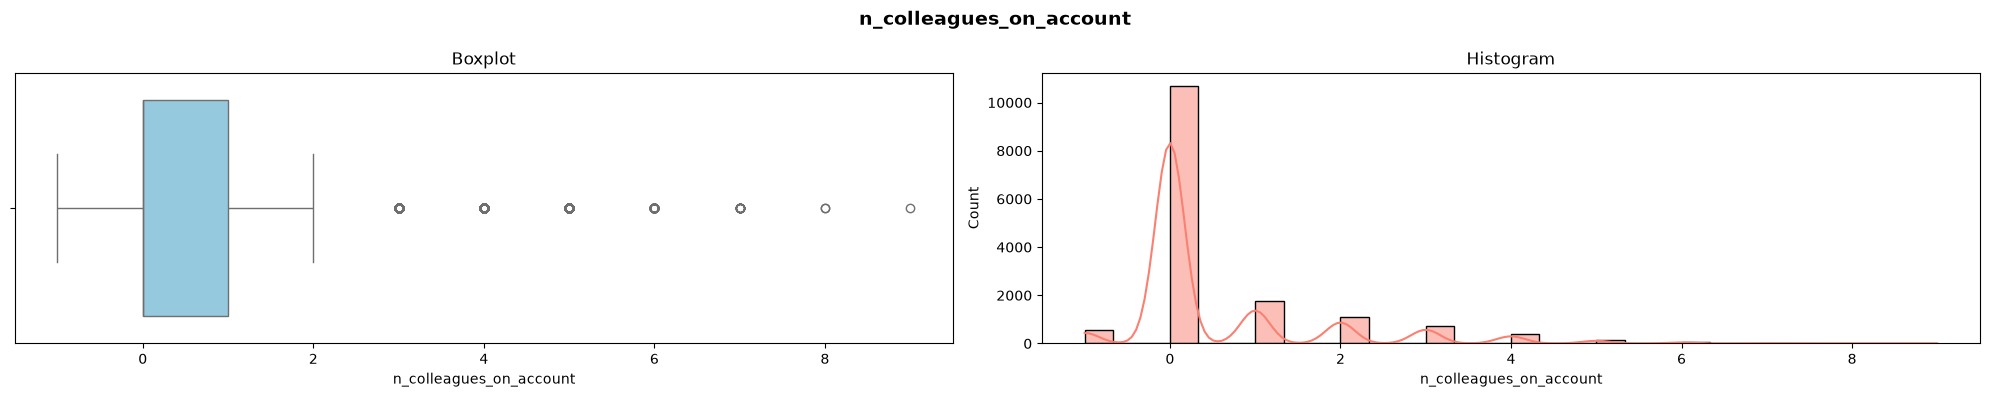

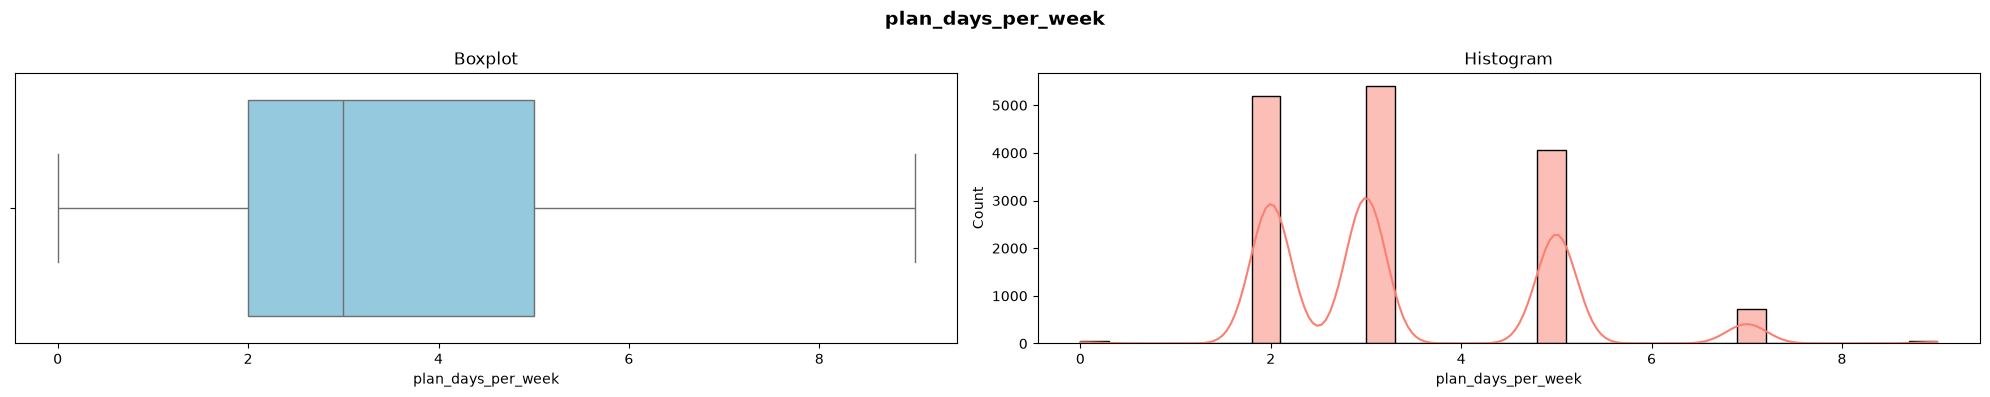

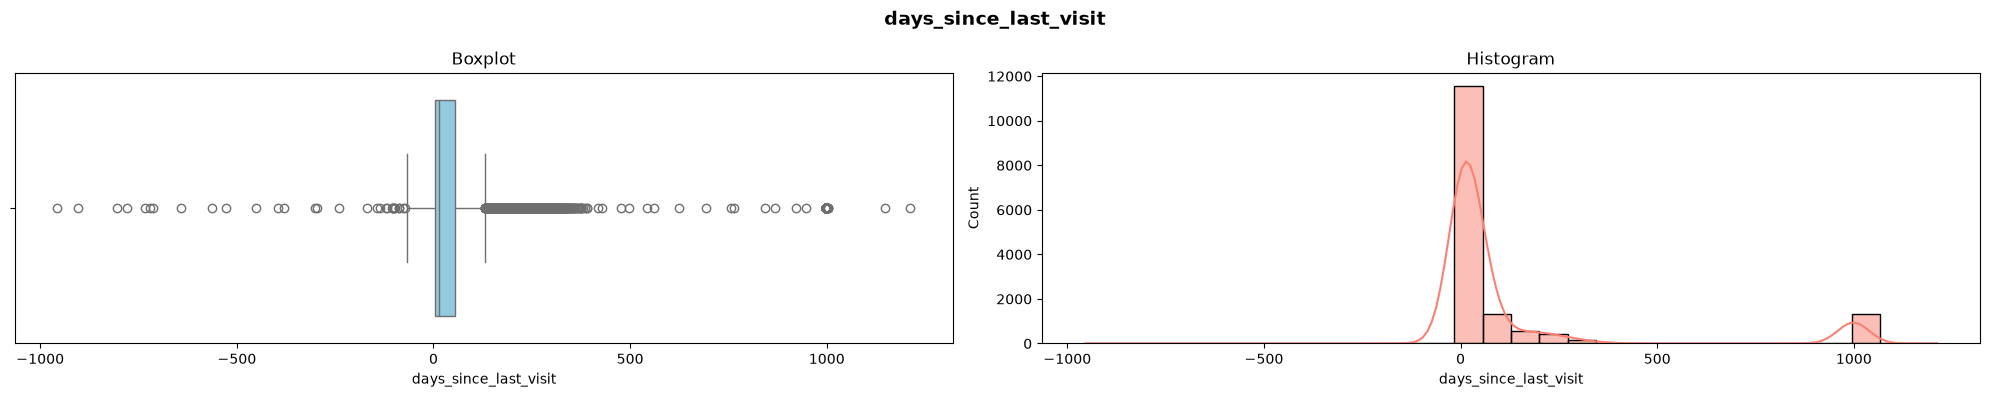

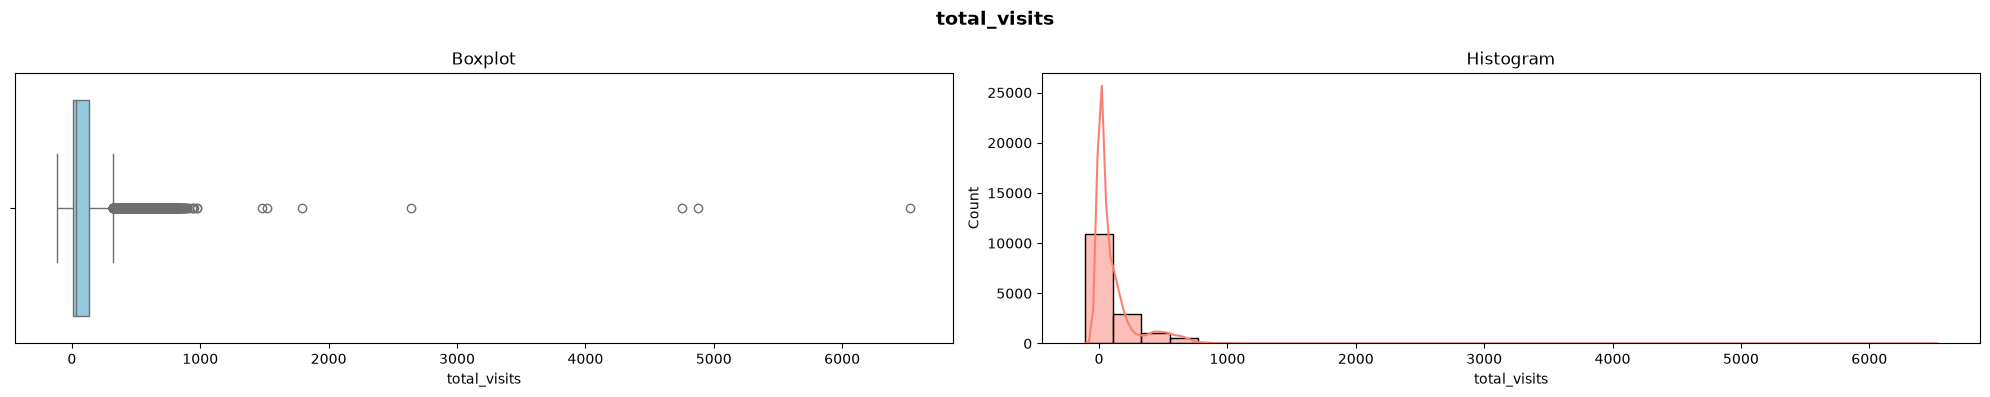

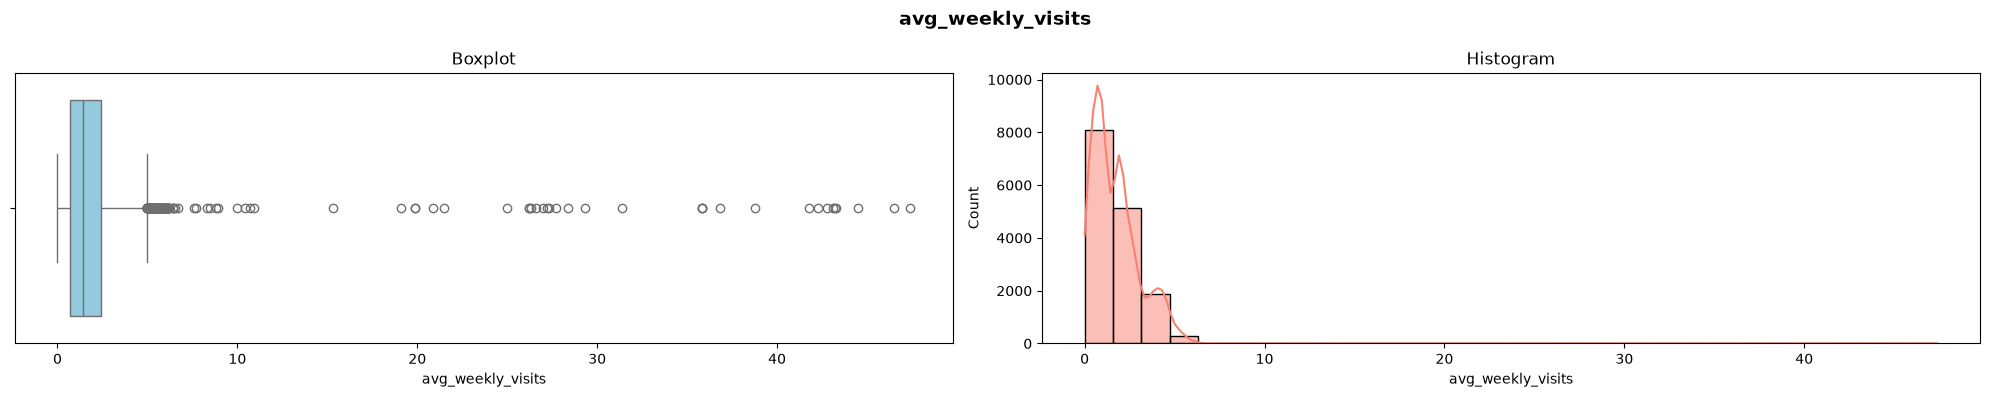

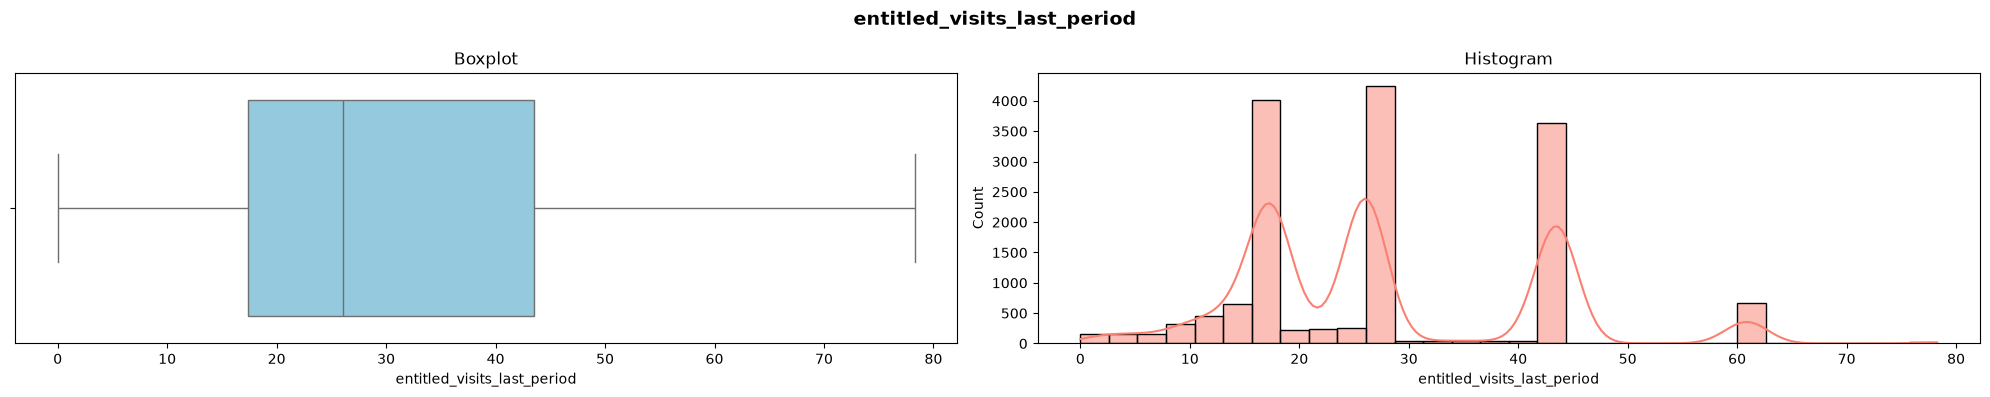

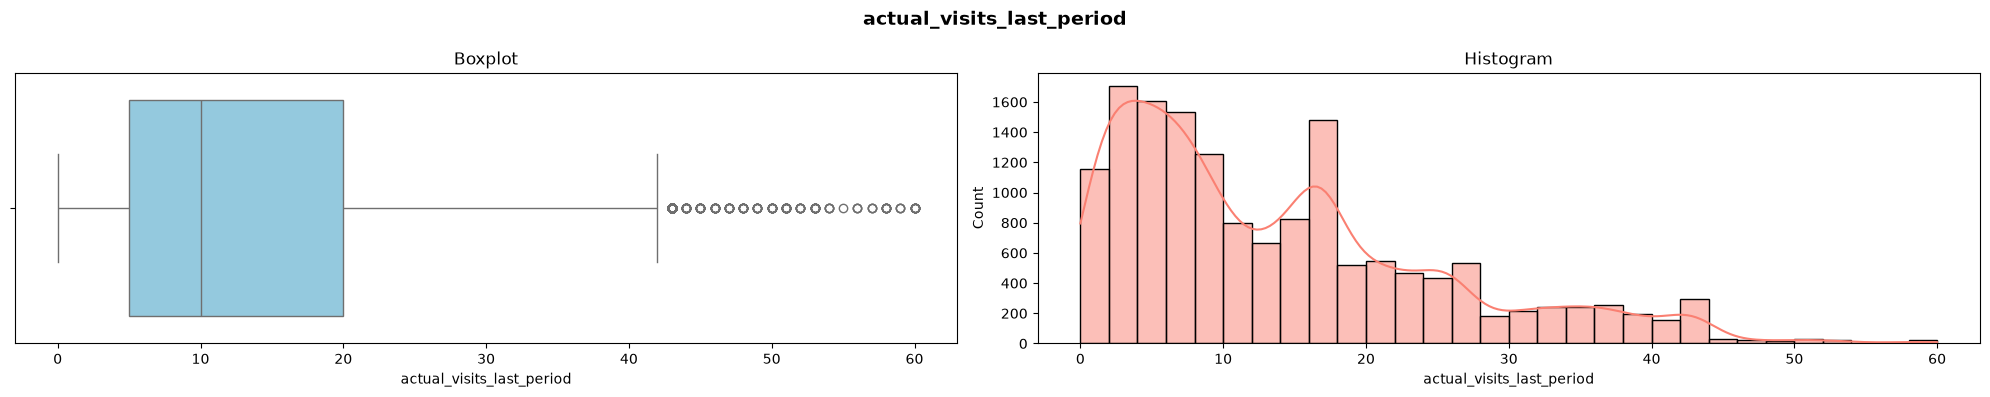

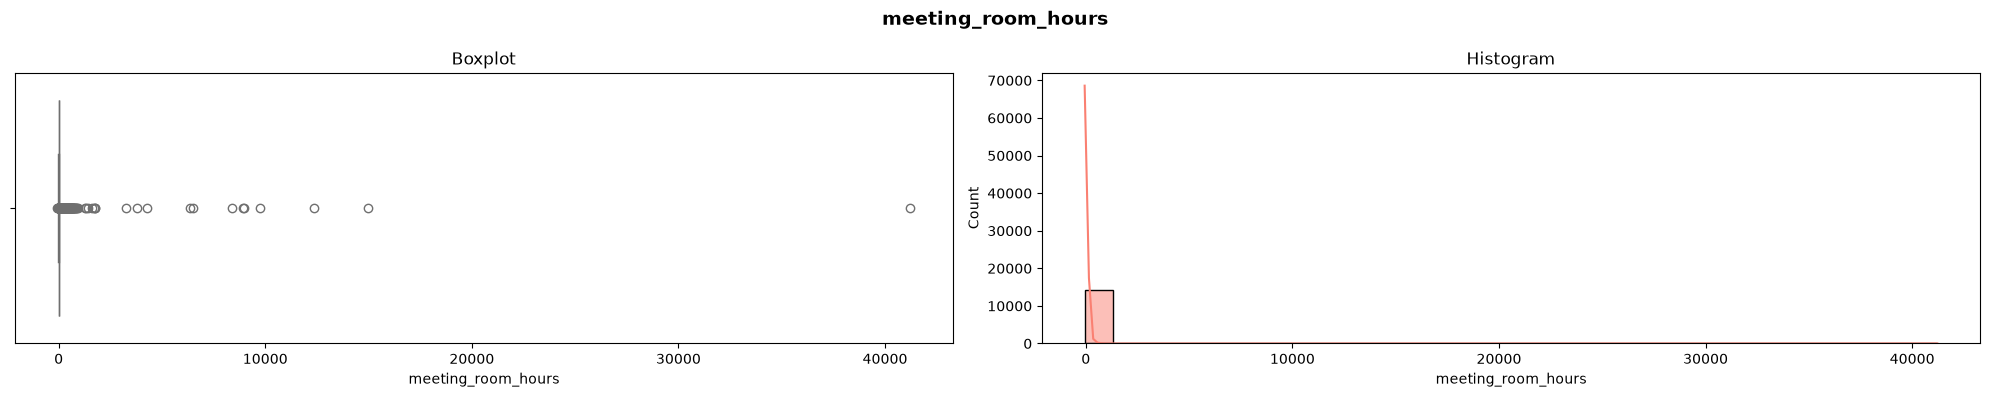

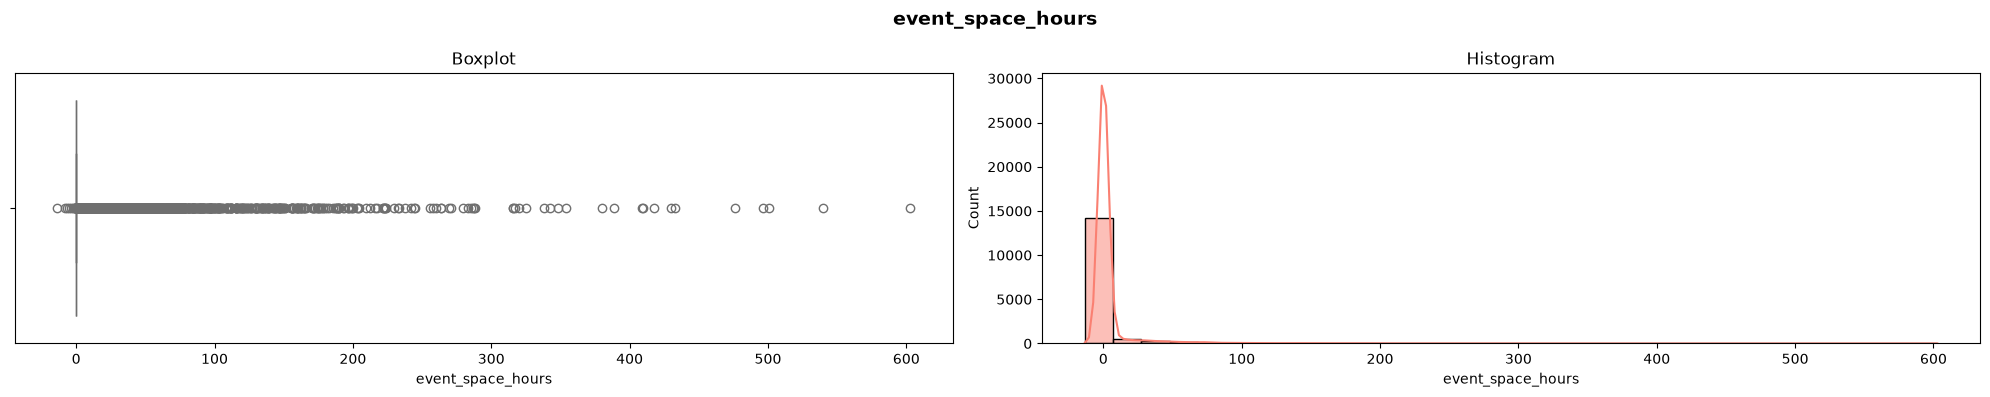

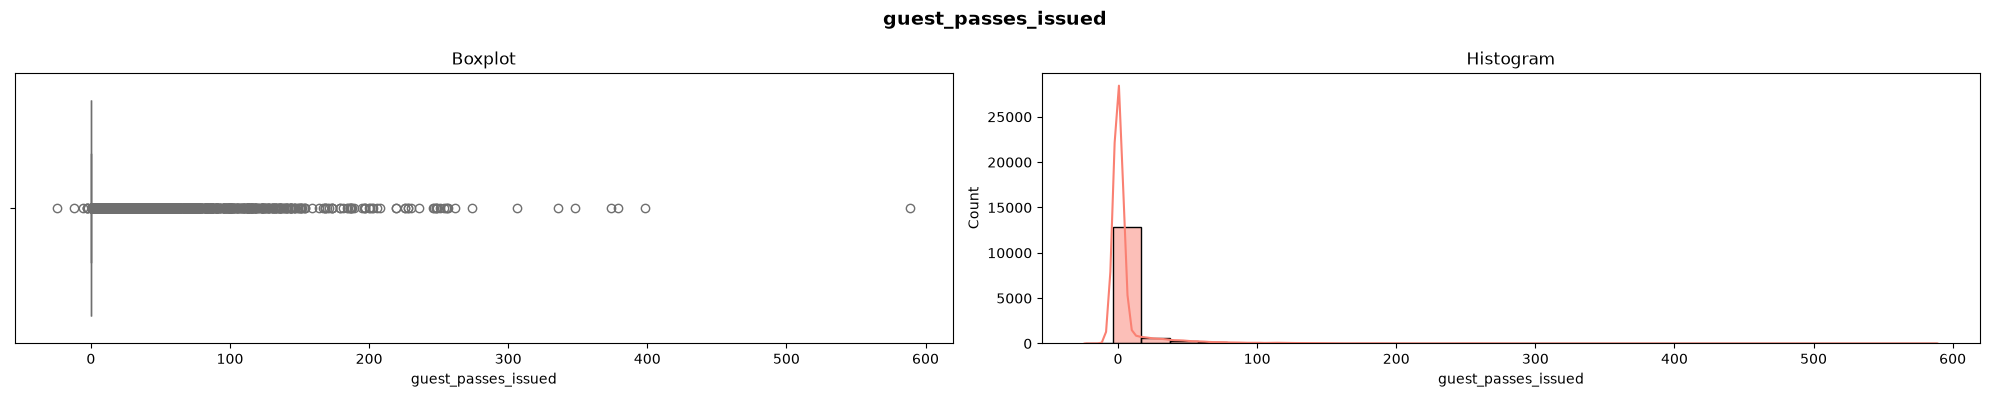

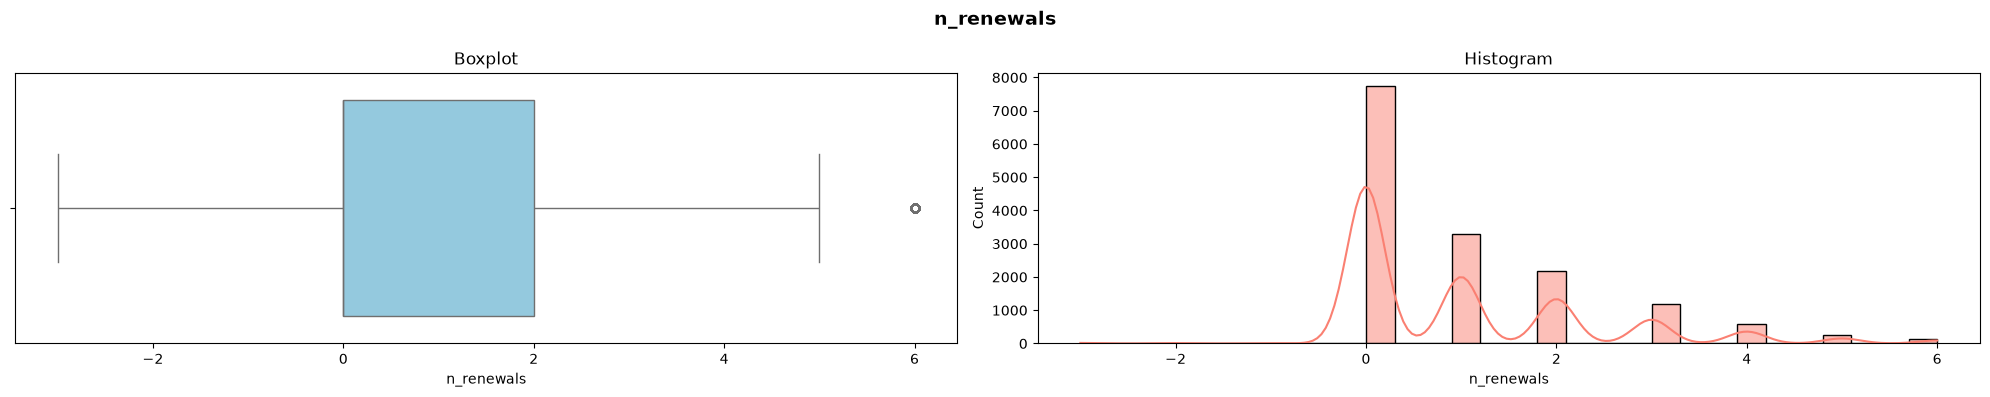

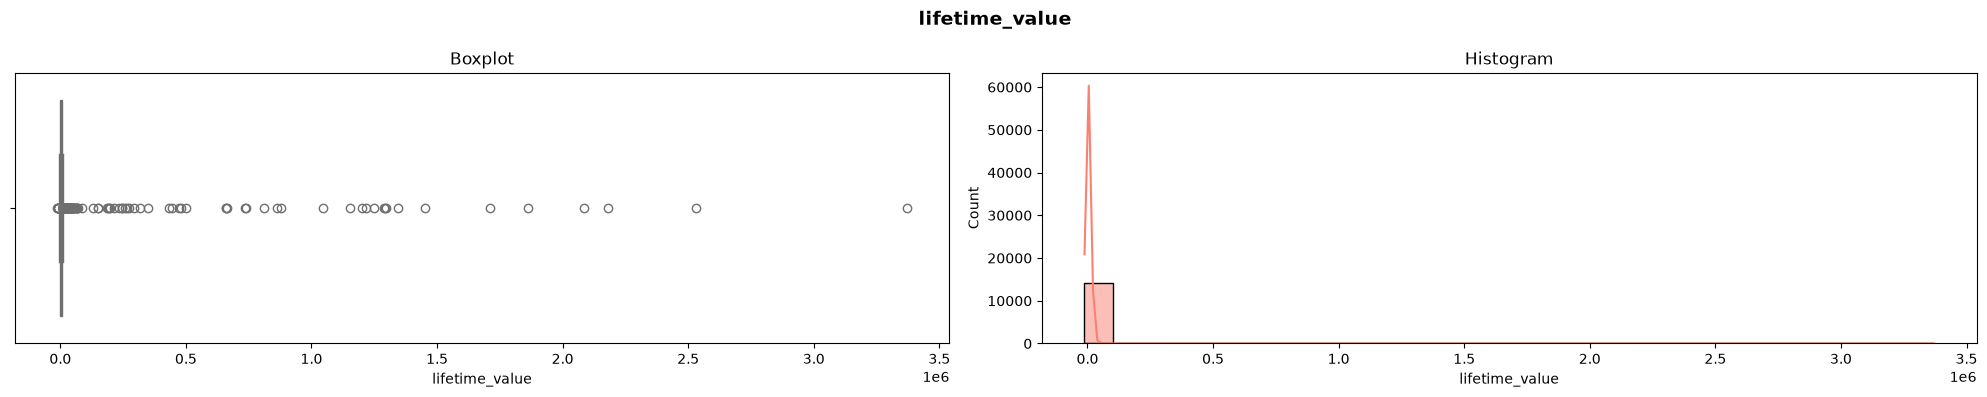

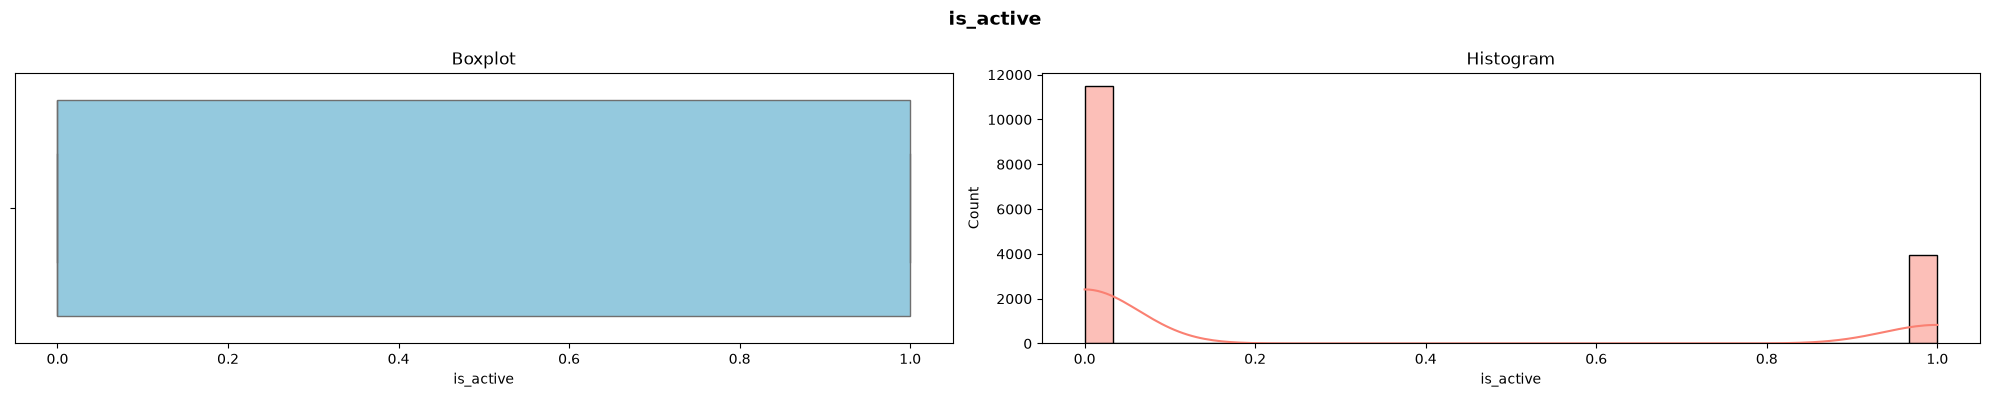

,Feature,Skewness,Kurtosis,Lower Outliers IQR,Upper Outliers IQR,Total Outliers(%) IQR,Lower Outliers MAD,Upper Outliers MAD,Total Outliers(%) MAD,Min,Max,Mean,Median
0,age,3.03,28.89,97,160,257(1.66%),10,62,72(0.47%),1.00,149.00,34.86,34.00
1,n_colleagues_on_account,2.12,4.83,0,1325,1325(8.57%),566,4200,4766(30.82%),-1.00,9.00,0.54,0.00
2,plan_days_per_week,0.93,0.26,0,0,0(0.00%),0,54,54(0.35%),0.00,9.00,3.39,3.00
3,days_since_last_visit,2.72,5.99,31,2472,2503(16.18%),41,3125,3166(20.47%),-956.00,1212.00,117.11,13.00
4,total_visits,6.81,159.60,0,1733,1733(11.21%),0,2547,2547(16.47%),-112.00,6530.00,110.41,34.00
5,avg_weekly_visits,10.27,190.12,0,312,312(2.02%),0,106,106(0.69%),0.00,47.40,1.78,1.42
6,entitled_visits_last_period,0.73,-0.00,0,0,0(0.00%),0,28,28(0.18%),0.00,78.27,27.52,26.09
7,actual_visits_last_period,1.06,0.58,0,380,380(2.46%),0,110,110(0.71%),0.00,60.00,13.80,10.00
8,meeting_room_hours,70.83,6261.59,6,2940,2946(19.05%),16,4901,4917(31.79%),-56.60,41220.00,33.08,0.00
9,event_space_hours,9.22,118.62,8,1762,1770(11.45%),8,1762,1770(11.45%),-13.50,602.80,5.12,0.00


In [376]:
df_outlier_report = plot_nums(df_raw)
df_outlier_report

- Age has problems, we have some entries on ages beetween 120-140, this ages are most likely entry error because we are on the B2B side, so we should only realisticaly consider valid the age range 16-100.
- n_colleagues_on_account has negative entries but this doesn't make sense so we should nulify them. Most people have 0 colleagues on account, while a small minority don't.
- plan_days_per_week also has a range problem, because the only acceptable range of values is 0-7 and we have values that are are fail on both bounds.
- days_since_last_visit we also have negative values that should be capped here, interestingly here we see 2 groups we have clients that have churned in the last year and clients that have churned closer to 3 years ago.We should inspect this second group closer.
- total visits has negative visits that should be capped.This distribution is right skewed so log1p transformation might be needed here.
- avg_weekly_visits also has an interesting distribution, we see most of the values close or on zero and then a cohort of client that visit frequently.We should use log1p transformation.
- entitled_visits_last_period has no problems and it's close to normal distribution.
- actual_visits_last_period has no problems.
- meeting_room_hours,event_space_hours,guest_passes_issued all have negative values that should be capped and should all be log1p transformed, while also being zero dominated.
- n_renewals has negative values that should be capped and again we see zero density.
- lifetime has negative values that should be capped and it has a hight ammount of right skew so we should consider using log1p.


##### 1.3.1.6.2 Numerical Logical Constraints

Some numerical variables are dependant on others, so we should check if they are logicaly coherent.Here are some checks that we will do :

total_visits > actual_visits_last_period, we can't have more visits on 1 period that in our entire history.

In [377]:
df_raw[df_raw["total_visits"]<df_raw["actual_visits_last_period"]]

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value,is_active
3,CW000004,38,female,legal,portugal,False,0,flex,3,2022-01-02,2022-02-15,2022-01-02,44,8,1.23,18.74,9,0.00,0.00,0,False,False,False,False,False,False,False,False,False,0,258.63,0
16,CW000017,23,other,finance,portugal,False,0,hot_desk,2,2022-06-03,2022-07-04,2022-06-07,27,1,0.33,8.78,2,0.00,1.40,0,False,True,False,False,False,False,False,False,False,0,184.21,0
34,CW000033,41,other,consulting,portugal,False,0,hot_desk,2,2022-12-23,2023-02-18,2022-12-23,57,7,0.87,16.40,9,0.20,0.00,0,True,False,False,False,False,False,True,False,False,0,285.35,0
40,CW000039,43,female,design & creative,portugal,True,4,flex,3,2022-07-31,2022-09-28,2022-08-08,51,12,1.38,25.45,13,0.00,0.00,1,False,False,True,False,False,False,False,False,False,0,366.22,0
45,CW000044,19,male,information technology,portugal,True,1,hot_desk,2,2023-04-15,2023-06-07,2023-04-19,999,7,0.95,15.24,8,0.00,0.00,0,False,False,False,False,False,False,False,False,False,0,0.00,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15443,CW015300,32,female,consulting,NaN,False,0,hot_desk,2,2022-10-08,2022-12-05,2023-01-21,59,8,1.00,16.82,10,0.80,0.00,1,True,False,True,False,False,False,False,False,False,0,256.76,0
15444,CW014995,42,female,design & creative,portugal,False,0,hot_desk,2,2022-12-29,2023-02-06,2023-01-27,10,6,1.08,11.32,7,3.00,0.00,0,True,False,False,False,False,False,True,False,False,0,231.28,0
15452,CW006678,30,female,consulting,portugal,False,0,full_time,5,2021-07-21,2021-08-26,2021-08-13,13,8,1.56,25.84,9,<NA>,0.00,0,False,False,False,False,False,False,False,False,False,0,332.76,0
15454,CW001390,44,male,NaN,portugal,False,0,hot_desk,2,2022-10-28,2022-12-18,2022-11-17,31,4,0.61,14.63,5,<NA>,0.00,<NA>,False,False,True,False,False,False,False,False,False,0,231.86,0


- ~1200 rows break this constraint. On the next stage we will try to infer total_visits from the other visit features if possible,otherwise we will set to NULL if all else fails.

if total_visits == 0 then (avg_weekly_visits == 0 & actual_visits_last_period == 0)

In [378]:
bad_total = (df_raw.total_visits <= 0) & ((df_raw.avg_weekly_visits > 0) | (df_raw.actual_visits_last_period > 0))
df_raw[bad_total]

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value,is_active
61,CW000060,38,female,design & creative,portugal,False,-1,hot_desk,2,2021-02-27,2022-10-15,2022-10-09,6,-44,1.93,17.39,15,0.00,0.00,0,False,False,False,False,False,False,True,False,False,2,-793.08,0
181,CW000176,36,female,design & creative,spain,False,0,hot_desk,2,2021-02-01,2021-06-05,2021-06-01,4,0,1.88,17.39,17,1.00,0.60,<NA>,True,True,False,True,False,False,False,False,False,1,559.91,0
239,CW000234,43,male,information technology,portugal,False,0,full_time,5,2021-11-25,2024-01-01,2023-07-17,168,0,0.06,43.48,1,0.00,0.00,0,False,False,False,False,True,True,False,False,False,2,0.00,1
255,CW000250,44,male,finance,united kingdom,True,1,hot_desk,2,2022-10-09,2023-08-18,2023-08-11,7,0,1.17,17.39,10,75.50,57.90,<NA>,True,True,True,False,False,False,False,False,False,1,NaN,0
377,CW000369,32,male,health,portugal,False,0,flex,3,2021-09-19,2023-03-29,2023-03-25,4,0,2.85,26.09,26,0.00,0.00,0,False,False,False,False,False,False,True,False,False,0,NaN,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14785,CW014357,29,male,finance,france,False,0,hot_desk,2,2022-01-09,2022-03-26,2022-01-17,68,0,0.92,17.39,7,0.00,0.00,0,False,False,False,True,False,False,False,False,False,0,321.89,0
14883,CW014453,45,female,NaN,united kingdom,False,0,full_time,5,2023-11-02,2024-01-01,2023-12-29,3,0,3.74,42.25,33,0.00,0.00,1,False,False,True,True,True,True,False,True,False,0,671.84,1
14984,CW014550,34,male,consulting,NaN,False,0,full_time,5,2022-01-05,2024-01-01,2023-12-25,7,-61,4.13,43.48,37,0.00,0.00,-3,False,False,True,True,True,False,False,False,False,3,-1079.26,1
15070,CW014633,44,male,NaN,portugal,True,1,private_office,7,2023-11-26,2023-10-24,2023-12-28,-65,0,4.91,35.26,22,2.30,0.00,0,True,False,False,True,True,False,False,False,False,2,807.24,0


In [379]:
len(df_raw[bad_total])

151

- 151 rows break this logical constraint, curiously all this entries have negative total visits which might explain where this negative entries come from.
- We can also see 999 days_since_last_visit which might be a place holder for something else, further inspection is needed.

actual_visits_last_period must be smaller or equal entitled_visits_last_period , this is a soft rule in theory extra visits are possible.

In [380]:
df_raw[df_raw["actual_visits_last_period"]>df_raw["entitled_visits_last_period"]]

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value,is_active
1988,CW001931,30,male,education,other (europe),False,0,hot_desk,0,2023-06-03,2023-08-15,2023-07-20,26,7,0.66,0.00,6,4.30,0.00,0,True,False,False,False,False,False,False,False,False,0,340.64,0
2381,CW002313,35,male,information technology,portugal,False,0,full_time,0,2021-02-22,2022-01-13,2022-01-07,6,48,1.04,0.00,9,0.00,75.40,7,False,True,True,False,False,False,True,False,False,0,6804.38,0
2382,CW002314,44,male,information technology,portugal,True,2,flex,0,2022-05-14,2023-04-06,2023-03-25,12,127,2.72,0.00,26,0.00,0.00,0,False,False,False,False,False,True,False,False,False,1,2040.95,0
4695,CW004557,54,female,NaN,portugal,True,4,flex,0,2023-03-01,2024-01-01,2023-12-26,6,122,2.80,0.00,21,0.00,0.00,0,False,False,False,False,True,False,False,False,False,0,0.00,0
6973,CW006783,23,female,finance,portugal,True,2,private_office,0,2021-05-13,2023-12-05,2023-11-29,6,134,1.00,0.00,9,50.70,0.00,0,True,False,False,False,True,False,False,True,False,3,21847.95,0
7862,CW007640,37,female,information technology,germany,False,0,flex,0,2021-08-25,2023-01-03,2022-12-24,10,186,2.63,0.00,23,22.00,0.00,0,True,False,False,False,True,False,False,False,False,2,3441.97,0
10654,CW010353,39,male,information technology,portugal,False,0,hot_desk,0,2022-01-02,2022-03-10,2022-02-16,999,2,0.25,0.00,2,5.30,0.00,<NA>,True,False,False,False,False,False,True,False,False,0,0.00,0
12684,CW012315,28,female,real estate,portugal,False,0,hot_desk,0,2023-11-11,2024-01-01,2023-12-30,2,9,1.24,0.00,10,2.30,0.00,0,True,False,False,False,False,False,True,False,False,0,276.02,1


- All this entries were entitled to 0 visits but they all visited and had 0 days on plan_days_per_week.
We should consider making this infer this feature based on plan_tier or other features.

If lifetime_values is 0 then we should expect visits to be zero , this is a soft rule aswell becauase in theory free trials programs might exist.

In [381]:
df_clv_0= df_raw[(df_raw.lifetime_value == 0) & (df_raw.total_visits != 0)] 
df_clv_0

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value,is_active
45,CW000044,19,male,information technology,portugal,True,1,hot_desk,2,2023-04-15,2023-06-07,2023-04-19,999,7,0.95,15.24,8,0.00,0.00,0,False,False,False,False,False,False,False,False,False,0,0.00,0
51,CW000050,42,male,marketing & pr,portugal,False,0,dedicated_desk,5,2021-01-05,2023-09-12,2023-09-11,1,535,3.82,43.48,31,0.00,0.00,17,False,False,True,False,False,True,False,True,False,2,0.00,0
59,CW000058,41,male,consulting,united kingdom,False,0,full_time,5,2021-01-01,2024-01-01,2023-12-28,999,719,4.60,43.48,43,78.60,17.30,0,True,True,False,False,True,True,False,True,False,1,0.00,1
64,CW000063,21,NaN,other,portugal,False,0,hot_desk,2,2023-02-20,2023-11-16,2023-11-08,8,69,1.80,17.39,17,0.00,0.00,0,False,False,False,True,False,False,False,False,False,0,0.00,0
68,CW000067,44,female,design & creative,portugal,False,0,hot_desk,2,2021-12-20,2022-08-29,2022-08-22,7,68,1.90,17.39,17,<NA>,0.00,0,False,False,False,False,False,False,False,False,False,0,0.00,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15410,CW014962,31,female,information technology,netherlands,False,0,flex,3,2022-08-26,2023-10-17,2023-09-26,999,138,2.32,26.09,25,27.30,0.00,0,True,False,False,False,False,False,True,True,False,0,0.00,0
15423,CW014975,41,male,consulting,portugal,True,1,flex,3,2021-11-07,2023-02-14,2023-02-11,3,171,2.58,26.09,21,0.00,0.00,4,False,False,True,False,False,False,False,True,False,1,0.00,0
15440,CW014992,36,other,consulting,spain,True,2,hot_desk,2,2023-06-16,2023-08-12,2023-06-28,999,4,0.45,16.43,4,0.00,0.00,0,False,False,False,False,False,False,False,False,False,0,0.00,0
15449,CW015000,49,male,consulting,portugal,True,3,dedicated_desk,9,2022-01-16,2024-01-01,2023-07-13,999,18,0.18,43.48,1,0.00,0.00,0,False,False,False,True,True,False,False,False,False,3,0.00,1


~2k rows have no lifetime values and total_visits > 0 with different plans further inspection is needed.

In [382]:
df_clv_0.describe()

,age,n_colleagues_on_account,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,n_renewals,lifetime_value,is_active
count,1638.00,1734.00,1734.00,1734,1734,1734,1734.00,1734.00,1734.00,1734.00,1734.00,1530.00,1734.00,1523.00,1734.00,1734.00,1734.00
mean,35.12,0.55,3.54,2022-03-09 15:26:46.920415488,2023-03-26 01:41:18.892733696,2023-02-05 18:01:14.740484352,752.75,96.94,1.61,28.93,12.30,24.23,4.68,5.83,1.00,0.00,0.28
min,2.00,-1.00,0.00,2021-01-01 00:00:00,2020-10-26 00:00:00,2020-12-02 00:00:00,0.00,-88.00,0.00,0.00,0.00,-23.60,-5.50,0.00,-3.00,0.00,0.00
25%,29.00,0.00,2.00,2021-06-13 00:00:00,2022-08-15 00:00:00,2022-07-28 00:00:00,255.00,7.00,0.58,17.39,4.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,34.00,0.00,3.00,2022-01-02 12:00:00,2023-07-05 12:00:00,2023-05-07 12:00:00,999.00,24.00,1.05,26.09,8.00,0.00,0.00,0.00,0.00,0.00,0.00
75%,40.00,1.00,5.00,2022-10-18 18:00:00,2024-01-01 00:00:00,2023-09-25 00:00:00,999.00,113.00,2.15,43.48,17.00,2.80,0.00,0.00,2.00,0.00,1.00
max,142.00,7.00,9.00,2023-12-29 00:00:00,2024-01-01 00:00:00,2024-03-18 00:00:00,999.00,954.00,44.50,78.27,60.00,4284.00,430.00,255.00,6.00,0.00,1.00
std,11.46,1.20,1.54,NaN,NaN,NaN,421.69,159.70,2.13,13.93,10.98,148.43,24.18,21.62,1.40,0.00,0.45


- Most of the clients that carry no value, have 0, 1 ,2 or 999 days_since_last_visit which might indicate that they are recent clients.

##### 1.3.1.6.3 Negative numbers

In [383]:
num_cols = df_raw.select_dtypes(include="number").columns

neg = (df_raw[num_cols] < 0)

neg_report = pd.DataFrame({
    "n_negative":  neg.sum(),
    "pct_of_rows": (neg.mean() * 100).round(2),
    "min":         df_raw[num_cols].where(neg).min(),
    "max":         df_raw[num_cols].where(neg).max(),
    "median_of_neg": df_raw[num_cols].where(neg).median(),
    "mean_of_neg": df_raw[num_cols].where(neg).mean(),
}).query("n_negative > 0").sort_values("n_negative", ascending=False)

print(neg_report)

                         n_negative  \
n_colleagues_on_account         566   
lifetime_value                   80   
n_renewals                       66   
days_since_last_visit            56   
total_visits                     42   
meeting_room_hours               16   
event_space_hours                 8   
guest_passes_issued               7   

                         pct_of_rows       min  \
n_colleagues_on_account         3.66     -1.00   
lifetime_value                  0.52 -11948.59   
n_renewals                      0.43     -3.00   
days_since_last_visit           0.36   -956.00   
total_visits                    0.27   -112.00   
meeting_room_hours              0.11    -56.60   
event_space_hours               0.05    -13.50   
guest_passes_issued             0.05    -24.00   

                           max  median_of_neg  \
n_colleagues_on_account  -1.00          -1.00   
lifetime_value          -88.43        -674.61   
n_renewals               -1.00          -2.00   
d

- n_colleagues_on_account is always -1, which indicated that most likely someone wanted to nulify this entries.So we should set to Nan and then try to inpute.
- lifetime_value heavy variation set to NULL try to inpute later, slight negative values are valid due to refunds.
- n_renewals only -1,-2 and -3 nan and inpute.
- days_since_last_visit seems to be relevant to explain datetime features, right now don't change further EDA might change our stance on this feature.
- total_visits set to nan.
- meeting_room_hours,event_space_hours,guest_passes_issued set to 0 if following uses_* is false otherwise inpute.

##### 1.3.1.6.4 Missing codes for Numeric Features.

Sometimes people instead of nulling entries,entries get typed  with values that represent missingness, the most common values for theese entries are -1,-999 or 999.

In [384]:
codes = [999, -999, -1]
num_cols = df_raw.select_dtypes(include="number").columns

counts = pd.DataFrame({k: (df_raw[num_cols] == k).sum() for k in codes})
counts.columns = [f"n_{k}" for k in codes]

pct = (counts / len(df_raw) * 100).round(2)
pct.columns = [f"pct_{k}" for k in codes]

code_report = pd.concat([counts, pct], axis=1)
code_report["pct_any"] = (df_raw[num_cols].isin(codes).mean() * 100).round(2)
code_report = code_report.query("pct_any > 0").sort_values("pct_any", ascending=False)
print(code_report)

                         n_999  n_-999  n_-1  \
days_since_last_visit     1298       0     0   
n_colleagues_on_account      0       0   566   
n_renewals                   0       0    17   
total_visits                 0       0     1   
event_space_hours            0       0     1   

                         pct_999  pct_-999  \
days_since_last_visit       8.39      0.00   
n_colleagues_on_account     0.00      0.00   
n_renewals                  0.00      0.00   
total_visits                0.00      0.00   
event_space_hours           0.00      0.00   

                         pct_-1  pct_any  
days_since_last_visit      0.00     8.39  
n_colleagues_on_account    3.66     3.66  
n_renewals                 0.11     0.11  
total_visits               0.01     0.01  
event_space_hours          0.01     0.01  


- days_since_last_visit and n_colleagues_on_account  have alot of entries that represent missingess, we should set them to null and then inpute them later.

#### 1.3.1.7 Boolean

In [385]:
def plot_boolean_features(df: pd.DataFrame, exclude: list[str] = None):
    """
        Plot percentage distributions for all Boolean feature is
        plotted in its own subplot, arranged in a compact grid layout.
    
        Parameters
        ----------
        df : pd.DataFrame
            Input dataset containing Boolean columns.
    
        exclude : list, optional
            List of Boolean column names to exclude from the analysis.
    
        Returns
        -------
        None
            Displays a grid of bar plots 
    
        Notes
        -----
        - NULL values are shown explicitly as a separate category.
        """
    
    exclude = exclude or []
    #select Boolean columns (handles both standard bool and pandas nullable 'boolean' / 'bool_')
    bool_cols = [
        c
        for c, dtype in df.dtypes.items()
        if (
            pd.api.types.is_bool_dtype(dtype)
            or isinstance(dtype, pd.BooleanDtype)
        )
        and c not in exclude
    ]

    if not bool_cols:
        print("No Boolean columns found.")
        return

    n_cols = 4
    n_rows = math.ceil(len(bool_cols) / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 3))

    #ensure axes is a flat 1D array even if n_rows == 1 or n_cols == 1
    if isinstance(axes, plt.Axes):
        axes = [axes]
    else:
        axes = axes.flatten()

    for ax, col in zip(axes, bool_cols):
        #cast to string and fill missing values with 'NULL'
        series = df[col].astype(str).fillna("NULL")
        #handle cases where pd.NA/np.nan converts to 'nan' string
        series = series.replace({"nan": "NULL", "<NA>": "NULL"})

        counts = (
            series.value_counts(dropna=False, normalize=True)
            .mul(100)
            .reset_index()
        )
        counts.columns = [col, "pct"]
        counts = counts.sort_values("pct", ascending=False)

        sns.barplot(
            data=counts,
            x=col,
            y="pct",
            ax=ax,
            color="#4C8BE2",
            legend=False,
        )

        #highlight NULLs
        for bar, label in zip(ax.patches, counts[col]):
            if label == "NULL":
                bar.set_facecolor("#d9534f")

        ax.set_title(f"{col} (%)", fontsize=10)
        ax.set_xlabel("")
        ax.set_xticks(range(len(counts[col])))
        ax.set_xticklabels(counts[col], rotation=0)
        ax.set_ylabel("Percentage")
        ax.set_xticklabels(counts[col], rotation=0)

    #hide unused subplots
    for j in range(len(bool_cols), len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.show()

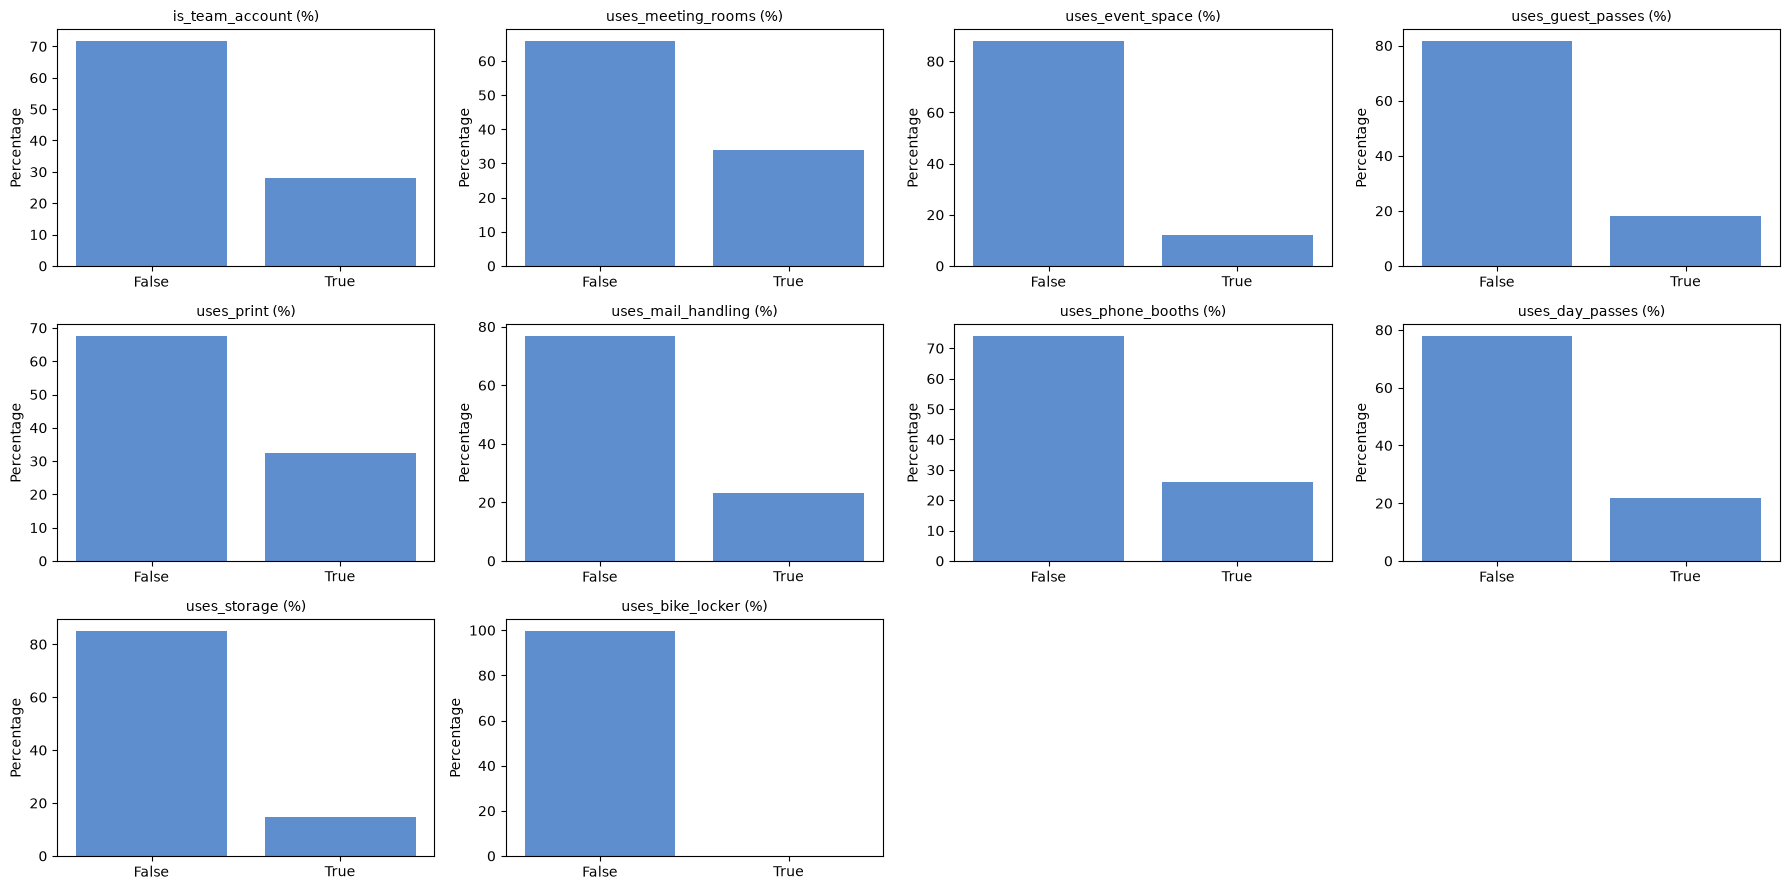

In [386]:
plot_boolean_features(df_raw)

- Most people don't use ameneties, which creates a strong class imbalance across all features.
- We should consider removing the uses_bike_locker this huge class imbalance make this feature useless.
- We consider making a feature, that counts any amenity use.

### 1.3.2 Bivariate analysis

#### 1.3.2.1 Gender vs Features(Except Datetime)

In [387]:
def plot_categorical_and_bool_against_target(df: pd.DataFrame,exclude: list = None,target_col: str = "TARGET",big: bool = False,n: int = 10,):
    """
    Plot the target distribution breakdown across all categories for every
    string and boolean column in a Pandas DataFrame.
    """
    exclude = exclude or []
    n_total = len(df)
    cols = []

    #select valid string/object and boolean columns natively
    valid_cols = df.select_dtypes(include=["object", "string", "category", "bool"]).columns
    
    for c in valid_cols:
        if c != target_col and c not in exclude:
            # Skip all-null columns
            if df[c].isna().sum() < n_total:
                cols.append(c)

    if not cols:
        print("No valid string or boolean columns to plot against the target.")
        return

    # Settle grid size dimensions
    n_cols = 1 if big else 4
    n_rows = math.ceil(len(cols) / n_cols)

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, max(5, n_rows * 5.5)))
    axes = np.array(axes).flatten()

    for i, col in enumerate(cols):
        ax = axes[i]

        is_bool = df[col].dtype == "bool"
        
        #cast copy to string to unify missing values and categorical logic safely
        working_series = df[col].astype(str).replace("nan", "NULL")
        working_series = working_series.fillna("NULL")

        #find the overall top/bottom categories by total volume
        volume_counts = working_series.value_counts().sort_values(ascending=False)
        n_unique = len(volume_counts)
        high_cardinality = n_unique > (n * 2)

        #create a clean temporary DataFrame for calculations
        calc_df = pd.DataFrame({
            col: working_series,
            target_col: df[target_col]
        })

        if high_cardinality:
            top_cats = volume_counts.head(n).index.tolist()
            bot_cats = volume_counts.tail(n).index.tolist()
            valid_cats = top_cats + bot_cats
            calc_df = calc_df[calc_df[col].isin(valid_cats)]
        else:
            top_cats = volume_counts.index.tolist()

        #compute counts per group combination
        grouped = calc_df.groupby([col, target_col]).size().reset_index(name="len")

        #compute percentages WITHIN each category/boolean state (replaces Polars window .over())
        grouped["percentage"] = (grouped["len"] / grouped.groupby(col)["len"].transform("sum")) * 100

        #inject visual separator row if high cardinality
        if high_cardinality:
            target_values = df[target_col].dropna().unique().tolist()
            
            top_df = grouped[grouped[col].isin(top_cats)].sort_values(by=col)
            bot_df = grouped[grouped[col].isin(bot_cats)].sort_values(by=col)

            separator_df = pd.DataFrame({
                col: ["..."] * len(target_values),
                target_col: target_values,
                "len": [0] * len(target_values),
                "percentage": [0.0] * len(target_values),
            })
            pdf = pd.concat([top_df, separator_df, bot_df]).reset_index(drop=True)
        else:
            pdf = grouped.sort_values(by=col).reset_index(drop=True)

        #generate the barplot
        sns.barplot(
            data=pdf,
            x=col,
            y="percentage",
            hue=target_col,
            palette="tab10",
            ax=ax,
        )

        #apply short labels wrapper formatting
        unique_categories = pdf[col].unique()
        wrapped_labels = [
            textwrap.shorten(str(lbl), width=20, placeholder="…")
            for lbl in unique_categories
        ]
        ax.set_xticks(range(len(unique_categories)))
        ax.set_xticklabels(wrapped_labels, rotation=90, ha="center", fontsize=7)

        #color customizations for NULLs and separation gaps
        unique_labels_list = list(unique_categories)
        for bar_group in ax.containers:
            for bar, label in zip(bar_group, unique_labels_list):
                if label == "NULL":
                    bar.set_edgecolor("#d9534f") 
                    bar.set_linewidth(1.5)
                elif label == "...":
                    bar.set_facecolor("none")
                    bar.set_edgecolor("none")

        #handle vertical separator line for high-cardinality features
        if high_cardinality:
            sep_x = n - 0.5
            ax.axvline(
                x=sep_x,
                color="#555555",
                linewidth=1.2,
                linestyle="--",
                alpha=0.6,
            )
            ax.text(
                sep_x,
                ax.get_ylim()[1] * 0.95,
                "Top/Bot Volume Split",
                ha="center",
                va="top",
                fontsize=6,
                color="#555555",
                weight="bold",
            )

        #clean up chart borders and grid lines
        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(axis="y", linestyle="--", alpha=0.3)

        #format title based on column characteristics
        if is_bool:
            title = f"{col} vs {target_col}\n(Boolean Feature)"
        elif high_cardinality:
            title = f"{col} vs {target_col}\n(top & bot {n} of {n_unique} by volume)"
        else:
            title = f"{col} vs {target_col}\n({n_unique} categories)"

        ax.set_title(title, fontsize=9, fontweight="bold")
        ax.set_xlabel("")
        ax.set_ylabel("% within Category", fontsize=8)
        ax.tick_params(axis="both", labelsize=7)
        ax.legend(title=target_col, loc="upper right", fontsize=7, title_fontsize=7)

    #hide extra layout lines
    for j in range(len(cols), len(axes)):
        axes[j].set_visible(False)

    plt.tight_layout()
    plt.subplots_adjust(hspace=0.9, wspace=0.25)
    plt.show()

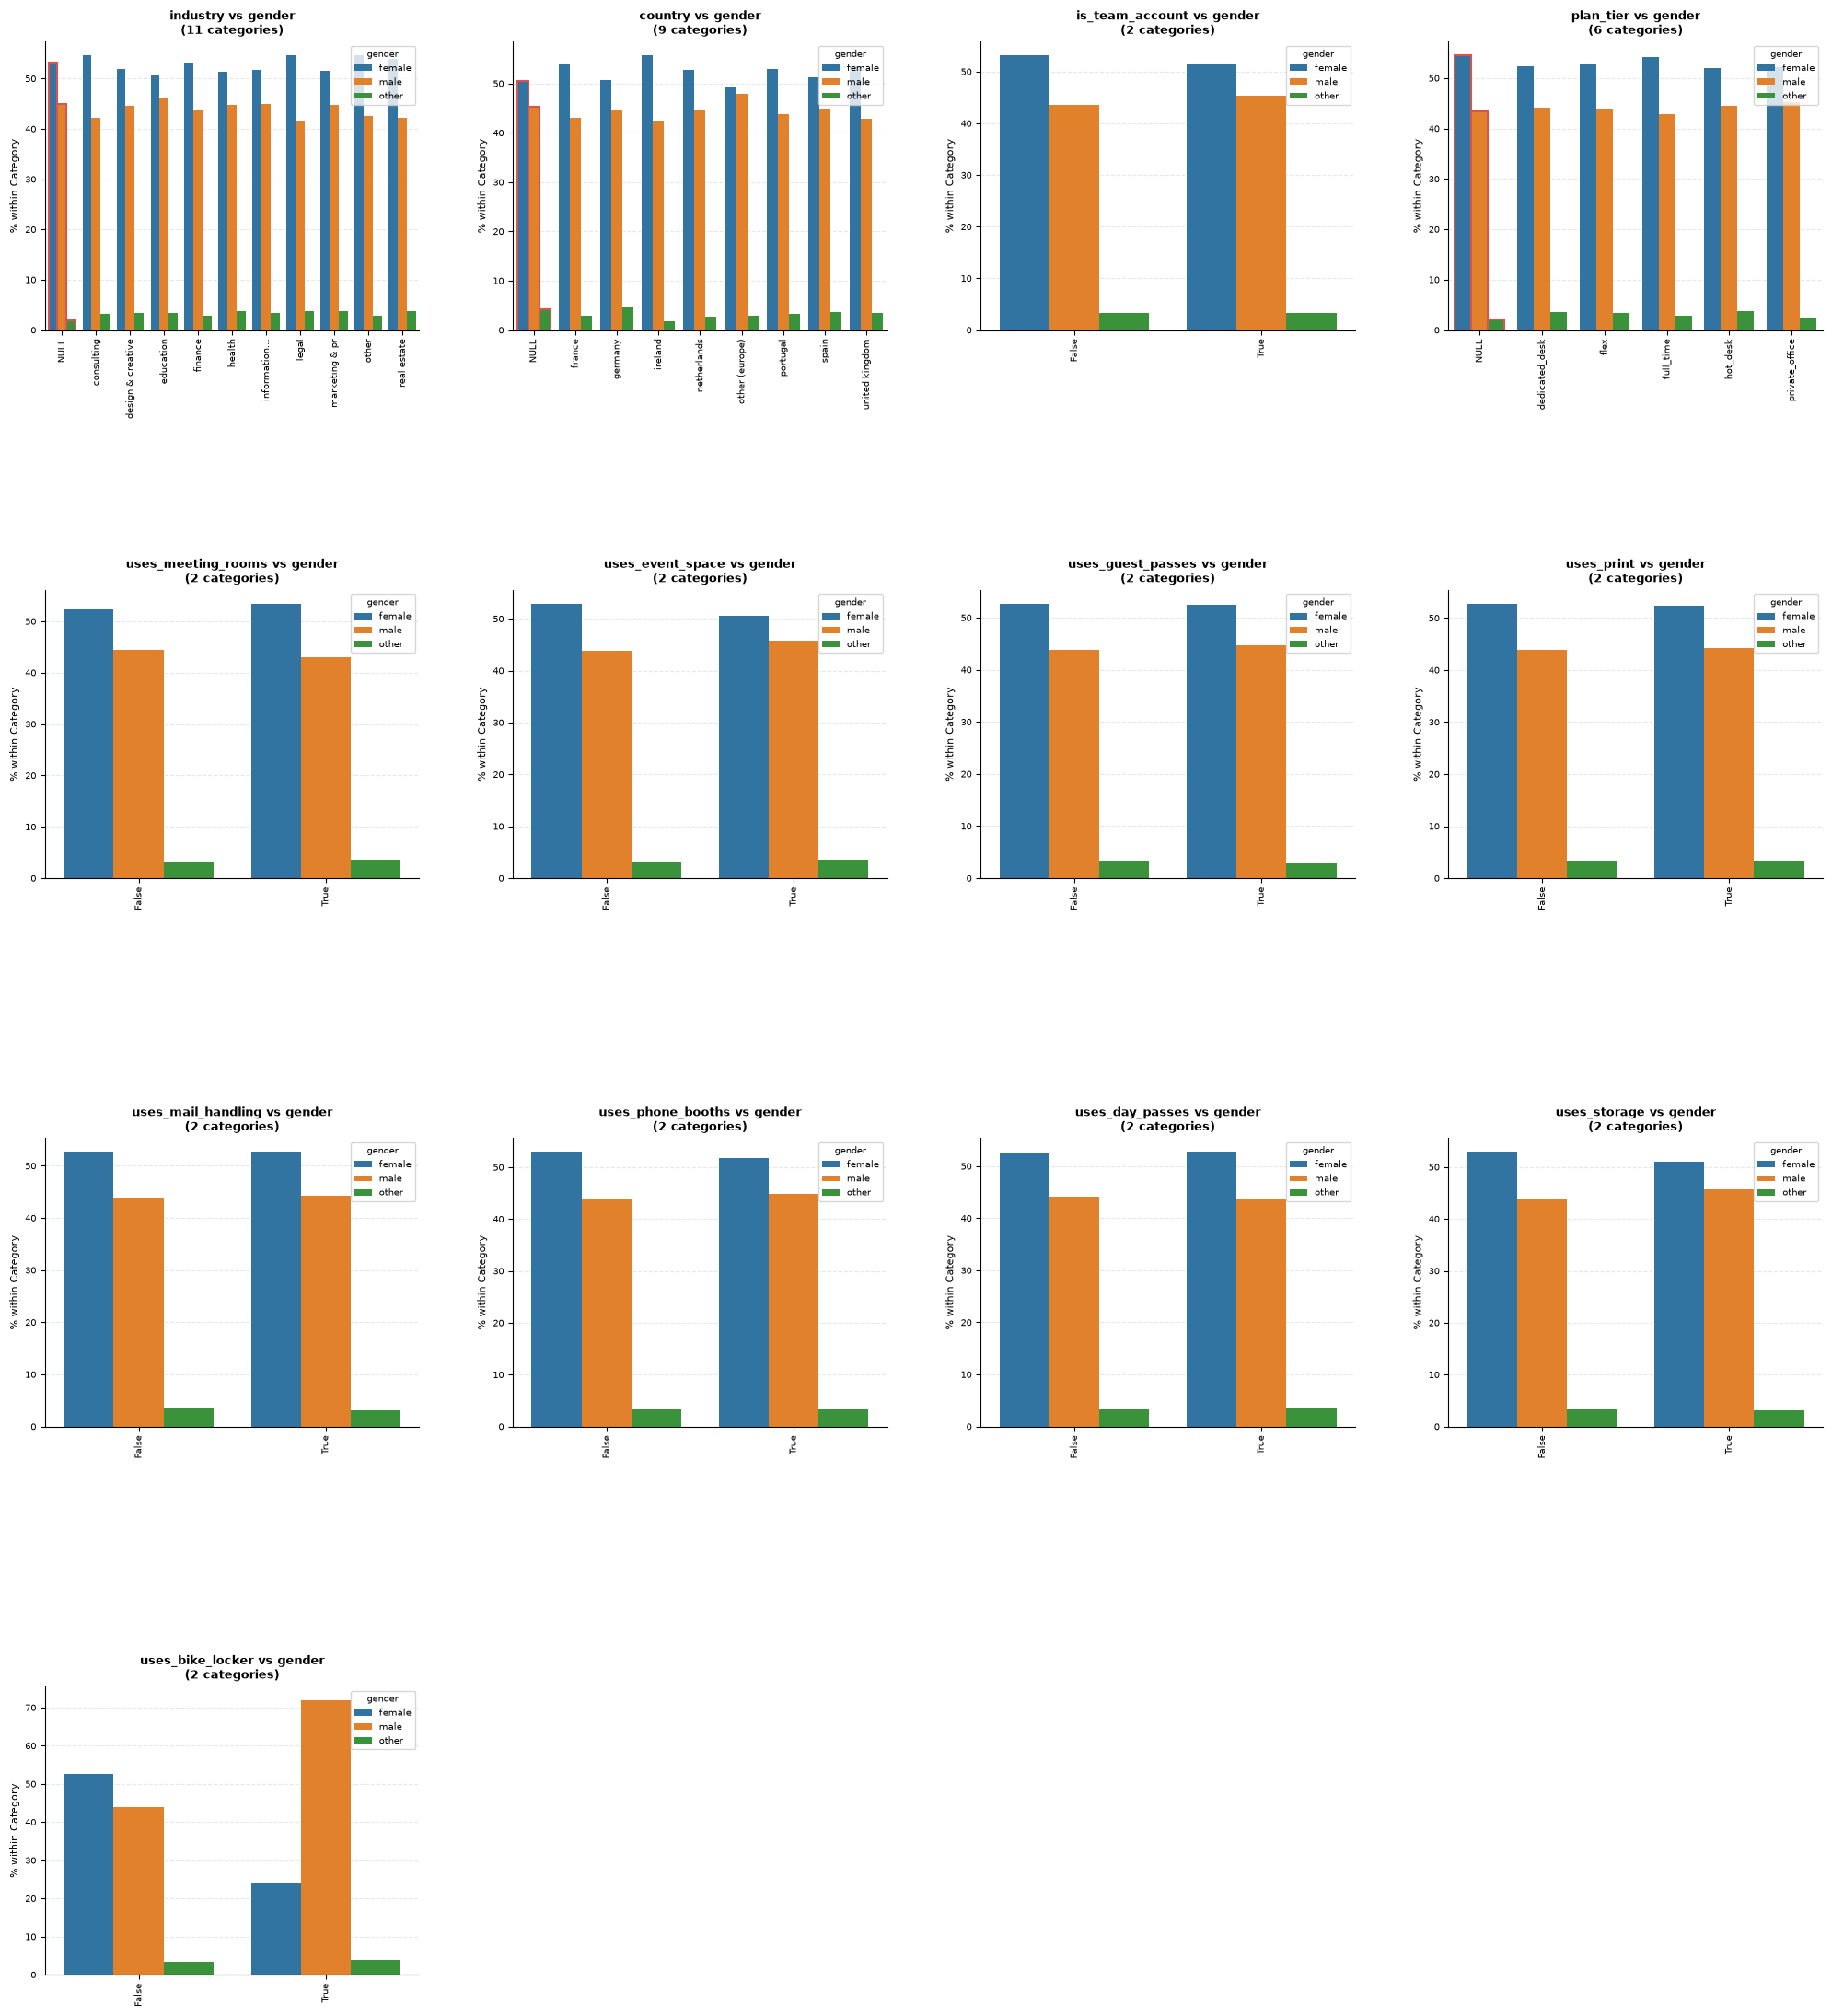

In [388]:
plot_categorical_and_bool_against_target(df=df_raw, exclude=["member_id"], target_col="gender")

- Most industry have around the same split gender split, 50%-55% female, 40%-45% male and other close to 5%.
- Most countries have a same gender split.
- Plan tiers and member_accounts have a same gender splits for all categories.
- All uses_* have a same gender split with the exeption the bike_locker which is dominanated by male users , this might be a good proxy for gender if we need to infer gender for null cases. It also goes against our first assumption of discarding uses_bike_locker feature.

In [389]:
def categorical_numerical(X: pd.DataFrame, target: str, exclude: list = None, filter_zeros: bool = False, log_scale_skewed: bool = True, skew_threshold: float = 2.0):
    """
    Plot numerical features against a categorical target using Seaborn boxenplots.

    Parameters
    ----------
    X : pd.DataFrame
        The full input dataset.
    target : str
        The categorical target column name.
    exclude : list, optional
        List of column names to exclude.
    filter_zeros : bool, default False
        If True, filters out values <= 0 for zero-inflated continuous features.
    log_scale_skewed : bool, default True
        If True, applies a log scale to features with high right-skewness.
    skew_threshold : float, default 2.0
        Threshold above which a feature is considered highly skewed.

    Returns
    ----------
        None
            Only plots boxplots.
    """
    exclude = exclude or []

    #identify numeric columns excluding target and explicit exclusions
    num_cols = [c for c in X.select_dtypes(include="number").columns if c != target and c not in exclude]
    #if nothing to plot
    if not num_cols:
        print("No valid numeric columns found to plot.")
        return

    n_cols = 3
    n_rows = math.ceil(len(num_cols) / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(22, max(6 * n_rows, 6)),
        layout="constrained",
    )

    axes = np.asarray(axes).flatten()

    for i, col in enumerate(num_cols):
        ax = axes[i]
        plot_df = X[[target, col]].dropna()

        if filter_zeros:
            plot_df = plot_df[plot_df[col] > 0]

        if plot_df.empty:
            ax.text(
                0.5,
                0.5,
                f"{col}\n(No valid data)",
                ha="center",
                va="center",
                transform=ax.transAxes,
            )
            continue

        #check skewness to see if log scaling is needed
        skewness = plot_df[col].skew() if len(plot_df) > 1 else 0
        use_log = log_scale_skewed and (skewness > skew_threshold) and (plot_df[col].min() >= 0)

        sns.boxenplot(
            data=plot_df,
            x=target,
            y=col,
            hue=target,
            palette="Set2",
            legend=False,
            ax=ax,
        )

        if use_log:
            ax.set_yscale("symlog" if (plot_df[col] == 0).any() else "log")
            ax.set_ylabel(f"{col} (log scale)")
        else:
            ax.set_ylabel(col)

        ax.set_title(f"Distribution of {col} by {target}", fontsize=11, fontweight="bold")
        ax.set_xlabel(target)
        ax.tick_params(axis="x", labelsize=9, labelrotation=90)

    #hide unused grid axes
    for j in range(len(num_cols), len(axes)):
        fig.delaxes(axes[j])

    plt.show()

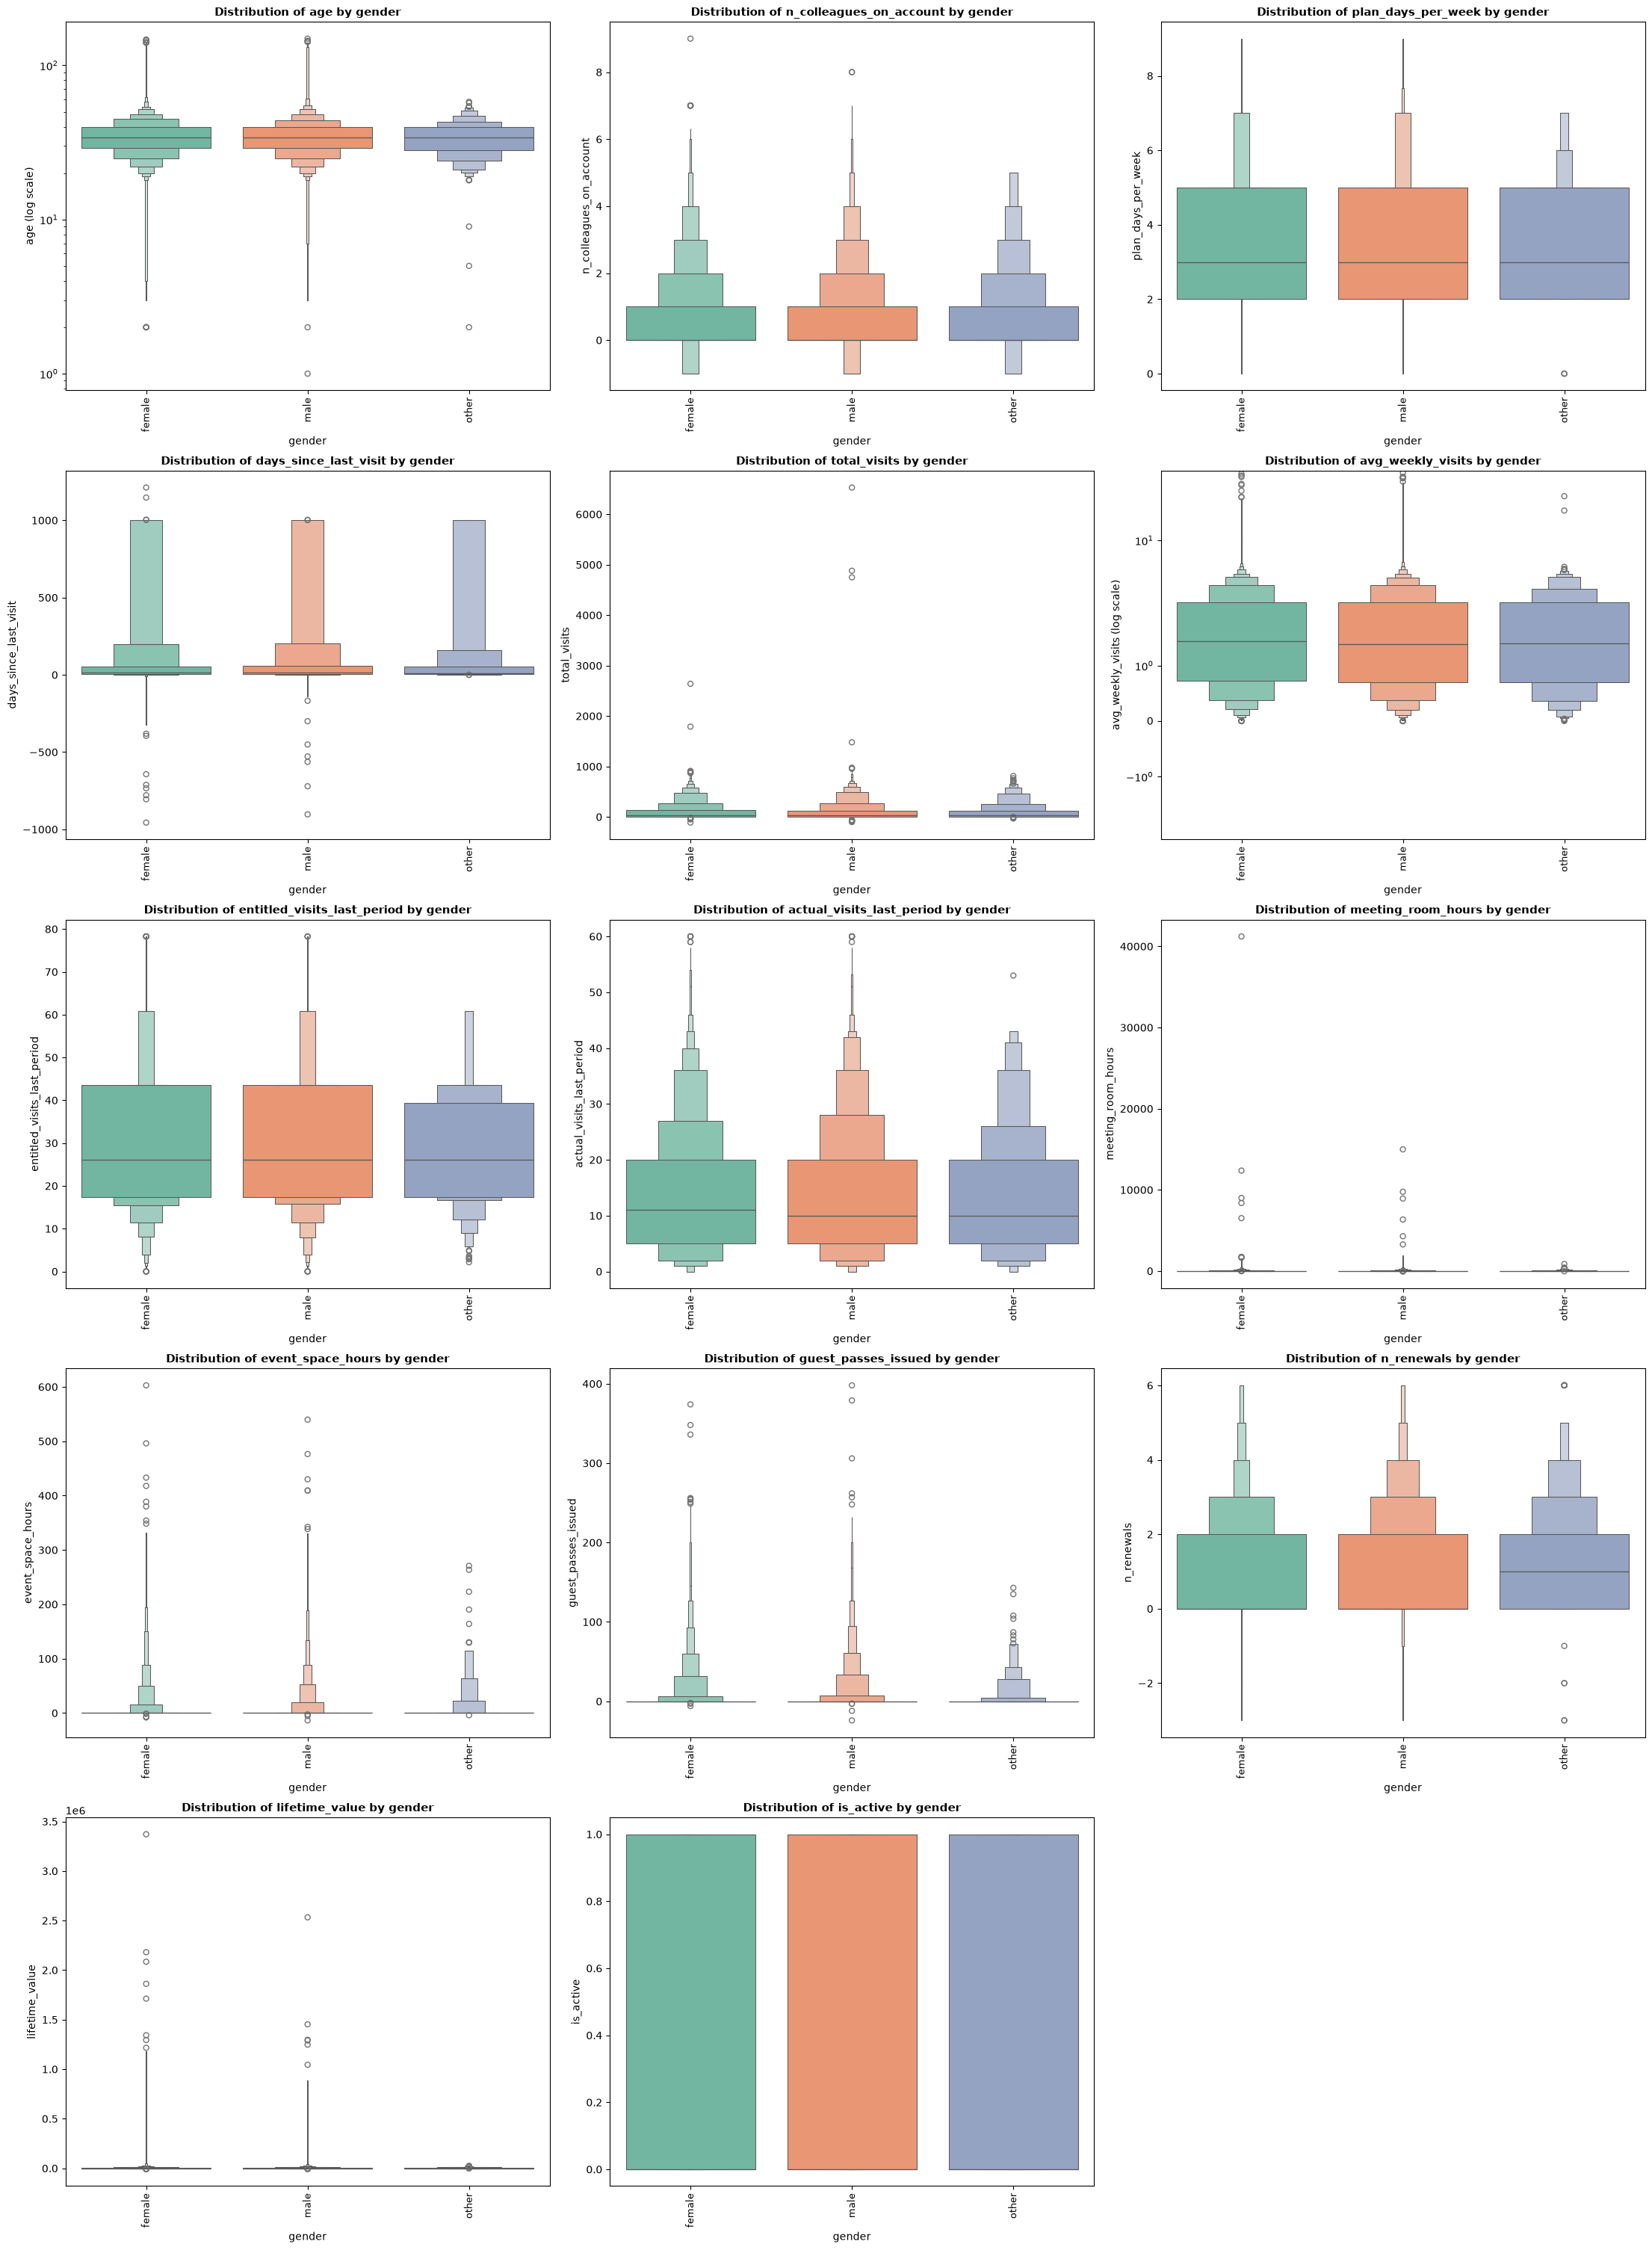

In [390]:
categorical_numerical(df_raw,exclude=["member_id"],target="gender")

- On all features male and female have close distribution with the expetion of other gender, which doesn't have extreme values in most of the features.

#### 1.3.2.2 Industry vs Features(Except Datetime)

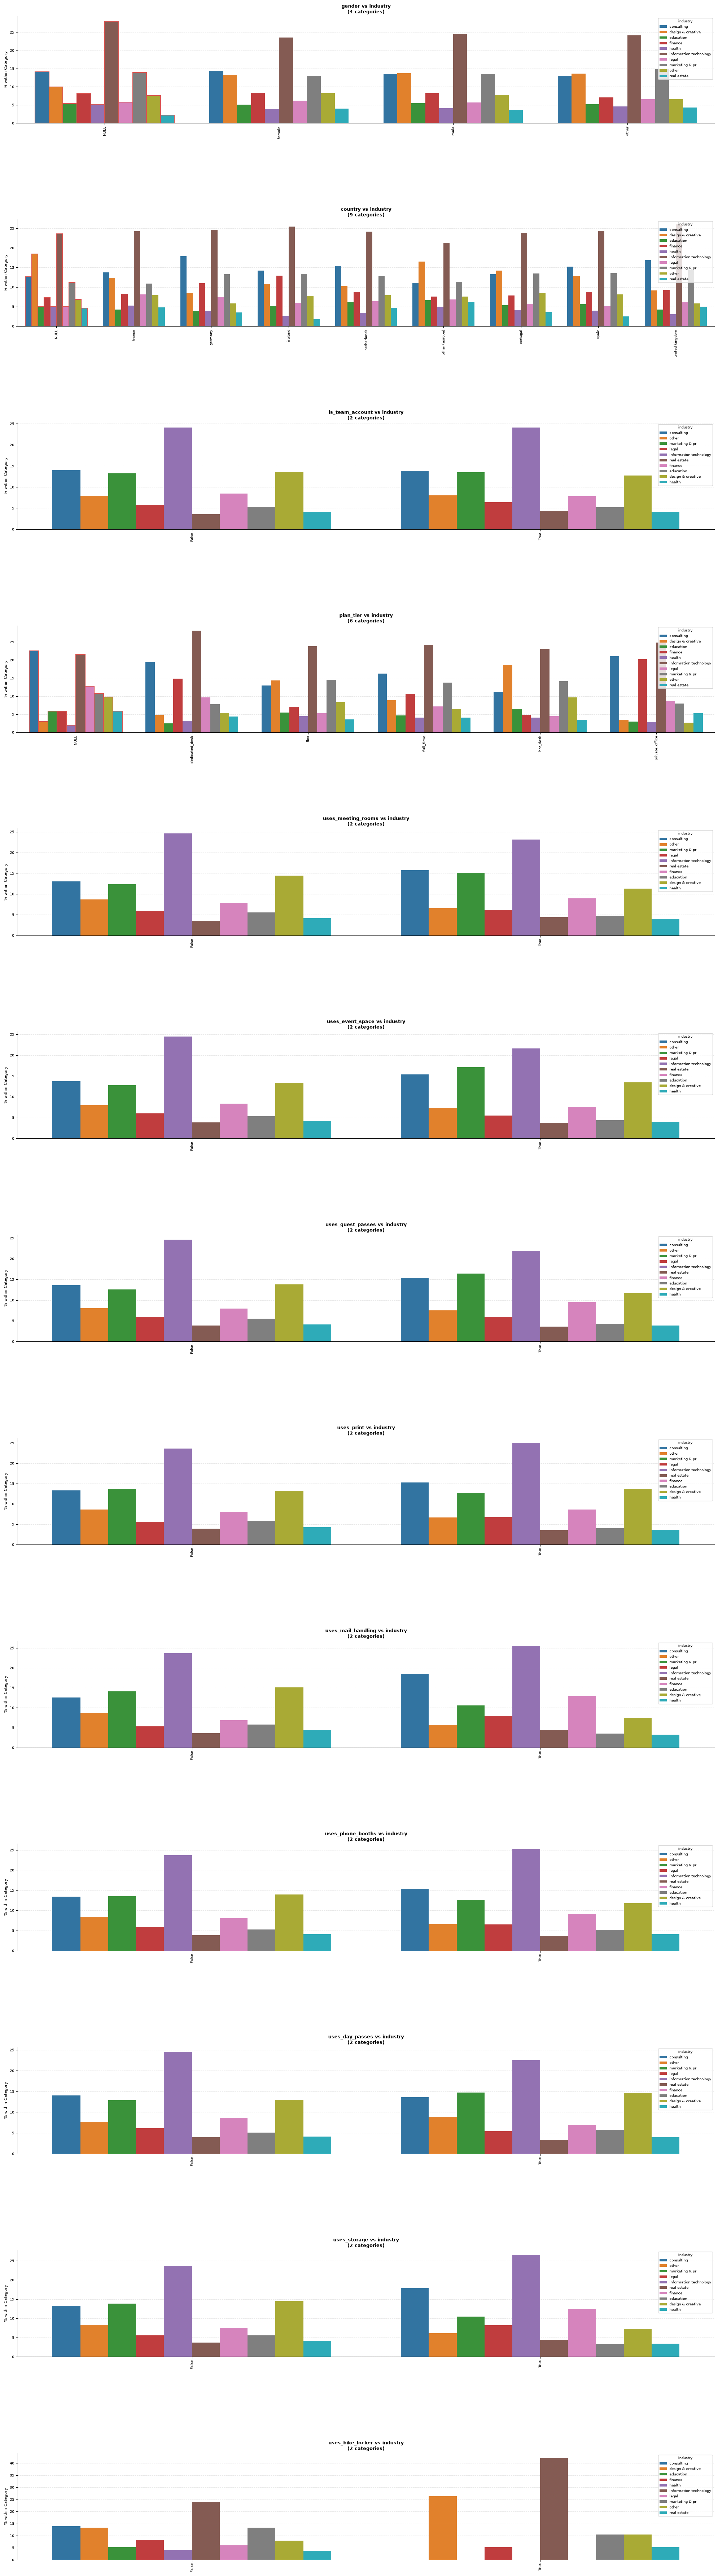

In [391]:
plot_categorical_and_bool_against_target(df=df_raw, exclude=["member_id"], target_col="industry",big = True)

- all uses_* have the same distribution for all features with exception again for uses_bike_locker , some industries only show up on True and others are extremly prenounced like IT.
- We can see that different industries use different plan_tiers,  for example ie IT tends to be slightly more concentrated on the lower plans.
- teams accounts and countries have no meaningful differences beetween industries.

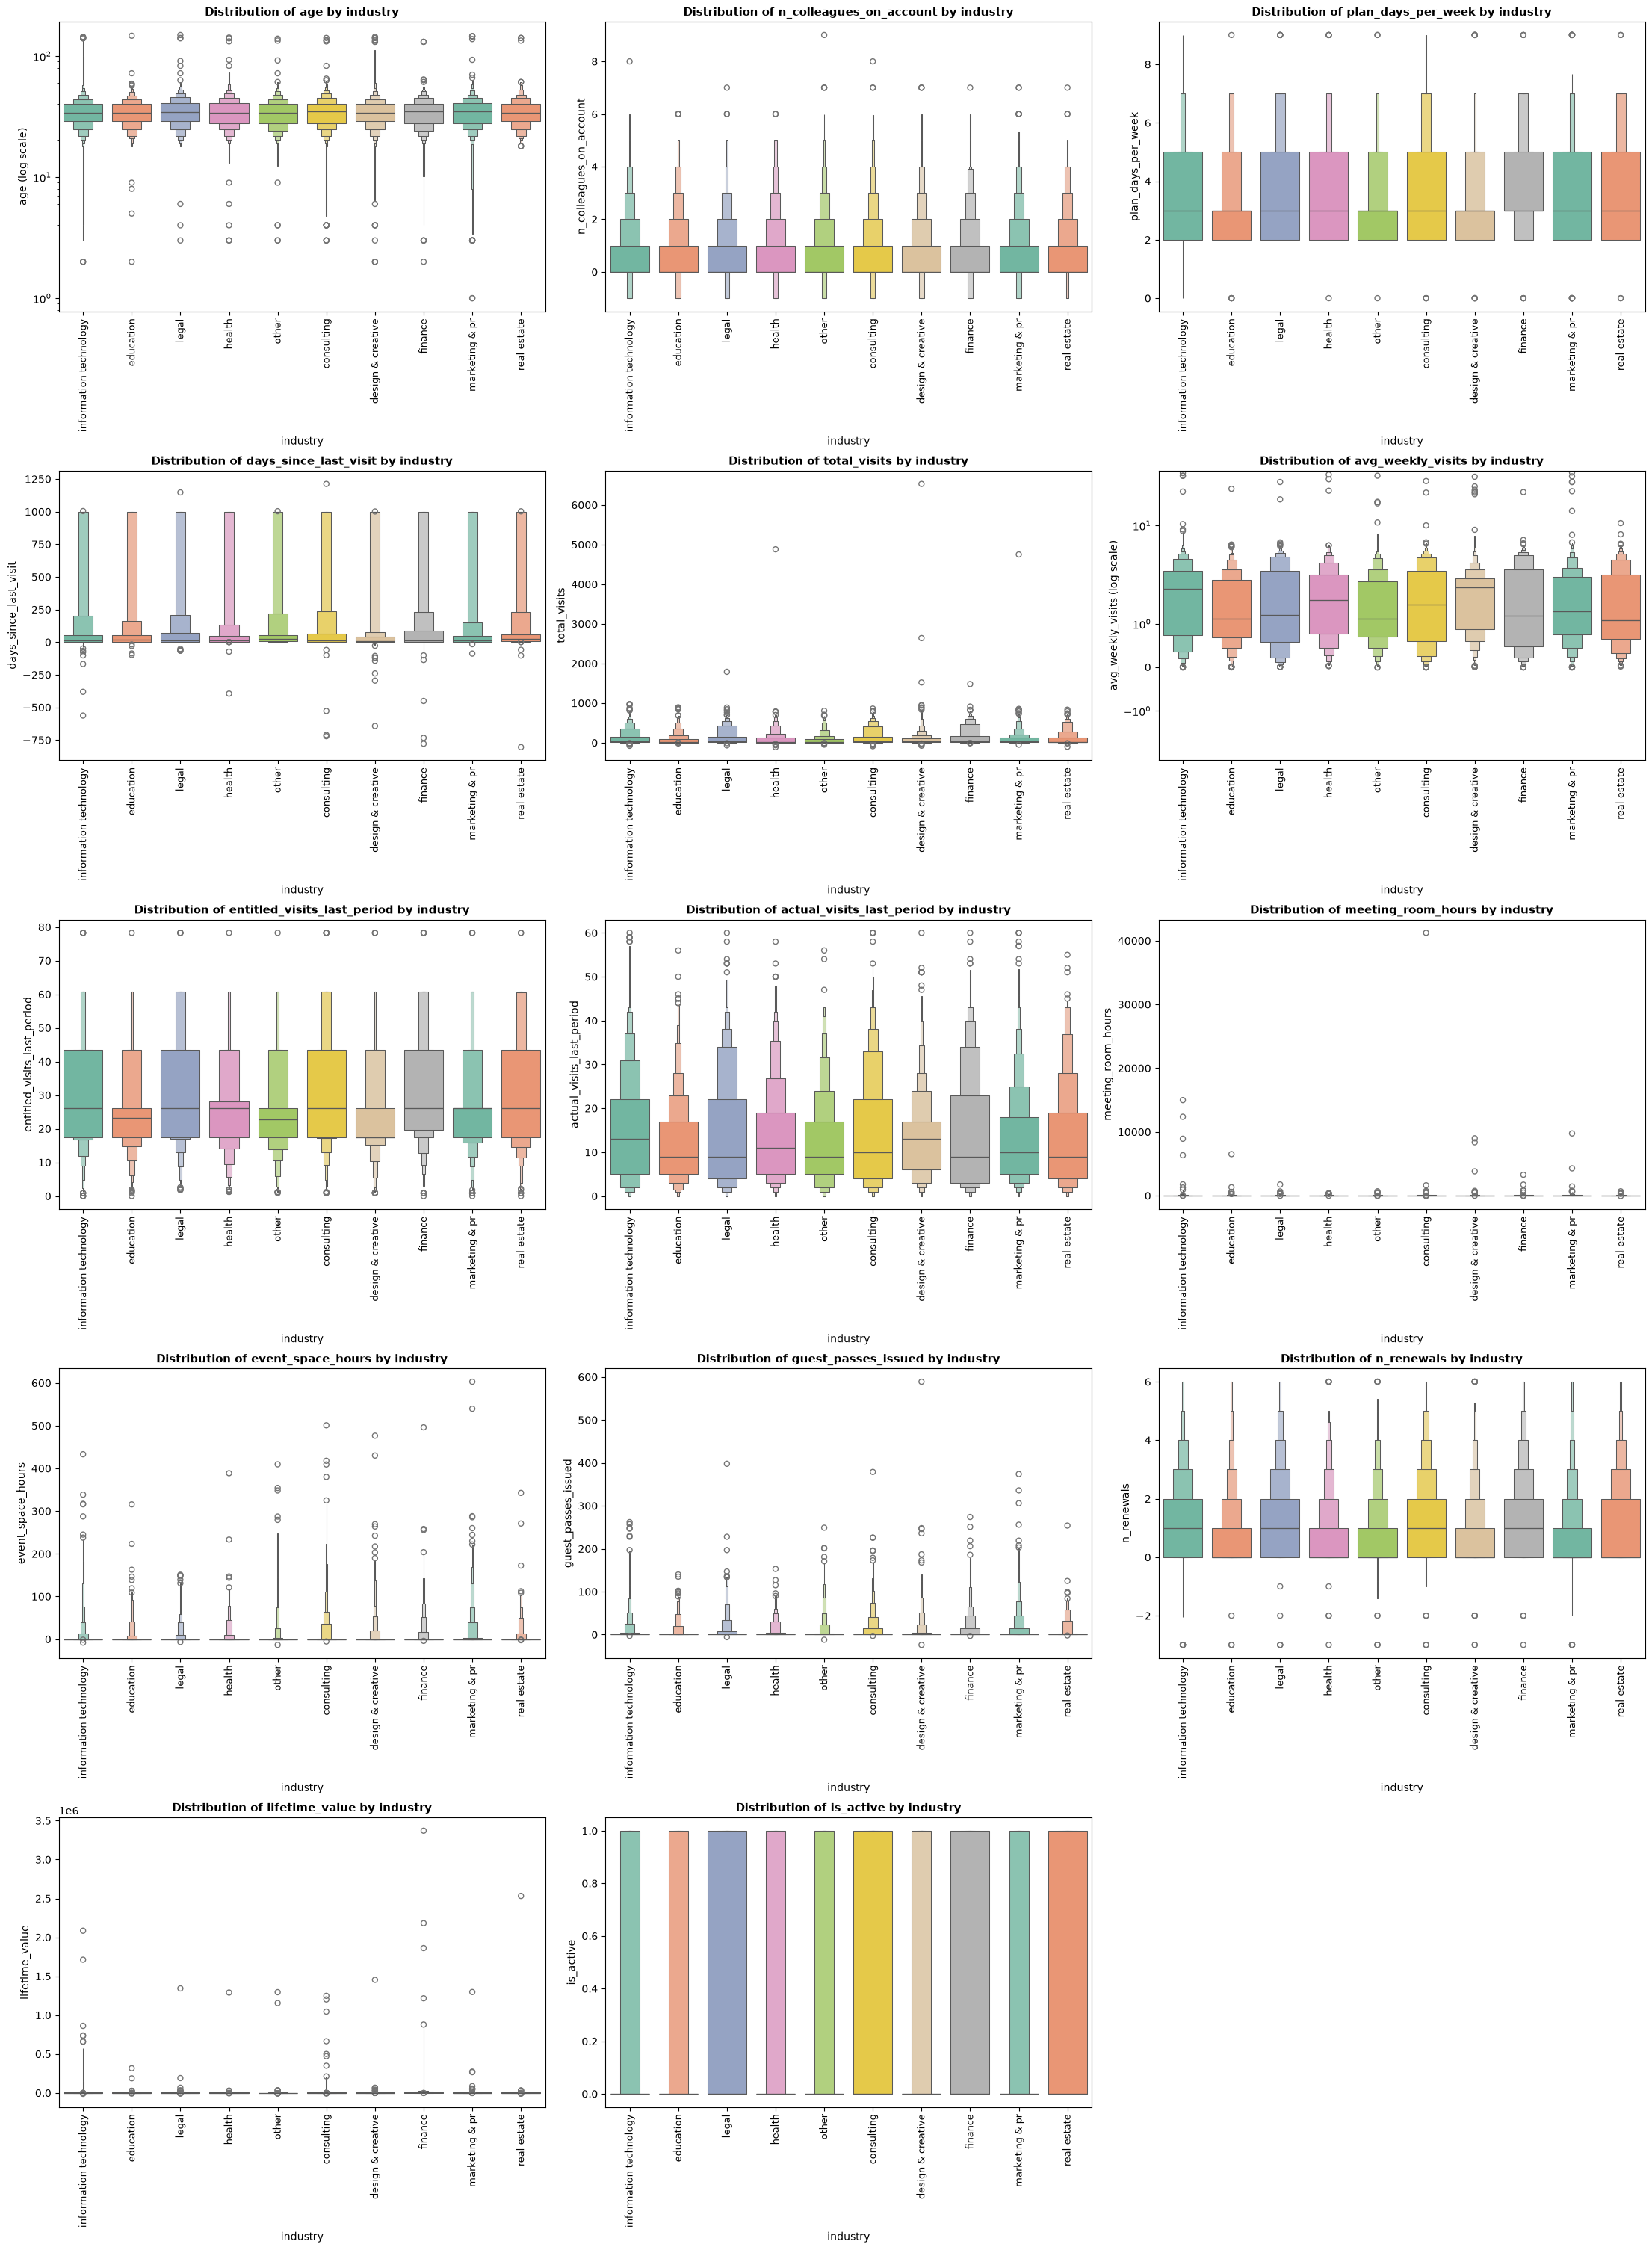

In [392]:
categorical_numerical(df_raw,exclude=["member_id"],target="industry")

- No meaningfull pattern.

#### 1.3.2.3 Plan_tier vs Features(Except Datetime)

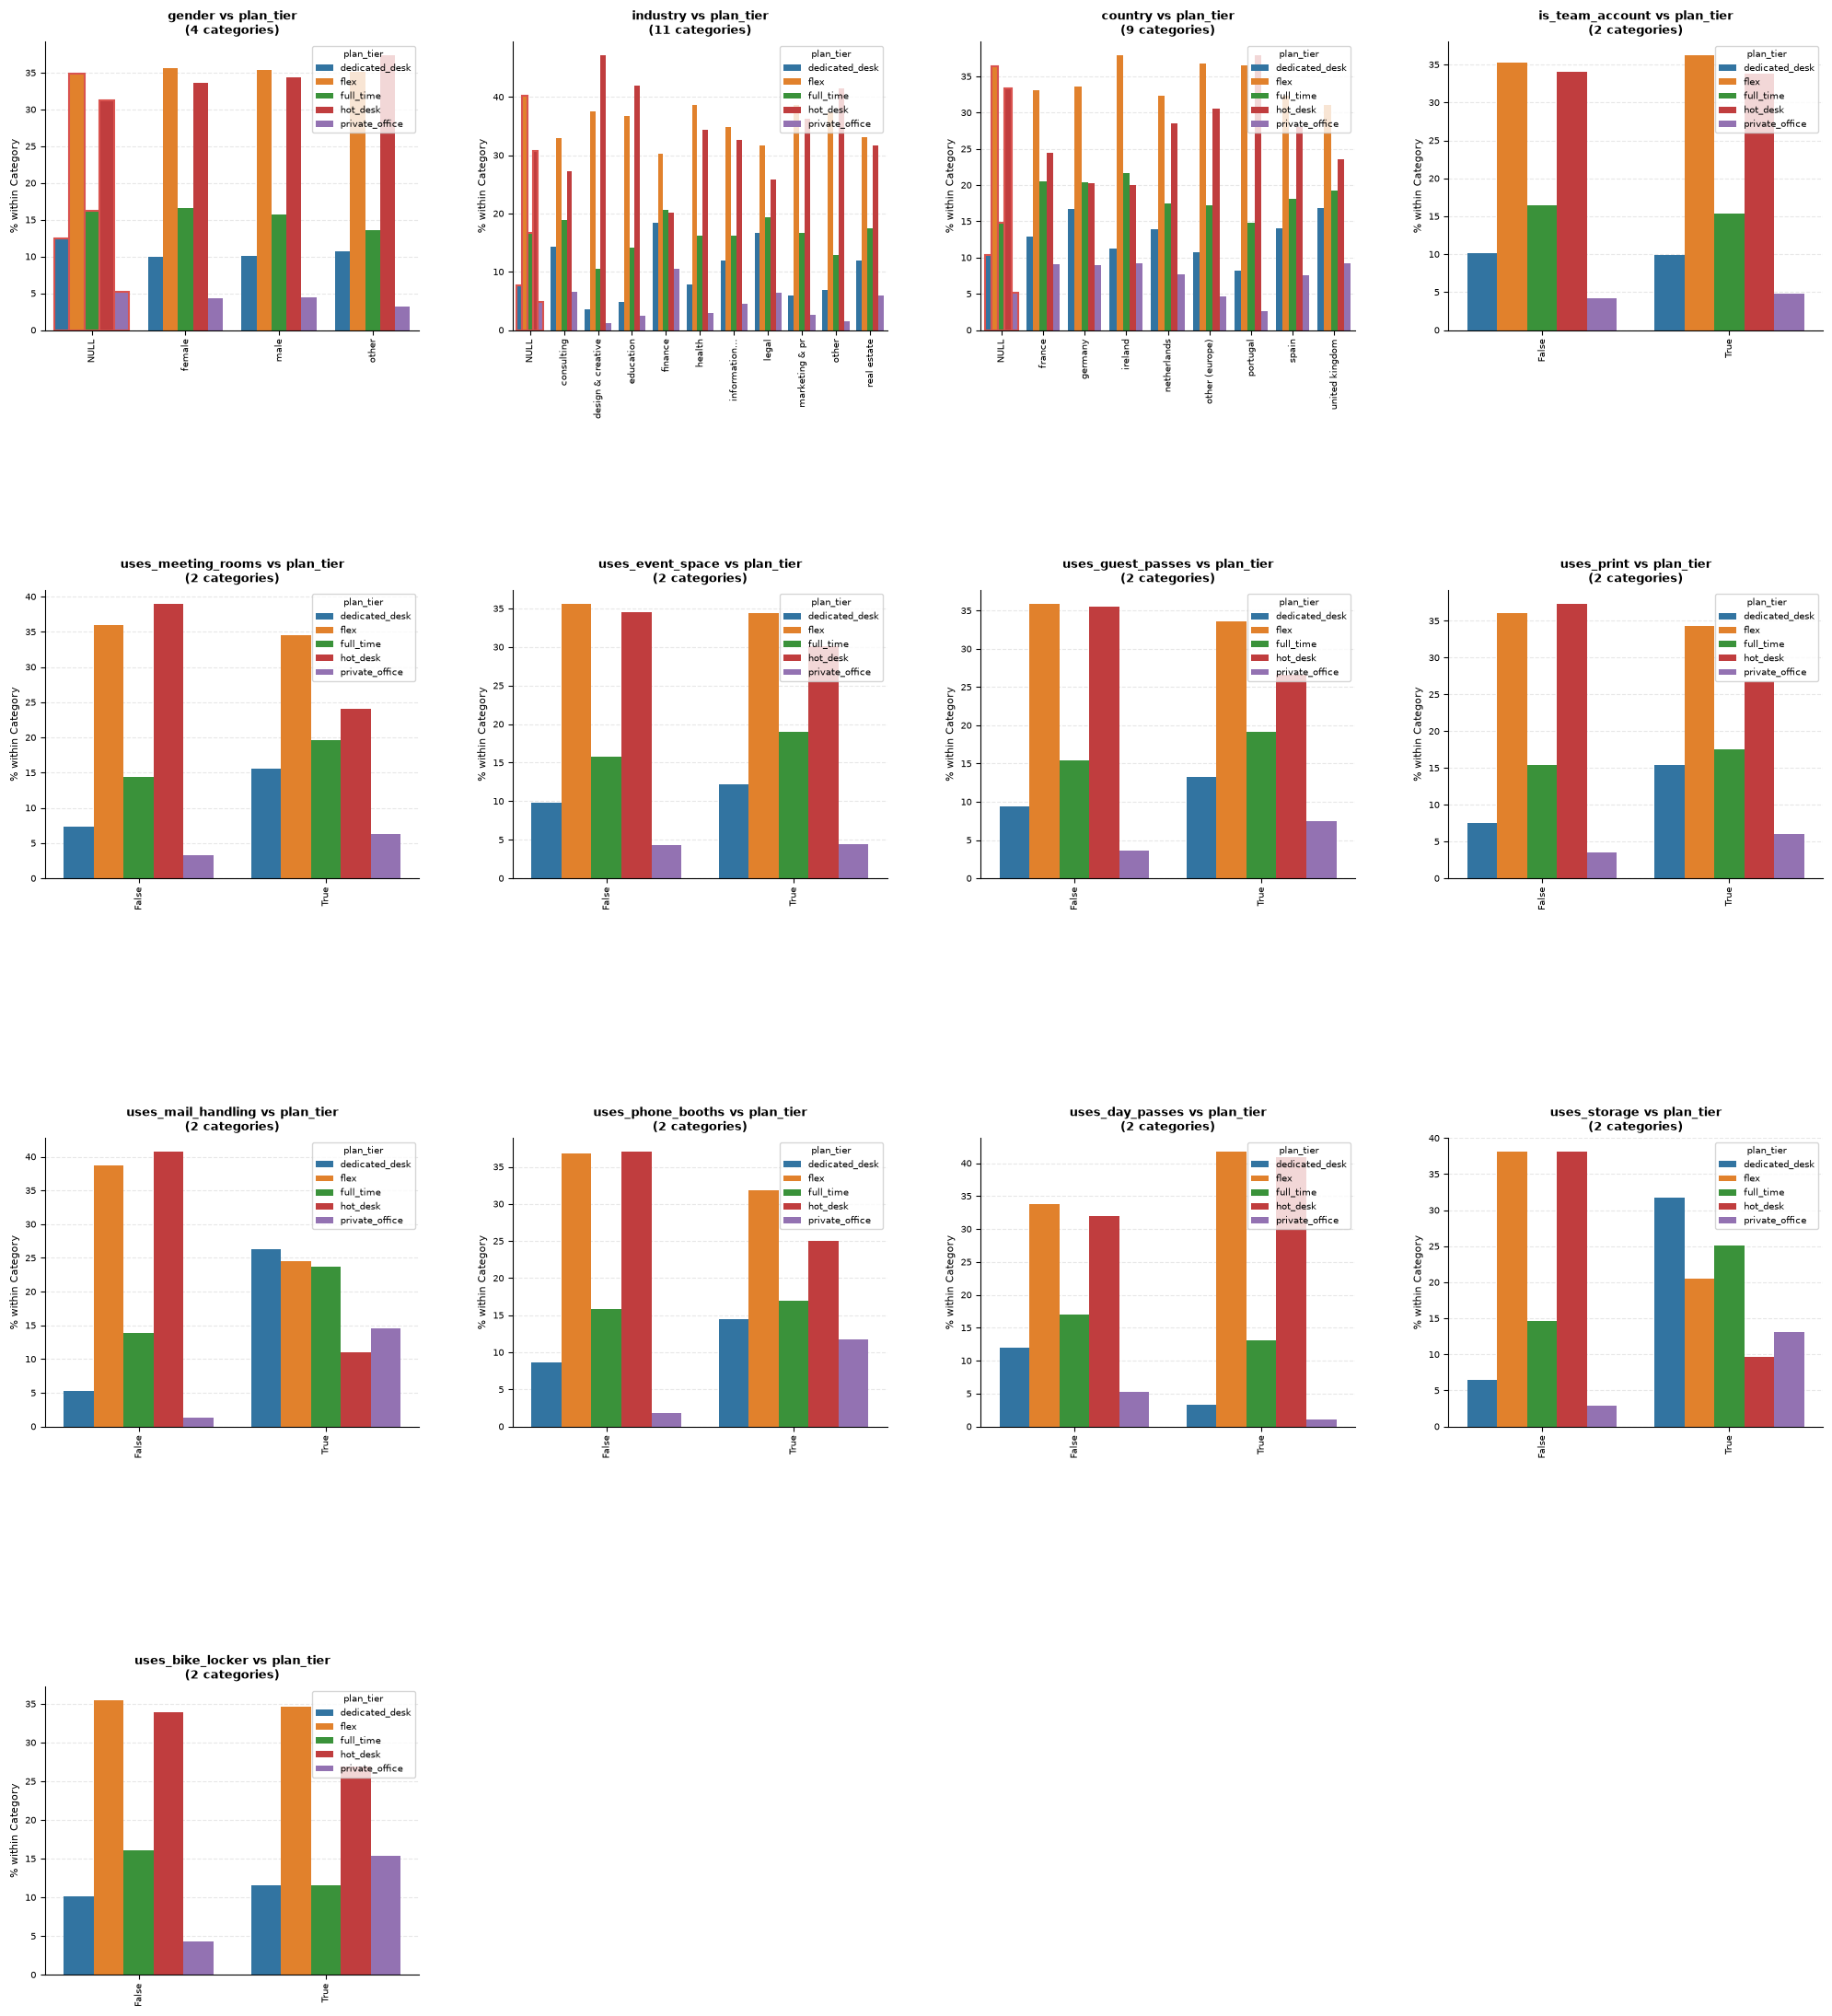

In [393]:
plot_categorical_and_bool_against_target(df=df_raw, exclude=["member_id"], target_col="plan_tier")

- we can see a slight difference in distribution on countries for the different plan_tier , it seems that the countries with higher GDP tend to have a higher median tier.
- using team_accounts doesn't change the plan_tier distribution.
- some use_* have a slight distribution change , however this will probably will be to low to matter.

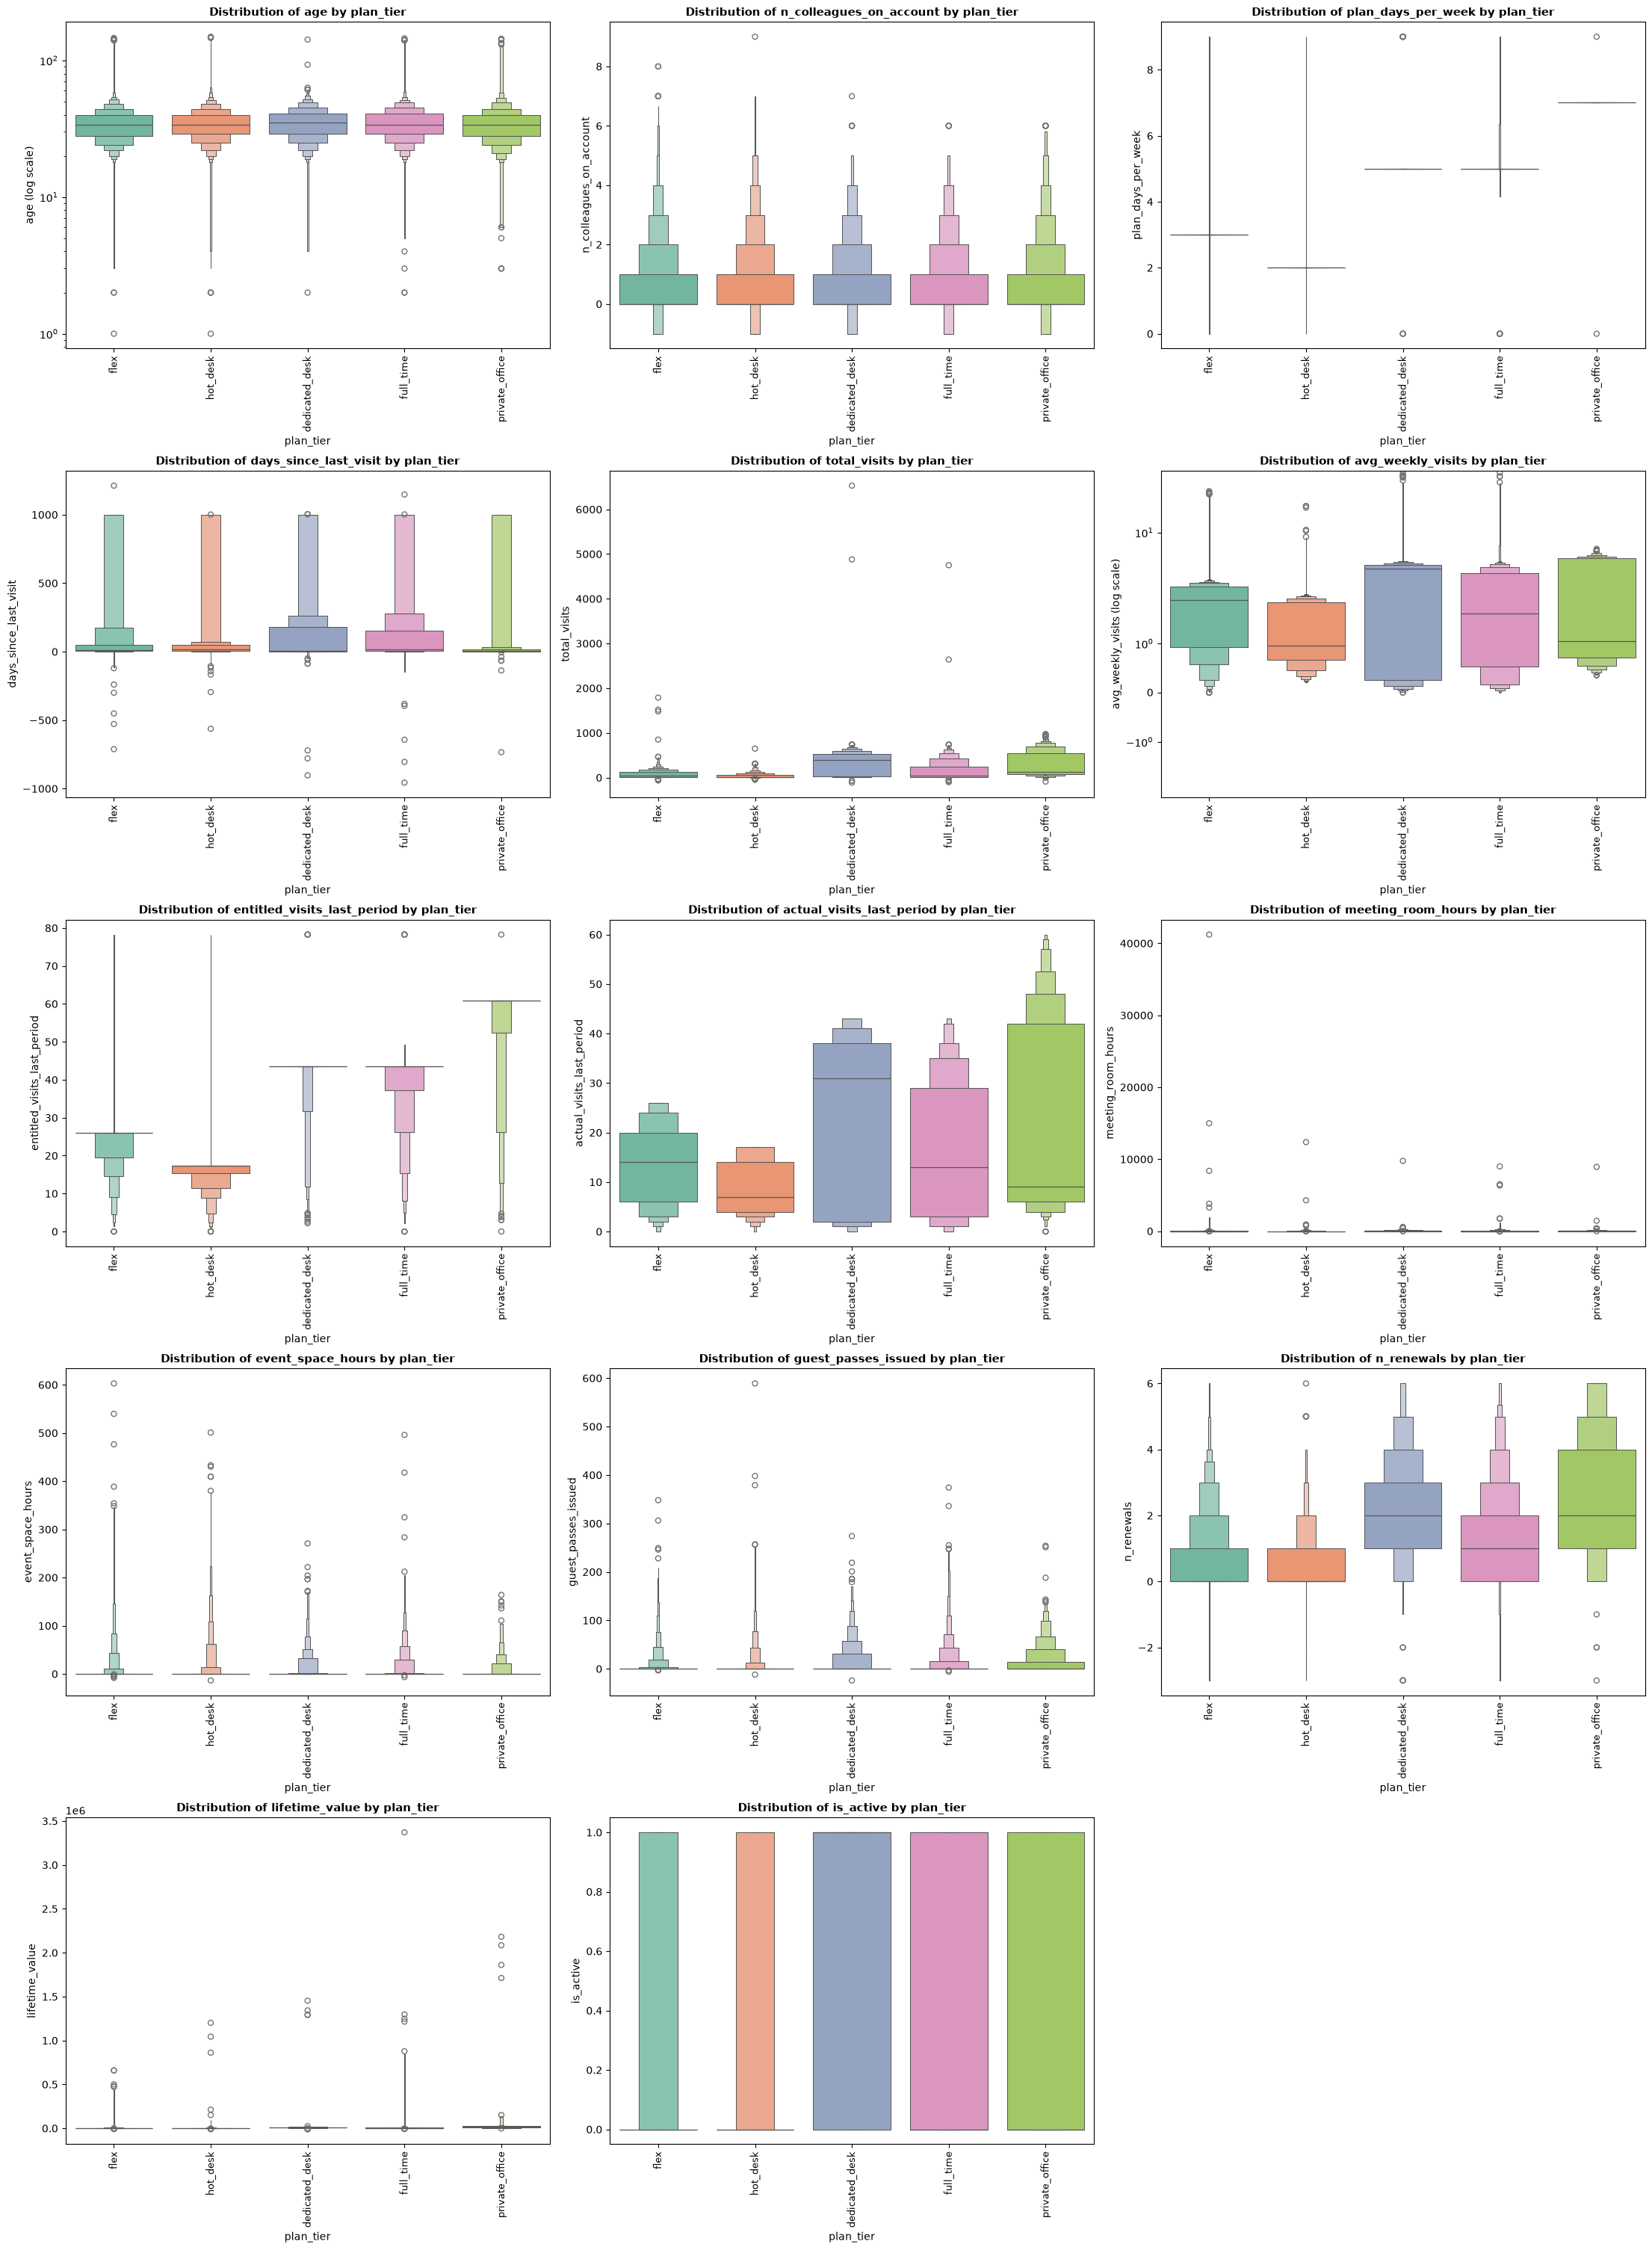

In [394]:
categorical_numerical(df_raw,exclude=["member_id"],target="plan_tier")

 - We have strong logic separation on the plan_tier for plan_days_per_week(they show a clear step-wise increase , with only 1 exception),entitled_visits_last_period, actual_visits_last_period and avg_weekly_visits also show that higher plans imply higher visits(entitled or actualized).
 - For n_renewals and total_visits we can only see a broad pattern for budget vs luxury plan_tier where these luxury ones tend to have higher volume when compared to the budget tiers.
 - Lifetime values has no discernable difference because of the heavy zero density , however we can the ammount and range of outlier with the increase of the plan_tier.
 - For the rest of the features they have no discernable difference for the plans.

#### 1.3.2.4 Numerical Feature vs Numerical Feature

- The 3 pairs (entitled_visits_last_period ,plan_days_per_week), (avg_weekly_visits,actual_visits_last_period) and (actual_visits_last_period,total_visits) have a very strong positive linear correlation which means that during our clustering we will most likely choose one of  them for clustering.
- The 4 pairs (avg_weekly_visits,total_visits),(entitled_visits_last_period,total_visits),(total_visits,lifetime_value) and (entitled_visits_last_period,lifetime_value) have a positive linear correlation which means that this features have a clear correlation.
- The 3 pairs  (total_visits,days_since_last_visit),(avg_weekly_visit,days_since_last_visit) and (actual_visits_last_period,days_since_last_visit) have a strong negative correlation which means that members who visit more often have a shorter gap since their last visit, which is obvious.
- Age and n_colleagues_on_account are uncorrelated with every numeric variable.
- meeting_room_hours, event_space_hours and guest_passes_issued are weakly related to the rest (at most 0.34). They are mostly zeros, so correlation might understate their link with other variables.

In [395]:
def spearman_correlation(df):
    """
    Plot spearman correlation heatmap for numerical features.
    
    Parameters
    ----------
    df : pd.DataFrame
        The full input dataset.
    
    Returns
    ----------
    None
        Only plots heatmap.
    """
    s=df.select_dtypes(include=["number","bool"]).columns.tolist()  #get all numerical features (int,floats and booleans).
    corr = df[s].corr(method="spearman") #get spearman correlation matrix
    plt.figure(figsize=(12, 10))
    mask = np.triu(np.ones_like(corr, dtype=bool)) | (abs(corr) <= 0.5)
    #now we do heatmap, we only want bottom half and not the diagonal with perfect correlation.
    sns.heatmap(corr, mask=mask, annot=False,square=True,linewidths=0.5,cbar_kws={"shrink": 0.8}, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,)
    plt.title("Spearman Correlation (|r| > 0.5)")
    plt.tight_layout()
    plt.show()

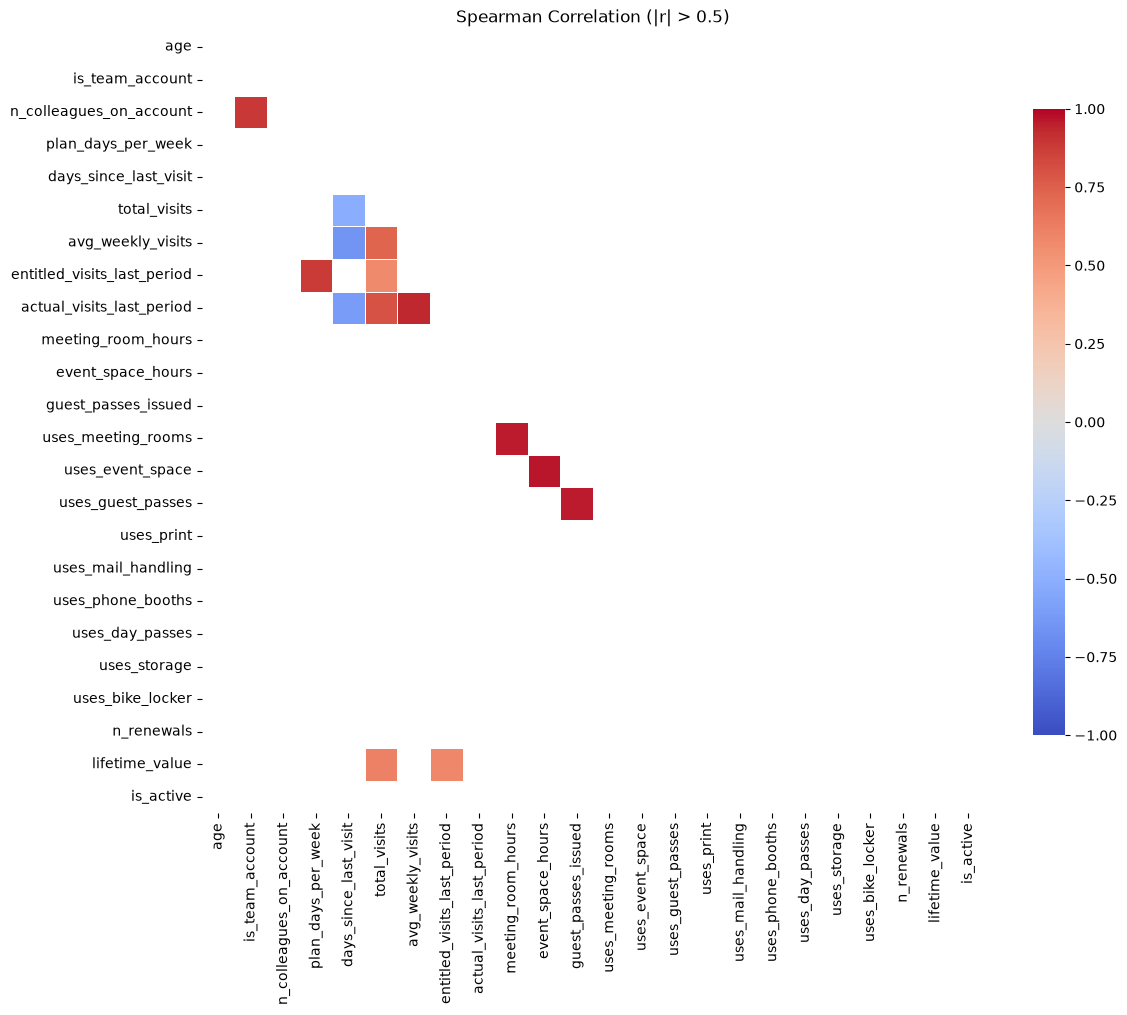

In [396]:
spearman_correlation(df_raw)

- Each add-on flag is almost the same variable as its quantity: meeting rooms with meeting-room hours (0.96), event space with event-space hours (0.97) and guest passes with guest passes issued (0.96). is_team_account and n_colleagues_on_account are also strongly related (0.89). We expect to keep only one variable from each of these pairs.
- Age, is_team_account and n_colleagues_on_account have a correlation of at most 0.02 with every other variable (apart from the team pair), and uses_bike_locker is about 0 throughout.
- Lifetime_value is most related to total_visits (0.61), entitled_visits_last_period (0.58), n_renewals (0.45) and plan_days_per_week (0.44). Among add-ons, it relates moderately to mail handling (0.30), storage (0.28) and meeting rooms (0.26), weakly to print (0.20) and phone booths (0.19), and slightly negatively to day passes (-0.06).
- Mail handling and storage follow plan size (0.40 and 0.33 with plan_days_per_week), while print and phone booths follow visit frequency (print 0.35 with avg_weekly_visits, against 0.14 with plan days). Day passes are the only add-on negatively related to plan days and renewals (-0.14 for both), which suggests users of lighter plans.
- The strongest co-use correlations are among meeting rooms, event space and guest passes (0.21 to 0.26) and between mail handling and storage (0.24).
- Days_since_last_visit is negatively related to visit variables (-0.51 to -0.66) and to lifetime_value (-0.37). This column contains the 999 code, so these magnitudes should be treated with caution.
- The add-on flags mean "ever used", and the visit totals and lifetime_value are cumulative, so part of these correlations may simply reflect how long a member has been with ACDC. We will check this by controlling for tenure in the future.

#### 1.3.2.5 Datetime Features vs Numerical Features

In [397]:
def plot_trends(df, date_col, cols=None, freq="QS"):
    """
    Plot temporal trends of numerical features aggregated by a datetime column.
    The visualization generates a multi-panel grid displaying:
    - A record volume bar chart (representing cohort/transaction counts per period).
    - Line plots for binary features showing proportional means.
    - Line plots with shaded Interquartile Range (IQR) bands for non binary features.

    Parameters
    ----------
    df : pd.DataFrame
        The full input dataset.
    date_col : str
        The name of the datetime column to group by.
    cols : list of str, optional
        Specific numerical or boolean columns to plot. If None, automatically
        selects all numerical and boolean columns from the DataFrame.
    freq : str, default 'QS'
        The temporal aggregation frequency

    Returns
    -------
    None
        Displays the generated multi-panel plot.
    """
    #get selected cols or if none selected get all
    cols = cols or df.select_dtypes(include=["number","bool"]).columns.tolist()
    #create a temporal grouper using pandas Grouper
    group = df.groupby(pd.Grouper(key=date_col, freq=freq))
    #prepend a records panel to track volume alongside date target metrics
    panels = ["records"] + cols
    nrows = int(np.ceil(len(panels) / 2))
    fig, axes = plt.subplots(nrows, 2, figsize=(14, 2.7 * nrows), sharex=True)

    #iterate through flattened axes and panels 
    for ax, c in zip(axes.flat, panels):
        if c == "records":
            #bar chart
            n = group.size()
            ax.bar(n.index, n.values, width=60)
        elif set(df[c].dropna().unique()) <= {0, 1}:
            #lLine plot
            r = group[c].mean()
            ax.plot(r.index, r.values, marker="o", ms=3)
        else:
            #line plot  with a shaded IQR band
            q = group[c].quantile([0.25, 0.5, 0.75]).unstack()
            ax.plot(q.index, q[0.5], marker="x", ms=3)
            ax.fill_between(q.index, q[0.25], q[0.75], alpha=0.25) #shaded area

        ax.set_title(c)
        ax.grid(True, alpha=0.3)

    for ax in axes.flat[len(panels) :]:
        ax.axis("off")
        
    #plot
    fig.suptitle(f"Trends by {date_col} (median and IQR per period)",fontsize=14,y=0.99)
    plt.tight_layout(rect=[0, 0, 1, 0.97])  #leaves room at the top for title
    plt.show()                

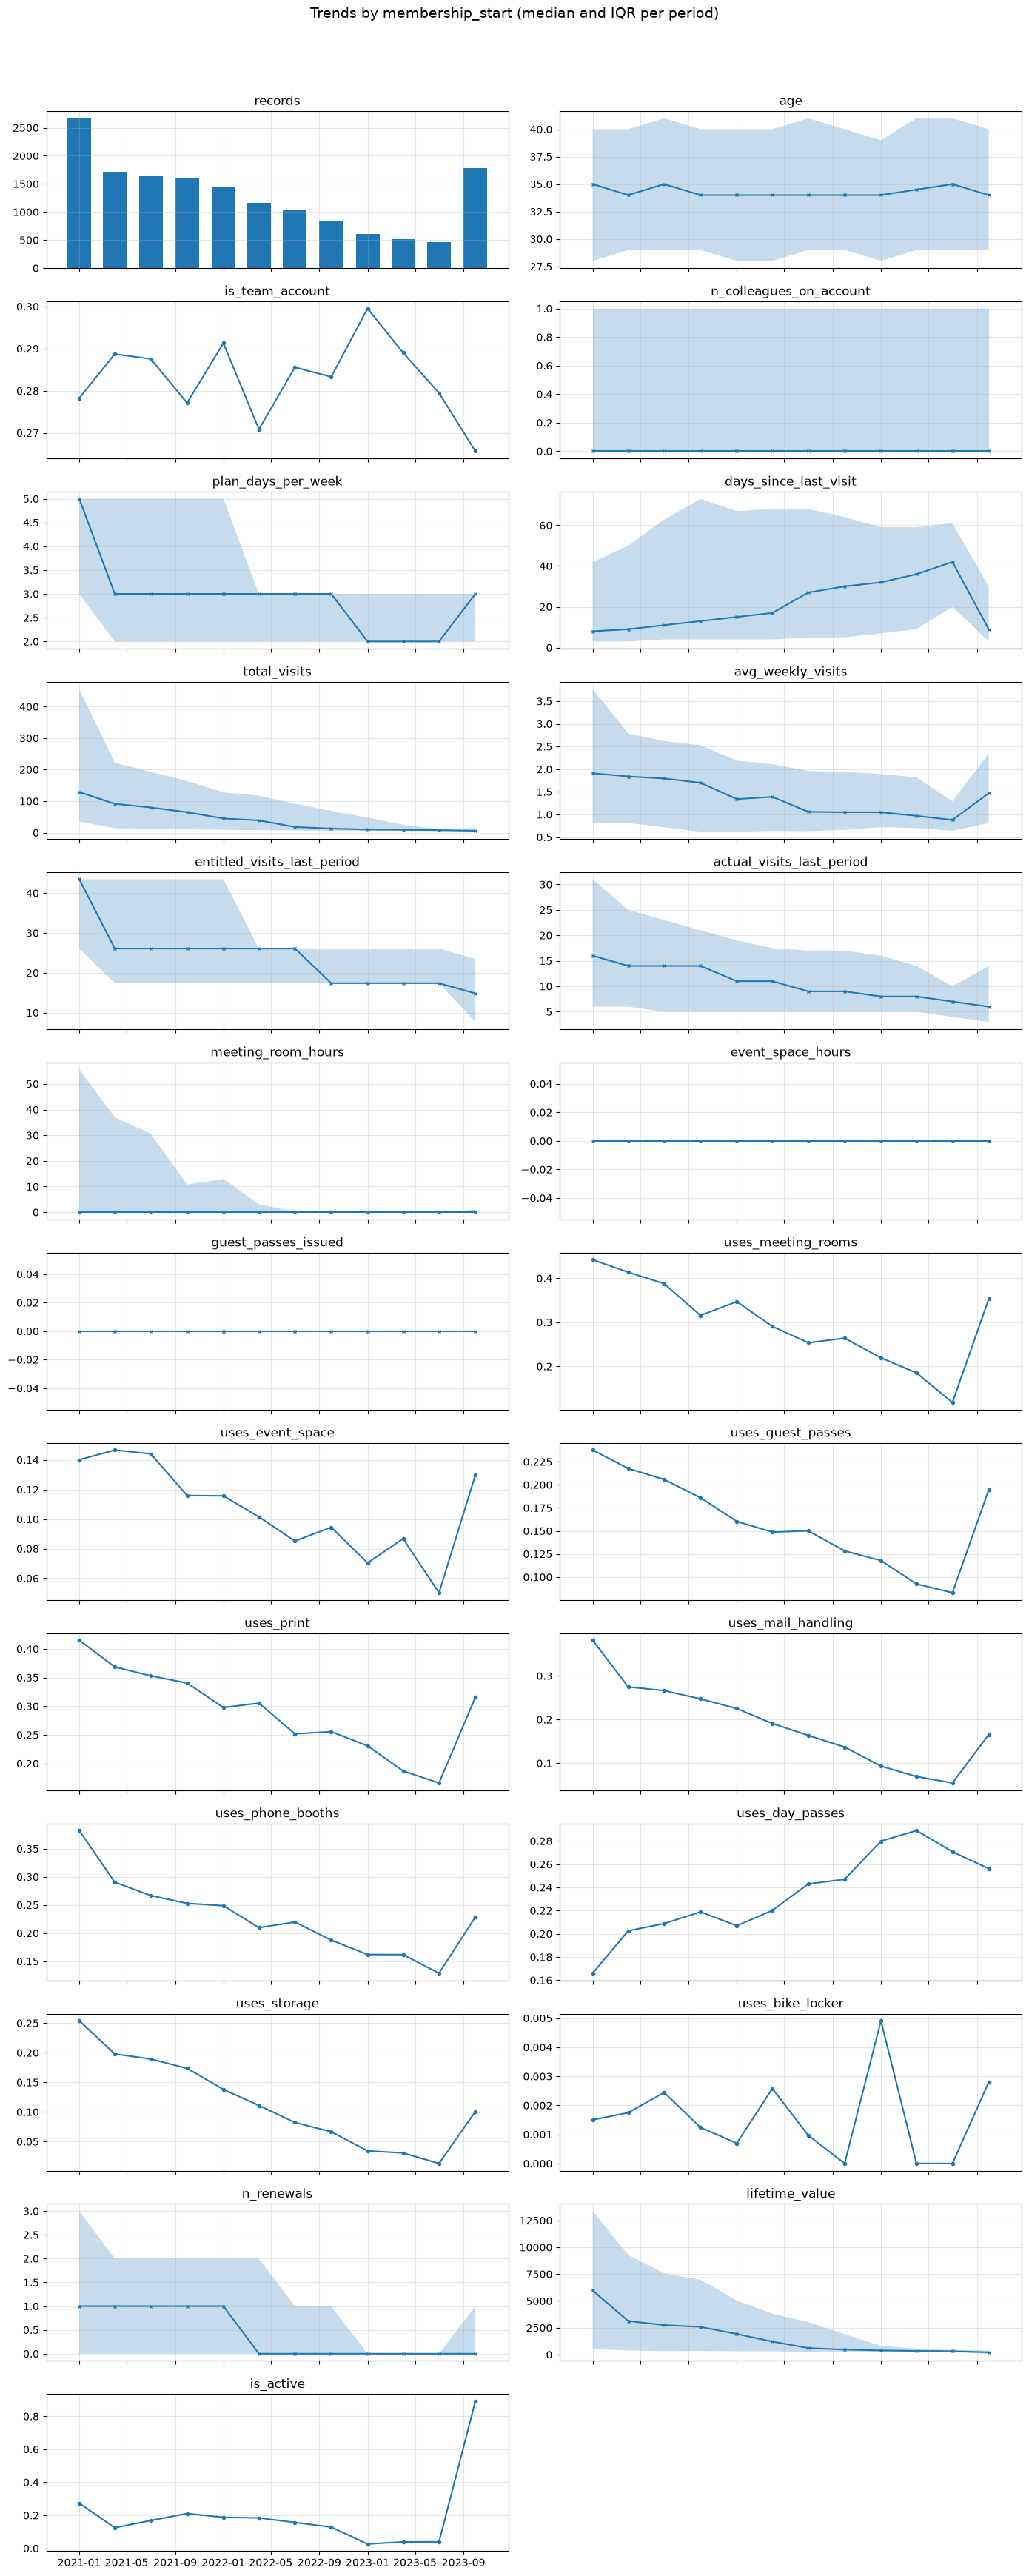

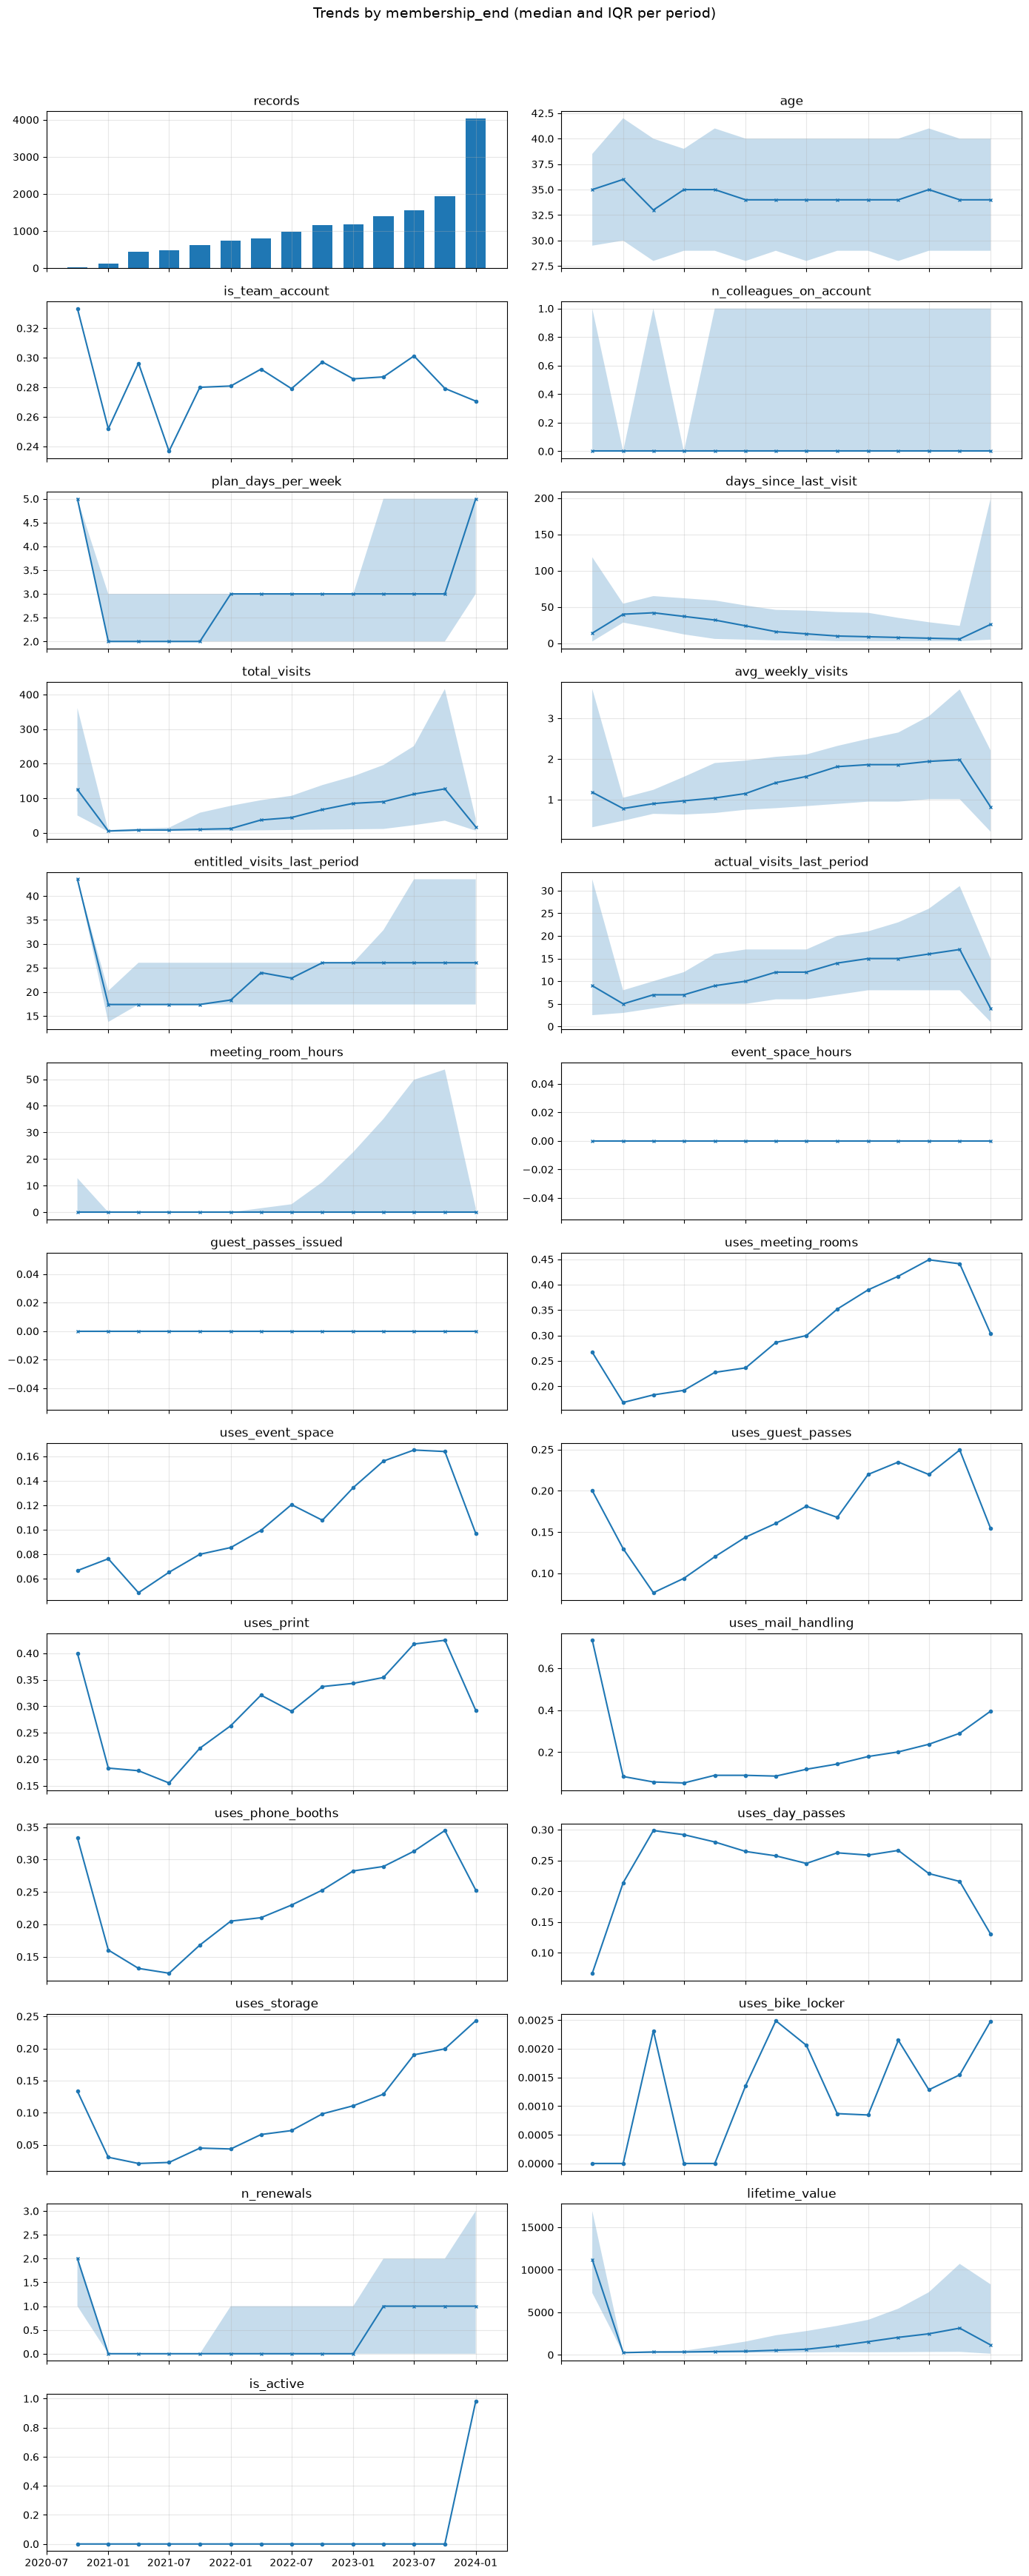

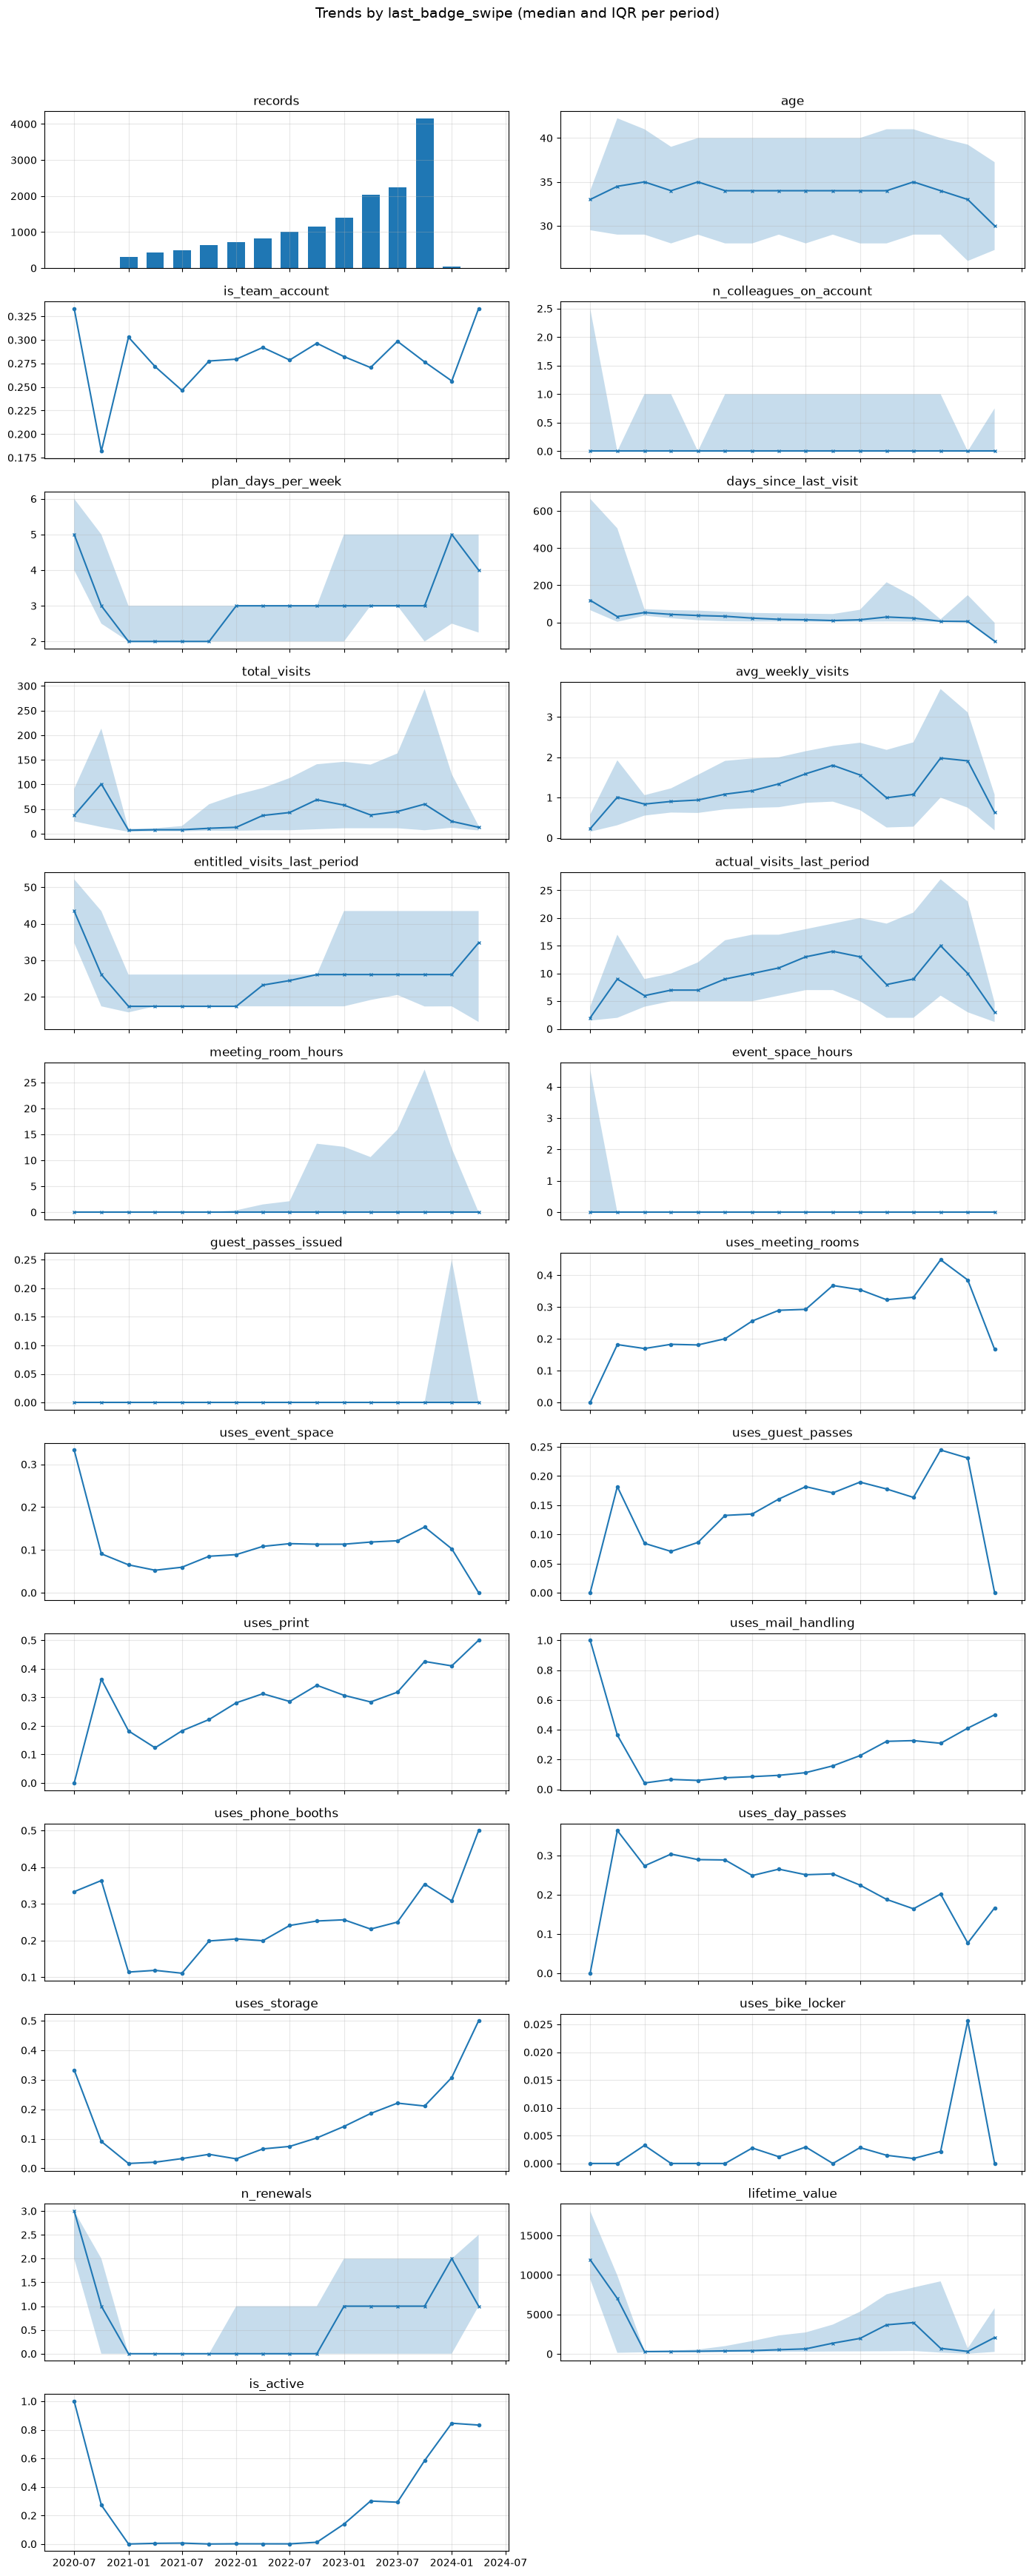

In [398]:
#iterate through all date vars
for date in date_vars:
    plot_trends(df_raw, date)    

- Age and account type are flat across all datetime features.
- Cumulative variables mirror each other.By start date, total_visits falls from about 130 to under 10, lifetime_value from about 6,000 to about 300, and the median n_renewals goes from 1 to 0. By end date and last-swipe date, the same variables rise. This is consistent with a tenure effect and should not be read as a change in member behavior.
- Plan size drifts across start cohorts. The median plan_days_per_week goes from 5 (2021-Q1) to 3, then to 2 (2023-Q1 to Q3) and back to 3 in 2023-Q4. entitled_visits_last_period and avg_weekly_visits follow the same pattern.
- Add-on use falls for later cohorts and rebounds in 2023-Q4.** Between the 2021-Q1 and 2023-Q3 starters, meeting-room use falls from about 40% to 10%, mail handling from 40% to 5%, storage from ~25% to ~5%, print from ~50% to ~17% and phone booths from ~40% to ~10%. All recover partly for the 2023-Q4 wave (for example meeting rooms about 35%). Day passes are the exception: they rise from about 17% to about 29% in 2023. By end date and last swipe, the picture reverses: members who left or visited later used more add-ons, which is likely a tenure effect.
- Active members stand out.The last end-date bar (about 4,000 members at the snapshot) has the highest storage (about 24%) and mail-handling use (about 39%) of any period, the lowest day-pass use (about 13%) and a median of 5 plan days. Its totals are lower than for members who left in 2023-Q4 (about 15 visits and 1,200 lifetime value against about 125 and 3,200), which fits with many of them being recent starters.
- Some features carry no information. event_space_hours, guest_passes_issued and meeting_room_hours stay at 0, and bike-locker use is below 0.5% with only noise-driven spikes.
- The first and last bars of the end-date and swipe figures contain very few records, so their values should not be interpreted.

#### 1.3.2.6 Datetime Features vs Categorical Features

In [399]:
def plot_trend_categorical(df,date_col,cat_cols=None,freq="QS",max_categories=50):
    """
    Plot how the mix of each categorical column changes over time.
    For every categorical column, draws a stacked bar chart of record counts
    on the left and of category shares on the right per time period, all in one figure.

    Parameters
    ----------
    df : pd.DataFrame
        The full input dataset.
    date_col : str
        Datetime column used for the time axis.
    cat_cols : list of str, optional
        Columns to plot. If None, every column that is not numeric, boolean
        or datetime is a candidate.
    freq : str, default 'QS'
            The temporal aggregation frequency.
    max_categories : int or None, default 50
        Skip columns with more distinct values than this.

    Returns
    -------
    None
            Displays the generated multi-panel plot.
    """
  

    #get all cols that are not numeric or datetime.
    if cat_cols is None:
        cat_cols = [c for c in df.columns if c != date_col and not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c])and not pd.api.types.is_datetime64_any_dtype(df[c])]

    #one common set of time bins for every column
    bins = pd.date_range(df[date_col].min().to_period(freq[0]).start_time,
                         df[date_col].max(), freq=freq)
    bin_of = pd.Series(pd.cut(df[date_col], list(bins) + [bins[-1] + bins.freq],
                              right=False, labels=bins), index=df.index)

    valid_cols, processed, skipped = [], {}, []
    for col in cat_cols:
        s = df[col].astype("string").fillna("missing") #get a collumn for missing values
        if max_categories is not None and s.nunique() > max_categories: #skip cols that have more than max_categories value.
            skipped.append((col, int(s.nunique())))
            continue

        counts = pd.crosstab(bin_of, s).reindex(bins, fill_value=0) #get raw count
        shares = counts.div(counts.sum(axis=1).replace(0, np.nan), axis=0).fillna(0) #get percentage of each category
        valid_cols.append(col)
        processed[col] = (counts, shares)

    for col, n in skipped:
        print(f"Skipped '{col}': {n} distinct values (max_categories={max_categories}).") #anounce skipped cols

    nrows = len(valid_cols)
    heights = [max(5, 0.19 * processed[c][0].shape[1]) for c in valid_cols] # taller rows for long labels
    fig, axes = plt.subplots(nrows, 2, figsize=(16, sum(heights)), sharex=True, squeeze=False, gridspec_kw={"height_ratios": heights})

    step = max(1, len(bins) // 14)          
    tick_pos = list(range(0, len(bins), step))
    tick_labels = [bins[i].strftime("%Y-%m-%d") for i in tick_pos]

    for i, col in enumerate(valid_cols):
        counts, shares = processed[col]
        n_cat = counts.shape[1]
        cmap = "tab10" if n_cat <= 10 else "tab20" if n_cat <= 20 else "nipy_spectral" #choose cmap based on category number
        ax_c, ax_s = axes[i, 0], axes[i, 1]

        #raw count plot
        counts.reset_index(drop=True).plot(kind="bar", stacked=True, ax=ax_c, colormap=cmap, edgecolor="none", width=0.9)
        ax_c.set_title(f"Category mix (counts) - {col}")
        ax_c.set_ylabel("Records")
        ax_c.legend(title=col, bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8 if n_cat <= 20 else 6, ncol=1 if n_cat <= 25 else 2) #plot label on a upper left box

        #percentage plot
        shares.reset_index(drop=True).plot(kind="bar", stacked=True, ax=ax_s,colormap=cmap, edgecolor="none", width=0.9)
        ax_s.set_title(f"Category mix (share) - {col}")
        ax_s.set_ylabel("Share of records")
        ax_s.get_legend().remove() #second plot doesn't need labels again

    for ax in axes[-1]:
        ax.set_xticks(tick_pos)
        ax.set_xticklabels(tick_labels, rotation=90, ha="right") #rotate 90 degrees to fix on the plot
        ax.set_xlabel(date_col)

    #plot
    fig.suptitle(f"Category mix by {date_col}", fontsize=14, y=0.995)
    plt.tight_layout(rect=[0, 0, 1, 0.97]) #give space for title.
    plt.show()

Skipped 'member_id': 15450 distinct values (max_categories=50).


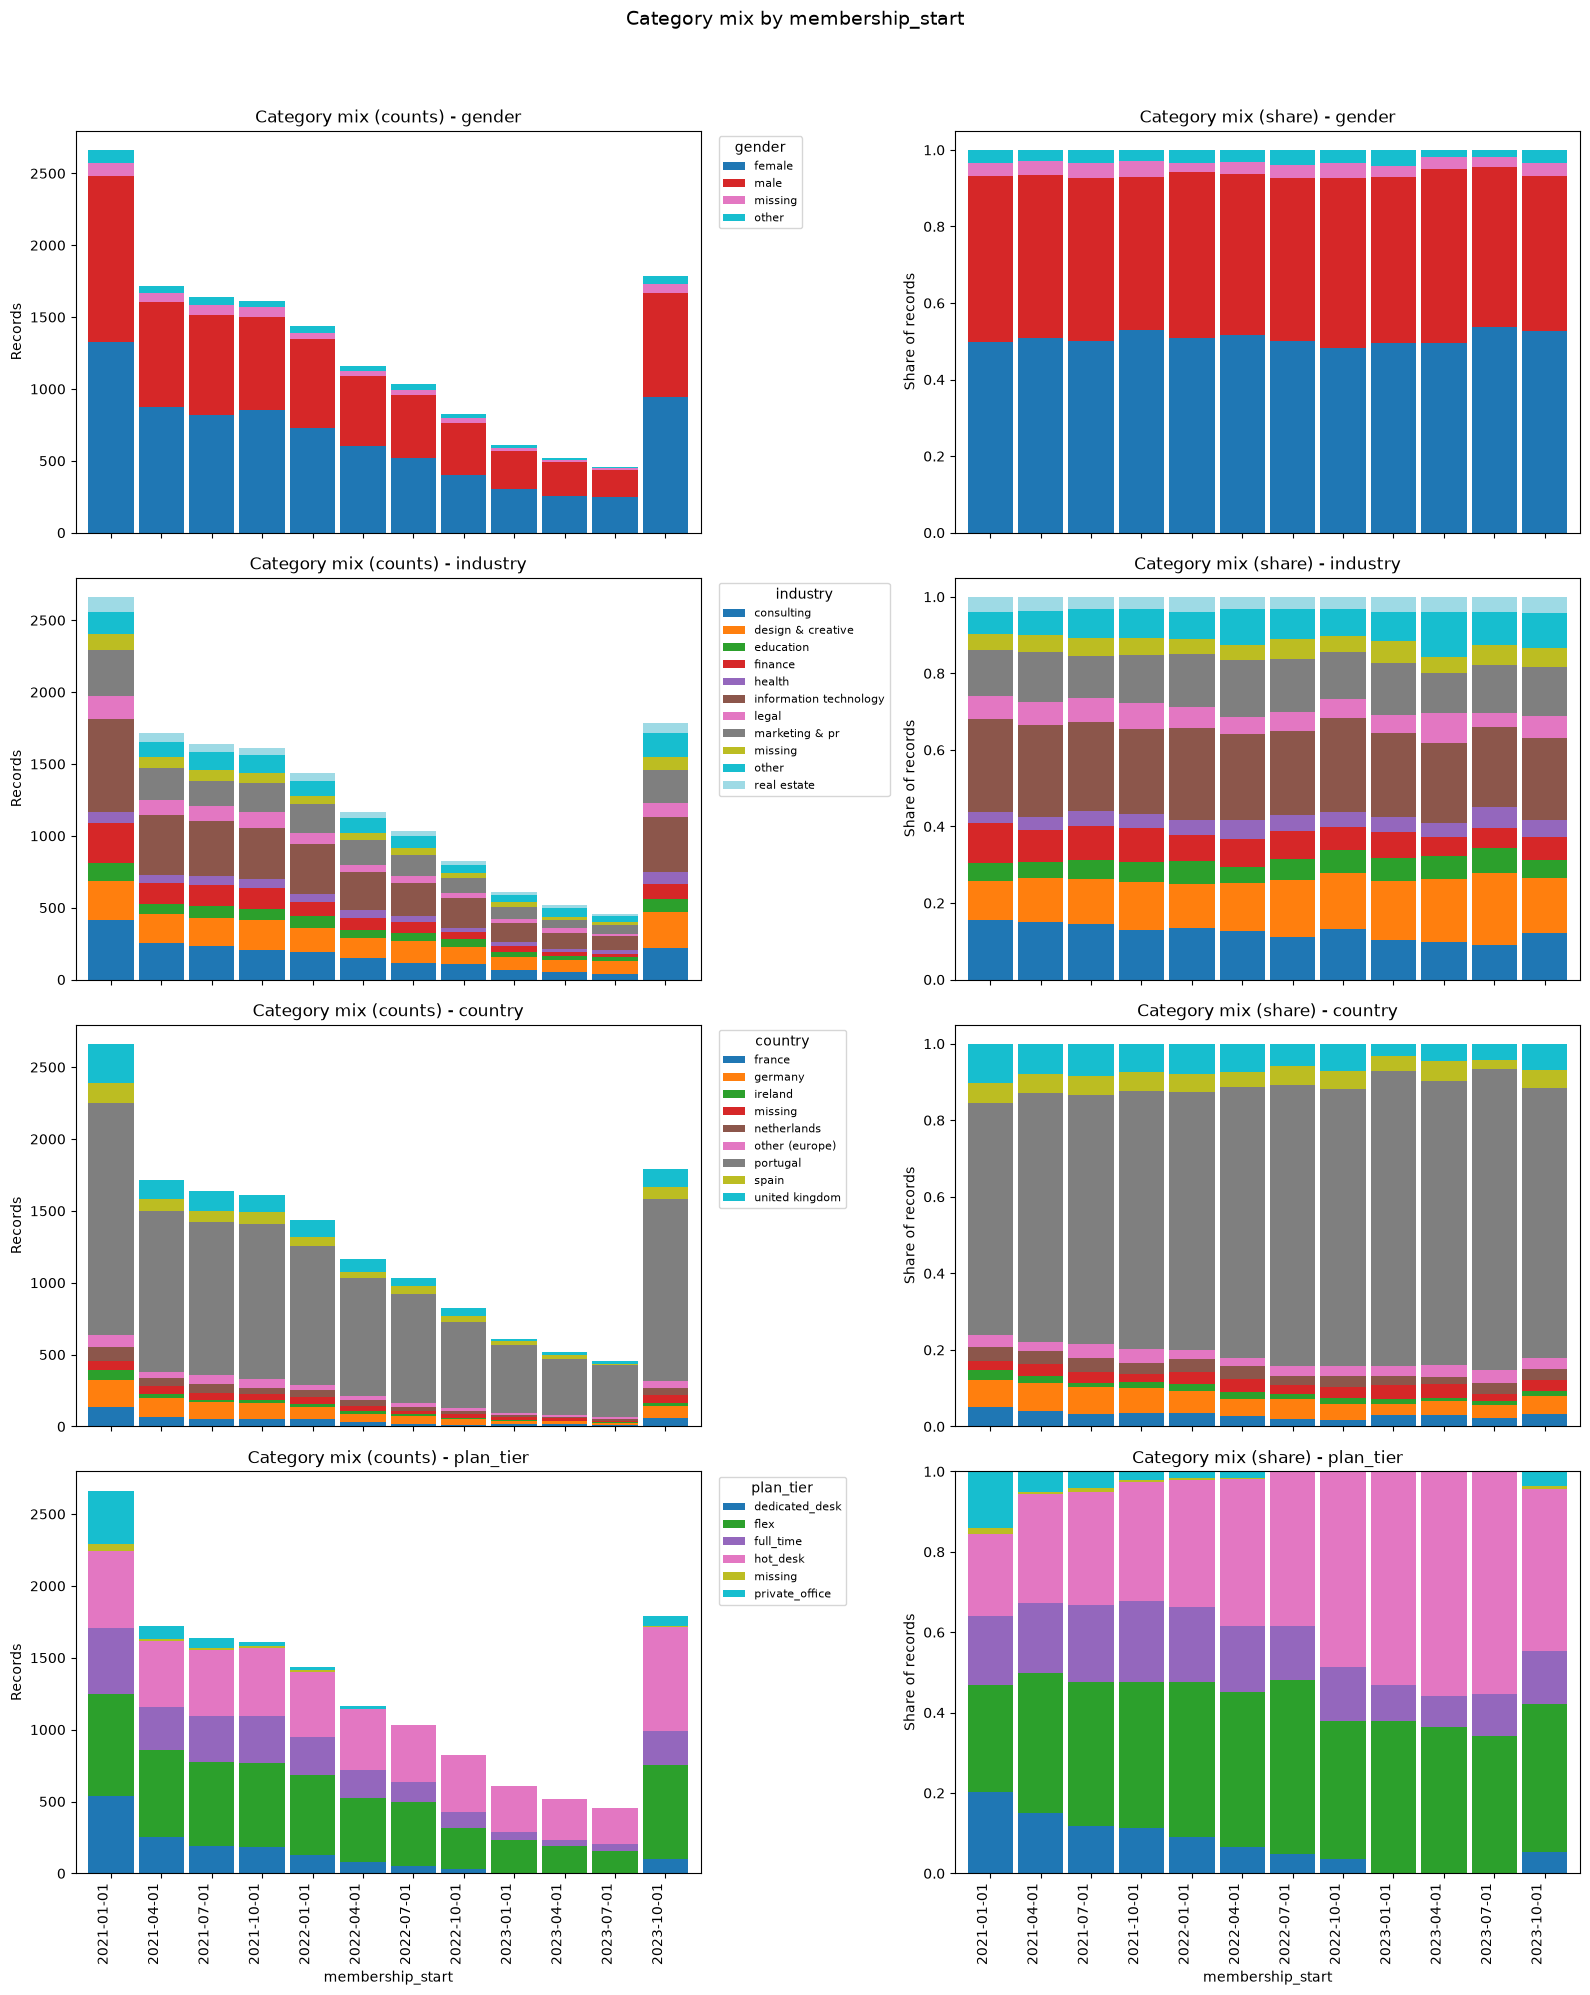

Skipped 'member_id': 15450 distinct values (max_categories=50).


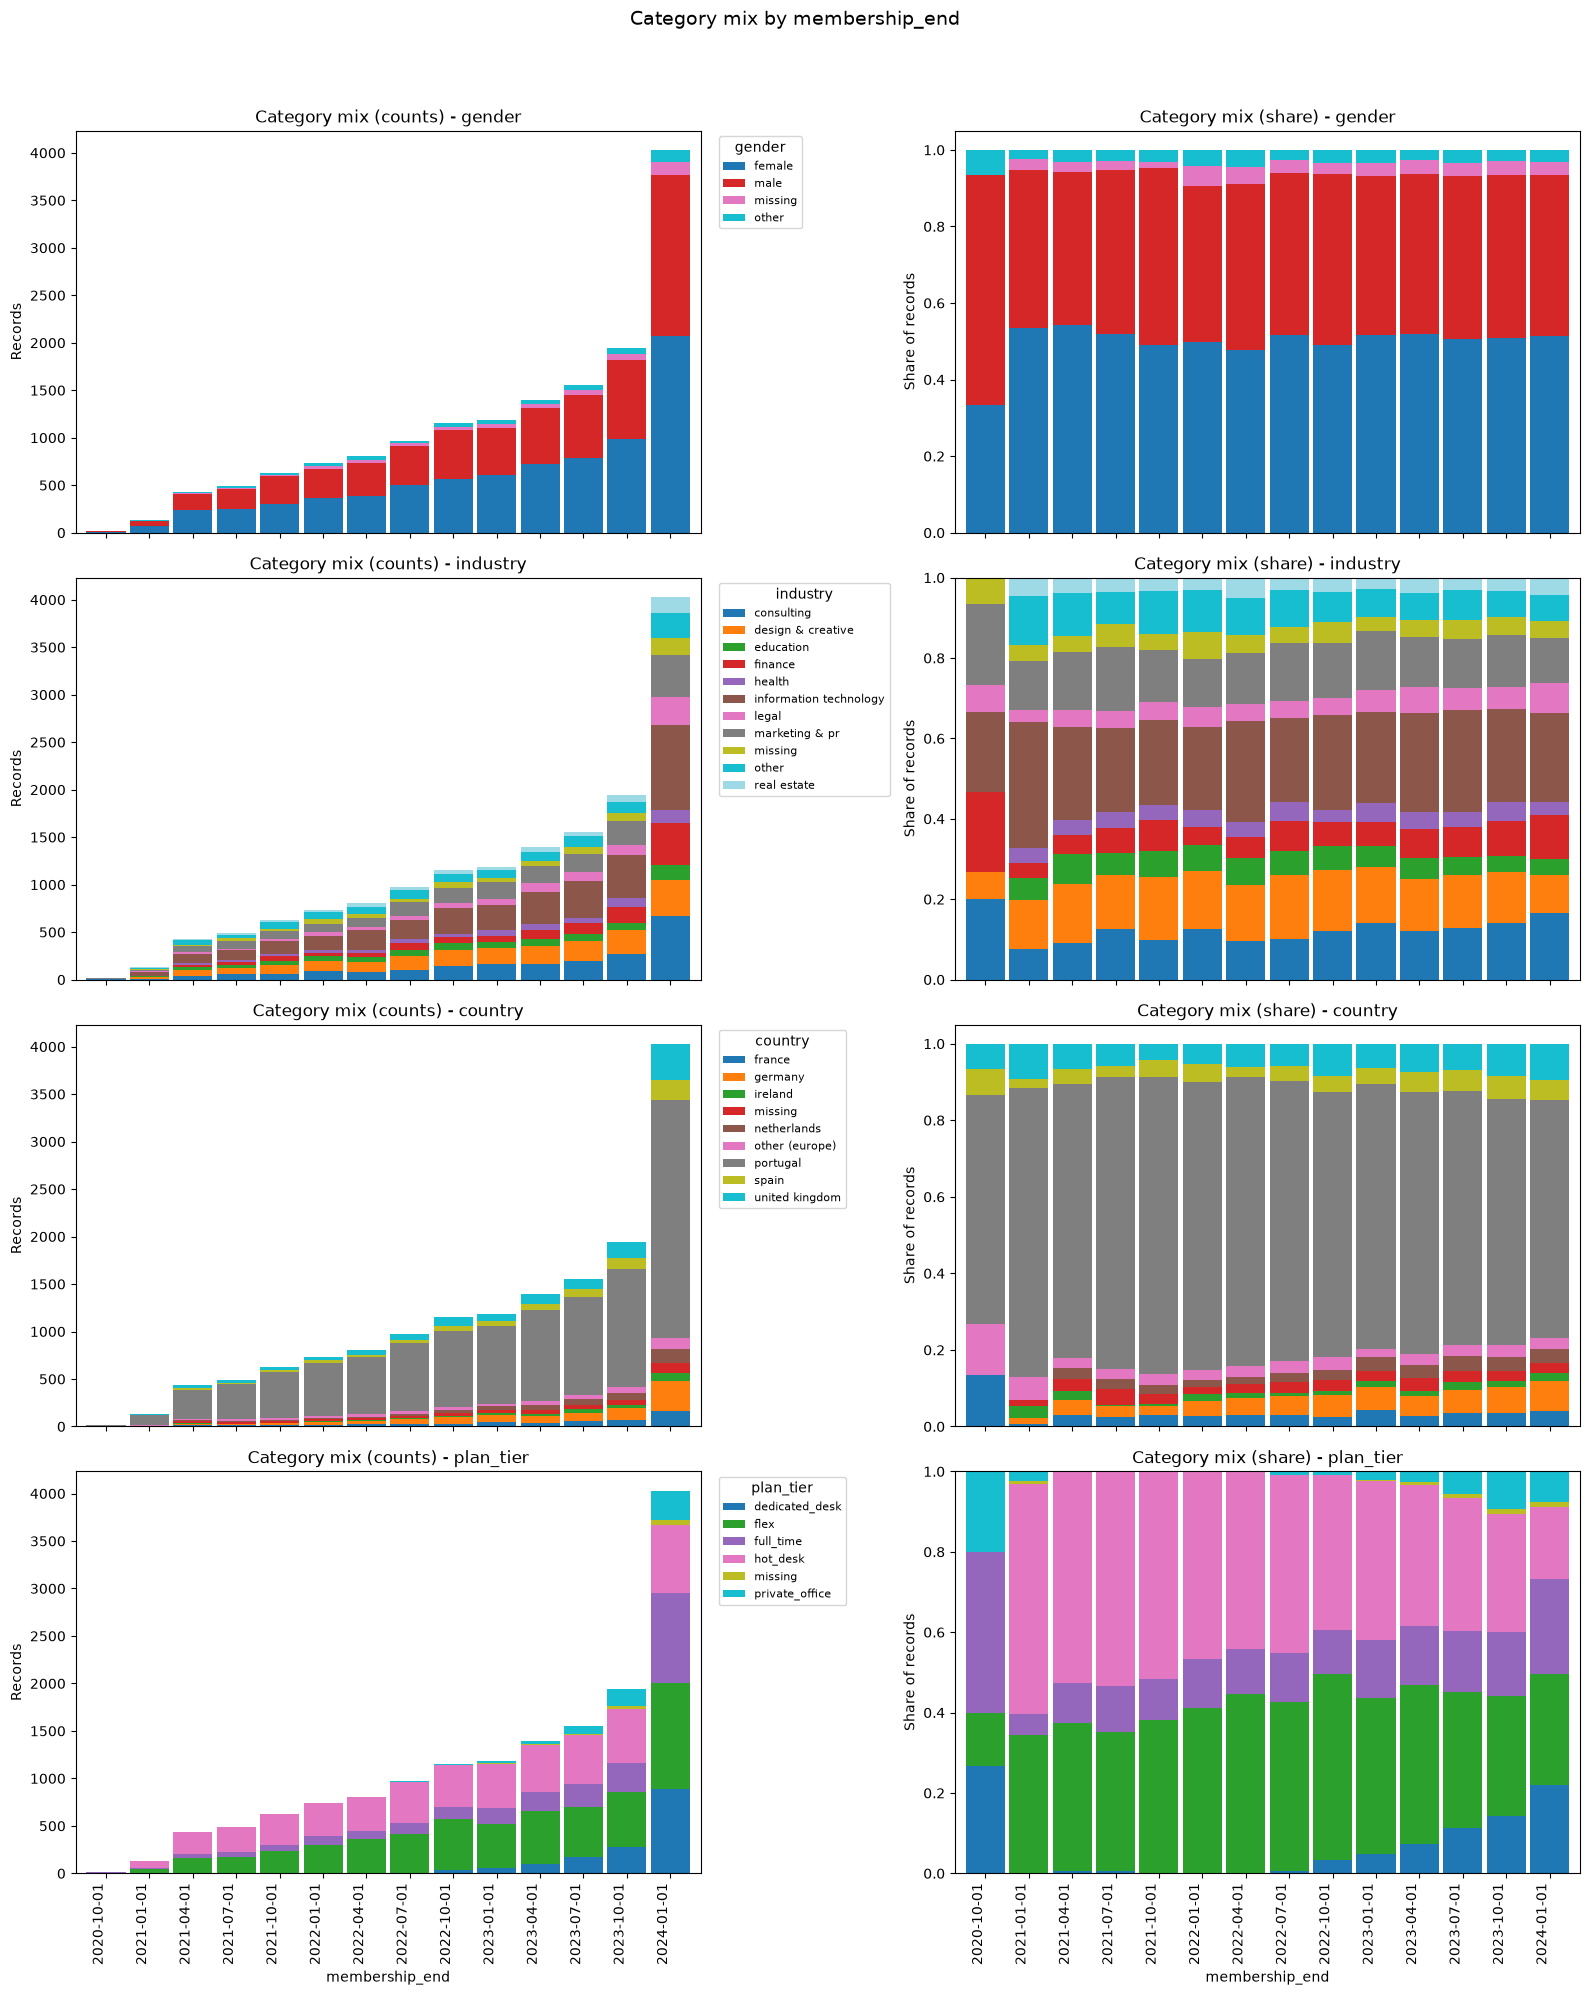

Skipped 'member_id': 15450 distinct values (max_categories=50).


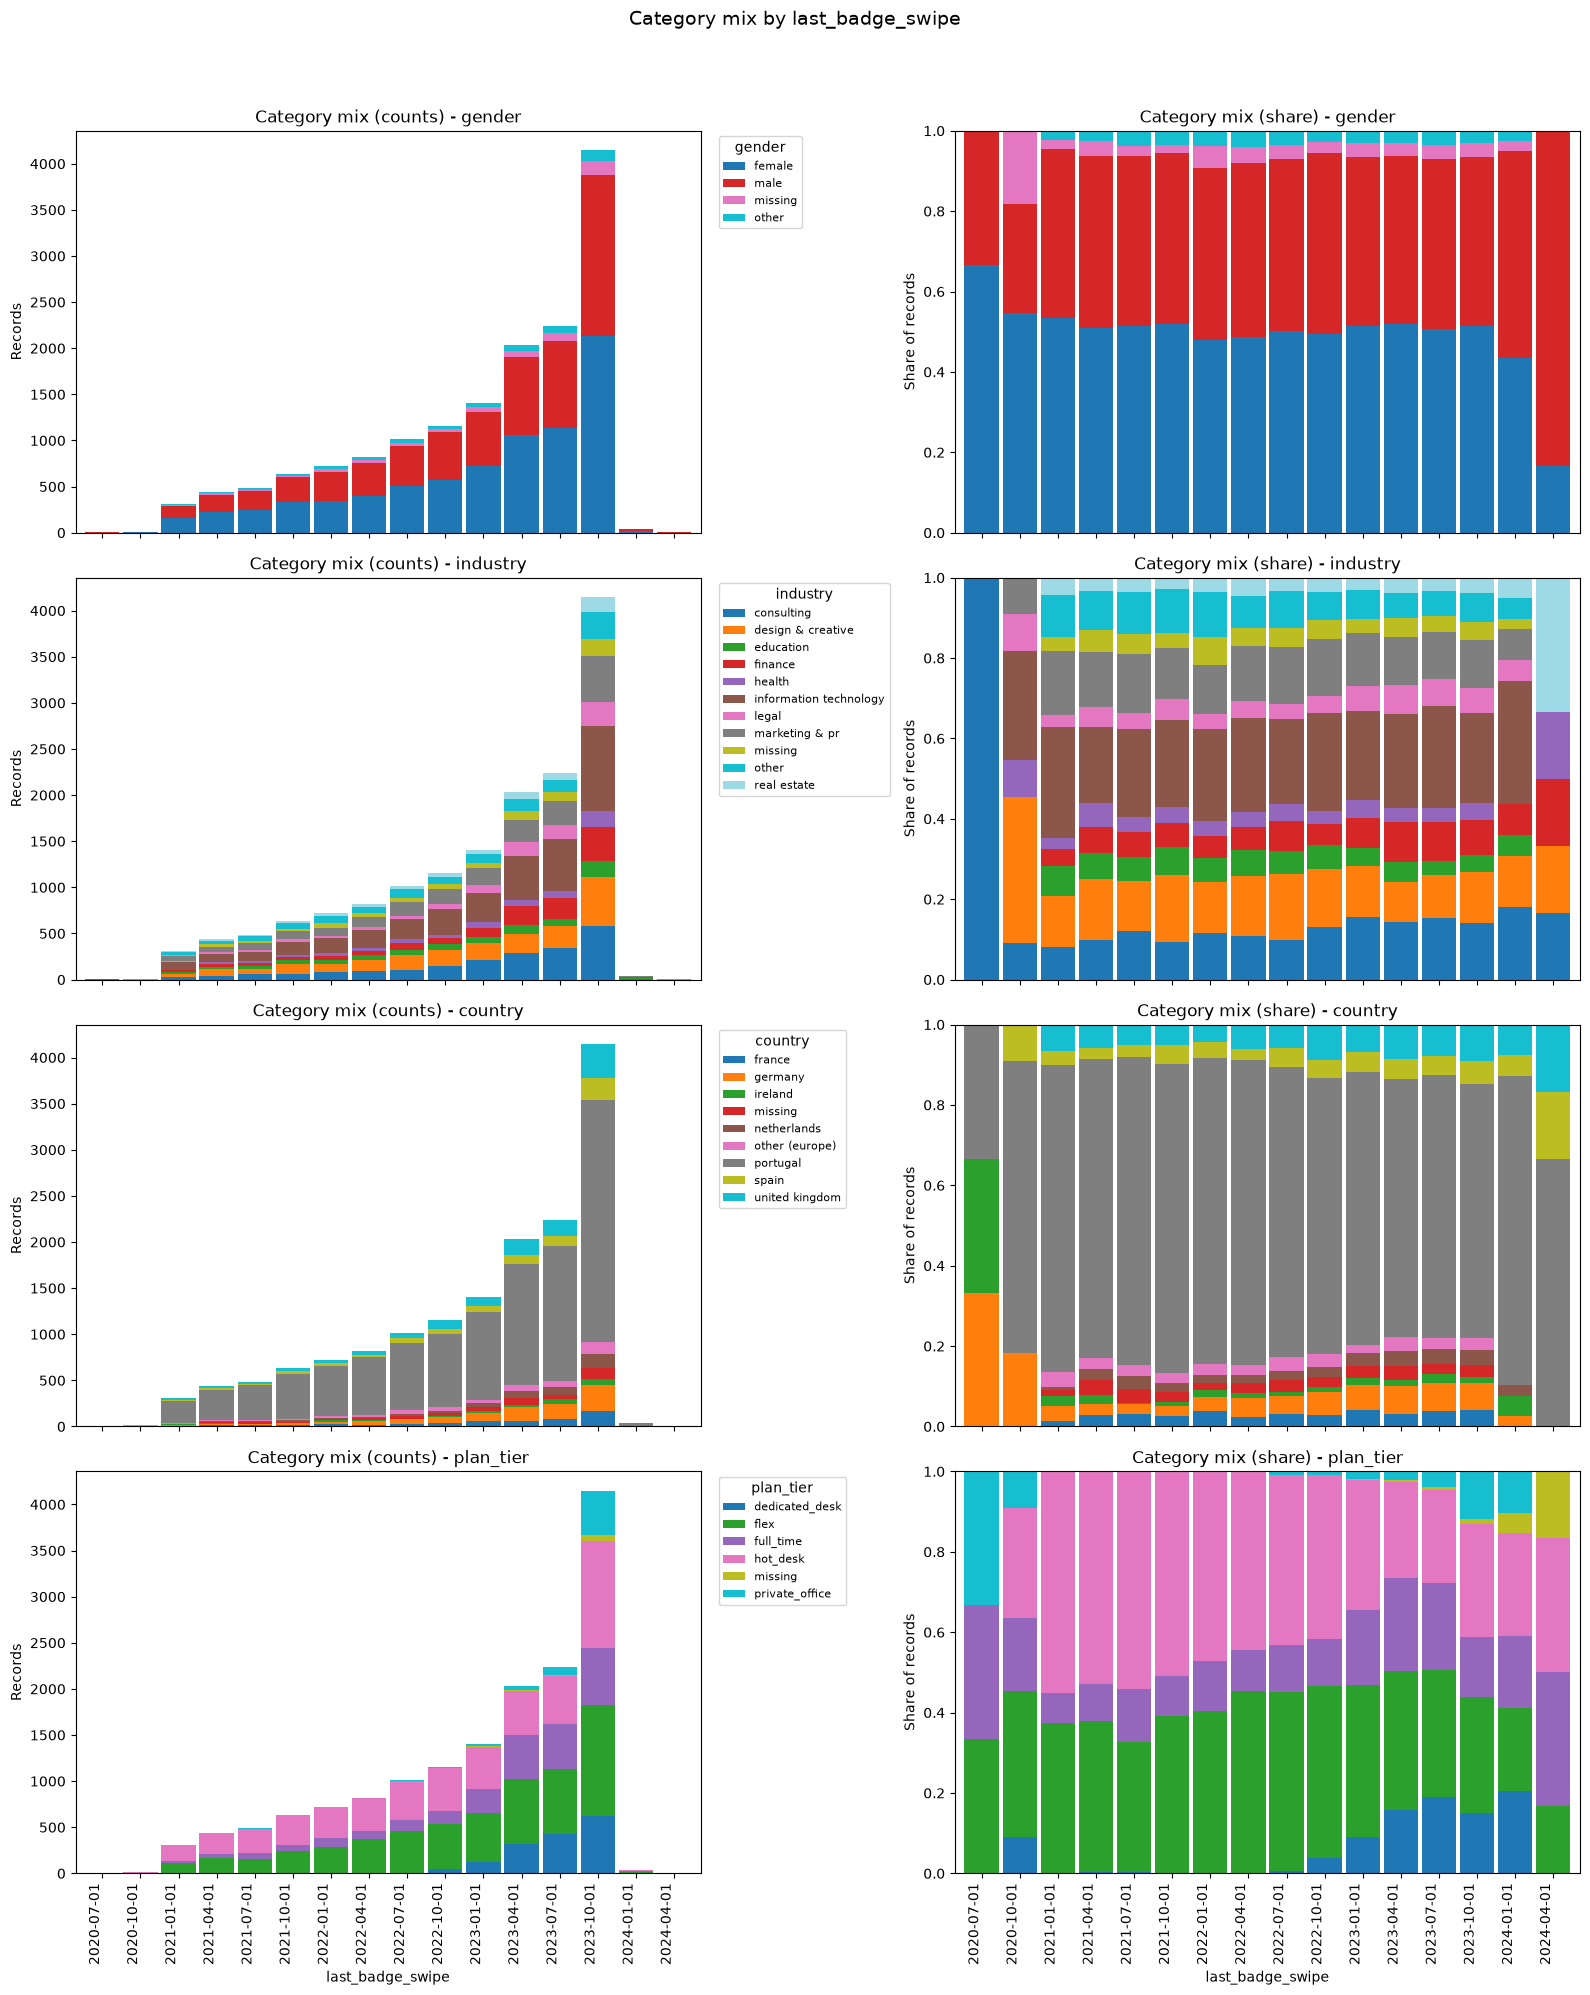

In [400]:
#iterate through all date vars
for date in date_vars:
    plot_trend_categorical(df_raw, date_col=date)

- Gender and industry are stable. In all three figures the gender split stays at about 50% female and 43% male, with small shares of "other" and missing, and the industry shares barely change from one period to the next. Neither variable shows a time pattern.
- Country is dominated by Portugal.Its share among starters rises from about 60% in 2021-Q1 to about 75–80% in 2023, so recent intake is more concentrated in Portugal.
- Plan tier is the only variable that changes clearly. Among starters, hot desk grows from about 20% to over 50%, while dedicated desk and private office fall from about 20% and 14% to almost nothing and are absent in 2023-Q1 to Q3. They reappear in a small share (about 5% and 4%) in 2023-Q4.
- Early leavers are mostly hot desk and flex. Dedicated desk and private office appear among members who left only from late 2022, and the last bar (the roughly 4,000 active members) has a much more balanced mix with a large share of dedicated desk, full time and private office. This suggests that larger plans stay longer, which we will test in the next phase when we have a enginered feature to test this.
- The first and last bars of the end-date and swipe figures contain very few records, so their shares should not be interpreted.

### 1.3.3 Feature Engineering

In [401]:
def engineer_features(df):
    """Create temporal, behavioral, service-use and value features."""
    df_fe = df.copy()

    # 1) Temporal and tenure features
    extraction_date = pd.Timestamp("2024-01-01")
    effective_end = df_fe["membership_end"].fillna(extraction_date)

    df_fe["membership_duration_days"] = (
        (effective_end - df_fe["membership_start"])
        .dt.days.clip(lower=1)
    )
    df_fe["membership_duration_months"] = (
        df_fe["membership_duration_days"] / 30.44
    )

    # is_active was created before replacing placeholder end dates.
    # df.copy() above preserves it, so do not calculate it again here.

    df_fe["recency_ratio"] = (
        df_fe["days_since_last_visit"]
        / df_fe["membership_duration_days"]
    )

    # 2) Behavioral and utilisation metrics
    df_fe["utilization_rate_last_period"] = np.where(
        df_fe["entitled_visits_last_period"] > 0,
        df_fe["actual_visits_last_period"]
        / df_fe["entitled_visits_last_period"],
        0,
    )
    df_fe["visit_intensity_gap"] = (
        df_fe["avg_weekly_visits"] - df_fe["plan_days_per_week"]
    )

    # 3) Add-on breadth
    addon_cols = [
        "uses_meeting_rooms",
        "uses_event_space",
        "uses_guest_passes",
        "uses_print",
        "uses_mail_handling",
        "uses_phone_booths",
        "uses_day_passes",
        "uses_storage",
        "uses_bike_locker",
    ]

    existing_addons = [c for c in addon_cols if c in df_fe.columns]

    for col in existing_addons:
        df_fe[col] = df_fe[col].astype(int)

    df_fe["addon_diversity_score"] = df_fe[existing_addons].sum(axis=1)

    # 4) Economic and value features
    df_fe["revenue_per_visit"] = np.where(
        df_fe["total_visits"] > 0,
        df_fe["lifetime_value"] / df_fe["total_visits"],
        df_fe["lifetime_value"],
    )
    df_fe["total_account_members"] = (
        df_fe["n_colleagues_on_account"].fillna(0) + 1
    )
    df_fe["value_per_member"] = (
        df_fe["lifetime_value"] / df_fe["total_account_members"]
    )

    # 5) Ordinal encoding
    plan_mapping = {
        "hot_desk": 1,
        "flex": 2,
        "dedicated_desk": 3,
        "full_time": 4,
        "private_office": 5,
    }

    df_fe["plan_tier_encoded"] = (
        df_fe["plan_tier"].map(plan_mapping).fillna(0).astype(int)
    )

    # 6) Log transformations
    skewed_vars = [
        "lifetime_value",
        "total_visits",
        "meeting_room_hours",
        "event_space_hours",
        "days_since_last_visit",
    ]

    for col in skewed_vars:
        if col in df_fe.columns:
            df_fe[f"{col}_log"] = np.log1p(df_fe[col])

    return df_fe

In [402]:
df_engineered = engineer_features(df_raw)

c:\Users\rodri\Desktop\Group07_EDA_Code\.venv\Lib\site-packages\pandas\core\arraylike.py:438: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs, **kwargs)
c:\Users\rodri\Desktop\Group07_EDA_Code\.venv\Lib\site-packages\pandas\core\arrays\masked.py:902: RuntimeWarning: divide by zero encountered in log1p
  result = getattr(ufunc, method)(*inputs2, **kwargs)
c:\Users\rodri\Desktop\Group07_EDA_Code\.venv\Lib\site-packages\pandas\core\arrays\masked.py:902: RuntimeWarning: invalid value encountered in log1p
  result = getattr(ufunc, method)(*inputs2, **kwargs)


In [403]:
df_engineered

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value,is_active,membership_duration_days,membership_duration_months,recency_ratio,utilization_rate_last_period,visit_intensity_gap,addon_diversity_score,revenue_per_visit,total_account_members,value_per_member,plan_tier_encoded,lifetime_value_log,total_visits_log,meeting_room_hours_log,event_space_hours_log,days_since_last_visit_log
0,CW000001,38,female,information technology,portugal,False,0,flex,3,2021-08-01,2023-03-06,2023-03-23,-17,220,2.65,26.09,22,0.00,0.00,18,0,0,1,0,0,1,1,0,0,2,4477.97,0,582,19.12,-0.03,0.84,-0.35,3,20.35,1,4477.97,2,8.41,5.40,0.00,0.00,<NA>
1,CW000002,38,male,information technology,portugal,True,2,hot_desk,2,2023-11-24,2024-01-01,2023-11-24,37,2,0.32,10.68,1,0.00,0.00,0,0,0,0,0,1,0,0,0,0,0,165.86,1,38,1.25,0.97,0.09,-1.68,1,82.93,3,55.29,1,5.12,1.10,0.00,0.00,3.64
2,CW000003,43,male,education,germany,True,1,flex,3,2021-12-03,2024-01-01,2023-07-22,163,19,0.17,26.09,2,0.00,0.00,0,0,0,0,0,0,0,0,0,0,1,4486.17,1,759,24.93,0.21,0.08,-2.83,0,236.11,2,2243.09,2,8.41,3.00,0.00,0.00,5.10
3,CW000004,38,female,legal,portugal,False,0,flex,3,2022-01-02,2022-02-15,2022-01-02,44,8,1.23,18.74,9,0.00,0.00,0,0,0,0,0,0,0,0,0,0,0,258.63,0,44,1.45,1.00,0.48,-1.77,0,32.33,1,258.63,2,5.56,2.20,0.00,0.00,3.81
4,CW000005,45,female,information technology,united kingdom,False,0,hot_desk,2,2023-10-24,2024-01-01,2023-12-17,15,4,0.38,17.39,3,0.00,0.00,0,0,0,0,0,0,0,1,0,0,0,335.74,1,69,2.27,0.22,0.17,-1.62,1,83.94,1,335.74,1,5.82,1.61,0.00,0.00,2.77
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15460,CW009828,29,female,NaN,spain,False,0,flex,3,2022-12-09,2023-07-01,2023-06-28,3,74,2.55,26.09,21,0.00,0.00,0,0,0,0,1,1,1,0,0,0,0,1422.36,0,204,6.70,0.01,0.80,-0.45,3,19.22,1,1422.36,2,7.26,4.32,0.00,0.00,1.39
15461,CW005287,19,female,information technology,germany,False,0,private_office,7,2021-04-29,2023-10-15,2023-09-26,19,74,0.58,60.87,4,0.00,0.00,0,0,0,0,0,1,1,0,1,0,0,20683.24,0,899,29.53,0.02,0.07,-6.42,3,279.50,1,20683.24,5,9.94,4.32,0.00,0.00,3.00
15462,CW003868,28,female,design & creative,portugal,True,1,hot_desk,2,2023-12-27,2024-01-01,2023-12-27,5,1,0.21,1.31,0,0.00,0.00,0,0,0,0,0,0,0,0,0,0,0,18.14,1,5,0.16,1.00,0.00,-1.79,0,18.14,2,9.07,1,2.95,0.69,0.00,0.00,1.79
15463,CW013132,32,female,legal,portugal,False,0,dedicated_desk,5,2021-08-28,2023-10-06,2023-10-04,2,407,3.71,43.48,31,30.10,17.60,0,1,1,0,1,0,1,1,1,0,4,11834.50,0,769,25.26,0.00,0.71,-1.29,6,29.08,1,11834.50,3,9.38,6.01,3.44,2.92,1.10


To capture richer behavioral patterns and prepare the dataset for unsupervised clustering algorithms, we engineered six categories of derived features. These transformations specifically address the extreme right-skewness, zero-inflation, and high collinearity identified during exploratory data analysis:

* Temporal & Tenure Features: We computed active membership lifespan in days and months from start and end dates (membership_duration_days, membership_duration_months) to normalize long-term usage against transient activities.
* Recency & Behavioral Normalization: We introduced a recency_ratio (days since last visit divided by total tenure) to distinguish between currently engaged members and churned cohorts without letting raw absolute days dominate distance metrics.
* Utilization & Plan Efficiency: We measured actual versus entitled visit rates (utilization_rate_last_period) and activity gaps (visit_intensity_gap), identifying whether customers under-utilize their plans or push past subscription limits.
* Ecosystem & Add-on Breadth: We aggregated binary service flags into an addon_diversity_score` and resource usage intensities, transforming sparse, zero-inflated add-on columns into a robust composite indicator of ecosystem integration.
* Economic & Value Yield: We normalized lifetime_value by visit counts (revenue_per_visit) and account size (value_per_member) to isolate true economic contribution from high-volume corporate team accounts.
* Ordinal & Logarithmic Scaling: We ordinally encoded hierarchical plan tiers (plan_tier_encoded) and applied logarithmic transformations (np.log1p) to heavy skews like lifetime_value and total_visits, ensuring that distance-based algorithms (such as K-Means) are not distorted by extreme outliers.

### 1.3.4 Feature Correlations

Section 1.3.2.4 measured Spearman correlations on the raw data. Here we extend that analysis in four steps:
1. Recompute the correlations on a correlation-ready copy of the data, with sentinel codes and impossible values masked, and include the features engineered in 1.3.3.
2. List the feature pairs that are so strongly correlated that they carry the same information (redundancy candidates for clustering).
3. Control for tenure, since many variables are cumulative and grow with time as a member.
4. Measure associations involving the categorical features (Cramér's V and correlation ratio).

We use Spearman throughout because most numerical features are heavily skewed, zero-inflated and have extreme outliers, and Spearman only depends on ranks.

#### 1.3.4.1 Correlation-ready dataset

In [404]:
def prepare_correlation_data(df: pd.DataFrame):
    """
    Build a correlation-ready copy of the dataset, masking the invalid values identified
    during the univariate analysis, and recompute the engineered features on top of it.

    Parameters
    ----------
    df : pd.DataFrame
        The full input dataset (df_raw).

    Returns
    ----------
    X : pd.DataFrame
        Copy of the dataset with invalid values set to NaN and engineered features added.

    Notes
    -----
    - The original DataFrame is not changed, these rules are only used for correlation analysis.
    - Invalid values are set to NaN (not imputed), so each correlation uses all valid pairs of values.
    """
    X = df.drop_duplicates().copy() #drop fully duplicated rows

    X["age"] = X["age"].where(X["age"].between(16, 100)) #realistic age range
    X["plan_days_per_week"] = X["plan_days_per_week"].where(X["plan_days_per_week"].between(1, 7)) #only 1-7 days are possible
    X["days_since_last_visit"] = X["days_since_last_visit"].where(X["days_since_last_visit"].between(0, 998)) #999 code and negative values
    X["n_colleagues_on_account"] = X["n_colleagues_on_account"].where(X["n_colleagues_on_account"] >= 0) #-1 code

    #negative counts, hours and values are impossible
    for col in ["total_visits", "lifetime_value", "n_renewals", "meeting_room_hours", "event_space_hours", "guest_passes_issued"]:
        X[col] = X[col].where(X[col] >= 0)

    #nullable integers break np.where inside engineer_features, so we use floats with NaN
    num_cols = X.select_dtypes(include="number").columns
    X[num_cols] = X[num_cols].astype("float64")

    return engineer_features(X)

In [405]:
df_corr = prepare_correlation_data(df_raw)

#features used in the correlation analysis.
#log versions, membership_duration_months and total_account_members are monotonic transformations
#of other features, so their Spearman correlations would be identical and are left out.
CORR_FEATURES = [
    "age", "is_team_account", "n_colleagues_on_account",
    "plan_tier_encoded", "plan_days_per_week", "membership_duration_days", "is_active",
    "days_since_last_visit", "recency_ratio",
    "total_visits", "avg_weekly_visits", "entitled_visits_last_period", "actual_visits_last_period",
    "utilization_rate_last_period", "visit_intensity_gap",
    "meeting_room_hours", "event_space_hours", "guest_passes_issued",
    "uses_meeting_rooms", "uses_event_space", "uses_guest_passes", "uses_print", "uses_mail_handling",
    "uses_phone_booths", "uses_day_passes", "uses_storage", "uses_bike_locker", "addon_diversity_score",
    "n_renewals", "lifetime_value", "revenue_per_visit", "value_per_member",
]

masked = df_corr[CORR_FEATURES].isna().sum()
masked[masked > 0].sort_values(ascending=False).to_frame("n_missing_or_masked")

,n_missing_or_masked
recency_ratio,1360
days_since_last_visit,1360
meeting_room_hours,1311
guest_passes_issued,1276
lifetime_value,1230
revenue_per_visit,1230
value_per_member,1230
age,700
n_colleagues_on_account,565
plan_days_per_week,97


- 15 fully duplicated rows were dropped.
- Most of the masking comes from the 999 code in days_since_last_visit (1,360 values, also removed from recency_ratio), negative values in meeting_room_hours and guest_passes_issued, and lifetime_value (original missing values plus negative values, also removed from revenue_per_visit and value_per_member).
- The rest of the masking affects at most 5% of the rows (age outside 16-100, the -1 code in n_colleagues_on_account, plan_days_per_week of 0 or 9).

#### 1.3.4.2 Spearman correlation with engineered features

In [406]:
def plot_clustered_spearman(df: pd.DataFrame, features: list[str]):
    """
    Plot a Spearman correlation heatmap where features are reordered by hierarchical clustering,
    so that groups of related features appear as blocks.

    Parameters
    ----------
    df : pd.DataFrame
        The full input dataset.
    features : list of str
        Numerical and boolean features to correlate.

    Returns
    ----------
    corr : pd.DataFrame
        Spearman correlation matrix (pairwise complete observations).
    """
    
    corr = df[features].astype("float64").corr(method="spearman") #get spearman correlation matrix

    #distance between features is 1-|rho|, so strong negative correlations are also grouped together
    dist = squareform(1 - corr.abs().values, checks=False)
    link = linkage(dist, method="average")

    g = sns.clustermap(corr, row_linkage=link, col_linkage=link, cmap="coolwarm", center=0, vmin=-1, vmax=1,
                       annot=True, fmt=".2f", annot_kws={"size": 6}, linewidths=0.3, figsize=(18, 18),
                       dendrogram_ratio=0.08, cbar_pos=(0.02, 0.85, 0.02, 0.1))
    g.ax_heatmap.set_xlabel("")
    g.ax_heatmap.set_ylabel("")
    g.figure.suptitle("Spearman Correlation (clean data, clustered)", y=1.01)
    plt.show()

    return corr

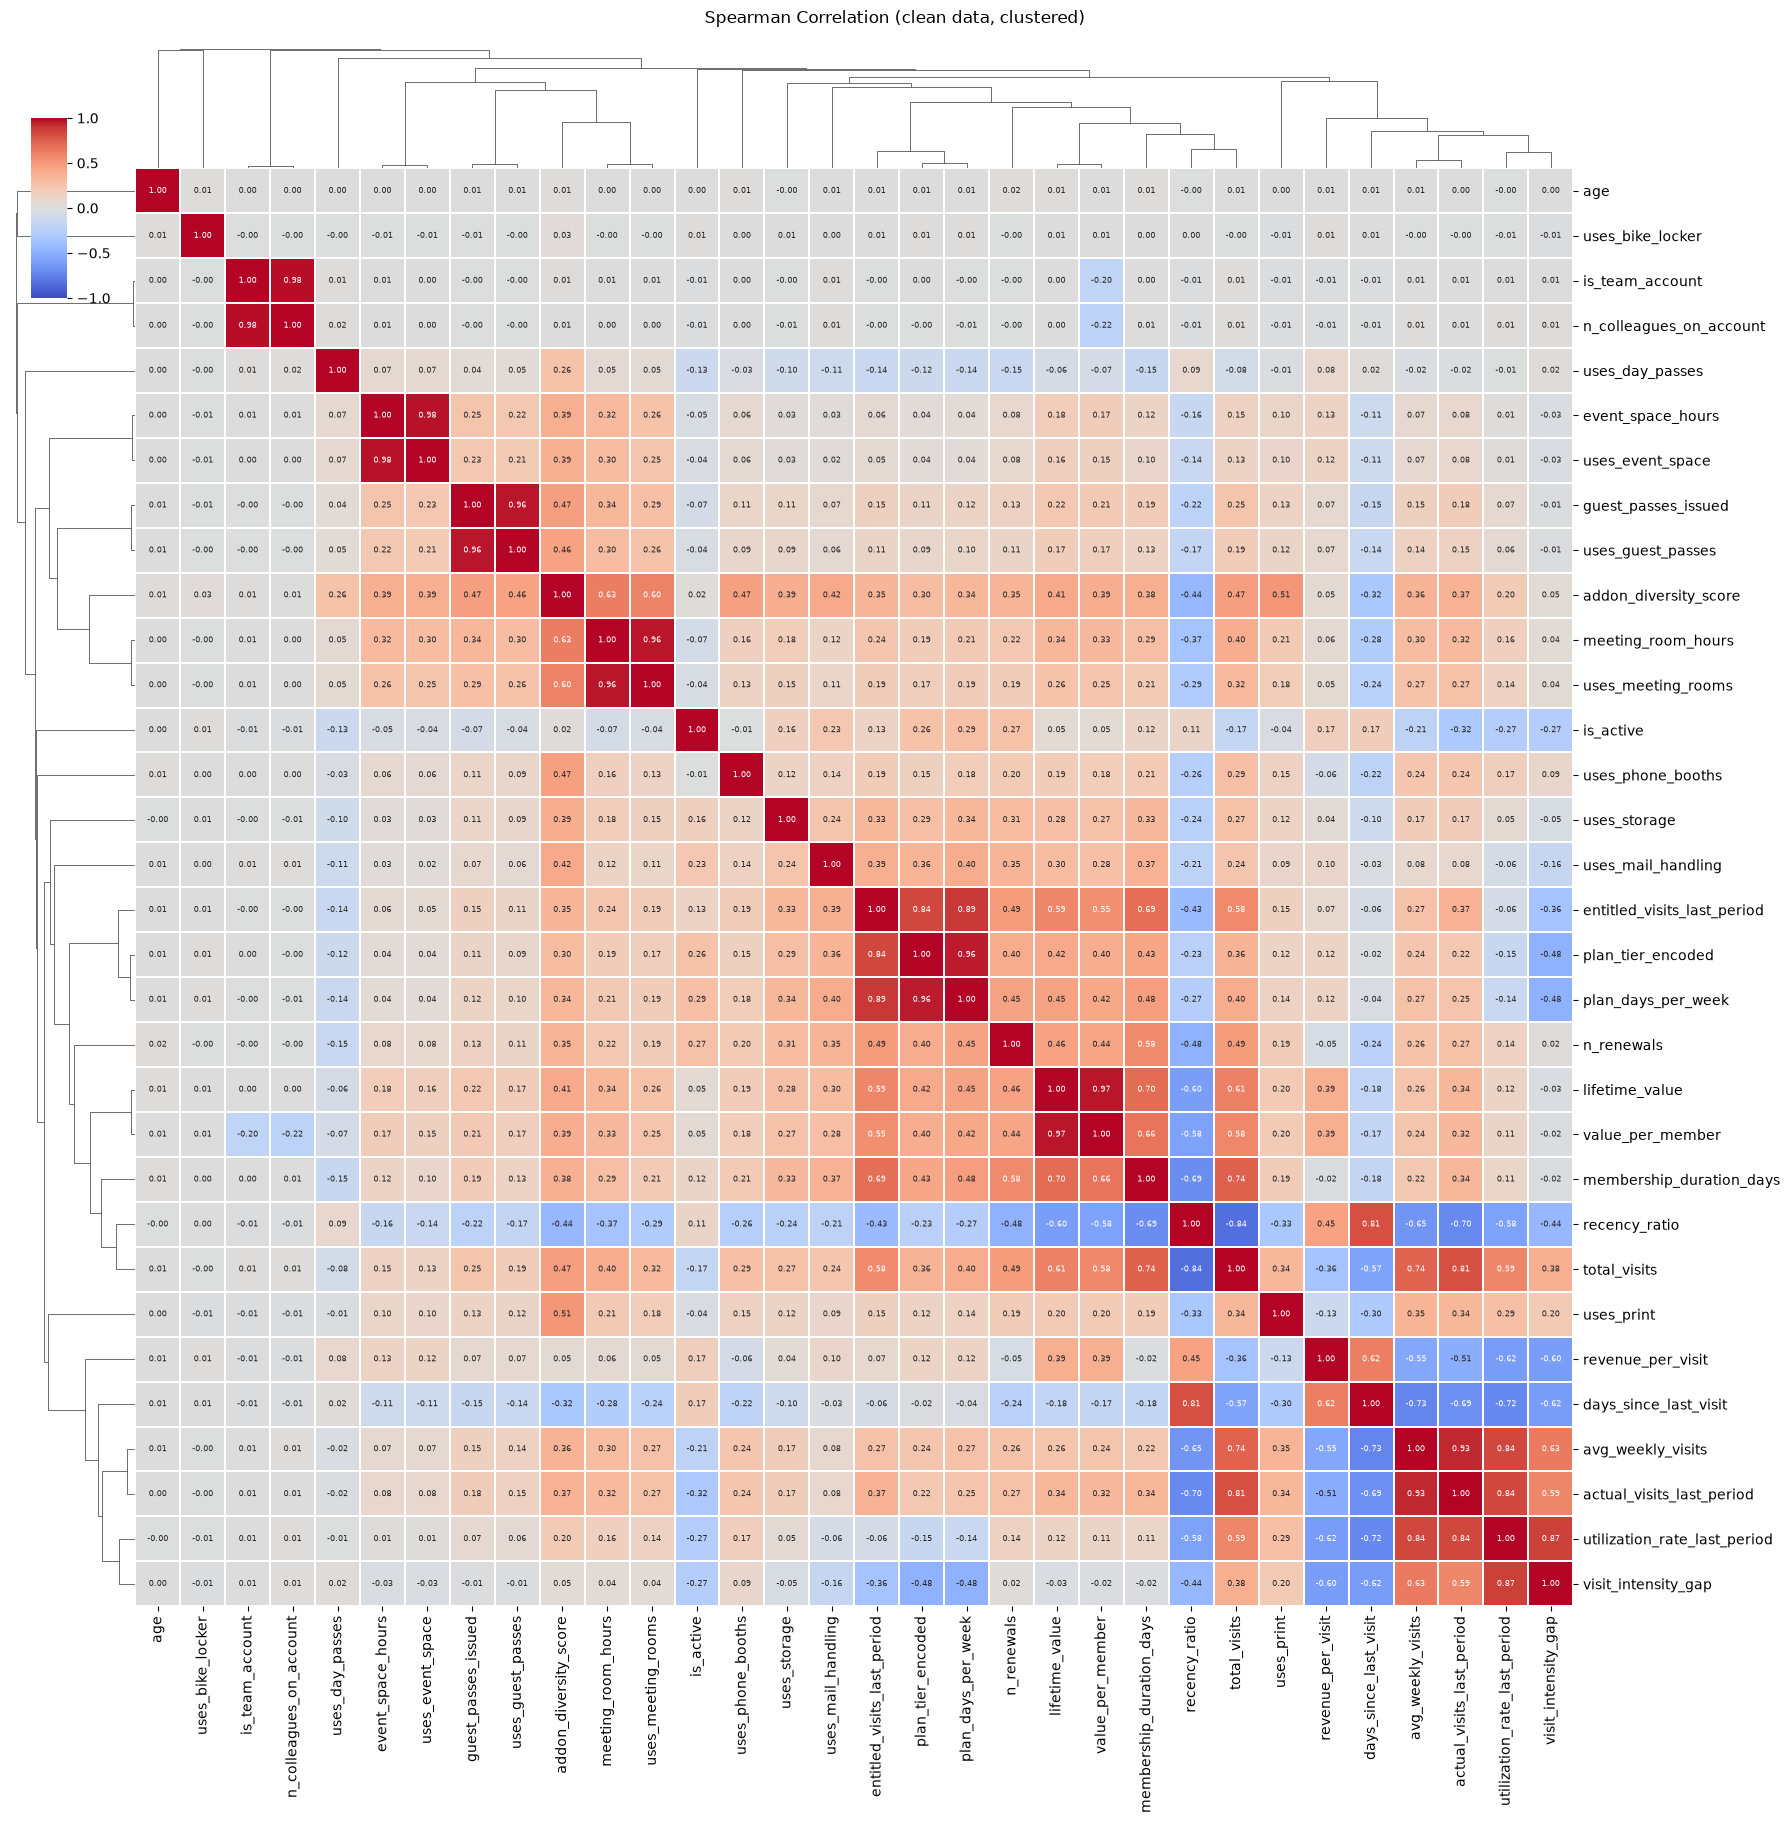

In [407]:
corr_clean = plot_clustered_spearman(df_corr, CORR_FEATURES)

In [408]:
#how much did masking the invalid values change the correlations from section 1.3.2.4?
raw_features = [c for c in CORR_FEATURES if c in df_raw.columns and c != "is_active"]
corr_raw = df_raw[raw_features].astype("float64").corr(method="spearman")

change = corr_clean.loc[raw_features, raw_features] - corr_raw
upper = np.triu(np.ones(change.shape, dtype=bool), k=1) #each pair only once

change_report = pd.DataFrame({"rho_raw": corr_raw.where(upper).stack(),
                              "rho_clean": corr_clean.loc[raw_features, raw_features].where(upper).stack(),
                              "change": change.where(upper).stack()})
change_report.reindex(change_report["change"].abs().sort_values(ascending=False).index).head(8)

rho_raw  \
days_since_last_visit lifetime_value               -0.37   
is_team_account       n_colleagues_on_account       0.89   
days_since_last_visit avg_weekly_visits            -0.66   
                      actual_visits_last_period    -0.61   
                      total_visits                 -0.51   
                      uses_print                   -0.27   
                      n_renewals                   -0.22   
                      meeting_room_hours           -0.26   

                                                 rho_clean  \
days_since_last_visit lifetime_value                 -0.18   
is_team_account       n_colleagues_on_account         0.98   
days_since_last_visit avg_weekly_visits              -0.73   
                      actual_visits_last_period      -0.69   
                      total_visits                   -0.57   
                      uses_print                     -0.30   
                      n_renewals                     -0.24   
                      meeting_room_hours             -0.28   

                                                 change  
days_since_last_visit lifetime_value               0.19  
is_team_account       n_colleagues_on_account      0.10  
days_since_last_visit avg_weekly_visits           -0.08  
                      actual_visits_last_period   -0.07  
                      total_visits                -0.06  
                      uses_print                  -0.03  
                      n_renewals                  -0.02  
                      meeting_room_hours          -0.02

The clustered heatmap shows five groups of features:
- Plan size: plan_tier_encoded, plan_days_per_week and entitled_visits_last_period (0.84 to 0.96).
- Current engagement:avg_weekly_visits, actual_visits_last_period, utilization_rate_last_period and visit_intensity_gap (0.59 to 0.93). They are all negatively related to days_since_last_visit (-0.62 to -0.73).
- Tenure and accumulated value: membership_duration_days, total_visits, lifetime_value, value_per_member and n_renewals (0.44 to 0.74), with recency_ratio as their negative mirror (-0.48 to -0.84).
- Add-ons: each flag is almost the same as its quantity (0.96 to 0.98). addon_diversity_score relates to every add-on (0.26 to 0.63), most strongly to meeting rooms and print.
- Unrelated features: age, uses_bike_locker, is_team_account and n_colleagues_on_account have |rho| ≤ 0.03 with every other feature. The only exception is value_per_member (-0.20 and -0.22), which is calculated from the account size.

About the engineered features:
- revenue_per_visit is negatively related to engagement (-0.51 to -0.62 with weekly visits, last-period visits and utilization) and positively to days_since_last_visit (0.62). A high revenue per visit comes from members who pay for a plan and barely use it, not from heavy premium users.
- value_per_member is almost identical to lifetime_value (0.97). 72% of the accounts are individual, so both features are the same for most members.
- uses_day_passes is the only add-on negatively related to plan size, renewals and tenure (-0.12 to -0.15), which points to lighter, occasional users.
- is_active is negatively related to last-period visits (-0.32) and positively to days_since_last_visit (0.17), which means active members visit less in the last period than members who left. This is counterintuitive and should be checked when the dates are cleaned.

Compared with section 1.3.2.4, masking the invalid values changes most correlations by less than 0.1. The main exception is days_since_last_visit vs lifetime_value, which goes from -0.37 to -0.18: about half of the raw correlation came from the 999 code, which coincides with zero lifetime values.

#### 1.3.4.3 Redundant feature pairs

In [409]:
def top_correlated_pairs(corr: pd.DataFrame, threshold: float = 0.8):
    """
    List the feature pairs whose absolute correlation is at least the given threshold.

    Parameters
    ----------
    corr : pd.DataFrame
        Correlation matrix.
    threshold : float, default=0.8
        Minimum absolute correlation for a pair to be reported.

    Returns
    ----------
    pairs : pd.DataFrame
        One row per pair, sorted by absolute correlation.
    """
    upper = np.triu(np.ones(corr.shape, dtype=bool), k=1) #each pair only once, no diagonal
    pairs = corr.where(upper).stack().rename("rho").reset_index()
    pairs.columns = ["feature_1", "feature_2", "rho"]
    pairs = pairs[pairs["rho"].abs() >= threshold]

    return pairs.reindex(pairs["rho"].abs().sort_values(ascending=False).index).reset_index(drop=True)

In [410]:
top_correlated_pairs(corr_clean, threshold=0.8)

,feature_1,feature_2,rho
0,is_team_account,n_colleagues_on_account,0.98
1,event_space_hours,uses_event_space,0.98
2,lifetime_value,value_per_member,0.97
3,guest_passes_issued,uses_guest_passes,0.96
4,meeting_room_hours,uses_meeting_rooms,0.96
5,plan_tier_encoded,plan_days_per_week,0.96
6,avg_weekly_visits,actual_visits_last_period,0.93
7,plan_days_per_week,entitled_visits_last_period,0.89
8,utilization_rate_last_period,visit_intensity_gap,0.87
9,actual_visits_last_period,utilization_rate_last_period,0.84


Fifteen pairs have |rho| ≥ 0.8. Grouped together, they suggest keeping one feature from each group for clustering:

| Group | Correlated features | Suggestion |
|---|---|---|
| Team account | is_team_account, n_colleagues_on_account (0.98) | Keep n_colleagues_on_account. Zero colleagues matches exactly the individual accounts, so the flag adds nothing. |
| Add-on flag vs quantity | uses_event_space / event_space_hours (0.98), uses_guest_passes / guest_passes_issued (0.96), uses_meeting_rooms / meeting_room_hours (0.96) | Keep either the flag or the quantity, not both. The quantity is more informative, since zero means "not used". |
| Value | lifetime_value, value_per_member (0.97) | Keep lifetime_value. value_per_member only differs for team accounts (28%). |
| Plan size | plan_tier_encoded, plan_days_per_week (0.96), entitled_visits_last_period (0.84 to 0.89) | Keep one, preferably plan_tier_encoded or plan_days_per_week. entitled_visits_last_period depends more on tenure (0.69 against 0.43 to 0.48). |
| Current engagement | avg_weekly_visits, actual_visits_last_period (0.93), utilization_rate_last_period (0.84), visit_intensity_gap (0.87 with utilization) | Keep one intensity feature. If plan size is also used, utilization_rate_last_period avoids counting plan size twice, since it is already relative to the plan. |
| Recency and tenure | recency_ratio with total_visits (-0.84) and days_since_last_visit (0.81) | recency_ratio mixes recency and tenure. Using days_since_last_visit and tenure separately is easier to interpret (see 1.3.4.4). |
| Accumulated visits | total_visits, actual_visits_last_period (0.81) | total_visits is mostly a tenure effect (see 1.3.4.4). |

The 0.8 threshold is a rule of thumb. The final selection will be done in the clustering phase, together with the choice of perspectives.

#### 1.3.4.4 Controlling for tenure (partial correlation)

Total visits, lifetime value, renewals and the "ever used" add-on flags all accumulate over time, so two of them can look correlated just because both grow with tenure. To separate this effect, we compute the partial Spearman correlation of each pair controlling for membership_duration_days:

$$\rho_{xy \cdot z} = \frac{\rho_{xy} - \rho_{xz}\,\rho_{yz}}{\sqrt{(1-\rho_{xz}^2)(1-\rho_{yz}^2)}}$$

In [411]:
def partial_spearman(corr: pd.DataFrame, control: str):
    """
    Compute partial correlations for every pair of features, controlling for one feature.

    Parameters
    ----------
    corr : pd.DataFrame
        Spearman correlation matrix that includes the control feature.
    control : str
        Feature to control for.

    Returns
    ----------
    partial : pd.DataFrame
        Partial correlation matrix, without the control feature.

    Notes
    -----
    - Uses the first-order partial correlation formula on the given matrix. Since the matrix
      uses pairwise complete observations, the number of rows behind each value can differ slightly.
    """
    r = corr.drop(index=control, columns=control)
    rz = corr[control].drop(control) #correlation of each feature with the control

    partial = (r - np.outer(rz, rz)) / np.sqrt(np.outer(1 - rz**2, 1 - rz**2))
    return partial

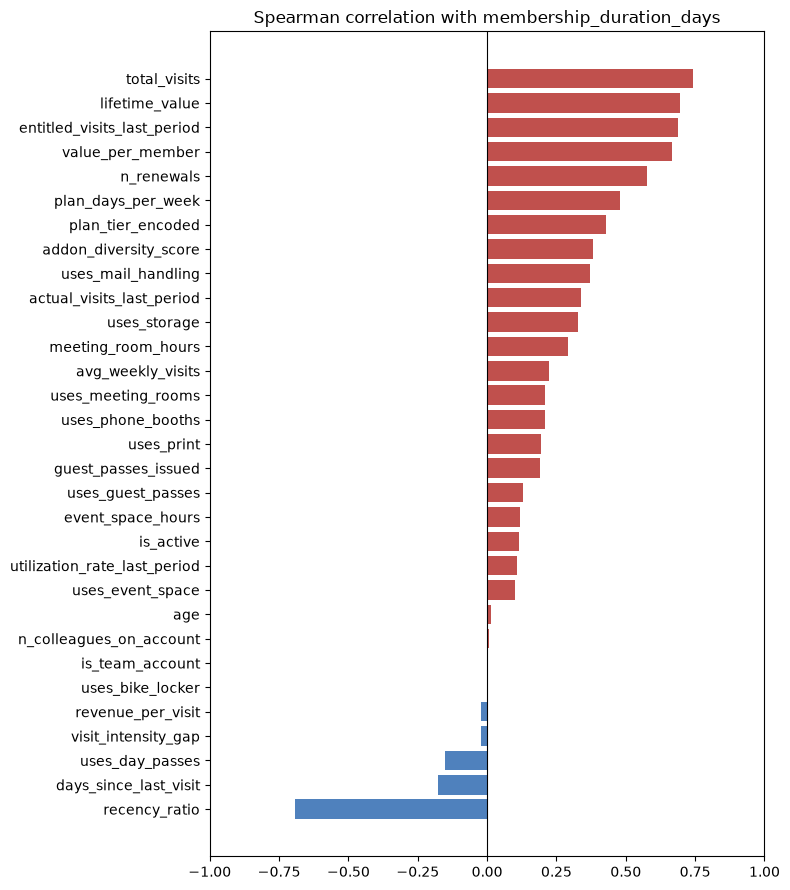

In [412]:
tenure = "membership_duration_days"

#correlation of every feature with tenure
tenure_corr = corr_clean[tenure].drop(tenure).sort_values()
plt.figure(figsize=(8, 9))
plt.barh(tenure_corr.index, tenure_corr.values, color=np.where(tenure_corr > 0, "#c0504d", "#4f81bd"))
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Spearman correlation with membership_duration_days")
plt.xlim(-1, 1)
plt.tight_layout()
plt.show()

In [413]:
corr_partial = partial_spearman(corr_clean, tenure)

upper = np.triu(np.ones(corr_partial.shape, dtype=bool), k=1)
tenure_report = pd.DataFrame({"rho": corr_clean.drop(index=tenure, columns=tenure).where(upper).stack(),
                              "rho_partial": corr_partial.where(upper).stack()})
tenure_report["abs_change"] = tenure_report["rho_partial"].abs() - tenure_report["rho"].abs()

print("Pairs that weaken the most once tenure is controlled for:")
display(tenure_report.sort_values("abs_change").head(15))

print("Pairs that strengthen the most once tenure is controlled for:")
display(tenure_report.sort_values("abs_change", ascending=False).head(8))

Pairs that weaken the most once tenure is controlled for:


rho  \
total_visits                entitled_visits_last_period  0.58   
                            lifetime_value               0.61   
                            value_per_member             0.58   
entitled_visits_last_period lifetime_value               0.59   
                            value_per_member             0.55   
total_visits                n_renewals                   0.49   
recency_ratio               lifetime_value              -0.60   
n_renewals                  lifetime_value               0.46   
recency_ratio               value_per_member            -0.58   
n_renewals                  value_per_member             0.44   
recency_ratio               n_renewals                  -0.48   
                            entitled_visits_last_period -0.43   
entitled_visits_last_period n_renewals                   0.49   
plan_days_per_week          total_visits                 0.40   
plan_tier_encoded           total_visits                 0.36   

                                                         rho_partial  \
total_visits                entitled_visits_last_period         0.14   
                            lifetime_value                      0.19   
                            value_per_member                    0.18   
entitled_visits_last_period lifetime_value                      0.21   
                            value_per_member                    0.17   
total_visits                n_renewals                          0.11   
recency_ratio               lifetime_value                     -0.24   
n_renewals                  lifetime_value                      0.10   
recency_ratio               value_per_member                   -0.22   
n_renewals                  value_per_member                    0.09   
recency_ratio               n_renewals                         -0.13   
                            entitled_visits_last_period         0.09   
entitled_visits_last_period n_renewals                          0.16   
plan_days_per_week          total_visits                        0.08   
plan_tier_encoded           total_visits                        0.07   

                                                         abs_change  
total_visits                entitled_visits_last_period       -0.44  
                            lifetime_value                    -0.42  
                            value_per_member                  -0.40  
entitled_visits_last_period lifetime_value                    -0.38  
                            value_per_member                  -0.38  
total_visits                n_renewals                        -0.38  
recency_ratio               lifetime_value                    -0.37  
n_renewals                  lifetime_value                    -0.36  
recency_ratio               value_per_member                  -0.36  
n_renewals                  value_per_member                  -0.35  
recency_ratio               n_renewals                        -0.34  
                            entitled_visits_last_period       -0.34  
entitled_visits_last_period n_renewals                        -0.33  
plan_days_per_week          total_visits                      -0.32  
plan_tier_encoded           total_visits                      -0.29

Pairs that strengthen the most once tenure is controlled for:


,,rho,rho_partial,abs_change
total_visits,visit_intensity_gap,0.38,0.60,0.21
is_active,total_visits,-0.17,-0.38,0.21
recency_ratio,visit_intensity_gap,-0.44,-0.63,0.19
total_visits,utilization_rate_last_period,0.59,0.77,0.18
lifetime_value,revenue_per_visit,0.39,0.56,0.17
total_visits,revenue_per_visit,-0.36,-0.52,0.16
is_active,recency_ratio,0.11,0.27,0.16
days_since_last_visit,recency_ratio,0.81,0.96,0.16


- Tenure is strongly related to the cumulative features: total_visits (0.74), lifetime_value (0.70), entitled_visits_last_period (0.69) and n_renewals (0.58). Rates are much less affected: avg_weekly_visits (0.22), utilization_rate_last_period (0.11) and revenue_per_visit (-0.02).
- Once tenure is controlled for, the links between value, visits and renewals become much weaker: total_visits vs lifetime_value drops from 0.61 to 0.19, n_renewals vs lifetime_value from 0.46 to 0.10, entitled_visits_last_period vs lifetime_value from 0.59 to 0.21, and plan_days_per_week vs total_visits from 0.40 to 0.08. Most of what connected these features in section 1.3.2.4 was time as a member, not a distinct behavior.
- Some relationships become stronger: total_visits vs utilization_rate_last_period goes from 0.59 to 0.77, total_visits vs visit_intensity_gap from 0.38 to 0.60, and lifetime_value vs revenue_per_visit from 0.39 to 0.56. Among members with the same tenure, those who visit more are the ones who use their plan more.
- days_since_last_visit vs recency_ratio rises to 0.96, so once tenure is known, recency_ratio adds almost no new information.
- For clustering, cumulative features (total_visits, lifetime_value, n_renewals) should not be used as they are. For value-based segmentation, a rate such as lifetime value per month of membership would describe economic contribution without mixing it with tenure.

#### 1.3.4.5 Categorical associations

Spearman cannot be used with nominal features, so we use two other measures, both between 0 (no association) and 1 (perfect association):
- Cramér's V* (bias-corrected) between pairs of categorical features.
- Correlation ratio (η) between a categorical and a numerical feature. It measures how much of the variance of the numerical feature is explained by the categories. We compute it on the ranks of the numerical feature, to be consistent with Spearman and robust to outliers.

Missing categories are left out of each calculation.

In [414]:
def cramers_v(x: pd.Series, y: pd.Series):
    """
    Bias-corrected Cramér's V between two categorical features.

    Parameters
    ----------
    x, y : pd.Series
        Categorical features.

    Returns
    ----------
    float
        Association between 0 and 1.
    """
    table = pd.crosstab(x, y) #rows with missing values are dropped by crosstab
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    n = table.values.sum()
    r, k = table.shape

    #bias correction (Bergsma, 2013)
    phi2 = max(0, chi2 / n - (k - 1) * (r - 1) / (n - 1))
    r_corr = r - (r - 1) ** 2 / (n - 1)
    k_corr = k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(k_corr - 1, r_corr - 1))


def correlation_ratio(categories: pd.Series, values: pd.Series):
    """
    Correlation ratio (eta) between a categorical and a numerical feature.

    Parameters
    ----------
    categories : pd.Series
        Categorical feature.
    values : pd.Series
        Numerical feature.

    Returns
    ----------
    float
        Association between 0 and 1.
    """
    d = pd.DataFrame({"cat": categories, "y": values}).dropna()
    mean = d["y"].mean()
    groups = d.groupby("cat")["y"]

    between = (groups.count() * (groups.mean() - mean) ** 2).sum() #variance between categories
    total = ((d["y"] - mean) ** 2).sum()
    return np.sqrt(between / total)

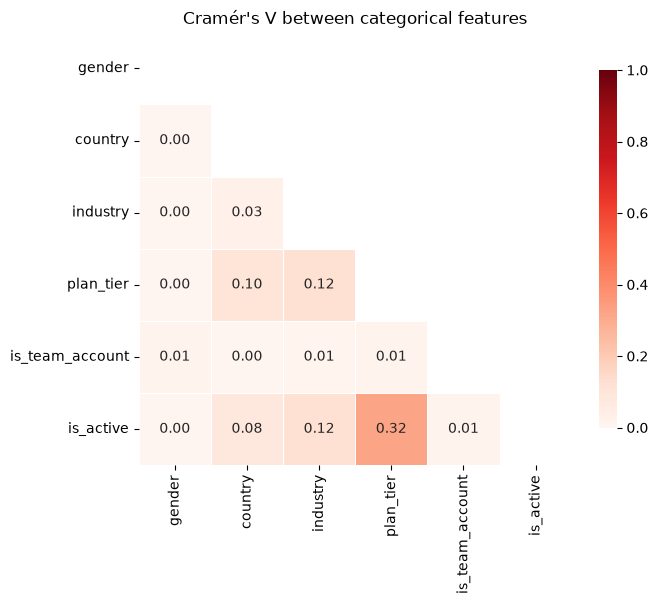

In [415]:
CAT_FEATURES = ["gender", "country", "industry", "plan_tier", "is_team_account", "is_active"]

cramers = pd.DataFrame([[cramers_v(df_corr[a], df_corr[b]) for b in CAT_FEATURES] for a in CAT_FEATURES],
                       index=CAT_FEATURES, columns=CAT_FEATURES)

plt.figure(figsize=(7, 6))
sns.heatmap(cramers, mask=np.triu(np.ones_like(cramers, dtype=bool)), annot=True, fmt=".2f",
            cmap="Reds", vmin=0, vmax=1, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Cramér's V between categorical features")
plt.tight_layout()
plt.show()

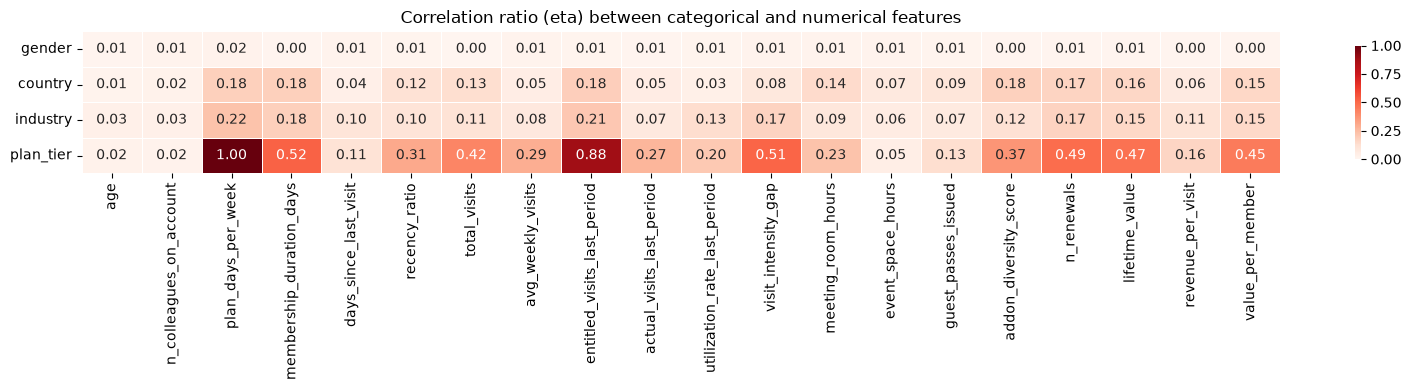

In [416]:
#plan_tier_encoded and the add-on flags are left out: the first is plan_tier itself and the flags are categorical
eta_features = [c for c in CORR_FEATURES if c not in ["plan_tier_encoded", "is_team_account", "is_active"] and not c.startswith("uses_")]

eta = pd.DataFrame({cat: {num: correlation_ratio(df_corr[cat], df_corr[num].rank()) for num in eta_features}
                    for cat in ["gender", "country", "industry", "plan_tier"]}).T

plt.figure(figsize=(16, 4))
sns.heatmap(eta, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title("Correlation ratio (eta) between categorical and numerical features")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

- gender is not associated with anything (Cramér's V ≤ 0.01, η ≤ 0.02). It is not useful to separate segments, only to describe them.
- country and industry are almost independent of each other (V = 0.03) and only weakly related to the numerical features (η ≤ 0.22). The highest values are with plan size and tenure: industry with plan_days_per_week (0.22) and entitled visits (0.21), country with plan_days_per_week, tenure and entitled visits (0.18).
- plan_tier is the most informative categorical feature. It practically defines plan_days_per_week (η = 1.00) and entitled_visits_last_period (0.88), and is moderately related to tenure (0.52), visit_intensity_gap (0.51), n_renewals (0.49) and lifetime_value (0.47). It is also the categorical feature most associated with is_active (V = 0.32), which matches the higher retention of larger plans found in the bivariate analysis.
- is_team_account is not associated with any categorical feature (V ≤ 0.01).

#### 1.3.4.6 Key takeaways for clustering

1. Data quality: the sentinel codes and impossible values only change most correlations slightly, but they distort the recency relationships. They must be treated before clustering.
2. Redundancy: the 32 features analysed fall into a few strongly correlated groups (team account, add-on flags and quantities, value, plan size, current engagement). Keeping one feature from each group avoids giving the same information extra weight in distance-based algorithms.
3. Tenure: time as a member is the main hidden driver behind the cumulative features. Rates per unit of time should be preferred to totals.
4. Perspectives: the groups found here match the segmentation perspectives of the project: value (lifetime value per month, plan tier, renewals), behavior (visit intensity, utilization, recency) and service use (add-ons).
5. Demographics: age, gender, country, industry and team account are barely related to behavior or value. They are better used to describe the final clusters than to build them.

### 1.3.4 Missigness Exploration

#### 1.3.4.1 Categorical → Categorical + Boolean

In [ ]:
def plot_all_categorical_pct_dif(df: pd.DataFrame, df_2: pd.DataFrame, exclude: list = None, big: bool = False, n: int = 10):
    """
    Plot the raw relative percentage change of category proportions from df to df_2.
    Formula: ((prop_df2 - prop_df) / prop_df) * 100
    Positive values represent growth; negative values represent drops.
    """
    cols = []
    
    #select object/string columns
    string_cols = df.select_dtypes(include=["object", "string", "category","bool"]).columns
    
    for c in string_cols:
        if exclude is None or c not in exclude:
            if df[c].isna().sum() < len(df):
                cols.append(c)

    if not cols:
        print("No valid categorical columns to plot.")
        return
    
    n_cols = 1 if big else 4
    n_rows = math.ceil(len(cols) / n_cols)
    
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, max(4, n_rows * 4)))
    axes = np.array(axes).flatten()
    
    for i, col in enumerate(cols):
        ax = axes[i]
        
        # Calculate base proportions (0.0 to 1.0)
        prop1 = df[col].fillna("NULL").value_counts(normalize=True)
        prop2 = df_2[col].fillna("NULL").value_counts(normalize=True)

        # Align series across all unique categories
        all_categories = prop1.index.union(prop2.index)
        prop1 = prop1.reindex(all_categories, fill_value=0)
        prop2 = prop2.reindex(all_categories, fill_value=0)
        
        # Calculate relative percentage change
        rel_change = np.zeros(len(all_categories))
        valid_mask = prop1 > 0
        
        # Standard relative change calculation
        rel_change[valid_mask] = ((prop2[valid_mask] - prop1[valid_mask]) / prop1[valid_mask]) * 100
        
        # Handle the edge case: 0% in df -> X% in df_2 (infinite relative growth)
        rel_change[~valid_mask & (prop2 > 0)] = 999.0  # Cap to keep scaling readable
        
        # Build summary DataFrame
        counts_df = pd.DataFrame({
            col: all_categories,
            "percentage": rel_change,
            "abs_percentage": np.abs(rel_change)
        })
        
        # Still sort by absolute magnitude so the most volatile shifts (positive or negative) rise to the top
        counts_df = counts_df.sort_values(by="abs_percentage", ascending=False).reset_index(drop=True)

        n_unique = len(counts_df)
        high_cardinality = n_unique > n
        
        if high_cardinality:
            counts_df = counts_df.head(n)
            
        # Plot the RAW relative change (can go negative)
        sns.barplot(
            data=counts_df,
            x=col,
            y="percentage",
            ax=ax
        )
        
        wrapped_labels = [shorten(str(lbl), width=25, placeholder="…") for lbl in counts_df[col]]
        ax.set_xticks(range(len(counts_df)))
        ax.set_xticklabels(wrapped_labels, rotation=90, ha="center", fontsize=7)

        # Apply specific visual signaling colors based on direction
        for bar, label, pct in zip(ax.patches, counts_df[col].tolist(), counts_df["percentage"].tolist()):
            if label == "NULL":
                bar.set_facecolor("#d9534f")  # Soft Red for missing values
            elif pct == 999.0:
                bar.set_facecolor("#ff7f0e")  # Orange for complete new categories
            elif pct > 0:
                bar.set_facecolor("#2ca02c")  # Green for growth
            else:
                bar.set_facecolor("#4C8BE2")  # Blue for drops (-100% hits here perfectly)

        #add a clear zero baseline reference line
        ax.axhline(0, color="#333333", linewidth=0.8, linestyle="-")

        ax.set_axisbelow(True)
        ax.spines[["top", "right"]].set_visible(False)

        title = f"{col}  (top {n} shifts of {n_unique})" if high_cardinality else f"{col}  ({n_unique} categories)"
        ax.set_title(title, fontsize=10, fontweight='bold')
        ax.set_xlabel("")
        ax.set_ylabel("Relative Change (%)", fontsize=9)
        ax.tick_params(axis='x', labelsize=7, labelrotation=90)
        ax.tick_params(axis='y', labelsize=7)

    for j in range(len(cols), len(axes)):
        axes[j].set_visible(False)
        
    plt.tight_layout()
    plt.subplots_adjust(
        bottom=min(0.35, 0.05 * n_rows),
        top=0.95,
        hspace=0.8
    )
    plt.show()

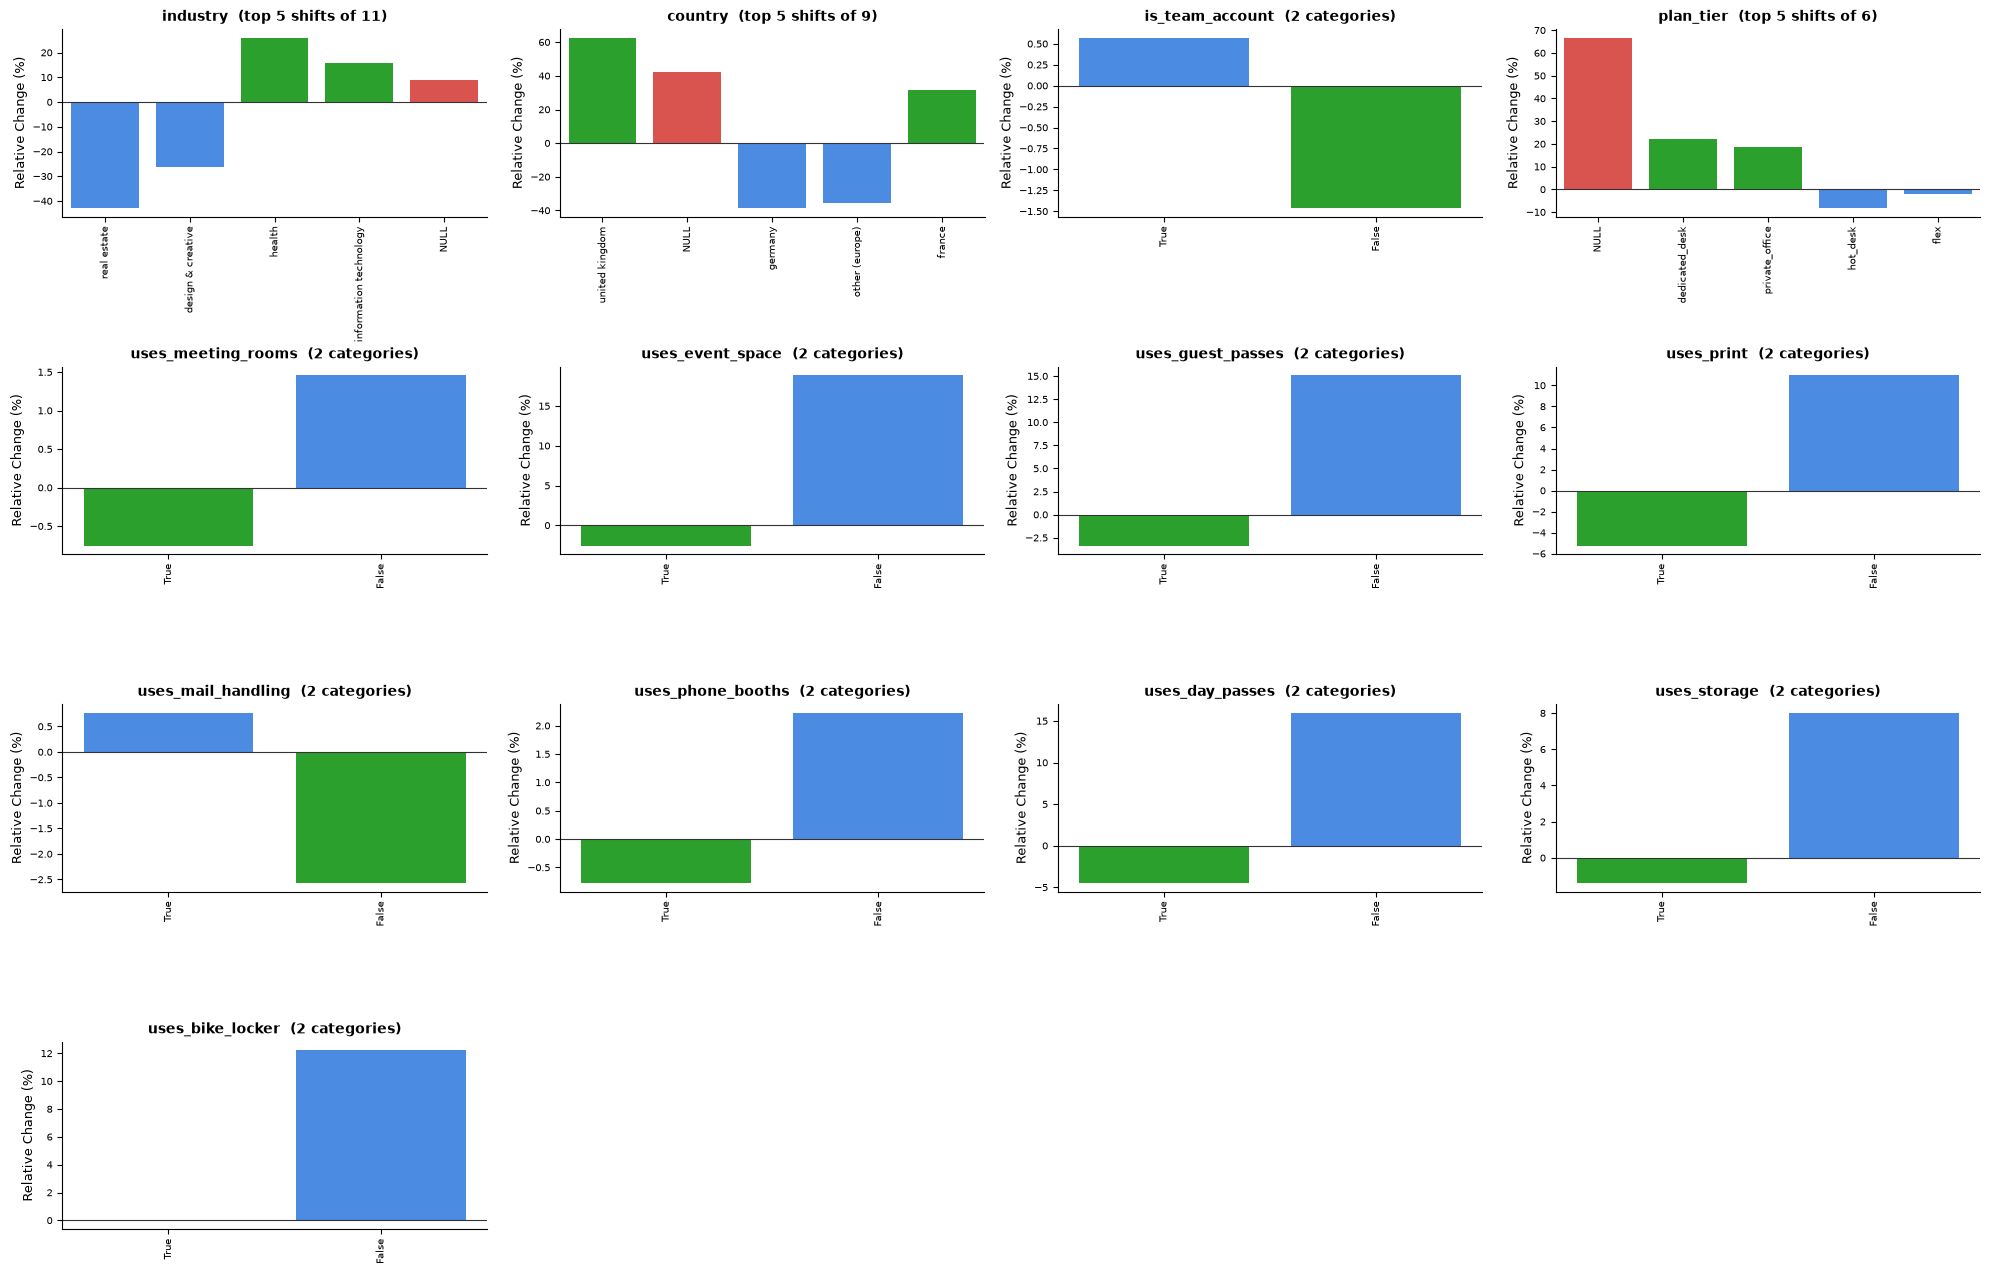

In [464]:
plot_all_categorical_pct_dif(df_raw,df_raw[df_raw["gender"].isna()],n=5,exclude=["member_id","gender"]) #compare df to df when gender is na.

Missing gender is associated with substantial differences in industry and country, while the Boolean features show comparatively small shifts. The largest Boolean differences are observed for uses_event_space, uses_guest_passes, and uses_day_passes, although these remain relatively modest compared with the categorical differences.

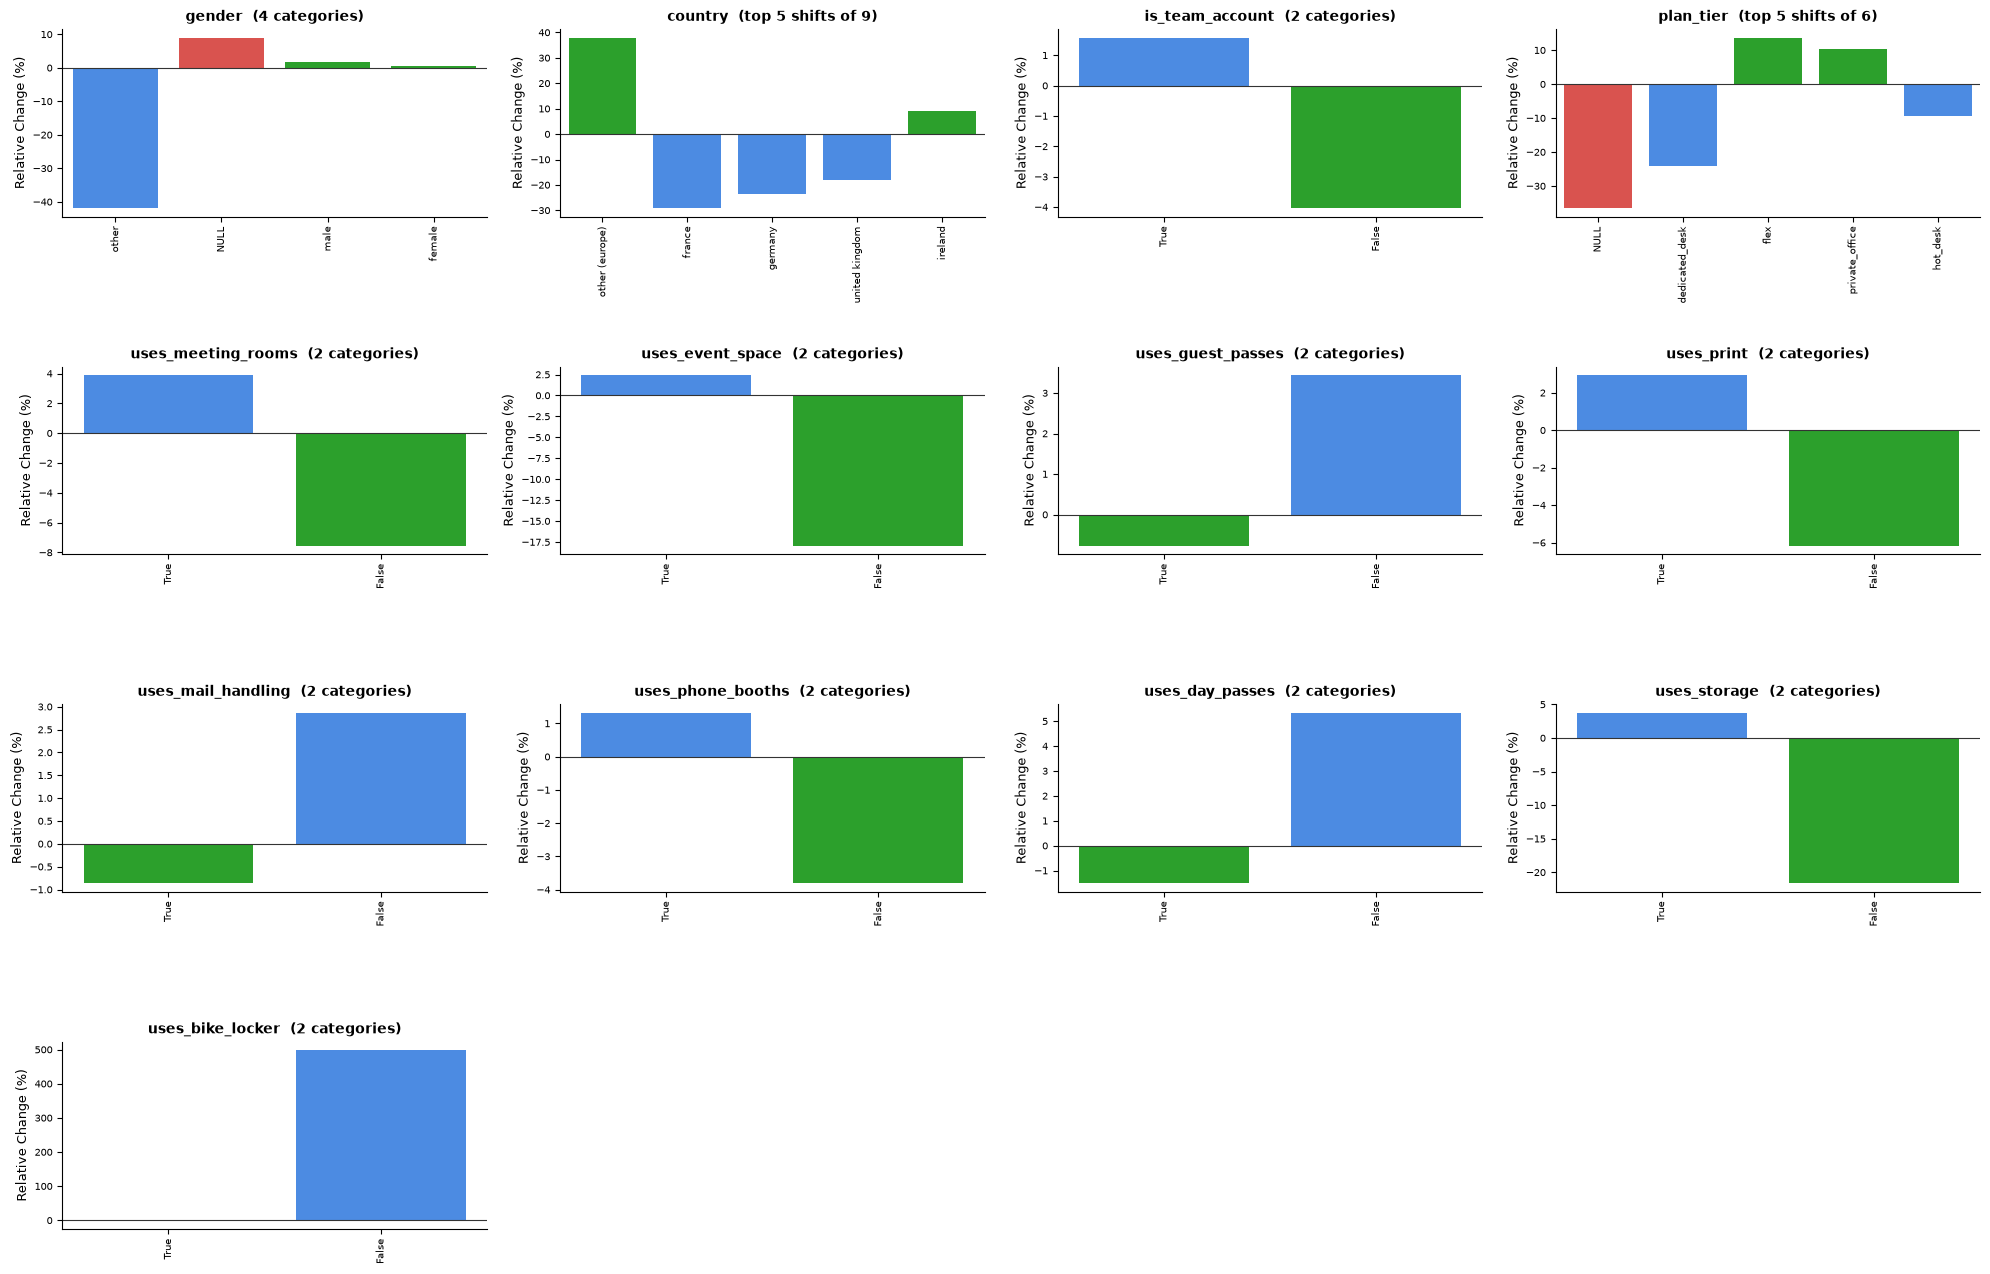

In [465]:
plot_all_categorical_pct_dif(df_raw,df_raw[df_raw["industry"].isna()],n=5,exclude=["member_id","industry"]) #compare df to df when industry is na.

Missing industry is associated with substantial differences in country and plan_tier, while most Boolean features show relatively small shifts. The exception is uses_bike_locker, which shows a very large relative increase and should be interpreted cautiously due to its small baseline proportion

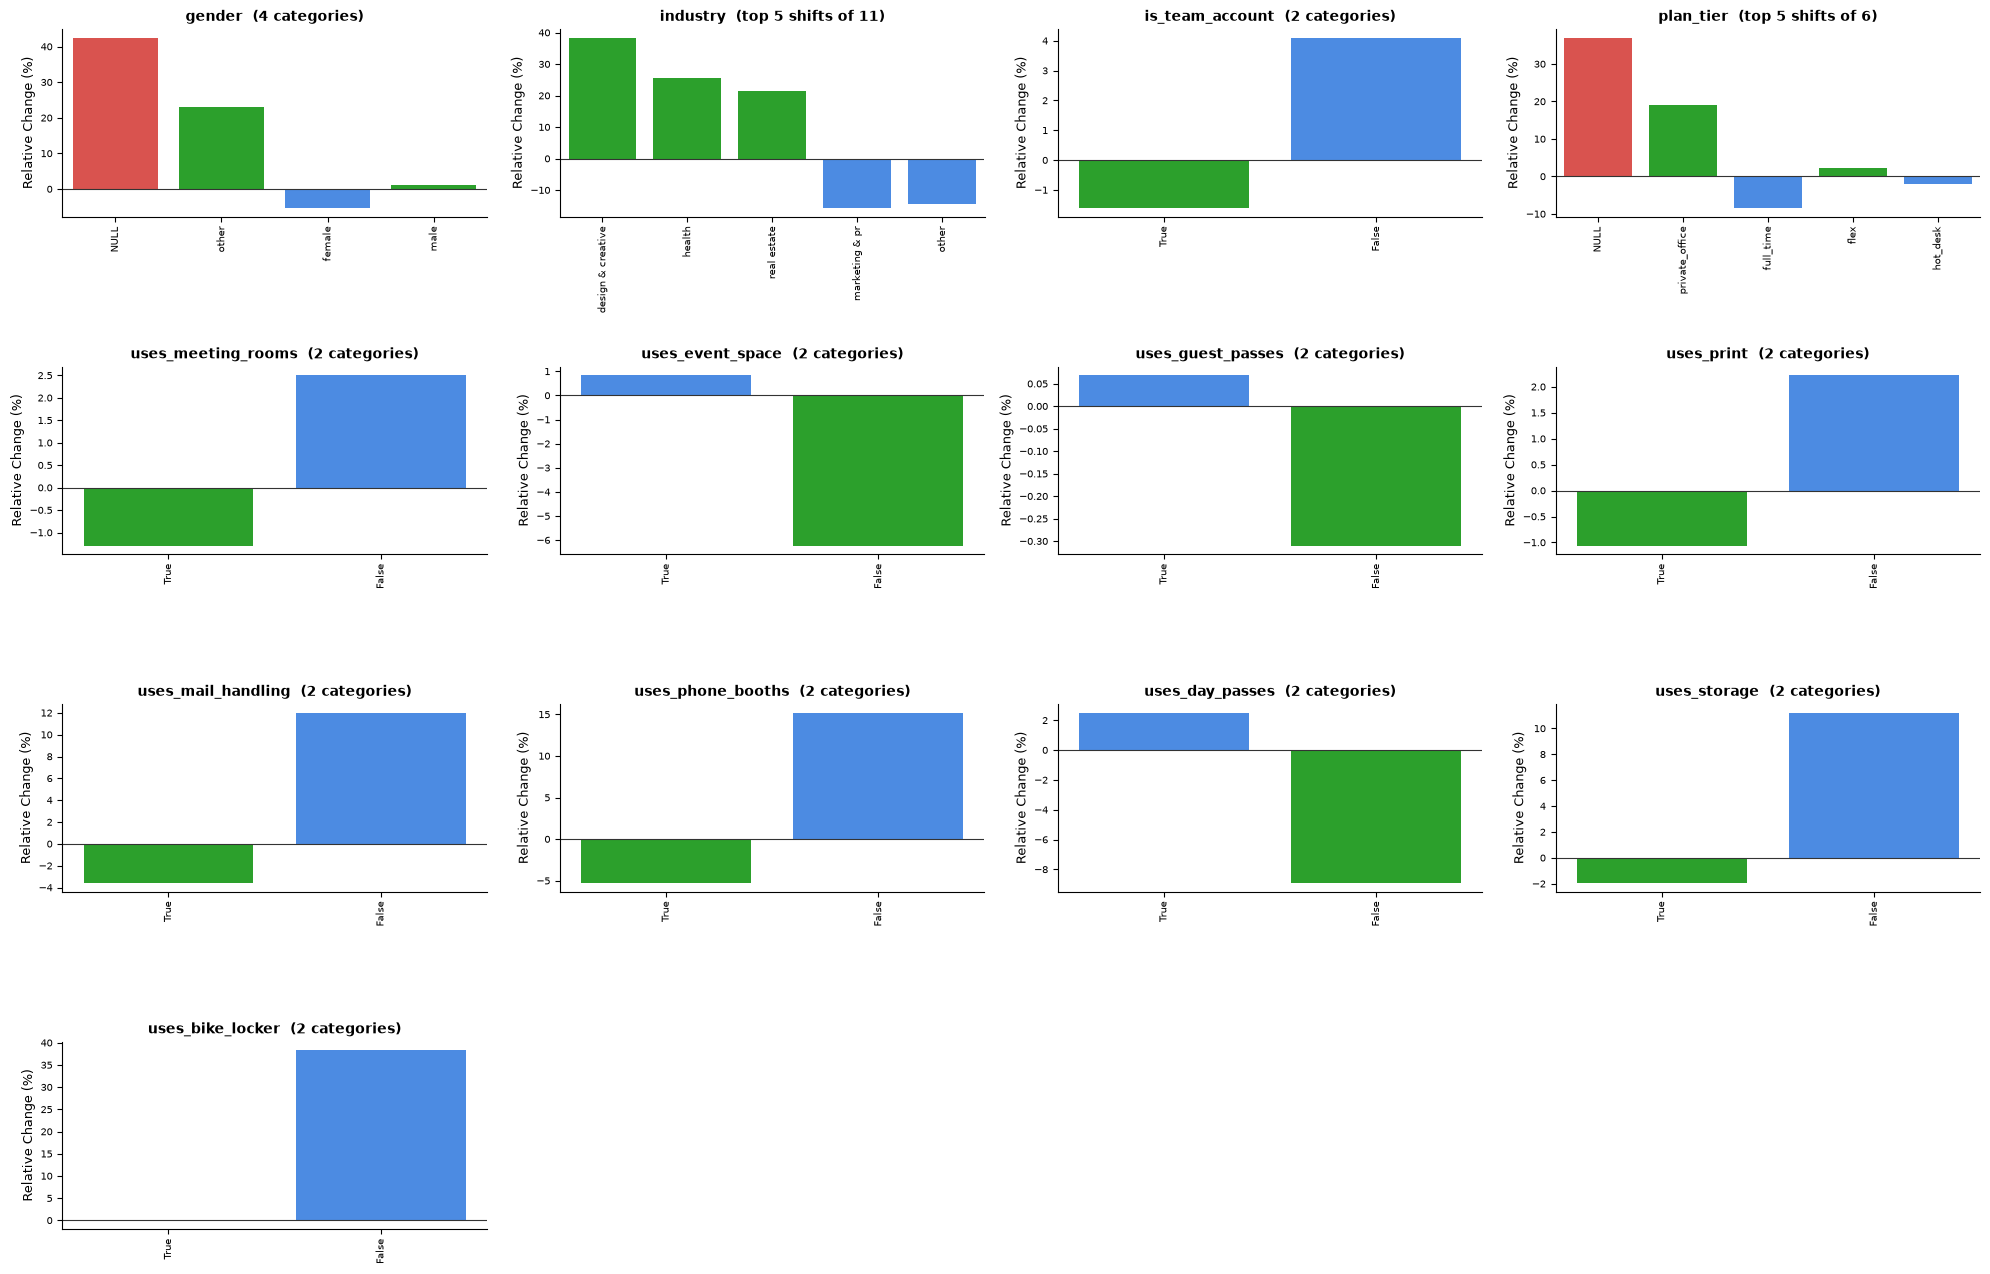

In [466]:
plot_all_categorical_pct_dif(df_raw,df_raw[df_raw["country"].isna()],n=5,exclude=["member_id","country"]) #compare df to country when gender is na.

null gender and null plan tier also stongly associated with missing NULL.

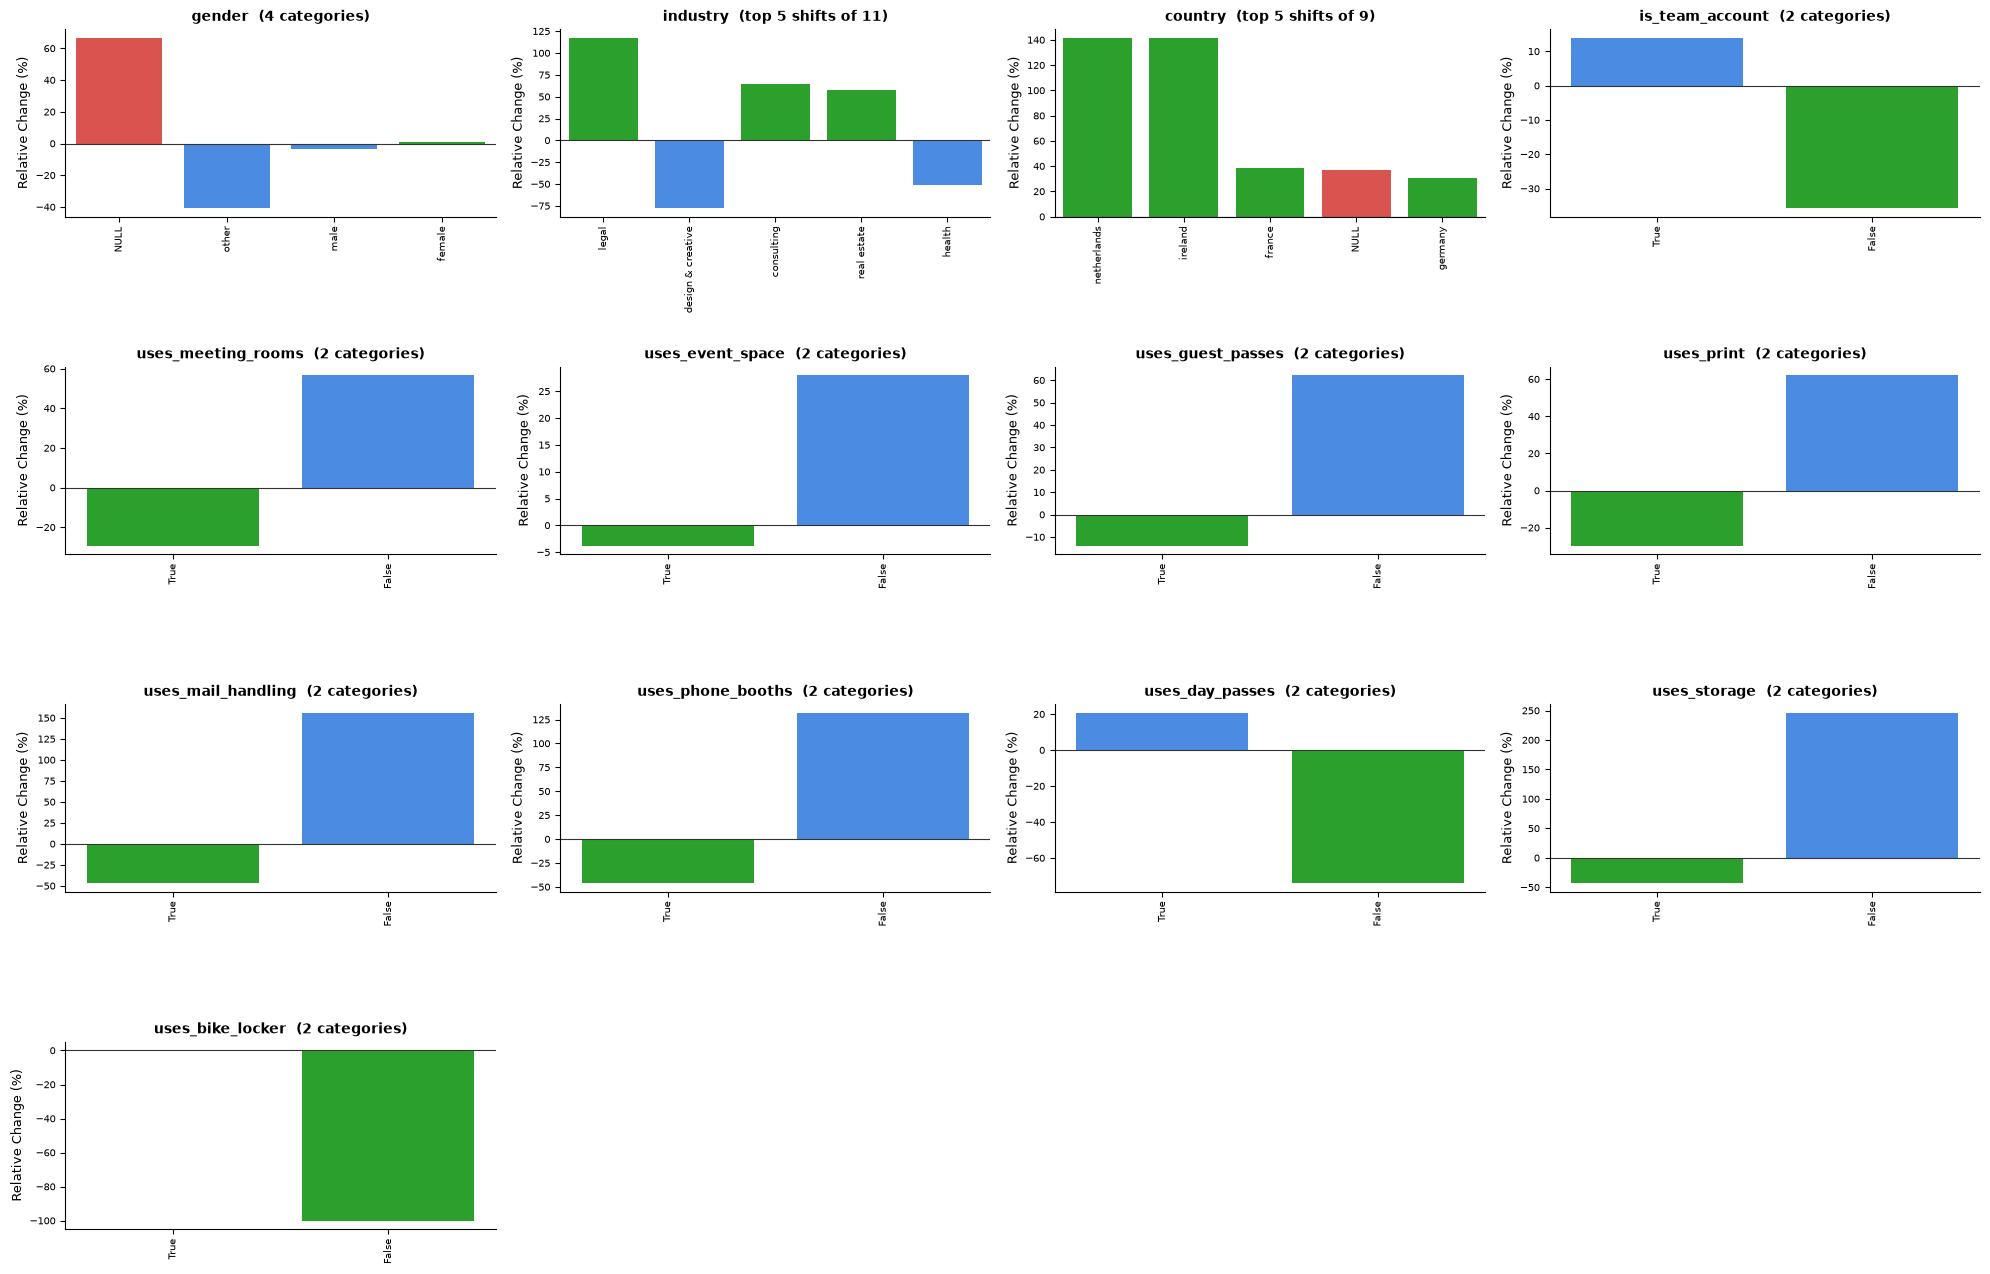

In [467]:
plot_all_categorical_pct_dif(df_raw,df_raw[df_raw["plan_tier"].isna()],n=5,exclude=["member_id","plan_tier"]) #compare df to country when gender is na.

Missing plan_tier is strongly associated with several categorical and Boolean features, particularly industry, country, and uses_storage, with substantial shifts across their categories.
This suggests that plan_tier missingness is unlikely to be MCAR and is systematically related to other customer characteristics.

In [460]:
def plot_missing_categorical_vs_numerical(df: pd.DataFrame,categorical_cols: list[str] = None, exclude: list[str] = None):
    """
    Plot standardized median differences of numerical features
    for observations with missing categorical values.

    Each row represents a categorical variable with missing values,
    and each column represents a numerical feature.
    """
    
    #get all object,string and category into list.
    exclude = exclude or []
    if categorical_cols is None:
        categorical_cols = df.select_dtypes(
            include=["object", "string", "category"]
        ).columns.tolist()

    categorical_cols = [
        c for c in categorical_cols
        if c not in exclude and df[c].isna().any()]

    #get numerical cols
    numerical_cols = [
        c for c in df.select_dtypes(include="number").columns
        if c not in exclude
    ]

    if not categorical_cols or not numerical_cols:
        print("No valid categorical or numerical columns found.")
        return

    results = pd.DataFrame(
        index=categorical_cols,
        columns=numerical_cols,
        dtype=float
    )

    for cat_col in categorical_cols:

        missing_df = df[df[cat_col].isna()]

        for num_col in numerical_cols:
            #now we calculate median values of numerical feats
            median_full = df[num_col].median()
            median_missing = missing_df[num_col].median()

            q1 = df[num_col].quantile(0.25)
            q3 = df[num_col].quantile(0.75)
            iqr = q3 - q1

            if iqr == 0 or pd.isna(iqr):
                results.loc[cat_col, num_col] = 0
            else:
                results.loc[cat_col, num_col] = (
                    (median_missing - median_full) / iqr
                )

    plt.figure(
        figsize=(
            max(14, len(numerical_cols) * 1.2),
            max(5, len(categorical_cols) * 0.8)
        )
    )

    #only show if 1 deviation greater difference in absolute
    results = results.where(results.abs() > 1)

    #now we plot the heatmap
    sns.heatmap(
        results,
        center=0,
        cmap="RdBu_r",
        annot=True,
        fmt=".2f",
        linewidths=0.5
    )

    plt.title("Standardized Median Differences for Missing Categorical Variables",fontsize=13,fontweight="bold")
    plt.xlabel("Numerical Features", fontsize=11)
    plt.ylabel("")
    plt.yticks(rotation=0,fontsize=11)
    plt.xticks(rotation=90,ha="right",fontsize=9)

    plt.tight_layout()
    plt.show()

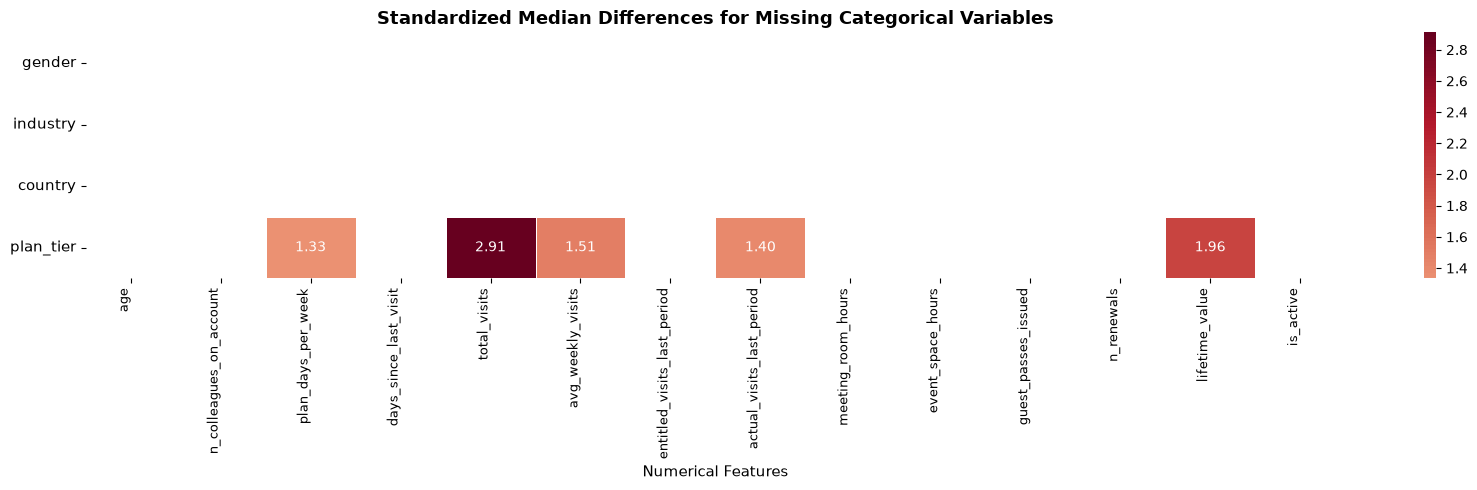

In [453]:
plot_missing_categorical_vs_numerical(df_raw,exclude=["member_id"])

Missing plan_tier shows the strongest numerical differences, particularly higher total_visits, avg_weekly_visits, actual_visits_last_period, and lifetime_value.

#### 1.3.4.1  Numerical → Numerical 

In [468]:
def plot_missing_numerical_vs_numerical(df: pd.DataFrame,numerical_cols: list[str] = None,exclude: list[str] = None):
    """
    Plot standardized median differences of numerical features
    for observations with missing numerical values.

    Each row represents a numerical variable with missing values,
    and each column represents another numerical feature.
    """

    exclude = exclude or []
    #get all numerical cols
    if numerical_cols is None:
        numerical_cols = df.select_dtypes(
            include="number"
        ).columns.tolist()

    numerical_cols = [
        c for c in numerical_cols
        if c not in exclude and df[c].isna().any()
    ]

    if not numerical_cols:
        print("No numerical columns with missing values found.")
        return

    results = pd.DataFrame(
        index=numerical_cols,
        columns=numerical_cols,
        dtype=float
    )

    for missing_col in numerical_cols:

        missing_df = df[df[missing_col].isna()]

        for num_col in numerical_cols:

            if missing_col == num_col:
                results.loc[missing_col, num_col] = np.nan
                continue

            median_full = df[num_col].median()
            median_missing = missing_df[num_col].median()

            q1 = df[num_col].quantile(0.25)
            q3 = df[num_col].quantile(0.75)
            iqr = q3 - q1

            if iqr == 0 or pd.isna(iqr):
                results.loc[missing_col, num_col] = 0
            else:
                results.loc[missing_col, num_col] = (
                    (median_missing - median_full) / iqr
                )

    #only show differences greater than 1

    plt.figure(
        figsize=(
            max(14, len(numerical_cols) * 1.2),
            max(6, len(numerical_cols) * 0.8)
        )
    )

    sns.heatmap(
        results,
        center=0,
        cmap="RdBu_r",
        annot=True,
        fmt=".2f",
        linewidths=0.5
    )

    plt.title(
        "Standardized Median Differences for Missing Numerical Variables",
        fontsize=13,
        fontweight="bold"
    )

    plt.xlabel("Numerical Features", fontsize=11)
    plt.ylabel("Missing Numerical Variable", fontsize=11)
    plt.yticks(rotation=0,fontsize=10)
    plt.xticks(rotation=90,fontsize=9)
    plt.tight_layout()
    plt.show()

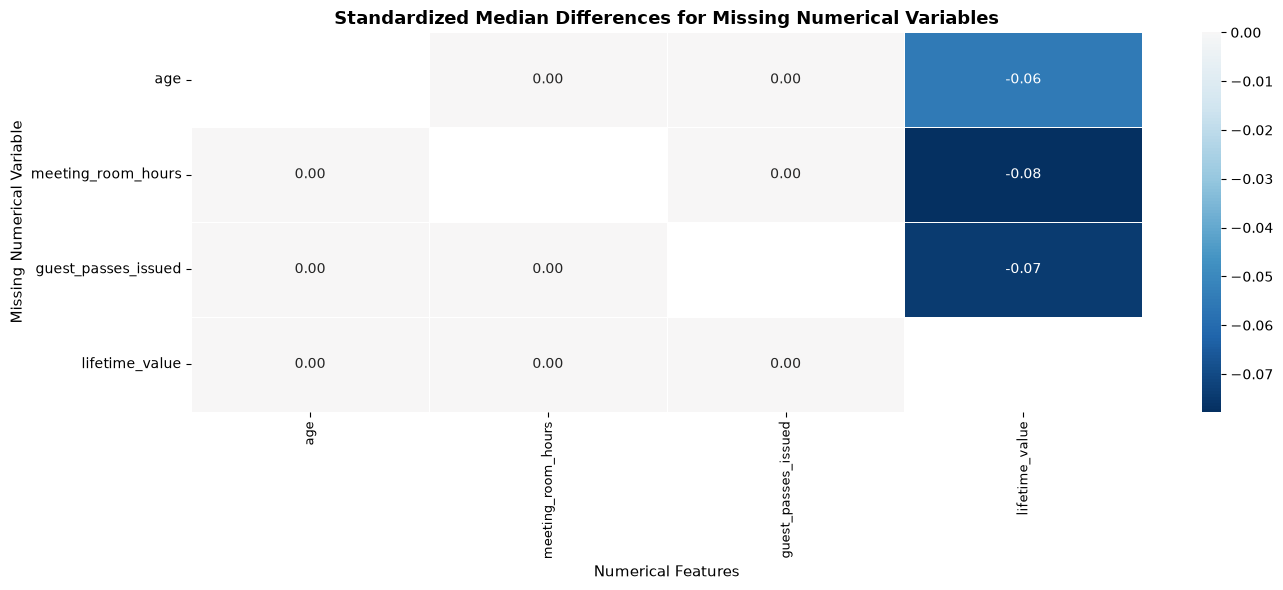

In [469]:
plot_missing_numerical_vs_numerical(df_raw,exclude=["member_id"])

Missingness in age, meeting_room_hours, and guest_passes_issued is associated with only negligible shifts in median lifetime_value (-0.06 to -0.08 IQR) and virtually no shift (0.00 IQR) across the other numerical features, suggesting weak or negligible missingness relationships among these variables.

In [ ]:
def missingness_over_time(df,missing_cols,datetime_cols,freq="M", min_n=30, smooth=None,show_counts=True,figsize=None):
    """
    For every datetime column, plot the share of missing values per time bucket
    for every column in `missing_cols` (one line each) so they can be compared.

    Returns
    -------
    fig   : matplotlib Figure
    """
    data = df.copy()
    data[datetime_cols] = data[datetime_cols].apply(pd.to_datetime)
    miss = data[missing_cols].isna()

    rate_rows, test_rows = [], []
    for d in datetime_cols:
        bucket = data[d].dt.to_period(freq)
        for c in missing_cols:
            g = (
                pd.DataFrame({"bucket": bucket, "miss": miss[c].astype(int)})
                .groupby("bucket")["miss"]
                .agg(rate="mean", n="size", n_missing="sum")
            )
            g = g[g["n"] >= min_n]
            if smooth:
                g["rate"] = g["rate"].rolling(smooth, min_periods=1, center=True).mean()
            g = g.reset_index().assign(datetime_col=d, missing_col=c)
            rate_rows.append(g)

            

    rates = pd.concat(rate_rows, ignore_index=True)

    #plot: one panel per datetime column, one line per missing column
    n = len(datetime_cols)
    fig, axes = plt.subplots(
        n, 1, figsize=figsize or (11, 3.6 * n), sharey=True, squeeze=False
    )
    axes = axes[:, 0]
    colors = plt.cm.tab10(np.linspace(0, 1, 10))

    for ax, d in zip(axes, datetime_cols):
        sub = rates[rates["datetime_col"] == d]

        if show_counts:  #context: how many rows back each point
            cnt = sub.drop_duplicates("bucket").sort_values("bucket")
            ax2 = ax.twinx()
            ax2.bar(cnt["bucket"].dt.to_timestamp(), cnt["n"], width=20 if freq == "M" else None,
                    color="lightgrey", alpha=0.5, zorder=0)
            ax2.set_ylabel("rows in bucket", color="grey")
            ax2.set_ylim(0, cnt["n"].max() * 4)  #keep bars low so lines stay readable
            ax.set_zorder(ax2.get_zorder() + 1)
            ax.patch.set_visible(False)

        for i, c in enumerate(missing_cols):
            s = sub[sub["missing_col"] == c].sort_values("bucket")
            overall = miss[c].mean()
            ax.plot(s["bucket"].dt.to_timestamp(), s["rate"], marker="o", ms=3,
                    color=colors[i % 10], label=f"{c} (overall {overall:.1%})")
            ax.axhline(overall, color=colors[i % 10], ls=":", lw=0.8, alpha=0.6)

        ax.set_title(f"Share missing by {d}  (bucket = {freq})")
        ax.set_ylabel("share missing")
        ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
        ax.grid(alpha=0.25)

    axes[0].legend(ncol=2, fontsize=8, loc="upper left", bbox_to_anchor=(1.08, 1))
    fig.tight_layout()

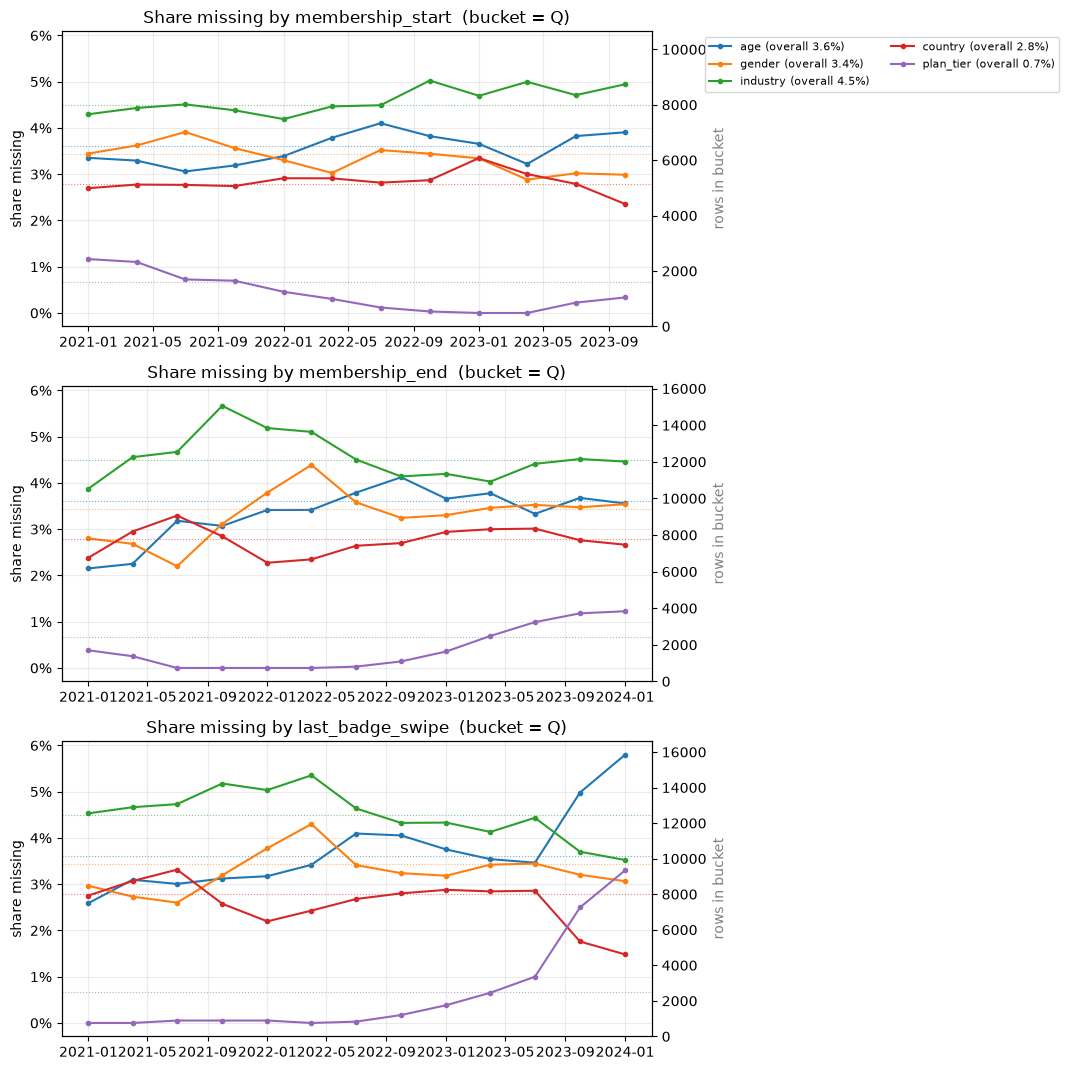

In [538]:
missingness_over_time(
     df_raw,
     missing_cols=["age", "gender", "industry", "country", "plan_tier"],
     datetime_cols=["membership_start", "membership_end", "last_badge_swipe"],
     freq="Q", smooth=3,)

plt.show()

gender, country, industry and age look missing at random with respect to dates. Their rates stay flat within about ±1 percentage point, with a small age and plan tier uptick only in the latest last_badge_swipe quarter.

## 1.4 Executive Data Quality Assessment

### 1.4.1 . Schema, Parsing, and Structural Integrity
- File Ingestion & Delimiters: The dataset requires explicit semicolon delimiting (sep=";"). Furthermore, a subset of rows uses a mixed date format, which requires dual-format parsing to prevent silent parsing failures and false missing values.
- Text-Encoded Numeric Features: The lifetime_value feature is stored as a string containing currency symbols ($,€), whitespace, and regional separators (including commas used as thousands separators), requiring explicit normalization and numeric casting.
- Inconsistent labels:gender (13 raw spellings), plan_tier(20), industry (43) and country`(34) contain case, spacing and abbreviation variants that are normalized before analysis.

### 1.4.2. Completeness and Missingness Diagnostics
- Systematic Missing-Value Codes: The dataset utilizes designated sentinel codes rather than standard null values in key fields. Most notably, days_since_last_visit contains 999 in 8.4% of records, and n_colleagues_on_account contains -1 in 3.6% of records.
- Disguised Missing Values: Zero values in monetary or transactional fields require contextual evaluation. For instance, zero values in lifetime_value overlap heavily (99.8%) with the 999 recency sentinel code, indicating a structural missing-data pattern for low-engagement or dormant accounts rather than free tiers.
- Placeholder Dates: The date 1970-01-0 serves as a placeholder in membership_end for active members (representing approximately 25% of the dataset) and must be isolated to create a valid is_active binary flag rather than treated as a true historical date.
- For real missingness we only have a small fraction of missigness which we will to actively input because they are important behaviour signal(ie Lifetime value).


### 1.4.3. Validity and Logical Consistency
- Temporal Sequence Violations: A small percentage of records (~2.4%) break chronological sequencing rules (i.e., membership_start > membership_end, badge swipes occurring before membership starts, or swipes after closure without a rejoin flag). These are attributable to data entry artifacts, rejoins, or overwritten start dates, we will try to fix this by using other features in our future work.
- Visit and Plan Constraints: Logical contradictions exist in subsets of the data, such as total_visits < actual_visits_last_period (affecting 7.6% of rows, primarily in short memberships where the measurement window exceeds total tenure) and zero-visit records that present positive weekly visit averages.
- Impossible values:ages from 2 to 142, plan_days_per_week of 0 or 9 (97 rows), zero entitled visits (10 rows), and negative values in n_renewals, lifetime_value`and the hours and passes columns.
- Extreme Outliers and Skewness: Financial and operational metrics exhibit severe right skew and extreme anomalies (e.g., meeting room hours reaching thousands of hours), necessitating robust scaling or logarithmic transformations prior to distance-based clustering.
- Tenure effect: cumulative variables (value, visits, renewals, "ever used" add-on flags) grow with time as a member, so rates are preferred-

## 1.5 Preliminary Behavioral Signals

Plan type is the main dividing line.
- Hot desk and flex are 70% of members and mostly short-lived: 59% of hot-desk members have a tenure of 13 weeks or less (39% of all members). Within the 2021 cohort, only 2% of hot-desk and 11% of flex members are still active, against 33–45% for the larger plans.
- Retention follows plan size, not visit frequency: flex members visit almost twice as often as private-office members (1.89 against 1.04 per week) but stay less often (20% against 45%).

Two kinds of large-plan member.Dedicated-desk members visit most (3.9 per week, about 77% of their plan days) and use mail, storage and meeting rooms heavily. Private-office members have the highest monthly value (about 703) but visit far below their plan (about 15% of plan days), so they pay for space they rarely use. Full-time members are also low (about 32%).

Hidden inactivity among active members. About 39% of members with no end date have not swiped in more than 60 days: about 60% of active dedicated-desk and 63% of active full-time members, but almost no hot-desk or private-office ones. This is a candidate "on the books but not visiting" group in high-value tiers.

Add-ons mark member types. Mail handling and storage are resident services of larger plans. Print and phone booths follow visit frequency. Meeting rooms, guest passes and event space mark hosting and relate to value even at the same tenure. Day passes mark light users (27% of hot desk against 5–7% of dedicated desk and private office).

Time structure. The 2023-Q4 starters (about 1,790, 89% active) have a heavier plan mix than the previous three quarters, and 97% of 2023-Q1 to Q3 starters have already left after a median of about 10 weeks. Cumulative variables (value, visits, renewals) mostly reflect tenure, so rates are more informative.

No signal: Age, gender, team status and the bike locker do not separate members.

Zero-value block. The 1,296 members with zero lifetime value and the 999 code are spread across tiers like everyone else and are not more often churned (29% active against 25%), although they have fewer visits (median 13 against 36). This looks more like a missing-data block than a dormant segment.

We anticipate the following  cluster structure: 
1. Short-stay light members (hot desk and flex, low value, few add-ons, day passes).
2. Established residents (dedicated desk, high visits, mail, storage and meeting rooms).
3. High-value, low-presence members (private office, part of full time).
4. Dormant-on-the-books members (active but unseen for 90+ days).
5. New joiners from 2023-Q4, too recent to classify.
6. Possibly the zero-value block, if it separates in the clustering.

# 2. External Data Integration & Validation

## 2.1. Goal and Motivation

This optional analysis explores which industries combine substantial business
formation in Portugal with ACDC membership patterns that could justify testing
a starter-business package.

ACDC's data describes its existing members, their membership plans and their
use of services. It does not describe the wider business population or the
number of new businesses being created in each industry.

We therefore introduce external business-demography statistics to provide
market context for the customer patterns identified in the EDA. The analysis
will compare industry representation, membership plans and service use with
business size and formation indicators.

The findings will identify opportunities for further investigation. They will
not establish that newly created businesses are more likely to subscribe,
because ACDC does not record company age or businesses that did not join.

## 2.2. External Dataset and Justification

The external source is Eurostat's **Business demography by size class and
NACE Rev. 2 activity**, dataset code bd_size. The selected extract covers
Portugal in 2021, 2022 and 2023, with total enterprise-age and employee-size
classes.

It contains three indicators:

| Indicator | Meaning | Analytical purpose |
|---|---|---|
| ENT_NR| Number of active enterprises | Describe the size of each industry |
| ENT_BRTH_NR| Number of enterprise births | Identify industries with substantial numbers of new businesses |
| ENT_BRTHR_PC | Enterprise births divided by active enterprises, expressed as a percentage | Compare formation rates across industries of different sizes |

This dataset was selected because it complements ACDC's customer records with
information about the wider Portuguese business population. Its reference
years overlap the membership observation period.

Industries are classified using NACE Rev. 2. ACDC uses broader descriptive
labels, so a documented mapping will be required before integration.
The extract includes both broad sectors and subdivisions; these must not be
added together where they overlap.

Eurostat counts enterprises, whereas ACDC records members. Comparisons
will therefore describe differences in industry composition and provide
business context, rather than estimate market penetration.

Source: [Eurostat - Business demography (bd_size)](https://ec.europa.eu/eurostat/databrowser/view/bd_size/default/table?lang=en)

In [419]:
#load the original Eurostat extract without modifying it.
EUROSTAT_FILE = RAW / "eurostat_business_demography_pt_2021_2023.csv"

df_eurostat_raw = pd.read_csv(EUROSTAT_FILE)

print(f"Rows: {df_eurostat_raw.shape[0]:,}")
print(f"Columns: {df_eurostat_raw.shape[1]}")

display(df_eurostat_raw.head())

Rows: 1,188
Columns: 23


,STRUCTURE,STRUCTURE_ID,STRUCTURE_NAME,freq,Time frequency,age,Age class,sizeclas,Size classes in number of employees,indic_sbs,Economic indicator for structural business statistics,nace_r2,Statistical classification of economic activities in the European Community (NACE Rev. 2),geo,Geopolitical entity (reporting),TIME_PERIOD,Time,OBS_VALUE,Observation value,OBS_FLAG,Observation status (Flag) V2 structure,CONF_STATUS,Confidentiality status (flag)
0,dataflow,ESTAT:BD_SIZE(1.0),Business demography by size class and NACE Rev...,A,Annual,TOTAL,Total,TOTAL,Total,ENT_BRTHR_PC,Birth rate - enterprise births divided by acti...,B,Mining and quarrying,PT,Portugal,2021,NaN,5.79,NaN,b,break in time series,NaN,NaN
1,dataflow,ESTAT:BD_SIZE(1.0),Business demography by size class and NACE Rev...,A,Annual,TOTAL,Total,TOTAL,Total,ENT_BRTHR_PC,Birth rate - enterprise births divided by acti...,B,Mining and quarrying,PT,Portugal,2022,NaN,5.17,NaN,NaN,NaN,NaN,NaN
2,dataflow,ESTAT:BD_SIZE(1.0),Business demography by size class and NACE Rev...,A,Annual,TOTAL,Total,TOTAL,Total,ENT_BRTHR_PC,Birth rate - enterprise births divided by acti...,B,Mining and quarrying,PT,Portugal,2023,NaN,3.64,NaN,NaN,NaN,NaN,NaN
3,dataflow,ESTAT:BD_SIZE(1.0),Business demography by size class and NACE Rev...,A,Annual,TOTAL,Total,TOTAL,Total,ENT_BRTHR_PC,Birth rate - enterprise births divided by acti...,B-S_X_O_S94,"Industry, construction and market services (ex...",PT,Portugal,2021,NaN,14.38,NaN,b,break in time series,NaN,NaN
4,dataflow,ESTAT:BD_SIZE(1.0),Business demography by size class and NACE Rev...,A,Annual,TOTAL,Total,TOTAL,Total,ENT_BRTHR_PC,Birth rate - enterprise births divided by acti...,B-S_X_O_S94,"Industry, construction and market services (ex...",PT,Portugal,2022,NaN,16.74,NaN,NaN,NaN,NaN,NaN


## 2.3. Source Credibility and Limitations

Eurostat is the statistical office of the European Union. The Portuguese
business-demography statistics are compiled by INE (Statistics Portugal)
using business-register information, administrative sources and business
surveys.

The source has high credibility for describing the Portuguese business
population because it provides documented definitions, classifications
and quality metadata.

The following limitations affect its use in this analysis:

- **Different units:** Eurostat counts enterprises, while ACDC records
  members. Several members may belong to the same company.
- **Geographical coverage:** the external figures describe Portugal as a
  whole. They do not measure demand within ACDC's local catchment area.
- **Industry mapping:** ACDC's descriptive industry labels do not always
  correspond directly to NACE categories.
- **Business formation is not coworking demand:** enterprise births identify
  potential market activity, not businesses intending to purchase memberships.
- **Time-series break:** the extract flags 2021 with b, indicating a break
  in series. Portuguese metadata identifies a methodological break between
  2020 and 2021, so comparisons with earlier years require caution.
- **Historical context:** the selected observations cover 2021–2023 and
  should not be presented as current market conditions.

These statistics will provide external context for ACDC's industry composition
and customer behaviour. They cannot independently validate individual
members' preferences or reasons for joining.

Methodology:
[Eurostat — Portuguese business-demography metadata](https://ec.europa.eu/eurostat/cache/metadata/EN/bd_simsbd21_pt.htm)

## 2.4. External Data Exploration and Preparation

Before integration, we inspect the extract's structure, selected dimensions,
missing observations and quality flags.

The expected scope is Portugal, 2021–2023, three business-demography indicators
and total enterprise-age and employee-size classes.

Each observation should be uniquely identified by its reporting frequency,
country, year, industry, indicator, enterprise-age class and employee-size class.
Industry aggregates and their subdivisions are separate observations, not
duplicate records.

In [420]:
# Inspect column types and non-null counts.
df_eurostat_raw.info()

# Check that the downloaded dimensions match the intended scope.
scope_columns = [
    "geo",
    "TIME_PERIOD",
    "indic_sbs",
    "age",
    "sizeclas",
]

for column in scope_columns:
    values = sorted(df_eurostat_raw[column].dropna().unique().tolist())
    print(f"{column}: {values}")

print(f"\nDistinct industry categories: {df_eurostat_raw['nace_r2'].nunique()}")

<class 'pandas.DataFrame'>
RangeIndex: 1188 entries, 0 to 1187
Data columns (total 23 columns):
 #   Column                                                                                     Non-Null Count  Dtype  
---  ------                                                                                     --------------  -----  
 0   STRUCTURE                                                                                  1188 non-null   str    
 1   STRUCTURE_ID                                                                               1188 non-null   str    
 2   STRUCTURE_NAME                                                                             1188 non-null   str    
 3   freq                                                                                       1188 non-null   str    
 4   Time frequency                                                                             1188 non-null   str    
 5   age                                                        

In [421]:
# Check missing observations and duplicate observation keys.
observation_key = [
    "freq",
    "geo",
    "TIME_PERIOD",
    "nace_r2",
    "indic_sbs",
    "age",
    "sizeclas",
]

quality_summary = pd.Series({
    "Missing observation values": df_eurostat_raw["OBS_VALUE"].isna().sum(),
    "Rows with missing key fields": (
        df_eurostat_raw[observation_key].isna().any(axis=1).sum()
    ),
    "Duplicate observation keys": (
        df_eurostat_raw.duplicated(subset=observation_key).sum()
    ),
    "Exact duplicate rows": df_eurostat_raw.duplicated().sum(),
})

display(quality_summary.to_frame("Count"))

# Show available observations for each indicator and year.
coverage = (
    df_eurostat_raw
    .groupby(["indic_sbs", "TIME_PERIOD"])
    .agg(
        rows=("OBS_VALUE", "size"),
        available_values=("OBS_VALUE", "count"),
    )
)

display(coverage)

# Retain and inspect quality flags rather than discarding flagged rows.
flag_summary = pd.crosstab(
    df_eurostat_raw["TIME_PERIOD"],
    df_eurostat_raw["OBS_FLAG"].fillna("No flag"),
)

display(flag_summary)

,Count
Missing observation values,0
Rows with missing key fields,0
Duplicate observation keys,0
Exact duplicate rows,0


rows  available_values
indic_sbs    TIME_PERIOD                        
ENT_BRTHR_PC 2021          132               132
             2022          132               132
             2023          132               132
ENT_BRTH_NR  2021          132               132
             2022          132               132
             2023          132               132
ENT_NR       2021          132               132
             2022          132               132
             2023          132               132

OBS_FLAG,No flag,b
TIME_PERIOD,,
2021,0,396
2022,396,0
2023,396,0


### 2.4.1. Reshaping the External Indicators

The original extract stores each indicator in a separate row. We reshape it
into one row per country, industry and year, with separate columns for active
enterprises, enterprise births and enterprise birth rate.

The original extract remains unchanged, and observation flags are retained
in the prepared table.

This transformation does not combine industries. Broad sectors and their
subdivisions remain separate until the industry mapping is defined.

In [422]:
# Select the intended scope explicitly and preserve the original extract.
selected_indicators = {
    "ENT_NR": "active_enterprises",
    "ENT_BRTH_NR": "enterprise_births",
    "ENT_BRTHR_PC": "birth_rate_pct",
}

industry_label = (
    "Statistical classification of economic activities in the "
    "European Community (NACE Rev. 2)"
)

df_eurostat = (
    df_eurostat_raw.loc[
        df_eurostat_raw["geo"].eq("PT")
        & df_eurostat_raw["TIME_PERIOD"].isin([2021, 2022, 2023])
        & df_eurostat_raw["age"].eq("TOTAL")
        & df_eurostat_raw["sizeclas"].eq("TOTAL")
        & df_eurostat_raw["indic_sbs"].isin(selected_indicators)
    ]
    .copy()
    .rename(columns={
        "geo": "country_code",
        "TIME_PERIOD": "year",
        "nace_r2": "nace_code",
        industry_label: "industry_description",
    })
)

# Raise an error if an observation contains unexpected non-numeric text.
df_eurostat["OBS_VALUE"] = pd.to_numeric(
    df_eurostat["OBS_VALUE"],
    errors="raise",
)

comparison_key = ["country_code", "nace_code", "year"]

# Pivot requires a unique value for each key and indicator.
df_eurostat_wide = (
    df_eurostat
    .pivot(
        index=comparison_key,
        columns="indic_sbs",
        values="OBS_VALUE",
    )
    .rename(columns=selected_indicators)
    .reset_index()
)

df_eurostat_wide.columns.name = None

# Preserve industry descriptions.
industry_lookup = (
    df_eurostat[["nace_code", "industry_description"]]
    .drop_duplicates()
)

df_eurostat_wide = df_eurostat_wide.merge(
    industry_lookup,
    on="nace_code",
    how="left",
    validate="many_to_one",
)

# Preserve flags separately for each indicator.
flag_table = (
    df_eurostat
    .pivot(
        index=comparison_key,
        columns="indic_sbs",
        values="OBS_FLAG",
    )
    .rename(columns={
        code: f"{name}_flag"
        for code, name in selected_indicators.items()
    })
    .reset_index()
)

flag_table.columns.name = None

df_eurostat_wide = (
    df_eurostat_wide
    .merge(
        flag_table,
        on=comparison_key,
        how="left",
        validate="one_to_one",
    )
    .sort_values(["nace_code", "year"])
    .reset_index(drop=True)
)

print(f"Prepared rows: {len(df_eurostat_wide):,}")
display(df_eurostat_wide.head())

Prepared rows: 396


,country_code,nace_code,year,birth_rate_pct,enterprise_births,active_enterprises,industry_description,birth_rate_pct_flag,enterprise_births_flag,active_enterprises_flag
0,PT,B,2021,5.79,58.00,1002.00,Mining and quarrying,b,b,b
1,PT,B,2022,5.17,52.00,1006.00,Mining and quarrying,NaN,NaN,NaN
2,PT,B,2023,3.64,36.00,990.00,Mining and quarrying,NaN,NaN,NaN
3,PT,B-S_X_O_S94,2021,14.38,177144.00,1231887.00,"Industry, construction and market services (ex...",b,b,b
4,PT,B-S_X_O_S94,2022,16.74,222462.00,1329175.00,"Industry, construction and market services (ex...",NaN,NaN,NaN


### 2.4.2. Indicator Consistency Checks

We check for missing indicators, negative enterprise counts and birth rates
outside the expected 0–100% range.

We also recalculate the birth rate as enterprise births divided by active
enterprises, multiplied by 100. Differences from the published rate are
reported in percentage points. Small differences may reflect rounding.

In [423]:
# Check completeness and expected numerical ranges.
indicator_columns = list(selected_indicators.values())

display(
    df_eurostat_wide[indicator_columns]
    .isna()
    .sum()
    .to_frame("Missing values")
)

count_columns = ["active_enterprises", "enterprise_births"]

print(
    "Rows with negative enterprise counts:",
    df_eurostat_wide[count_columns].lt(0).any(axis=1).sum(),
)

print(
    "Published birth rates outside 0–100%:",
    (
        df_eurostat_wide["birth_rate_pct"].notna()
        & ~df_eurostat_wide["birth_rate_pct"].between(0, 100)
    ).sum(),
)

# A zero denominator produces an undefined rate, rather than a forced zero.
valid_denominator = df_eurostat_wide["active_enterprises"].where(
    df_eurostat_wide["active_enterprises"] > 0
)

df_eurostat_wide["birth_rate_recalculated_pct"] = (
    df_eurostat_wide["enterprise_births"]
    / valid_denominator
    * 100
)

df_eurostat_wide["birth_rate_difference_pp"] = (
    df_eurostat_wide["birth_rate_pct"]
    - df_eurostat_wide["birth_rate_recalculated_pct"]
).abs()

# Inspect the largest discrepancies before interpreting them.
display(
    df_eurostat_wide[
        [
            "nace_code",
            "year",
            "active_enterprises",
            "enterprise_births",
            "birth_rate_pct",
            "birth_rate_recalculated_pct",
            "birth_rate_difference_pp",
        ]
    ]
    .sort_values("birth_rate_difference_pp", ascending=False)
    .head(10)
)

,Missing values
active_enterprises,0
enterprise_births,0
birth_rate_pct,0


Rows with negative enterprise counts: 0
Published birth rates outside 0–100%: 0


,nace_code,year,active_enterprises,enterprise_births,birth_rate_pct,birth_rate_recalculated_pct,birth_rate_difference_pp
306,N783,2021,160.00,39.00,24.38,24.38,0.00
150,J58,2021,1892.00,233.00,12.32,12.32,0.00
138,I55,2021,39212.00,4429.00,11.30,11.30,0.00
98,G473,2023,1688.00,33.00,1.95,1.95,0.00
318,N80,2021,676.00,70.00,10.36,10.36,0.00
305,N782,2023,484.00,90.00,18.60,18.60,0.00
259,M74,2022,22615.00,4644.00,20.54,20.54,0.00
46,C27,2022,546.00,27.00,4.95,4.95,0.00
262,M741,2022,9309.00,2216.00,23.80,23.80,0.00
245,M721,2023,1222.00,281.00,23.00,23.00,0.00


In [424]:
max_difference = df_eurostat_wide["birth_rate_difference_pp"].max()

print(f"Maximum birth-rate difference: {max_difference:.6f} percentage points")

Maximum birth-rate difference: 0.005000 percentage points


The three selected indicators contain no missing observations. Enterprise
counts are non-negative, and all published birth rates fall within 0–100%.

Recalculated birth rates closely match the published values. Small differences
are consistent with rounding of the published percentages.

These checks support the internal consistency of the extract. They do not
resolve industry-mapping differences or establish comparability with ACDC's
member records.

## 2.5. Industry Mapping and Integration

### 2.5.1. Mapping ACDC Industries to NACE Rev. 2

ACDC uses descriptive industry labels, while Eurostat uses NACE Rev. 2.
We define common comparison groups to connect the two sources.

The mapping is an analytical approximation, not a verified classification
of each member's company. Some ACDC labels are broader or less precise than
the corresponding external categories.

| Comparison group | ACDC industry | Eurostat codes | Mapping limitation |
|---|---|---|---|
| Information technology | Information Technology | J62 + J63 | Programming, IT consultancy and information services approximate the broad IT label |
| Consulting, marketing & PR | Consulting; Marketing & PR | M702 + M73 | Combined because public relations falls within M702; consulting may also include activities outside this group |
| Design & creative | Design & Creative | M741 | Specialised design is a narrower proxy and does not cover all creative professions |
| Finance & insurance | Finance | K | The external category also includes insurance |
| Legal | Legal | M691 | Close conceptual correspondence |
| Real estate | Real Estate | L | Includes different property activities, not only agencies |
| Education | Education | P | Eurostat covers market enterprises, not the entire education system |
| Human health | Health | Q86 | Excludes residential care and social work |

Members with missing or unspecified industries are excluded from the mapped
comparison, but retained in the original ACDC data. We report mapping coverage
to make this exclusion visible.

Each selected NACE category contributes to only one comparison group.
Parent categories are not added to their own subdivisions.

For groups containing several NACE categories, enterprise counts will be
summed and birth rates recalculated from those counts.

In [425]:
# Define non-overlapping external comparison groups.
nace_groups = {
    "Information technology": ["J62", "J63"],
    "Consulting, marketing & PR": ["M702", "M73"],
    "Design & creative": ["M741"],
    "Finance & insurance": ["K"],
    "Legal": ["M691"],
    "Real estate": ["L"],
    "Education": ["P"],
    "Human health": ["Q86"],
}

# Match ACDC's standardised industry labels to the same groups.
acdc_industry_groups = {
    "information technology": "Information technology",
    "consulting": "Consulting, marketing & PR",
    "marketing & pr": "Consulting, marketing & PR",
    "design & creative": "Design & creative",
    "finance": "Finance & insurance",
    "legal": "Legal",
    "real estate": "Real estate",
    "education": "Education",
    "health": "Human health",
}

# Confirm that no external code is assigned to multiple groups.
selected_codes = [
    code
    for codes in nace_groups.values()
    for code in codes
]

assert len(selected_codes) == len(set(selected_codes)), (
    "A NACE code has been assigned to multiple comparison groups."
)

# Confirm that all requested codes exist in the downloaded extract.
missing_codes = (
    set(selected_codes) - set(df_eurostat_wide["nace_code"])
)

assert not missing_codes, f"Missing NACE codes: {sorted(missing_codes)}"

# Build a separate Portuguese subset without changing the main EDA data.
portugal_mask = (
    df_engineered["country"]
    .astype("string")
    .str.strip()
    .str.lower()
    .eq("portugal")
    .fillna(False)
)

df_acdc_pt = df_engineered.loc[portugal_mask].copy()

# Retain missing labels as missing rather than converting them to text.
df_acdc_pt["industry_standardised"] = (
    df_acdc_pt["industry"]
    .astype("string")
    .str.strip()
    .str.lower()
)

df_acdc_pt["comparison_group"] = (
    df_acdc_pt["industry_standardised"].map(acdc_industry_groups)
)

# Report coverage in rows; member uniqueness will be checked separately.
mapped_rows = df_acdc_pt["comparison_group"].notna().sum()
total_rows = len(df_acdc_pt)

print(f"Portuguese ACDC rows: {total_rows:,}")
print(f"Mapped rows: {mapped_rows:,}")

if total_rows > 0:
    print(f"Mapping coverage: {mapped_rows / total_rows:.1%}")

display(
    df_acdc_pt["comparison_group"]
    .fillna("Unmapped")
    .value_counts()
    .rename_axis("Comparison group")
    .to_frame("Rows")
)

# Make excluded industry labels visible.
print("\nUnmapped industry labels:")

display(
    df_acdc_pt.loc[
        df_acdc_pt["comparison_group"].isna(),
        "industry_standardised",
    ]
    .fillna("Missing")
    .value_counts()
    .rename_axis("Industry label")
    .to_frame("Rows")
)

Portuguese ACDC rows: 10,508
Mapped rows: 9,169
Mapping coverage: 87.3%


,Rows
Comparison group,
"Consulting, marketing & PR",2676
Information technology,2395
Design & creative,1424
Unmapped,1339
Finance & insurance,782
Legal,575
Education,541
Human health,415
Real estate,361



Unmapped industry labels:


,Rows
Industry label,
other,845
Missing,494


### 2.5.2. Aggregating the External Comparison Groups

We aggregate active-enterprise and enterprise-birth counts within each
comparison group and year.

For groups containing multiple NACE categories, the birth rate is recalculated
as total enterprise births divided by total active enterprises, multiplied
by 100. This avoids giving small and large categories equal weight through
a simple average of percentages.

Observation flags are retained. The resulting table should contain one row
per country, comparison group and year.

In [426]:
# Connect each selected NACE code to its comparison group.
nace_to_group = {
    code: group
    for group, codes in nace_groups.items()
    for code in codes
}

df_eurostat_selected = (
    df_eurostat_wide.loc[
        df_eurostat_wide["nace_code"].isin(nace_to_group)
    ]
    .copy()
)

df_eurostat_selected["comparison_group"] = (
    df_eurostat_selected["nace_code"].map(nace_to_group)
)

# Verify that every group has all its expected component categories.
component_counts = (
    df_eurostat_selected
    .groupby(["country_code", "comparison_group", "year"])["nace_code"]
    .nunique()
)

expected_counts = (
    component_counts.index
    .get_level_values("comparison_group")
    .map({group: len(codes) for group, codes in nace_groups.items()})
)

assert (component_counts.to_numpy() == expected_counts.to_numpy()).all(), (
    "Some comparison groups are missing component NACE categories."
)


# Preserve distinct non-empty flags from the component observations.
def combine_flags(series):
    flags = sorted({
        str(value).strip()
        for value in series.dropna()
        if str(value).strip()
    })
    return "; ".join(flags) if flags else pd.NA


# min_count prevents missing component values from silently becoming zero.
df_eurostat_grouped = (
    df_eurostat_selected
    .groupby(
        ["country_code", "comparison_group", "year"],
        as_index=False,
    )
    .agg(
        active_enterprises=(
            "active_enterprises",
            lambda values: values.sum(min_count=len(values)),
        ),
        enterprise_births=(
            "enterprise_births",
            lambda values: values.sum(min_count=len(values)),
        ),
        active_enterprises_flag=(
            "active_enterprises_flag",
            combine_flags,
        ),
        enterprise_births_flag=(
            "enterprise_births_flag",
            combine_flags,
        ),
        birth_rate_source_flag=(
            "birth_rate_pct_flag",
            combine_flags,
        ),
    )
)

# Calculate each group's birth rate from its aggregated counts.
valid_denominator = df_eurostat_grouped["active_enterprises"].where(
    df_eurostat_grouped["active_enterprises"] > 0
)

df_eurostat_grouped["birth_rate_pct"] = (
    df_eurostat_grouped["enterprise_births"]
    / valid_denominator
    * 100
)

df_eurostat_grouped = (
    df_eurostat_grouped
    .sort_values(["comparison_group", "year"])
    .reset_index(drop=True)
)

# Confirm that all eight groups exist in every selected year.
expected_keys = {
    ("PT", group, year)
    for group in nace_groups
    for year in [2021, 2022, 2023]
}

actual_keys = set(
    df_eurostat_grouped[
        ["country_code", "comparison_group", "year"]
    ].itertuples(index=False, name=None)
)

assert actual_keys == expected_keys, (
    "The grouped table does not contain all expected group-year combinations."
)

print(f"Comparison groups: {df_eurostat_grouped['comparison_group'].nunique()}")
print(f"Rows: {len(df_eurostat_grouped)}")

display(df_eurostat_grouped)

Comparison groups: 8
Rows: 24


,country_code,comparison_group,year,active_enterprises,enterprise_births,active_enterprises_flag,enterprise_births_flag,birth_rate_source_flag,birth_rate_pct
0,PT,"Consulting, marketing & PR",2021,32265.00,6228.00,b,b,b,19.30
1,PT,"Consulting, marketing & PR",2022,35577.00,6820.00,NaN,NaN,NaN,19.17
2,PT,"Consulting, marketing & PR",2023,38946.00,7519.00,NaN,NaN,NaN,19.31
3,PT,Design & creative,2021,8127.00,1812.00,b,b,b,22.30
4,PT,Design & creative,2022,9309.00,2216.00,NaN,NaN,NaN,23.80
5,PT,Design & creative,2023,10374.00,2359.00,NaN,NaN,NaN,22.74
6,PT,Education,2021,58588.00,9591.00,b,b,b,16.37
7,PT,Education,2022,63563.00,11679.00,NaN,NaN,NaN,18.37
8,PT,Education,2023,66065.00,11232.00,NaN,NaN,NaN,17.00
9,PT,Finance & insurance,2021,17159.00,2868.00,b,b,b,16.71


### 2.5.3. Preparing the ACDC Comparison Sample

The comparison uses Portugal-based members with a mapped industry.

Before calculating group summaries, we remove exact duplicate rows and check
whether member IDs uniquely identify the remaining records.

If an ID has multiple different records, those records are excluded from this
comparison pending investigation. Missing or blank IDs are also excluded.
All exclusions are reported, and the original data remains unchanged.

The first profiles describe membership-plan choices, team-account shares and
service adoption. These are descriptive patterns among existing members,
not estimates of demand among newly created businesses.

In [427]:
# Work on a separate copy of the Portuguese ACDC sample.
df_acdc_comparison = df_acdc_pt.copy()

initial_rows = len(df_acdc_comparison)

# Remove only completely identical rows.
df_acdc_comparison = df_acdc_comparison.drop_duplicates().copy()

exact_duplicates_removed = initial_rows - len(df_acdc_comparison)

# Exclude records without a usable member identifier.
member_ids = (
    df_acdc_comparison["member_id"]
    .astype("string")
    .str.strip()
)

missing_id_mask = member_ids.isna() | member_ids.eq("").fillna(False)
missing_id_rows = int(missing_id_mask.sum())

df_acdc_comparison = df_acdc_comparison.loc[~missing_id_mask].copy()
df_acdc_comparison["member_id"] = member_ids.loc[~missing_id_mask]

# Remaining repeated IDs have different records.
conflicting_id_mask = df_acdc_comparison.duplicated(
    subset="member_id",
    keep=False,
)

df_acdc_conflicting_ids = (
    df_acdc_comparison.loc[conflicting_id_mask].copy()
)

conflicting_ids = df_acdc_conflicting_ids["member_id"].nunique()
conflicting_rows = len(df_acdc_conflicting_ids)

df_acdc_comparison = (
    df_acdc_comparison.loc[~conflicting_id_mask].copy()
)

# Retain only industries covered by the documented mapping.
unmapped_rows = int(
    df_acdc_comparison["comparison_group"].isna().sum()
)

df_acdc_comparison = (
    df_acdc_comparison
    .dropna(subset=["comparison_group"])
    .copy()
)

sample_audit = pd.Series({
    "Initial Portuguese rows": initial_rows,
    "Exact duplicate rows removed": exact_duplicates_removed,
    "Missing or blank ID rows excluded": missing_id_rows,
    "Conflicting member IDs": conflicting_ids,
    "Rows excluded for conflicting IDs": conflicting_rows,
    "Unmapped industry rows excluded": unmapped_rows,
    "Final unique mapped members": len(df_acdc_comparison),
})

display(sample_audit.to_frame("Count"))

assert df_acdc_comparison["member_id"].is_unique

,Count
Initial Portuguese rows,10508
Exact duplicate rows removed,9
Missing or blank ID rows excluded,0
Conflicting member IDs,0
Rows excluded for conflicting IDs,0
Unmapped industry rows excluded,1337
Final unique mapped members,9162


In [428]:
# Count members in each comparison group.
df_acdc_profiles = (
    df_acdc_comparison
    .groupby("comparison_group")
    .agg(member_count=("member_id", "nunique"))
)

# Calculate plan shares among members with a recognised plan.
valid_plans = [
    "hot_desk",
    "flex",
    "dedicated_desk",
    "full_time",
    "private_office",
]

recognised_plan = df_acdc_comparison["plan_tier"].isin(valid_plans)

plan_counts = pd.crosstab(
    df_acdc_comparison.loc[recognised_plan, "comparison_group"],
    df_acdc_comparison.loc[recognised_plan, "plan_tier"],
).reindex(
    index=df_acdc_profiles.index,
    columns=valid_plans,
    fill_value=0,
)

plan_denominator = plan_counts.sum(axis=1)

plan_shares = (
    plan_counts
    .div(plan_denominator.replace(0, np.nan), axis=0)
    .mul(100)
    .rename(columns=lambda plan: f"{plan}_pct")
)

df_acdc_profiles = df_acdc_profiles.join(plan_shares)

df_acdc_profiles["members_with_valid_plan"] = plan_denominator
df_acdc_profiles["missing_or_unrecognised_plan"] = (
    df_acdc_profiles["member_count"] - plan_denominator
)

df_acdc_profiles["hot_desk_or_flex_pct"] = (
    plan_counts[["hot_desk", "flex"]].sum(axis=1)
    .div(plan_denominator.replace(0, np.nan))
    .mul(100)
)

# Summarise team-account and selected service flags.
# Unexpected values are treated as missing, not as False.
profile_flags = [
    "is_team_account",
    "uses_meeting_rooms",
    "uses_mail_handling",
    "uses_phone_booths",
    "uses_guest_passes",
]

for column in profile_flags:
    numeric_flag = pd.to_numeric(
        df_acdc_comparison[column],
        errors="coerce",
    )

    valid_flag = numeric_flag.where(numeric_flag.isin([0, 1]))

    flag_summary = (
        pd.DataFrame({
            "comparison_group": df_acdc_comparison["comparison_group"],
            "flag": valid_flag,
        })
        .groupby("comparison_group")["flag"]
        .agg(["mean", "count"])
    )

    df_acdc_profiles[f"{column}_pct"] = flag_summary["mean"] * 100
    df_acdc_profiles[f"{column}_valid_n"] = flag_summary["count"]

df_acdc_profiles = df_acdc_profiles.reset_index()

display(df_acdc_profiles)

,comparison_group,member_count,hot_desk_pct,flex_pct,dedicated_desk_pct,full_time_pct,private_office_pct,members_with_valid_plan,missing_or_unrecognised_plan,hot_desk_or_flex_pct,is_team_account_pct,is_team_account_valid_n,uses_meeting_rooms_pct,uses_meeting_rooms_valid_n,uses_mail_handling_pct,uses_mail_handling_valid_n,uses_phone_booths_pct,uses_phone_booths_valid_n,uses_guest_passes_pct,uses_guest_passes_valid_n
0,"Consulting, marketing & PR",2674,34.64,37.61,8.24,16.81,2.71,2659,15,72.25,28.35,2674,34.29,2674,21.09,2674,24.23,2674,19.90,2674
1,Design & creative,1423,49.79,37.25,2.68,9.58,0.70,1420,3,87.04,26.42,1423,24.95,1423,11.03,1423,21.15,1423,13.49,1423
2,Education,541,43.97,36.73,4.08,13.91,1.30,539,2,80.71,28.84,541,26.62,541,13.12,541,25.69,541,12.38,541
3,Finance & insurance,781,24.55,32.90,16.97,19.92,5.66,778,3,57.46,28.94,781,33.93,781,29.45,781,21.38,781,18.31,781
4,Human health,415,39.95,37.77,4.60,14.53,3.15,413,2,77.72,26.27,415,31.57,415,14.46,415,26.02,415,15.42,415
5,Information technology,2394,38.04,35.73,9.57,14.11,2.56,2382,12,73.76,28.36,2394,28.99,2394,20.55,2394,24.56,2394,14.79,2394
6,Legal,574,29.68,33.92,14.49,18.20,3.71,566,8,63.60,31.71,574,32.93,574,25.61,574,24.56,574,17.25,574
7,Real estate,360,34.27,33.99,8.43,17.98,5.34,356,4,68.26,35.56,360,35.28,360,25.83,360,23.06,360,15.56,360


## 2.6. Exploratory Analysis of the Integrated Data

### 2.6.1. Integration and Industry Composition

We combine ACDC's Portuguese member profiles with the 2023 Eurostat
business-demography snapshot using the documented comparison groups.

ACDC's profiles include memberships observed across 2021–2023. They are
compared with a single-year external snapshot, so this is a descriptive
comparison of composition rather than a matched annual analysis.

For each comparison group, we calculate:

- Its share of ACDC members within the mapped sample.
- Its share of active enterprises within the selected external groups.
- Its share of enterprise births within those same external groups.

All shares use the eight mapped comparison groups as their respective
denominators, rather than the entire Portuguese economy.

Differences show how ACDC's membership composition compares with the external
business population. They do not measure market penetration, acquisition
performance or the probability that a business will subscribe.

In [429]:
# Select the external reference year.
REFERENCE_YEAR = 2023

df_market_snapshot = (
    df_eurostat_grouped.loc[
        df_eurostat_grouped["year"].eq(REFERENCE_YEAR)
    ]
    .copy()
)

# Join one industry profile to one external industry summary.
df_industry_comparison = df_market_snapshot.merge(
    df_acdc_profiles,
    on="comparison_group",
    how="left",
    validate="one_to_one",
    indicator=True,
)

# An absent ACDC group has zero observed members.
# Its behavioural percentages remain missing, not zero.
df_industry_comparison["member_count"] = (
    df_industry_comparison["member_count"]
    .fillna(0)
    .astype(int)
)

print("Join coverage:")
display(df_industry_comparison["_merge"].value_counts().to_frame("Groups"))

df_industry_comparison = df_industry_comparison.drop(columns="_merge")

# Compute shares within the same eight comparison groups.
total_members = df_industry_comparison["member_count"].sum()
total_enterprises = df_industry_comparison["active_enterprises"].sum()
total_births = df_industry_comparison["enterprise_births"].sum()

assert total_members > 0, "No mapped ACDC members are available."
assert total_enterprises > 0, "The external enterprise total must be positive."
assert total_births > 0, "The external birth total must be positive."

df_industry_comparison["acdc_member_share_pct"] = (
    df_industry_comparison["member_count"] / total_members * 100
)

df_industry_comparison["active_enterprise_share_pct"] = (
    df_industry_comparison["active_enterprises"] / total_enterprises * 100
)

df_industry_comparison["enterprise_birth_share_pct"] = (
    df_industry_comparison["enterprise_births"] / total_births * 100
)

# Express composition differences in percentage points.
df_industry_comparison["member_vs_enterprise_gap_pp"] = (
    df_industry_comparison["acdc_member_share_pct"]
    - df_industry_comparison["active_enterprise_share_pct"]
)

comparison_columns = [
    "comparison_group",
    "member_count",
    "active_enterprises",
    "enterprise_births",
    "birth_rate_pct",
    "acdc_member_share_pct",
    "active_enterprise_share_pct",
    "enterprise_birth_share_pct",
    "member_vs_enterprise_gap_pp",
]

display(
    df_industry_comparison[comparison_columns]
    .sort_values("acdc_member_share_pct", ascending=False)
    .reset_index(drop=True)
)

Join coverage:


,Groups
_merge,
both,8
left_only,0
right_only,0


,comparison_group,member_count,active_enterprises,enterprise_births,birth_rate_pct,acdc_member_share_pct,active_enterprise_share_pct,enterprise_birth_share_pct,member_vs_enterprise_gap_pp
0,"Consulting, marketing & PR",2674,38946.00,7519.00,19.31,29.19,10.61,14.32,18.57
1,Information technology,2394,25642.00,7129.00,27.80,26.13,6.99,13.57,19.14
2,Design & creative,1423,10374.00,2359.00,22.74,15.53,2.83,4.49,12.70
3,Finance & insurance,781,16652.00,1134.00,6.81,8.52,4.54,2.16,3.99
4,Legal,574,32393.00,2100.00,6.48,6.27,8.83,4.00,-2.56
5,Education,541,66065.00,11232.00,17.00,5.90,18.00,21.39,-12.10
6,Human health,415,112117.00,13478.00,12.02,4.53,30.55,25.66,-26.02
7,Real estate,360,64794.00,7567.00,11.68,3.93,17.66,14.41,-13.73


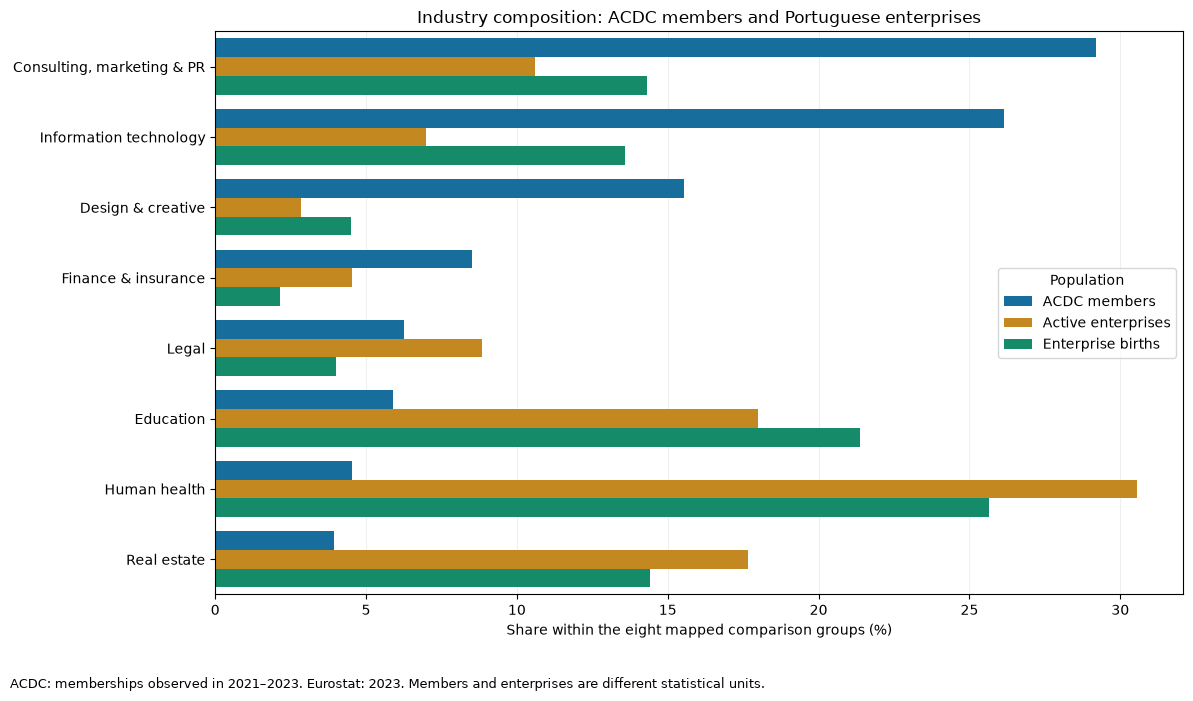

In [430]:
# Compare composition across the three populations.
share_columns = {
    "acdc_member_share_pct": "ACDC members",
    "active_enterprise_share_pct": "Active enterprises",
    "enterprise_birth_share_pct": "Enterprise births",
}

plot_data = df_industry_comparison.melt(
    id_vars="comparison_group",
    value_vars=list(share_columns),
    var_name="Population",
    value_name="Share (%)",
)

plot_data["Population"] = plot_data["Population"].map(share_columns)

group_order = (
    df_industry_comparison
    .sort_values("acdc_member_share_pct", ascending=False)
    ["comparison_group"]
    .tolist()
)

fig, ax = plt.subplots(figsize=(12, 7))

sns.barplot(
    data=plot_data,
    y="comparison_group",
    x="Share (%)",
    hue="Population",
    order=group_order,
    palette="colorblind",
    errorbar=None,
    ax=ax,
)

ax.set_title(
    "Industry composition: ACDC members and Portuguese enterprises"
)
ax.set_xlabel("Share within the eight mapped comparison groups (%)")
ax.set_ylabel("")
ax.legend(title="Population")
ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)

fig.text(
    0.01,
    0.01,
    "ACDC: memberships observed in 2021–2023. "
    "Eurostat: 2023. Members and enterprises are different statistical units.",
    fontsize=9,
)

plt.tight_layout(rect=[0, 0.06, 1, 1])
plt.show()

### Interpretation

Within the eight mapped comparison groups, ACDC membership is concentrated
in consulting, marketing & PR (approximately 29%), information technology
(26%) and design & creative (16%). Each group has a larger share of ACDC
members than of active enterprises or enterprise births.

Human health shows the opposite pattern: it accounts for approximately 31%
of active enterprises and 26% of enterprise births, but only 5% of ACDC
members. Education and real estate also have substantially larger external
business shares than ACDC membership shares.

The pattern indicates that ACDC's existing customer mix is concentrated in
particular service industries rather than reflecting the composition of
the selected Portuguese business population.

These differences do not establish unmet demand. Health businesses may
require clinical premises, while education and real-estate businesses may
have other location and facility requirements. These are possible explanations
to investigate, not findings established by this comparison.

Mapping also affects the results. In particular, ACDC's broad Design &
Creative label is compared with the narrower specialised-design category,
which may exaggerate the apparent concentration.

The enterprise-birth bars show each industry's share of new businesses,
not its birth rate. All percentages are conditional on the eight mapped
groups, and members and enterprises remain different statistical units.

### 2.6.2. Business Formation and Membership Plans

We compare two external indicators:

- **Enterprise births:** the number of new businesses created in 2023.
- **Birth rate:** new businesses as a percentage of active enterprises.

We then examine the membership-plan distribution of existing ACDC members
in each comparison group.

This comparison explores whether industries with substantial business
formation also have existing customer patterns that could inform starter
packages. It does not establish the preferences of newly created businesses,
because ACDC does not record company age.

Plan percentages use members with recognised plans as their denominator.
The number of valid observations is displayed alongside each group.

,comparison_group,enterprise_births,birth_rate_pct,member_count,members_with_valid_plan,hot_desk_or_flex_pct
0,Human health,13478.00,12.02,415,413,77.72
1,Education,11232.00,17.00,541,539,80.71
2,Real estate,7567.00,11.68,360,356,68.26
3,"Consulting, marketing & PR",7519.00,19.31,2674,2659,72.25
4,Information technology,7129.00,27.80,2394,2382,73.76
5,Design & creative,2359.00,22.74,1423,1420,87.04
6,Legal,2100.00,6.48,574,566,63.60
7,Finance & insurance,1134.00,6.81,781,778,57.46


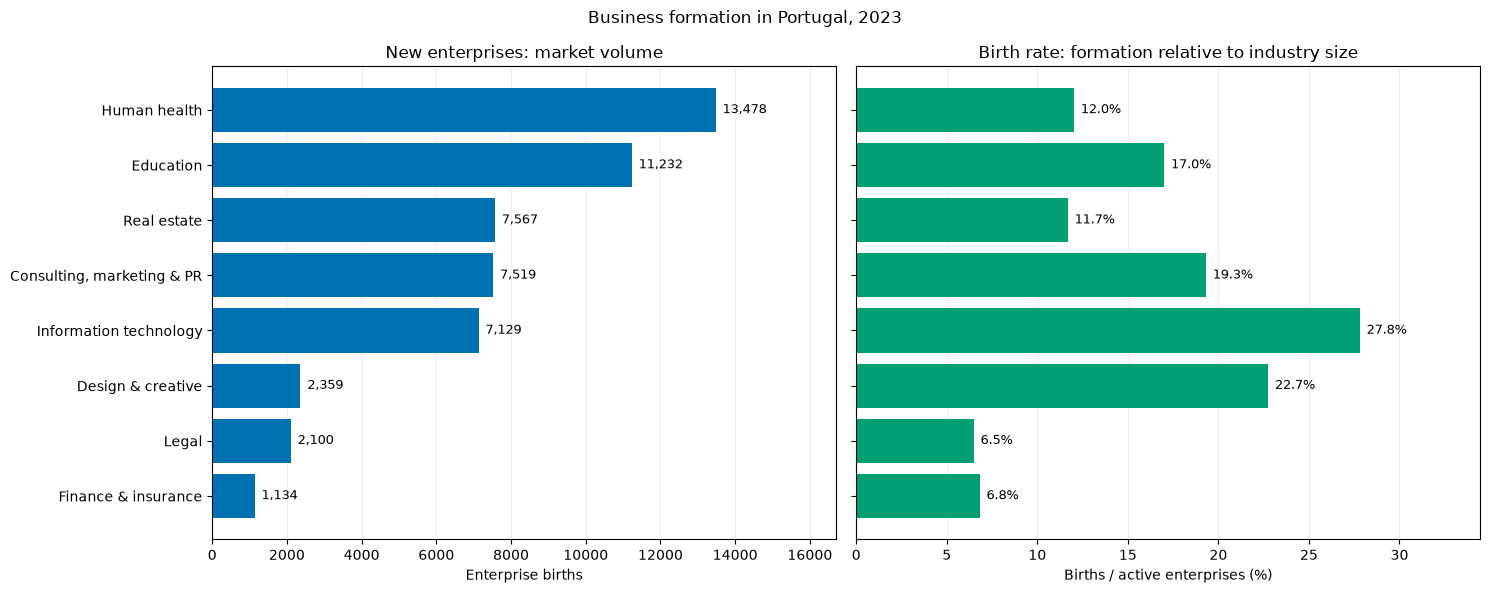

In [431]:
# Use the same industry order across the external and internal comparisons.
formation_comparison = (
    df_industry_comparison
    .sort_values("enterprise_births", ascending=False)
    .reset_index(drop=True)
)

display(
    formation_comparison[
        [
            "comparison_group",
            "enterprise_births",
            "birth_rate_pct",
            "member_count",
            "members_with_valid_plan",
            "hot_desk_or_flex_pct",
        ]
    ]
)

# Display counts and rates separately because they measure different things.
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True)

positions = np.arange(len(formation_comparison))
group_labels = formation_comparison["comparison_group"].tolist()

birth_counts = formation_comparison["enterprise_births"].to_numpy()
birth_rates = formation_comparison["birth_rate_pct"].to_numpy()

axes[0].barh(positions, birth_counts, color="#0072B2")
axes[1].barh(positions, birth_rates, color="#009E73")

axes[0].set_yticks(positions)
axes[0].set_yticklabels(group_labels)
axes[0].invert_yaxis()

axes[0].set_title("New enterprises: market volume")
axes[0].set_xlabel("Enterprise births")

axes[1].set_title("Birth rate: formation relative to industry size")
axes[1].set_xlabel("Births / active enterprises (%)")

for position, value in zip(positions, birth_counts):
    axes[0].annotate(
        f"{value:,.0f}",
        (value, position),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
    )

for position, value in zip(positions, birth_rates):
    axes[1].annotate(
        f"{value:.1f}%",
        (value, position),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
    )

for ax in axes:
    ax.set_xlim(0, ax.get_xlim()[1] * 1.18)
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(f"Business formation in Portugal, {REFERENCE_YEAR}")
plt.tight_layout()
plt.show()

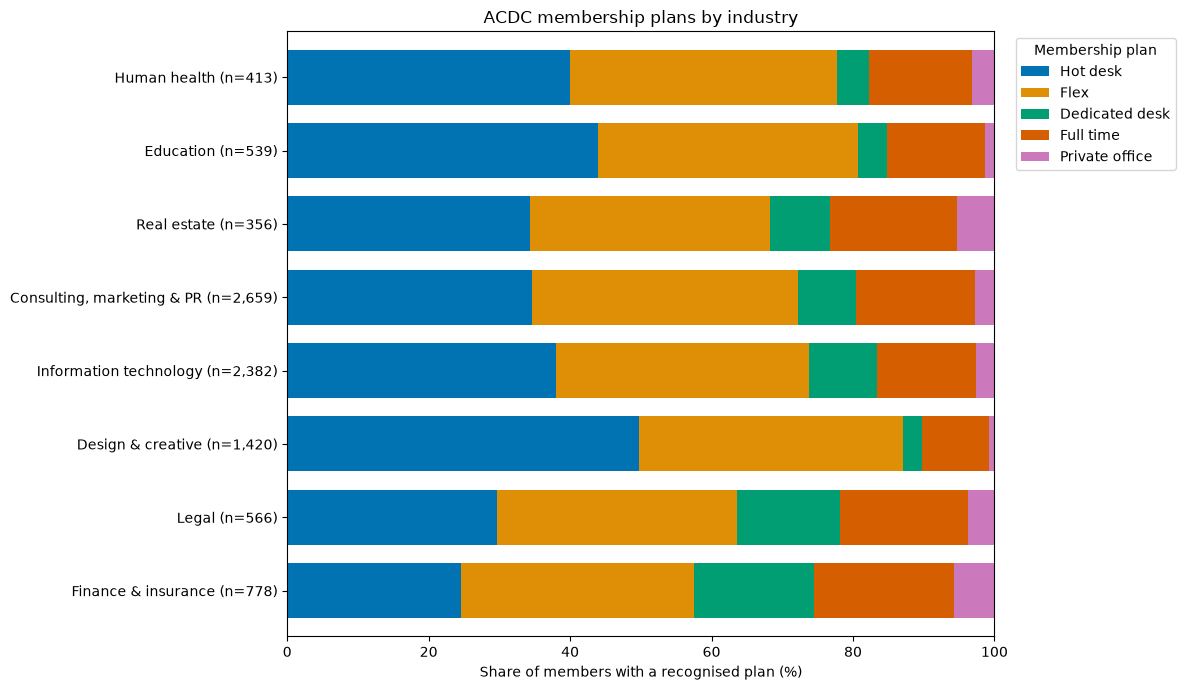

In [432]:
plan_share_columns = [
    "hot_desk_pct",
    "flex_pct",
    "dedicated_desk_pct",
    "full_time_pct",
    "private_office_pct",
]

plan_labels = [
    "Hot desk",
    "Flex",
    "Dedicated desk",
    "Full time",
    "Private office",
]

# Retain the ordering used in the business-formation charts.
plan_plot = formation_comparison.set_index("comparison_group")

# Groups without valid plans cannot have an interpretable plan distribution.
plan_plot = plan_plot.loc[
    plan_plot["members_with_valid_plan"].fillna(0).gt(0)
]

plan_percentages = plan_plot[plan_share_columns].copy()
plan_percentages.columns = plan_labels

fig, ax = plt.subplots(figsize=(12, 7))

plan_percentages.plot(
    kind="barh",
    stacked=True,
    color=sns.color_palette("colorblind", n_colors=5),
    width=0.75,
    ax=ax,
)

ax.set_yticklabels([
    f"{group} (n={int(count):,})"
    for group, count in zip(
        plan_plot.index,
        plan_plot["members_with_valid_plan"],
    )
])

ax.invert_yaxis()
ax.set_xlim(0, 100)
ax.set_xlabel("Share of members with a recognised plan (%)")
ax.set_ylabel("")
ax.set_title("ACDC membership plans by industry")
ax.legend(
    title="Membership plan",
    bbox_to_anchor=(1.02, 1),
    loc="upper left",
)

plt.tight_layout()
plt.show()

### 2.6.3. External Benchmarking Against the Flexible-Office Market

To assess whether ACDC's industry patterns are consistent with independent
market evidence, we compare selected industries with Workthere's
Flexmark 4.0 report, published in November 2023.

The report attributes 30% of global flexible-office demand to technology,
27% to financial services and 2% to healthcare.

We compare these categories approximately with ACDC's Information Technology,
Finance and Health labels. ACDC percentages are recalculated using the full
cleaned Portuguese member sample, including industries excluded from the
earlier NACE comparison. Missing industry labels remain in the denominator
and their number is reported.

The comparison checks whether the same industries are prominent across the
two sources and identifies differences that qualify our interpretation of
market opportunities.

**Source credibility and limitations:** Workthere is a commercial
flexible-office advisory business. Its report provides direct industry-survey
evidence, but it is not an official statistical census. Its global,
provider-reported demand figures differ from ACDC's Portuguese membership
records. The categories and weighting are not established as equivalent.

ACDC's records span 2021–2023, while the benchmark refers to 2023.
Consequently, percentage-point gaps are descriptive comparisons, not estimates
of market penetration or statistically established differences.

Source: [Workthere Flexmark 4.0 (2023), PDF page 5 — Member Profile](https://www.workthere.com/media/yxqpqiro/workthere-flexmark-2023-final.pdf)

In [433]:
# Rebuild the full Portuguese sample without restricting it to mapped industries.
# Apply the same duplicate and identifier rules used in the earlier comparison.
df_acdc_benchmark = df_acdc_pt.drop_duplicates().copy()

member_ids = (
    df_acdc_benchmark["member_id"]
    .astype("string")
    .str.strip()
)

valid_id = member_ids.notna() & member_ids.ne("").fillna(False)

df_acdc_benchmark = df_acdc_benchmark.loc[valid_id].copy()
df_acdc_benchmark["member_id"] = member_ids.loc[valid_id]

conflicting_ids = df_acdc_benchmark.duplicated(
    subset="member_id",
    keep=False,
)

df_acdc_benchmark = (
    df_acdc_benchmark.loc[~conflicting_ids].copy()
)

# Normalise labels while preserving missing or unspecified industries.
industry = (
    df_acdc_benchmark["industry"]
    .astype("string")
    .str.strip()
    .str.lower()
    .replace({
        "": pd.NA,
        "unknown": pd.NA,
        "nan": pd.NA,
        "<na>": pd.NA,
    })
)

total_members = len(df_acdc_benchmark)
assert total_members > 0, "No Portuguese members available for benchmarking."

benchmark_labels = {
    "Information technology": "information technology",
    "Finance": "finance",
    "Health": "health",
}

# Published global demand shares from Workthere Flexmark 2023, PDF page 5.
workthere_shares = {
    "Information technology": 30.0,
    "Finance": 27.0,
    "Health": 2.0,
}

benchmark_rows = []

for group, acdc_label in benchmark_labels.items():
    member_count = int(industry.eq(acdc_label).fillna(False).sum())
    acdc_share = member_count / total_members * 100

    benchmark_rows.append({
        "ACDC industry": group,
        "ACDC members": member_count,
        "ACDC membership share (%)": acdc_share,
        "Workthere global demand share (%)": workthere_shares[group],
        "Descriptive gap (pp)": acdc_share - workthere_shares[group],
    })

df_external_benchmark = pd.DataFrame(benchmark_rows)

print(f"Full cleaned Portuguese sample: {total_members:,} members")
print(f"Members with missing industry labels: {industry.isna().sum():,}")
print("The three displayed industries are a subset and do not sum to 100%.")

display(df_external_benchmark.round(2))

Full cleaned Portuguese sample: 10,499 members
Members with missing industry labels: 492
The three displayed industries are a subset and do not sum to 100%.


,ACDC industry,ACDC members,ACDC membership share (%),Workthere global demand share (%),Descriptive gap (pp)
0,Information technology,2394,22.80,30.00,-7.20
1,Finance,781,7.44,27.00,-19.56
2,Health,415,3.95,2.00,1.95


Technology is prominent in both ACDC's member profile and Workthere's
reported demand, providing directional support for the EDA's identification
of IT as an important customer industry.

Financial services are much more prominent in Workthere's reported global
demand than in ACDC's membership. This difference shows that ACDC's profile
should not be treated as representative of the wider flexible-office market.

Healthcare accounts for only 2% of Workthere's reported demand despite having
the largest enterprise-birth count in our Eurostat comparison. This challenges
the assumption that substantial business formation alone identifies a strong
coworking opportunity.

The comparison provides partial corroboration and identifies differences.
It does not validate the proposed targeting strategy or demonstrate unmet
demand, because geography, industry definitions and measurement differ.

## 2.7. Main Findings and Limitations

Information technology combines the highest birth rate among the mapped
groups (27.8%) with 7,129 new enterprises in 2023. Consulting, marketing & PR
also shows substantial formation, with 7,519 births and a 19.3% birth rate.
In both groups, hot-desk and flex plans account for approximately 72–74%
of recognised ACDC memberships. These findings justify investigating
flexible starter packages.

Design & creative shows a high birth rate (22.7%) and a particularly high
hot-desk/flex share among existing members (approximately 87%). However,
its external market volume is smaller (2,339 births), and specialised design
only partially matches ACDC's broader creative-industry label.

External benchmarking provides a mixed assessment. Workthere's 2023 report
also identifies technology as prominent in flexible-office demand, but
financial services have a much larger role than in ACDC. Its small healthcare
share further shows why large enterprise-birth counts should not automatically
be interpreted as strong coworking opportunities.

Eurostat provides credible market context, while Workthere offers a
commercial industry benchmark. Neither source measures the likelihood that
a newly created business will subscribe to ACDC.

The conclusions remain exploratory. Eurostat counts enterprises, ACDC records
members and Workthere reports global flexible-office demand. Industry mappings
are approximate, and ACDC's 2021–2023 profiles are compared with 2023 external
observations. Company age, local market coverage and acquisition outcomes
are unavailable, so proposed packages require further testing.